# Phase Equilibria of CO$_2$, CH$_4$, N$_2$, H$_2$, C$_2$H$_6$, C$_3$H$_8$, and Mixtures in Multisalt Brines: Robust Stability and Flash Computations with an Ion-Specific Electrolyte Cubic-Plus-Association Equation of State

**Executable paper notebook**: the full text of the journal article and its Supporting
Information, with code cells that regenerate every figure and table.

J. Moortgat, F. M. Coelho, A. Firoozabadi. *Energy & Fuels* **2026**, available online.
[doi:10.1021/acs.energyfuels.6c04569](https://doi.org/10.1021/acs.energyfuels.6c04569)
([article page](https://pubs.acs.org/enfuem/article/doi/10.1021/acs.energyfuels.6c04569/5462396/Phase-Equilibria-of-CO2-CH4-N2-H2-C2H6-C3H8-and))

The article is published open access under the
[Creative Commons Attribution 4.0 license](https://creativecommons.org/licenses/by/4.0/).
The text below is reproduced under that license. The equation-of-state code is in
[`multisalt/`](../multisalt/README.md) of this repository; the experimental data are
GasBrineBench v1.1.1 ([doi:10.5281/zenodo.22898153](https://doi.org/10.5281/zenodo.22898153)).
The parametrization of the model is the subject of the companion article (Paper II of this
repository), whose executable version is
[`ms_ecpa_parametrization_paper.ipynb`](ms_ecpa_parametrization_paper.ipynb).

**How to use.** Run the setup cell first. Each figure and table has a hidden code cell
above its caption. By default the cells draw the figures and tables from the model
results shipped with the repository (a few minutes). Set `nbtools.RUN_LONG = True` in
the setup cell to recompute the model results of the figure scripts and the pilot
studies from the equation of state. The flash over the 151,632-state grid (Section 3.6)
is the exception: it runs on an HPC cluster with the SLURM scripts in
`multisalt/sweep/slurm/` (about 90 core-hours of single-thread computation, recorded
in the shipped results), and the notebook plots those results.


## Contents

- [Article](#mtop)
  - [Abstract](#mabstract)
  - [1 Introduction](#msec1)
  - [2 Methods](#msec2)
    - [2.1 The ms-eCPA model](#msec2_1)
    - [2.2 Phase stability via tangent-plane distance](#msec2_2)
    - [2.3 $K$-value flash with Newton polish](#msec2_3)
    - [2.4 Extension to three phases: vapor, brine, and liquid $\mathrm{CO_{2}}$](#msec2_4)
  - [3 Results and Validation](#msec3)
    - [3.1 Phase stability and flash predictions](#msec3_1)
    - [3.2 Nitrogen, hydrogen, ethane, and propane in brine](#msec3_2)
    - [3.3 $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ and $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–brine](#msec3_3)
    - [3.4 Three-phase equilibria: salt-free loci and brine predictions](#msec3_4)
    - [3.5 Efficiency and robustness of the multi-salt flash pipeline](#msec3_5)
  - [4 Conclusions](#msec4)
- [Supporting Information](#stop)
  - [S1 Nomenclature](#ssecS1)
  - [S2 Complete ms-eCPA parameter set](#ssecS2)
    - [S2.1 Provenance and role of every parameter](#ssecS2_1)
    - [S2.2 Parameter tables](#ssecS2_2)
  - [S3 Tangent-plane stability test: algorithm](#ssecS3)
  - [S4 $K$-value flash with Newton polish: algorithm](#ssecS4)
    - [S4.1 Partitioning basis and the all-species Rachford–Rice](#ssecS4_1)
  - [S5 Bound on ion partitioning into non-aqueous phases](#ssecS5)
  - [S6 Three-phase stability test and flash: algorithm](#ssecS6)
    - [S6.1 Range of validity](#ssecS6_1)
  - [S7 Tangent-plane landscape](#ssecS7)
  - [S8 Per-salt parity and literature scatter](#ssecS8)
  - [S9 Predictions across the $T$–$P$–composition window](#ssecS9)
    - [S9.1 Phase boundary and partition predictions](#ssecS9_1)
    - [S9.2 Gas-phase water content](#ssecS9_2)
    - [S9.3 Aqueous solubility and density](#ssecS9_3)
    - [S9.4 Equilibrium-state observables](#ssecS9_4)
    - [S9.5 Salting-out by ionic strength](#ssecS9_5)
  - [S10 Setschenow calibrations for ethane and propane](#ssecS10)
  - [S11 Ethane and propane in brine](#ssecS11)
  - [S12 Ternary $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$: statistics and $k_{hc}$](#ssecS12)
  - [S13 $\mathrm{CH_{4}}$/$\mathrm{CO_{2}}$ selectivity in single-salt brines](#ssecS13)
  - [S14 Efficiency and robustness analyses](#ssecS14)
    - [S14.1 Performance summary](#ssecS14_1)
    - [S14.2 Sensitivity of the classification to the TPD thresholds](#ssecS14_2)
    - [S14.3 Low-pressure water content and a second gas](#ssecS14_3)
    - [S14.4 Per-call cost, three-phase probe, complex step](#ssecS14_4)

In [1]:
# Setup: run this cell first (locally or on Google Colab).
import os, sys, subprocess

if "google.colab" in sys.modules and not os.path.exists("CPA_and_eCPA_flash"):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/jmoortgat/CPA_and_eCPA_flash.git"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "CoolProp"], check=True)

# work from the multisalt/ directory of the repository
for cand in ("CPA_and_eCPA_flash/multisalt", "../multisalt", "multisalt", "."):
    if os.path.exists(os.path.join(cand, "ms_ecpa", "parameters.py")):
        os.chdir(cand)
        break
sys.path[:0] = [os.getcwd(), os.path.join(os.getcwd(), "scripts")]

import nbtools
from nbtools import run, show, latex_table, show_table

# False: draw the figures and tables from the model results shipped in
# results_cache/.  True: recompute them from the equation of state (about
# 15 min with the Fortran library for the figure scripts; the flash grid of
# Section 3.6 is not recomputed here (see multisalt/sweep/README.md)).
nbtools.RUN_LONG = False

# use the compiled Fortran library when it has been built (make -C fortran)
built = os.listdir("fortran/build") if os.path.isdir("fortran/build") else []
if any(f.startswith("libecpa") for f in built):
    os.environ.setdefault("MS_ECPA_BACKEND", "fortran")
print("working directory:", os.path.basename(os.getcwd()) + "/",
      "| backend:", os.environ.get("MS_ECPA_BACKEND", "python"),
      "| RUN_LONG:", nbtools.RUN_LONG)


working directory: multisalt/ | backend: fortran | RUN_LONG: False


<a id="mtop"></a>

# Article

Joachim Moortgat (School of Earth Sciences, The Ohio State University, Columbus, OH, USA), Felipe Mourão Coelho (Université Grenoble Alpes, Grenoble, France), Abbas Firoozabadi (Rice University, Houston, TX, USA)

<a id="mabstract"></a>

## Abstract

In a recent study we presented an ion-specific parameterization of the electrolyte Cubic-Plus-Association (eCPA) equation of state, which we refer to as ms-eCPA, for phase equilibria of $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ in six-ion multi-salt brines ($\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$, $\mathrm{K^{+}}$, $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$, $\mathrm{SO_{4}^{2-}}$). Here we develop the computational methods that make ms-eCPA usable in compositional reservoir simulation, and we extend it to additional gases ($\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, and $\mathrm{C_{3}H_{8}}$). In contrast to the common multi-salt pairing of an aqueous activity-coefficient model with a separate gas-phase fugacity model, both phases here derive from a single residual Helmholtz energy. This energy delivers fugacities, phase densities, and stability analysis on one thermodynamic surface. A tangent-plane-distance stability test classifies every feed, and an accelerated $K$-value flash computes the phase split. The nonvolatile ions enter the Rachford–Rice equation in closed form, and each phase keeps its own inner Newton solve (three unknowns in the aqueous phase, two in the gas phase) with complex-step Jacobians. Convergence and efficiency are demonstrated across $151\,632$ states spanning the calibration window ($283$–$623$ K, $1$–$1000$ bar, eight salt configurations). We reproduce the validation data of that study at a global $\mathrm{CO_{2}}$-solubility AARE of 6.55%. We also predict the $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ ternary mutual solubilities and $\mathrm{CH_{4}}$/$\mathrm{CO_{2}}$ selectivity in brine with no parameter fitted to ternary data. Below the critical temperature of a condensable gas we extend the framework to three coexisting phases (vapor, brine, and a gas-rich liquid). The two systems for which external data exist are salt-free binaries, and we reproduce both. The $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ locus tracks the reference $\mathrm{CO_{2}}$ saturation curve within 0.2–1.1 bar. The *measured* propane–water three-phase pressure is matched to within 1.5 % from 289 to 366 K. Along the locus, propane in the water-rich phase is reproduced to 2.2 % and water in the vapor to 4.3 % on average, while water in the liquid propane is overpredicted by 21–63 %. No experimental three-phase data exist for gas–brine systems, so the three-phase results in brine are reported as predictions. New gases require few new parameters: $\mathrm{N_{2}}$ from a salt-free binary fit alone, $\mathrm{H_{2}}$ adopted from a published parameterization, and $\mathrm{C_{2}H_{6}}$ and $\mathrm{C_{3}H_{8}}$ — for which the $\mathrm{CH_{4}}$ transfer breaks down — with one binary fit plus two ion-energy scales each, calibrated against evaluated Setschenow data. Their brine validation is confined to $\mathrm{NaCl}$ ($\mathrm{N_{2}}$, $\mathrm{H_{2}}$) and to atmospheric-pressure Setschenow constants in $\mathrm{NaCl}$ and $\mathrm{KCl}$ ($\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$), so their multi-salt behavior is a prediction. With the parameterization and the present framework, we provide a unified thermodynamic engine for subsurface $\mathrm{CO_{2}}$ sequestration, $\mathrm{CH_{4}}$ production, and $\mathrm{N_{2}}$/$\mathrm{H_{2}}$ storage in brines of mixed ionic composition.


<a id="msec1"></a>

## 1 Introduction

Compositional simulation of subsurface gas–brine systems — geological $\mathrm{CO_{2}}$ storage in saline aquifers, natural-gas production in contact with formation water, and the emerging storage of $\mathrm{H_{2}}$ in depleted reservoirs and salt caverns — requires phase-equilibrium computations at every grid cell and every time step<sup>[1](#mref1)–[4](#mref4)</sup>. Two demands follow. The computations must be *robust*: a single failed flash among millions of calls can halt a simulation or, worse, silently corrupt its mass balance. And they must be *fast*, because the stability test and the flash dominate the per-cell computing time of a compositional simulator.

For cubic equations of state these demands are met by a mature algorithmic canon: tangent-plane-distance (TPD) stability analysis<sup>[5](#mref5)</sup>, successive substitution with acceleration, and Newton refinement<sup>[6](#mref6)</sup>. Electrolyte equations of state are harder on both counts. In the electrolyte Cubic-Plus-Association (eCPA) equation of state<sup>[7](#mref7),[8](#mref8)</sup>, every fugacity-coefficient evaluation requires simultaneously solving for the density root of the cubic equation of state, the Wertheim association fraction, and the self-consistent Onsager–Kirkwood static permittivity<sup>[9](#mref9)</sup>. These three quantities form a coupled nonlinear inner problem that must be solved inside every iteration of the outer stability or flash loop. Published eCPA work has largely focused on the equilibrium conditions themselves. A stability-and-flash framework of the standard routinely demanded in hydrocarbon reservoir simulation has so far been available only for the single-salt $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$–$\mathrm{NaCl}$ system, in our prior algorithmic study<sup>[10](#mref10)</sup>.

The most widely used multi-salt models are activity-coefficient constructions: a Pitzer or comparable ion-interaction model for the aqueous phase, a separate fugacity model for the gas phase, joined through Henry’s-law reference states<sup>[11](#mref11)–[14](#mref14)</sup>. The model of Duan et al.<sup>[12](#mref12)</sup> covers the same six-ion suite considered here. Cubic-EoS treatments such as Søreide and Whitson<sup>[15](#mref15)</sup> instead fold salinity into a brine-modified water attraction term and salinity-dependent interaction coefficients. Both are calibrated for solubility and can be accurate for it. But they solve a different equation set than compositional simulation requires. With the two phases not described by a single Helmholtz energy, there is no common surface on which a tangent-plane analysis can operate. Salt enters through total ionic strength or an $\mathrm{NaCl}$-equivalent salinity rather than ion-specifically, and the aqueous density — needed for gravity, compressibility and pressure — lies outside the equilibrium model. Electrolyte equations of state close this gap<sup>[8](#mref8),[16](#mref16)–[18](#mref18)</sup>: one residual Helmholtz energy delivers the fugacities, the stability test and the phase densities on a single surface, which is the setting of the present work.

In a recent companion study<sup>[19](#mref19)</sup> — hereafter the parameterization study — we parameterized the eCPA equation of state for $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ in multi-salt brines spanning the six subsurface-relevant ions $\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$, $\mathrm{K^{+}}$, $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$, and $\mathrm{SO_{4}^{2-}}$. We validated it against more than 1,500 experimental gas–brine VLE points, high-accuracy brine densities, and the Pitzer osmotic-coefficient standard. In that study we also established the parameter hierarchy of ms-eCPA. Each level of physical description — nonpolar fluids, the associating solvent, ions in the solvent, gases over brine — introduces only parameters fitted to that level’s own data, with all lower levels held fixed. Here we complete the framework along the two axes left open. First, we develop the multi-salt stability test and $K$-value flash that turn the parameterization into a practical thermodynamic engine, and quantify their robustness and cost over a dense grid of $\sim 150\,000$ states. Second, we exploit the top level of the hierarchy. A new gas enters only through its pure-component constants, one gas–water binary parameter and its gas–ion energies. We therefore extend the framework to $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$ and $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ mixtures with at most one salt-free binary fit and, where the transfer of gas–ion energies fails, a few ion-energy scales per gas.

The specific contributions of this work are:

1.  A two-phase tangent-plane stability test for ms-eCPA, with an eight-trial initial-guess scan and a hard/soft threshold hierarchy following the design of Jex et al.<sup>[6](#mref6)</sup>.

2.  An accelerated $K$-value flash with Newton polish on $\ln K_i$. Each phase uses its own inner Newton solve for the compressibility factor and the water association fraction, and in the aqueous phase also for the static permittivity. The inner Jacobian is evaluated by complex-step differentiation, which is free of the subtractive cancellation that limits a finite difference and reproduces the derivative to within rounding at the step size used (Section S14.4 of the Supporting Information). Ions are confined to the aqueous phase as a hard mass-balance constraint.

3.  Validation of the framework against the experimental $\mathrm{CO_{2}}$–brine data of the parameterization study (global AARE of 6.55%) and prediction of the $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ ternary mutual solubilities and $\mathrm{CH_{4}}$/$\mathrm{CO_{2}}$ selectivity in brine with no parameter fitted to ternary data.

4.  Extension to $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$ and $\mathrm{C_{3}H_{8}}$. For $\mathrm{N_{2}}$ the gas–ion energies are transferred from the $\mathrm{CH_{4}}$ values of Part I, so that no parameter is fitted to nitrogen-in-brine data. For $\mathrm{H_{2}}$ we adopt the published parameterization of Coelho et al.<sup>[4](#mref4)</sup> with no additional parameter fitting in the present study. For $\mathrm{C_{2}H_{6}}$ and $\mathrm{C_{3}H_{8}}$ the binaries are fitted, and the ion energies are calibrated against evaluated Setschenow data after the $\mathrm{CH_{4}}$ transfer is shown to break down for both. Each gas is validated against the available experimental data. Across a three-gas trend, these comparisons delineate the validity boundary of gas–ion transfer from $\mathrm{CH_{4}}$ without brine fitting. The brine validation of these four gases is confined to $\mathrm{NaCl}$ ($\mathrm{N_{2}}$, $\mathrm{H_{2}}$) and to atmospheric-pressure Setschenow constants in $\mathrm{NaCl}$ and $\mathrm{KCl}$ ($\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$); their behavior in the divalent-ion brines is a prediction.

5.  Extension of the stability test and flash to three coexisting phases — vapor, brine, and a $\mathrm{CO_{2}}$-rich liquid — below the $\mathrm{CO_{2}}$ critical temperature. The extension adds no new iteration unknowns beyond a second phase fraction, because both non-aqueous phases share one equation of state and differ only in the density root of the same inner solve. The predicted three-phase locus of the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ system tracks the reference $\mathrm{CO_{2}}$ saturation curve within 0.2–1.1 bar over 283–302 K. The measured propane–water three-phase pressure is matched to within 1.5 % from 289 to 366 K. Along the locus, propane in the water-rich phase is reproduced to 2.2 % and water in the vapor to 4.3 % on average, while water in the liquid propane is overpredicted by 21–63 %. Both comparisons are salt-free binaries, so the three-phase results computed in brine are predictions.

6.  A robustness and efficiency analysis over a dense suite of $\sim 150\,000$ conditions covering the full calibration window ($T \in [283, 623]$ K, $P \in [1, 1000]$ bar, eight salt configurations, multiple feed compositions per family). Every state converges, and the resulting corpus separates the per-call cost of the stability test (dominant, skippable under warm-start) from the accelerated $K$-value flash (fast).

In Section 2 we summarize the ms-eCPA model, describe the tangent-plane stability test and the $K$-value flash with Newton polish, and extend both to three coexisting phases. In Section 3 we validate the framework against experiment, extend it to $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$, and $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ mixtures, validate the three-phase equilibria against the $\mathrm{CO_{2}}$ and propane saturation loci, and analyze the convergence and per-call efficiency on the dense grid. In Section 4 we summarize the results and outline the path to reservoir-simulator coupling.


<a id="msec2"></a>

## 2 Methods

We first summarize the ms-eCPA model to the extent the algorithms rely on it (Section 2.1). We then describe the tangent-plane-distance phase-stability test and the $K$-value flash with Newton polish that solve the equilibrium problem at every state point (Sections 2.2–2.3). Figure 1 summarizes the complete path from a specified feed to the final phase split.


<a id="msec2_1"></a>

### 2.1 The ms-eCPA model

The ms-eCPA EoS, its parameters, and their calibration are presented in Moortgat et al.<sup>[19](#mref19)</sup>; here we summarize only what the algorithms below rely on. The residual Helmholtz energy per mole is the sum of an SRK physical contribution with Huron–Vidal mixing, a Wertheim association contribution, and Debye–Hückel and Born electrostatic contributions on an ionic basis<sup>[7](#mref7),[19](#mref19),[20](#mref20)</sup>:

$$A^\text{R} = A^\text{phys} + A^\text{assoc} + A^\text{DH} + A^\text{Born}. \tag{1}$$

The association contribution uses the 4C scheme for water, with $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ cross-association. $\mathrm{CH_{4}}$ and the ions have no association sites. The static relative permittivity $\varepsilon_r$ of the mixture is closed self-consistently through the Onsager–Kirkwood relation<sup>[9](#mref9)</sup>. The compressibility factor and the fugacity coefficient of species $i$ follow from the standard identities, written here for the extensive residual Helmholtz energy $nA^\text{R}$, with $n = \sum_i n_i$ the total number of moles, $V$ the total volume and $v = V/n$ the molar volume:

$$Z = 1 - \frac{v}{RT}\!\left(\frac{\partial (nA^\text{R})}{\partial V}\right)_{T,n_i},
  \qquad
  \ln \hat{\phi}_i
  = \frac{1}{RT}\!\left(\frac{\partial (nA^\text{R})}{\partial n_i}\right)_{T,V,n_{j\neq i}}
    - \ln Z. \tag{2}$$

Because Eq. (1) is per mole, the derivatives are taken of the extensive $nA^\text{R}$, so that both identities are dimensionless. The equivalent molar form of the first is $Z = 1 - (v/RT)\,(\partial A^\text{R}/\partial v)_{T,\mathbf{x}}$. Here and throughout, the species index $i$ runs over all $N_c$ components of the mixture — water, the volatile gases, and the ions. For the $\mathrm{H_{2}O}$–$\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ system with the six-ion suite of the parameterization study, $N_c = 9$. Equations that apply only to a subset of the species — the partitioning (volatile) species, or the ions — state that subset explicitly. Because the Wertheim association and the permittivity closure are implicit, every evaluation of Eq. (2) requires the simultaneous solution of the coupled triple $(Z, \varepsilon_r, \chi_{\mathrm{H_{2}O}})$ from the cubic equation of state, the Onsager–Kirkwood condition, and the bonding-fraction closure. We solve this system with a per-phase inner Newton iteration (Section 2.3).

Two parameter families of the parameterization study are used directly here. The binary interaction parameters between water and the volatile species take the quadratic form

$$k_{ij} = A^k_{ij}\left(\frac{T}{T^k_{ij}}\right)^2
         + B^k_{ij}\left(\frac{T}{T^k_{ij}}\right)
         + C^k_{ij}, \tag{3}$$

and, for the gases calibrated in the parameterization study, the gas–ion interaction energies of the Huron–Vidal mixing rule are linear in the gas-reduced temperature,

$$\Delta U_{gi} = A^{\Delta U}_{gi}\!\left(\frac{T}{T_{c,\text{gas}}}\right)
                + B^{\Delta U}_{gi}, \tag{4}$$

where the subscript $g$ denotes a volatile gas and $i$ one of the six ions. All parameter values — pure-component constants, association parameters, ion diameters and Born radii, water–ion and gas–ion energies, and the ion-specific Péneloux volume translations — are tabulated in Moortgat et al.<sup>[19](#mref19)</sup> and its Supporting Information. They are reproduced in Section S2 of the present Supporting Information and used here unchanged.

The full asymmetric Huron–Vidal treatment, with temperature-dependent interaction energies, is required only for pairs involving the polar water molecule or an ion. For pairs of nonpolar volatile species, the Huron–Vidal energy expression of the parameterization study reduces to conventional van der Waals mixing of the attraction parameter $a$. For $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ this is a single constant coefficient, $k_{hc} = 0.080$, and this conventional rule proves adequate throughout the present work. $\mathrm{CH_{4}}$ and $\mathrm{N_{2}}$ have no dipole moment, do not cross-associate with water, and interact essentially through dispersion. $\mathrm{N_{2}}$ is the more weakly interacting of the two, given its low electronic polarizability (Table 2). No specific interactions therefore arise that the conventional rule would miss. Ethane, with nearly twice the polarizability of $\mathrm{CH_{4}}$, is the limit of this simplicity for the gas–ion interactions (Section 3.2). The multi-gas results of Sections 3.2 and 3.3 — $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ ternary predictions with no ternary mixing parameters, and the transfer of the $\mathrm{CH_{4}}$ gas–ion energies to $\mathrm{N_{2}}$ without any fit to nitrogen-in-brine data — rest directly on this simplicity. The formalism admits no three-body parameter: the energies $\Delta U_{ij}$, the binary parameters $k_{ij}$, and the cross-association ratio $S_{cw}$ each have two species indices, so a third component adds one pair term and nothing else. A ternary prediction is therefore a test of whether pairwise information suffices.


<a id="msec2_2"></a>

### 2.2 Phase stability via tangent-plane distance

For applications in compositional reservoir simulation<sup>[1](#mref1),[2](#mref2)</sup> ms-eCPA must be embedded in robust phase-state classification. We use the tangent-plane distance (TPD) criterion in the form recommended by Michelsen<sup>[5](#mref5)</sup>, Jex et al.<sup>[6](#mref6)</sup> and adapted to ms-eCPA. Given a single-phase feed $\mathbf{z}$ at $(T,P)$, a trial phase is described by a vector of *mole numbers* $\mathbf{W}$, unnormalized, with $S = \sum_i W_i$ and mole fractions $\mathbf{w} = \mathbf{W}/S$ on which the fugacity coefficients depend. In these variables the tangent-plane criterion takes Michelsen’s modified form

$$tm(\mathbf{W}) = 1 + \sum_i W_i
    \left[\ln W_i + \ln\hat{\phi}_i(\mathbf{w}) - d_i - 1\right],
  \qquad
  d_i = \ln z_i + \ln \hat{\phi}_i^{\text{gas}}(\mathbf{z}), \tag{5}$$

whose stationary points solve $g_i \equiv \ln W_i + \ln\hat\phi_i(\mathbf{w}) - d_i = 0$, whose components form the residual vector $\mathbf{g}$. These are located by accelerated successive substitution, $\ln W_i \leftarrow d_i - \ln\hat\phi_i(\mathbf{w})$, using the acceleration of Jex et al.<sup>[6](#mref6)</sup>. A stationary point is accepted when $\lVert\mathbf{g}\rVert_\infty < 10^{-8}$. The reference vector uses the gas-phase kernel at the feed composition, with an aqueous-side fallback at the few conditions where the gas-phase root does not exist. At a stationary point the sum collapses to $$tm^{\star} = 1 - \sum_i W_i,$$ which is the quantity reported below as the minimum TPD and the one the thresholds act on. The normalized distance of the same stationary point is $\mathrm{TPD}(\mathbf{w}) = -\ln S$; since $\ln S \le S-1$ the two always share a sign and give an identical verdict, but they are different numbers, so a threshold must be quoted on a stated basis.

Ions are not trial variables. They are nonvolatile and never candidates for an incipient phase. An aqueous trial therefore uses the brine as a fixed set of molalities $m_j$ and the ion mole fractions follow from the trial’s own water content by one common factor, $x_j = M_{\mathrm{H_{2}O}} m_j x_{\mathrm{H_{2}O}}$. The net charge is then $\sum_j x_j Z_j = 0$ for a neutral recipe: electroneutrality is preserved identically at every iteration, by the same closure that places the ions in the flash of Sec. 2.3. The test therefore searches for splits at the brine’s own salinity and ion ratios; salt precipitation and aqueous–aqueous splits at a different salinity are outside its scope. An aqueous trial is evaluated on the same composition basis as the flash: its partition-basis composition is converted to true mole fractions through the ion closure of Eq. (9), and the corresponding $\ln s$ enters its stationarity condition exactly as it enters the $K$-update of Section 2.3. Because the reference vector is built on the ion-free gas side, omitting that term would measure the trial on a different basis from its reference and bias the test toward declaring a salted feed stable.

In the multi-salt setting we run eight trial initial guesses in parallel. They are two $\mathrm{CO_{2}}$-rich seeds ($x_{\mathrm{H_{2}O}} = 0.01, 0.10$), two $\mathrm{CH_{4}}$-rich seeds ($x_{\mathrm{H_{2}O}} = 0.01, 0.10$), a water-rich aqueous seed ($x_{\mathrm{H_{2}O}} = 0.99$), a moderate aqueous seed ($x_{\text{gas}} \approx 5$–$10\%$), and two Wilson-$K$-based seeds ($w_i \propto z_i/K_i$ and $w_i \propto K_i z_i$). The most negative converged TPD across the trials is compared with a hard/soft threshold pair ($-0.005$ / $-0.1$): a min-TPD above the hard threshold classifies the feed as single-phase, and any value below it passes the feed to the flash of Section 2.3. The soft threshold governs the near-critical fallback: if both flash initializations fail while the min-TPD lies in the weakly-negative band between the two thresholds, the feed is classified as single-phase rather than reported as a failure. The threshold-hierarchy design follows Jex et al.<sup>[6](#mref6)</sup>; the specific numerical values are empirically tuned to this multi-salt system. The hard threshold is placed closer to zero than Jex’s original $-0.02$ because genuine phase splits occur in this system at minimum-TPD values between $-0.02$ and $-0.005$. Weakly-negative values that are physically stable are filtered downstream instead, by the requirement that the flash return a phase fraction bounded away from zero and one. Section S14.2 of the Supporting Information quantifies how the classification of the full $151{,}632$-state grid responds to both thresholds. The full algorithmic listing, including the SSI residual, the Jex acceleration step, and the convergence tolerances, is provided in Section S3 of the Supporting Information.

Where the coexisting phases approach one another, three further guards keep the trivial stationary point $\mathbf{W} = \mathbf{z}$ from being read as an instability and keep a vanishing split from being reported as two phases. They are stated with their tolerances in Section S3 of the Supporting Information.

The overall architecture — a Michelsen stability test with Jex acceleration — and the general threshold-hierarchy classifier follow our prior algorithmic study<sup>[10](#mref10)</sup>. Two changes are specific to the multi-salt setting. The trial suite grows from six to eight to accommodate the second volatile ($\mathrm{CH_{4}}$ in addition to $\mathrm{CO_{2}}$), and the hard threshold is loosened from $-0.02$ to $-0.005$. The inner Newton solve that evaluates $\hat\phi_i$ at every trial composition is shared with the flash and described in Section 2.3.


<a id="msec2_3"></a>

### 2.3 $K$-value flash with Newton polish

When the stability test in Section 2.2 identifies a feed as two-phase, the equilibrium split is computed with a hierarchical $K$-value flash.

The governing equations are the isothermal two-phase flash conditions, specialized to a species set that is partly nonvolatile. A feed of composition $\mathbf{z}$ at $(T, P)$ splits into a gas-rich phase (mole fractions $y_i$, phase fraction $\beta$) and an aqueous brine phase ($x_i$, fraction $1 - \beta$) subject to the component material balances

$$z_i = \beta\, y_i + (1 - \beta)\, x_i,
  \qquad i = 1, \dots, N_c, \tag{6}$$

where $N_c$ counts the *partitioning* species — water and the volatile gases. The ions are nonvolatile and are kept outside this balance, re-entering through the aqueous normalization described below. $\beta$ is correspondingly the vapor mole fraction on the partitioning-component basis, as in the nomenclature of the Supporting Information. For the partitioning species the isofugacity conditions are

$$x_i\, \hat\phi_i^{\text{aq}}(T, P, \mathbf{x})
  = y_i\, \hat\phi_i^{\text{gas}}(T, P, \mathbf{y}),
  \qquad
  K_i \equiv \frac{y_i}{x_i}
    = \frac{\hat\phi_i^{\text{aq}}}{\hat\phi_i^{\text{gas}}}. \tag{7}$$

Since $y_j = 0$ for every ion, no equilibrium condition is written for them and they do not enter the phase-split equations at all. Combining Eqs. (6) and (7) gives the Rachford–Rice condition for the phase fraction,

$$f(\beta)
  = \sum_{i \,\in\, \text{partitioning}}
      \frac{z_i \left(K_i - 1\right)}{1 + \beta \left(K_i - 1\right)}
  = 0, \tag{8}$$

which is the salt-free Rachford–Rice equation, written over the partitioning species with $\sum_i z_i = 1$ on that basis. Two properties handle the salt bookkeeping. First, $f(\beta)$ is strictly decreasing, so an interior root is unique where it exists, under the same condition as in the salt-free case, $\min_i K_i < 1 < \max_i K_i$. A feed failing it is single-phase at the current $K$: with every $K_i \ge 1$ the aqueous phase vanishes, and with every $K_i \le 1$ the gas phase does. Such a feed is reported as single-phase rather than returned as a split. Second, the ions re-enter only through the aqueous normalization. Writing $\sigma = \sum_{j \in \text{ions}} x_j$ for the total ion mole fraction of the brine, the true aqueous mole fractions follow from the partition-basis ones by a single common factor,

$$x_i = s\, x_i^{\text{part}},
  \qquad
  s = 1 - \sigma, \tag{9}$$

so the ion ratios set by the recipe — including ions contributed by more than one salt — and the electroneutrality of the aqueous phase are preserved without being imposed as separate conditions.

Two closures of the salt balance are implemented, and they are different models rather than conventions for the same physics. In the self-consistent one the specified molality is the prepared feed and the aqueous molality rises as water partitions into the non-aqueous phases; this is the physically correct treatment. The *as-aqueous* closure instead sets the equilibrium aqueous molality equal to the prepared value, so $\sigma$ does not change with $\beta$. This neglects that enrichment. But it is the approximation under which the experimental studies back-calculate their own aqueous compositions, and so the like-for-like basis for the comparisons of Section 3. The closure is selected by a switch and applied consistently to the stability test and the flash alike; every result reported here uses the as-aqueous closure. The difference is small within the validated window but grows without bound as the non-aqueous fraction approaches one at high temperature, and Section 3 of Part I<sup>[19](#mref19)</sup> quantifies it.

The salt content therefore does not appear among the iteration variables: the flash iterates only on the $\ln K_i$ of the partitioning species, through the successive-substitution update

$$\ln K_i^{(k+1)}
  = \ln s
  + \ln \hat\phi_i^{\text{aq}}\!\left(\mathbf{x}^{(k)}\right)
  - \ln \hat\phi_i^{\text{gas}}\!\left(\mathbf{y}^{(k)}\right), \tag{10}$$

in which $\ln s$ converts the fugacity-coefficient ratio, defined on the true mole fractions of Eq. (7), to the partition basis used for $K_i$ and $\beta$. Its fixed point satisfies Eq. (7). Finally, every evaluation of the fugacity coefficients in Eqs. (7) and (10) requires closing the implicit inner problem of ms-eCPA: per phase, the coupled residual system

$$\mathbf{F}\!\left(Z, \varepsilon_r, \chi_{\mathrm{H_{2}O}}\right)
  = \mathbf{0} \tag{11}$$

collects the cubic equation of state at the prescribed $(T, P)$, the Onsager–Kirkwood permittivity condition, and the Wertheim bonding-fraction closure; the closed-form residuals are listed in Section S4 of the Supporting Information.

The algorithm consists of three parts. (i) Accelerated $K$-value SSI in $\ln K_i$ uses the Jex acceleration and is warm-started from the most-negative-TPD stability trial. (ii) Once the SSI residual falls below $10^{-4}$, a Newton polish on $\ln K_i$ drives the equilibrium residual to $10^{-8}$. (iii) Within every iteration of the outer SSI/Newton loop, an inner Newton solve acts on the per-phase triple of Eq. (11). The inner Newton Jacobian is evaluated by complex-step differentiation, which delivers derivatives accurate to within rounding at the step size used. Section S14.4 of the Supporting Information compares it with a finite-difference Jacobian. The outer Rachford–Rice update solves Eq. (8) for $\beta$ at the current $K_i$; the algorithm and its parameterization are two-phase throughout. Ions are partitioned only to the aqueous phase, whose salt molalities are recovered from the feed by mass balance as described above. This confinement is an assumption with two consequences. It places a lower bound on the salt removed from a formation with the water in the gas-rich phase, and it leaves the salt balance of a three-phase state resting entirely on the brine. For the aqueous-phase solubilities, densities and phase boundaries validated in Section 3 the assumption holds. It becomes a limitation when the salt inventory of the non-aqueous phases is itself the quantity of interest. The reason is energetic: at the permittivities that ms-eCPA computes for the two phases, a charged species crossing into the non-aqueous phase incurs a Born energy penalty of order $10^2$–$10^3$ kJ mol$^{-1}$, which places its free-ion content far below any measurable level. Section S5 gives the estimate and its bounds, and identifies the mechanism it does not cover — transport as neutral ion pairs and hydrated clusters, relevant only on approach to the critical region of the aqueous phase.

The overall hierarchical architecture — accelerated SSI, Newton polish, per-phase inner Newton, and the same three inner unknowns — follows our prior algorithmic study<sup>[10](#mref10)</sup>. Where the prior study treated a single salt and a single gas, the Newton residual and the Wertheim association map were rewritten for arbitrary species sets. The formulation of Eqs. (6)–(11) now holds for *any* number of ions and volatile components. An additional species enters only through its own parameters. For an ion, these are the size, Born radius, dispersion energy, polarizability, and interaction energies of the parameterization study. For a volatile component, they are its pure-component constants and binary interaction coefficients, exactly as for a conventional cubic equation of state (Section 2.1). An enlarged species set needs no new hand-derived derivatives, because the complex-step Jacobian is obtained from the residuals of Eq. (11) themselves for any mixture composition. Near the water saturation line both the SSI and the Newton polish can approach the trivial $K = 1$ fixed point, which is a genuine solution of the flash equations and one that an unconstrained step in $\ln K$ is free to reach. In that region the flash is therefore iterated differently, with the same equation of state and the same fugacity equalities applying to every component. The water equality is solved for the phase fraction by a bracketed scalar solve, which cannot reach the trivial attractor. The dissolved-gas equalities are solved by damped successive substitution on the aqueous composition, and the phase fraction is re-solved at each sweep. The tangent-plane trial supplies the starting point, not a fixed input. The aqueous composition is closed on the same ion-inclusive relation the general flash uses, and the material balance is imposed identically. Every state so obtained has a measured residual — the largest relative fugacity imbalance over the components present — and is accepted only below $10^{-6}$. A state that does not close returns no result. Section S4 gives the complete constraint set, the iteration parameters and the residual definition. A complementary fallback covers the opposite corner. Near a miscibility locus, the feed lies between two compositionally similar phases and feed-based $K$ estimates are poor. There the flash is re-seeded with the ratio of the two converged stability-trial compositions, which approximate the coexisting phases directly. The precomputed 3-D $(T, P, m_s)$ warm-start solution table of<sup>[10](#mref10)</sup> is not used here: its natural multi-salt generalization would be an eight-dimensional lookup, which is deferred to future work. The complete algorithmic listing of the $K$-value flash, including the Jex acceleration coefficients, the Newton-polish residual and Jacobian, the sequence of fallback starting values for the inner Newton solve, and the dew-line rescue, is provided in Section S4 of the Supporting Information.


<a id="msec2_4"></a>

### 2.4 Extension to three phases: vapor, brine, and liquid $\mathrm{CO_{2}}$

Below the $\mathrm{CO_{2}}$ critical temperature ($T_c = 304.13$ K) and near the $\mathrm{CO_{2}}$ saturation pressure, the $\mathrm{CO_{2}}$-rich phase condenses, and a vapor, the aqueous brine, and a $\mathrm{CO_{2}}$-rich liquid can coexist. For the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binary the three-phase states form a locus in the $(T, P)$ plane that closely tracks the pure-$\mathrm{CO_{2}}$ vapor-pressure curve<sup>[21](#mref21)</sup>; a second gas opens the locus into a finite three-phase region. These conditions are met in shallow, cold storage formations and in wellbores, where expansion accompanied by the Joule–Thomson effect cools the flowing mixture, so we extend the stability and flash framework to three coexisting phases.

The extension adds no new classes of unknowns and no new derivatives. The aqueous phase remains the reference, and each non-aqueous phase $p \in \{\text{V}, L_{\mathrm{CO_{2}}}\}$ uses its own $K$-vector, $K^p_i = c^p_i / x_i$, with $c^p_i$ the mole fraction of species $i$ in phase $p$. Both non-aqueous phases are described by the same equation of state and the same inner residual system, Eq. (11). They differ only in the density root on which the inner Newton converges. The vapor converges on the gas-like root and the $\mathrm{CO_{2}}$-rich liquid on the liquid-like root, selected through the initial guess for the compressibility factor. The material balance closes through the two-fraction Rachford–Rice condition: with vapor fraction $\beta_g$ and $\mathrm{CO_{2}}$-rich-liquid fraction $\beta_l$,

$$\sum_i \frac{z_i\left(K^g_i - 1\right)}{D_i} = 0,
  \qquad
  \sum_i \frac{z_i\left(K^l_i - 1\right)}{D_i} = 0,
  \qquad
  D_i = 1 + \beta_g\left(K^g_i - 1\right)
          + \beta_l\left(K^l_i - 1\right), \tag{12}$$

with the sums over the partitioning species and $\sum_i z_i = 1$ on that basis, exactly as in Eq. (8), and solved as the stationary point of the convex function $-\sum_i z_i \ln D_i$<sup>[22](#mref22)</sup> by a damped Newton restricted to $D_i > 0$. Convexity alone does not make the interior stationary point unique: that requires the vectors $\mathbf{a}_i = (K^g_i - 1, K^l_i - 1)$ of the species present to span the $(\beta_g, \beta_l)$ plane. The condition fails in a salt-free binary, which is the phase rule read in the phase-fraction plane: the locus pressure and all three phase compositions are fixed by temperature, while the split of the feed among the phases is not. The binary results of Section 3.4 accordingly report the locus pressure and the phase compositions but no binary phase fraction. A minimizer leaving the simplex identifies the vanishing phase, and the computation falls back to the two-phase split. Section S6 of the Supporting Information gives the Hessian, the rank argument and the numerical safeguards in full.

Ions are treated exactly as in the two-phase flash, with the same assumption and limitation (Section 2.3). They do not enter Eq. (12), and the aqueous closure of Section 2.3 applies unchanged, with the vapor fraction replaced by $\beta_g + \beta_l$. The partition-basis fractions are rescaled by $s = 1-\sigma$ *before* the ions are placed, so that $\sum_{i \in \text{part}} x_i + \sigma = 1$ at every iterate. Section S4.1 of the Supporting Information shows that the all-species form of the two-fraction Rachford–Rice, written with an explicit ionic term, has the same root: at the root, that term and the factor $s$ in the $K$-values cancel. The outer iteration is the same accelerated SSI on the (now concatenated) $\ln K^p_i$ with the same Newton polish, and every phase keeps the same inner solve with complex-step Jacobians.

Detection is hierarchical. The two-phase computation of Sections 2.2–2.3 runs unchanged; its *converged* equilibrium is then subjected to a second tangent-plane test with trial phases targeting the missing state. The reference tangent plane is constructed from one phase of the converged split (we use the gas phase; by isofugacity both phases share the same tangent plane, so a single stability test of the state suffices). Here one property of the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ system is decisive: the vapor and the $\mathrm{CO_{2}}$-rich liquid have nearly the same composition and differ almost entirely in density, so trial phases must be distinguished by their density root and not by composition alone. The most effective trial is simply the other density root evaluated at the existing gas-phase composition; $\mathrm{CO_{2}}$-rich trial compositions on both roots cover the multicomponent case. A trial below the tangent plane passes the computation to the three-phase flash. The stability test is run *once*, on the converged two-phase state, and supplies only the initial $K$-vector of the candidate new phase. This $K$-vector is built from the offending trial as the isofugacity ratio between the converged aqueous phase and the trial composition at its density root. $K^g_i$ is taken directly from the converged two-phase flash. Two safeguards complete the three-phase procedure. First, a three-phase solve whose phase fractions leave the simplex falls back to the two-phase answer. Second, a negative trial can yield a three-phase flash that drops the *existing* phase instead. This indicates a metastable two-phase split above the three-phase pressure, where the stable configuration is brine + liquid $\mathrm{CO_{2}}$. Such a trial triggers a re-flash on the dense root, which replaces the metastable split. Section S6 of the Supporting Information lists the algorithm.


![Figure 1](images/ms_ecpa_flash_workflow.png)

<a id="mfig1"></a>

**Figure 1.** Computational workflow. The stability test classifies the feed. A minimum TPD below the hard threshold passes it to the $K$-value flash. The *converged* two-phase state is then itself tested with trials placed on the opposite density root. When one falls below the plane, the computation moves to the three-phase flash. Both stages evaluate fugacity coefficients through the same per-phase inner Newton solve (dashed). Ions enter with the feed and never partition. The soft-threshold fallback of Section 2.2 and the three-phase safeguards of Section 2.4 are omitted for legibility.

Section S6.1 of the Supporting Information discusses the range of systems for which this three-phase strategy is expected to remain reliable, and its limits.


<a id="msec3"></a>

## 3 Results and Validation

In this section we apply the framework of Section 2 to the calibrated parameter set of the parameterization study. We first validate the stability test and flash against the experimental $\mathrm{CO_{2}}$–brine data (Section 3.1). We then extend the framework to $\mathrm{N_{2}}$ and $\mathrm{H_{2}}$ (Section 3.2) and to the $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ and $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–brine mixtures (Section 3.3). We close with the convergence and per-call cost profile on the dense grid (Section 3.5). All comparisons use the parameters of Moortgat et al.<sup>[19](#mref19)</sup> unchanged; no condition-specific tuning is performed. We use four terms consistently in what follows. A parameter is *calibrated* if it was regressed against data, here or in Part I, and *transferred* if it was taken over from another species by a rule containing no adjustable quantity. A calculation is a *prediction* if no parameter entering it was fitted to data of the kind being computed, and a prediction is *validated* only against measurements that took no part in any fit. Table S1 of the Supporting Information records, for every parameter group, where it was fitted, what it was fitted to, and therefore which role each comparison below plays. Following that study — and the basis on which the literature gas–brine experiments are themselves derived — the equilibrium aqueous salt molality is identified with the prepared-brine loading, $m_{i,\text{aq}}^{*} = m_{i,\text{prep}}$. That study also discusses the salt-conservation amplification of the equilibrium molality and its implications at reservoir scale.


<a id="msec3_1"></a>

### 3.1 Phase stability and flash predictions

Across the two-phase envelope, the minimum trial TPD of the stability test tracks the gas-saturation boundary, with the thresholds of Section 2.2. Over the range of hard-threshold values from $-0.02$ to zero the classification changes at $0.67\%$ of the grid states at most, at no state where ms-eCPA is compared against experimental data, and not at all in the convergence rate. Section S14.2 of the Supporting Information reports the sensitivity study, and Section S7 shows the tangent-plane landscape along four representative isotherms.


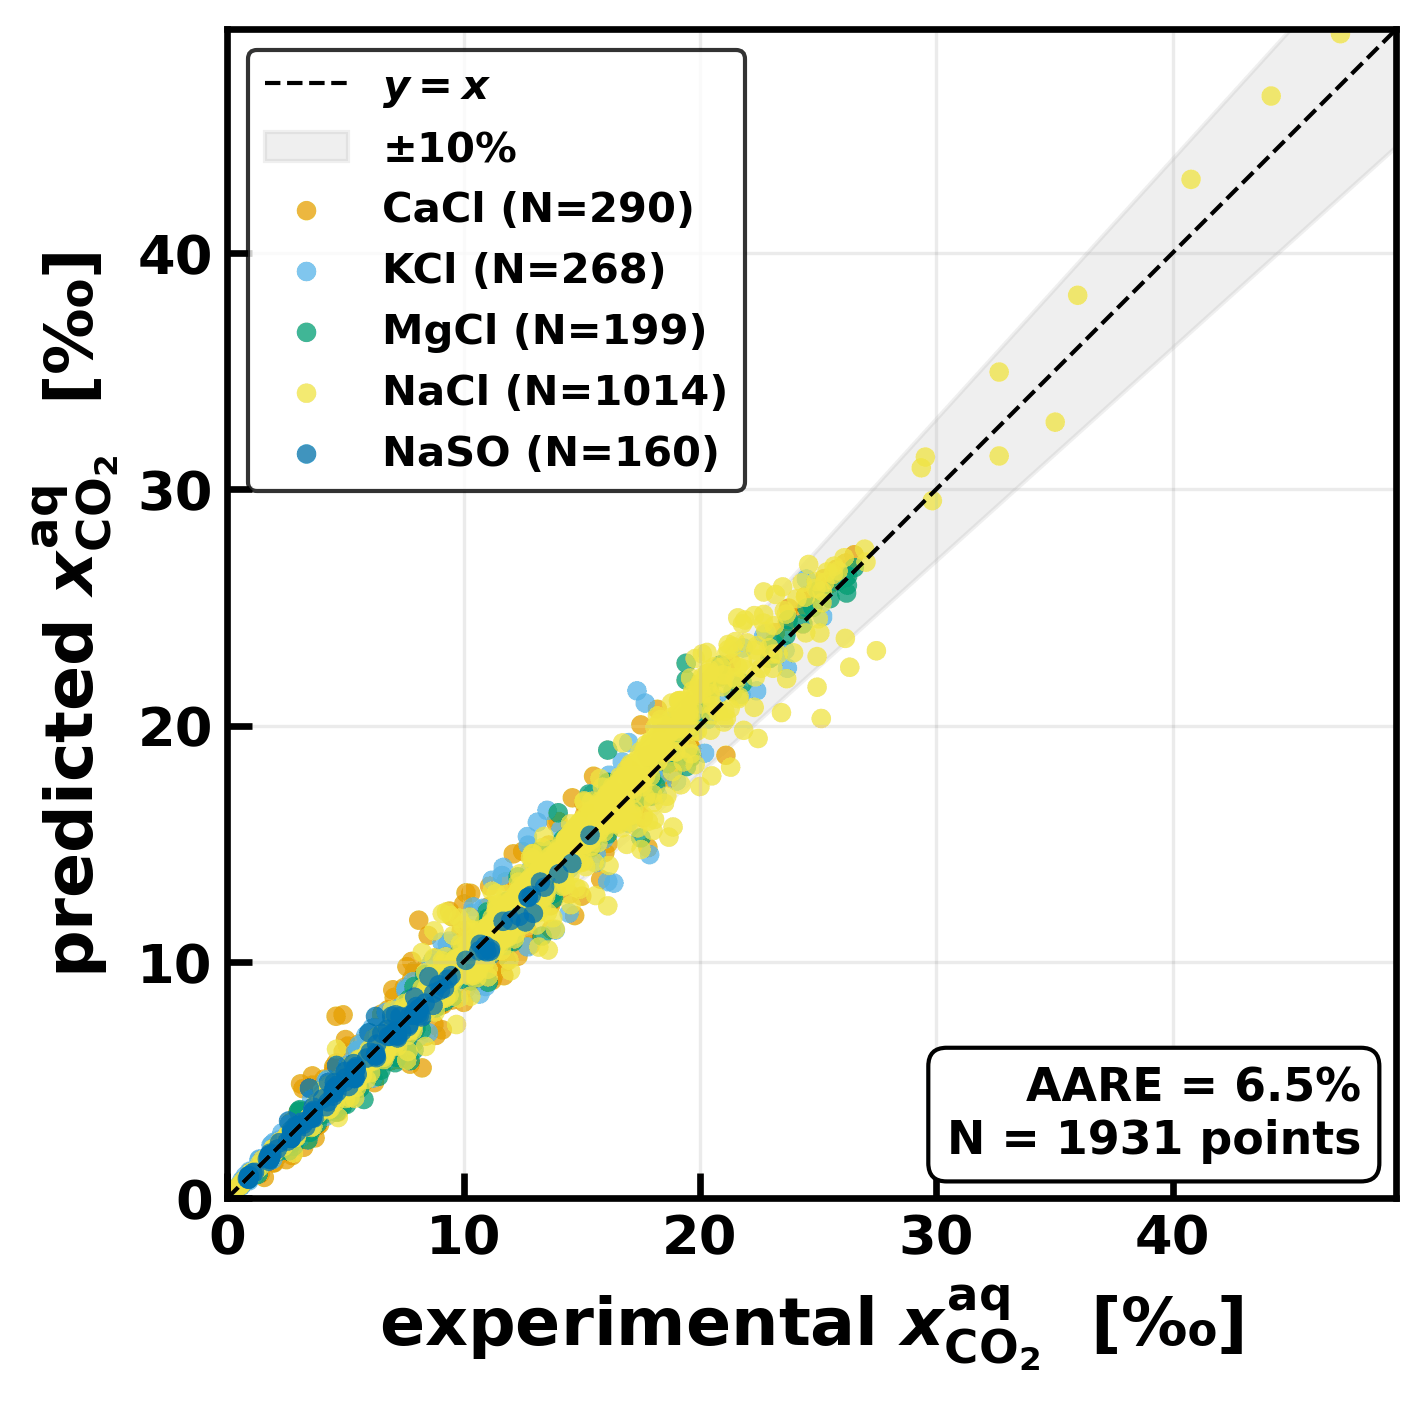

In [2]:
run('scripts/fig_flash_predictions.py')
show('flash_parity_CO2_brines_main.png')


<a id="mfig2"></a>

**Figure 2.** Parity plot of predicted versus experimental $\mathrm{CO_{2}}$ aqueous-phase mole fraction across all 1931 single-salt $\mathrm{CO_{2}}$–brine measurements of Moortgat et al.<sup>[19](#mref19)</sup> ($\mathrm{NaCl}$, $\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, and $\mathrm{Na_{2}SO_{4}}$ brines, $T = 283$–$473$ K, $P = 1.3$–$1200$ bar). The predictions are produced by the hierarchical TPD-stability $\to$ $K$-value-SSI $\to$ Newton-polish flash of Sections 2.2–2.3. The overall AARE is $6.55\%$. Axes are in per-mil (‰).

Figure 2 compares flash-predicted aqueous $\mathrm{CO_{2}}$ mole fractions against experiment across all five single-salt brines between 283 and 473 K. Every point in this pool is a single-salt brine: no mixed-brine measurement enters it, and none entered the calibration of the parameters it tests. The per-salt error statistics are collected in Table 1. These 1931 points are the full single-salt $\mathrm{CO_{2}}$–brine set of Moortgat et al.<sup>[19](#mref19)</sup> (Table S5 of that work). Only the 702 points on the $323$, $373$ and $423$ K isotherms entered the gas–ion energy fit; the remaining 1229 lie outside it, so the pooled statistic is not a pure calibration residual. What it measures is the fidelity of the stability-and-flash pipeline to the parameterized surface across the whole measured range, rather than the predictive capability of the parameter set on compositions it has never seen. For that, see the mixed-brine test of Moortgat et al.<sup>[19](#mref19)</sup>. Our predictions of $\mathrm{CO_{2}}$ solubility have a global AARE of $6.55\%$, with $\mathrm{Na_{2}SO_{4}}$ the best-performing salt at $4.26\%$. A per-salt parity figure (Fig. S2) and a comparison of the ms-eCPA error against the experimental literature variance (Fig. S3) are provided in Section S8 of the Supporting Information.


<a id="mtab1"></a>

**Table 1.** Per-salt average absolute relative errors (AARE) of the ms-eCPA $K$-value flash against experimental $\mathrm{CO_{2}}$-brine solubilities over the full single-salt set of Moortgat et al.<sup>[19](#mref19)</sup> (283–473 K). $N$ denotes the number of experimental points per salt; all author cohorts are pooled. AARE is computed on the aqueous $\mathrm{CO_{2}}$ mole fraction; Part I tabulates the corresponding AAD on $\mathrm{CO_{2}}$ molality, and over these five salts the two agree to the precision printed.

In [3]:
import json
import pandas as pd

run("scripts/fig_flash_predictions.py")
st = json.load(open("results_cache/fig_flash_predictions_stats.json"))
names = {"NaCl": "NaCl", "KCl": "KCl", "CaCl": "CaCl₂", "MgCl": "MgCl₂", "NaSO": "Na₂SO₄"}
rows = [{"Salt": names[k], "N": st["per_salt"][k]["N"], "AARE (%)": f"{st['per_salt'][k]['aare']:.2f}"}
        for k in names]
rows.append({"Salt": "Total", "N": st["N_total"], "AARE (%)": f"{st['aare_overall']:.2f}"})
show_table(pd.DataFrame(rows))


Salt,N,AARE (%)
NaCl,1014,5.37
KCl,268,7.17
CaCl₂,290,11.01
MgCl₂,199,7.08
Na₂SO₄,160,4.26
Total,1931,6.55


The spread across salts in Table 1 is not ordered by the identity of the cation. It follows largely from how far each brine extends beyond the salinity range over which its ion parameters were anchored. Those parameters are anchored on osmotic coefficients to $m_s \le 6$ for $\mathrm{NaCl}$ and $\le 4.5$ mol kg$^{-1}$ for $\mathrm{KCl}$, but only to $\le 2$ mol kg$^{-1}$ for $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$ and $\mathrm{Na_{2}SO_{4}}$ (Table 3 of Part I). The $\mathrm{CO_{2}}$-solubility validation, by contrast, reaches 6, 4.5, 6, 5 and 2.7 mol kg$^{-1}$ respectively. $\mathrm{NaCl}$ and $\mathrm{KCl}$ therefore never leave their ranges; $\mathrm{Na_{2}SO_{4}}$ exceeds its own by a factor 1.35, $\mathrm{MgCl_{2}}$ by 2.5 and $\mathrm{CaCl_{2}}$ by 3. Split at each salt’s own range edge, the residual is 5.82% inside ($N = 1759$) against 14.02% outside ($N = 172$). Resolving it by ionic strength puts every one of those 172 points in the highest bin, the only one that stands above an otherwise flat floor. Accuracy is therefore warranted over the salinity range each ion was anchored over and should be quoted with it. The divalent chlorides leave that range first, because at equal molality they have three times the ionic strength of a 1:1 salt. The electrostatic terms respond most strongly to those brines, and they treat the solvent as a continuum around ions of concentration-independent radius. That approximation is least accurate where the residual is largest: there are 3.1 water molecules per ion at 6 mol kg$^{-1}$ $\mathrm{CaCl_{2}}$ against 9.3 at the range edge. Section S8 gives the per-salt and per-bin breakdown, the two terms explicitly, and a comparison of the residual against the measured inter-laboratory scatter. A concentration-dependent hydration description is the natural next step and is pursued separately.

The ion-specific construction is meant to apply to mixtures of salts without further fitting, and mixed-brine measurements test this directly. In the parameterization study we assembled nineteen mixed-brine recipes from nine sources<sup>[23](#mref23)–[31](#mref31)</sup>. Together they comprise 314 $\mathrm{CO_{2}}$ solubility measurements in brines of three to six distinct ions, ionic strength $0.31$–$5.89$ mol kg$^{-1}$, $T = 291.15$–$423$ K and $P = 3.4$–$571$ bar. Neither the gas–ion energies nor the Péneloux coefficients are tuned to any of them, so these are predictions rather than fits. Scored through the same pipeline and on the same basis as Table 1, all 314 converge at an overall AARE of 6.7% (per-recipe 2.5–13.5%), against 6.3% for the single-salt compilation over the same window. A brine of several salts is thus described as well as a brine of one, with no parameter added. Per-recipe comparisons are in the Supporting Information of Moortgat et al.<sup>[19](#mref19)</sup>.


<a id="msec3_2"></a>

### 3.2 Nitrogen, hydrogen, ethane, and propane in brine

In ms-eCPA a new gas adds no structural complexity: it enters through its pure-component constants, one gas–water binary interaction, and its gas–ion energies, the water, ion and electrostatic levels being unchanged. The four gases examined here span the range of parameter provenance. For $\mathrm{N_{2}}$ the gas–ion energies are *transferred* from the calibrated $\mathrm{CH_{4}}$ values rather than fitted. For $\mathrm{H_{2}}$ the parameterization of Coelho et al.<sup>[4](#mref4)</sup> is adopted unchanged. Neither contributes a salt-specific parameter fitted in this work. Ethane and propane complete the spectrum: their gas–water binaries are fitted here and, because the $\mathrm{CH_{4}}$ transfer fails for both, their $\mathrm{Na^{+}}$/$\mathrm{Cl^{-}}$ and $\mathrm{K^{+}}$ energies are calibrated against salting-out data. Table 2 collects the parameters of all four.

$\mathrm{N_{2}}$ enters the first level of the hierarchy through its critical constants (Table 2) and the second through a $\mathrm{N_{2}}$–$\mathrm{H_{2}O}$ binary parameter of the form of Eq. (3) (with $T^k_{ij} = T_{c,\mathrm{H_{2}O}}$). This parameter is fitted to the 18 salt-free points of O’Sullivan and Smith<sup>[32](#mref32)</sup> ($T = 324.65$–$398.15$ K, $P = 100$–$608$ atm), which it reproduces with an AARE of 1.09%. At the fourth level no $\mathrm{N_{2}}$–ion parameter is fitted. Because the gas–ion energy is linear in $T/T_{c,\text{gas}}$ (Eq. (4)), the calibrated $\mathrm{CH_{4}}$–ion energies of all six ions of the suite are transferred through the function-preserving rescale of the slope coefficient by $T_{c,\mathrm{N_{2}}}/T_{c,\mathrm{CH_{4}}}$ (intercept unchanged). As a result, $\Delta U_{gi}(T)$ is numerically identical for the two gases. The 33 brine points of O’Sullivan and Smith<sup>[32](#mref32)</sup> (1 and 4 mol kg$^{-1}$ $\mathrm{NaCl}$, same $T$–$P$ window) are then predicted with no parameter fitted to nitrogen-in-brine data, here or in Part I, and matched with an AARE of 3.66%. This is the same quality as the calibrated $\mathrm{CH_{4}}$–brine description itself. The salt-free points that fix the binary and the brine points that test the transfer come from the same table of the same paper, so this tests transferability across salinity rather than across data sources. Allowing the brine data to adjust the transferred ($\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$) pair through one scaling factor converges to $s = 1.0084$ and improves the brine AARE only to 3.46%. The explicit fit confirms the transfer rather than correcting it, and the two curve families in Fig. 3 are visually coincident. This quantifies, at the level of the equation of state, the early observation of O’Sullivan and Smith<sup>[32](#mref32)</sup> that $\mathrm{N_{2}}$ and $\mathrm{CH_{4}}$ salt out almost identically.

$\mathrm{H_{2}}$ probes the complementary extreme: no additional parameter fitting in the present study, of any kind. The $\mathrm{H_{2}}$ eCPA parameterization of Coelho et al.<sup>[4](#mref4)</sup> — SRK constants from the critical point, a $\mathrm{H_{2}}$–$\mathrm{H_{2}O}$ binary parameter of the form of Eq. (3), and a single $\mathrm{H_{2}}$–ion interaction energy shared by $\mathrm{Na^{+}}$ and $\mathrm{Cl^{-}}$ — is adopted unaltered. Those parameters were regressed in a salt-specific $\mathrm{NaCl}$ basis, whereas in the present framework they are combined with ion-specific diameters, Born radii, dispersion terms, water–ion energies and volume translations; embedding them unchanged is therefore a basis transfer rather than a reproduction. The salt-free binary transfers essentially losslessly, the water level being common to both frameworks: over the fit set of Coelho et al.<sup>[4](#mref4)</sup> the aqueous $\mathrm{H_{2}}$ solubility is reproduced to 9.30% ($N_p = 149$) against 8.97% for the original model. The discriminating test is the 71-point $\mathrm{H_{2}}$–$\mathrm{NaCl}$ compilation of Chabab et al.<sup>[33](#mref33)</sup>, Chabab et al.<sup>[34](#mref34)</sup>, Torín-Ollarves and Trusler<sup>[35](#mref35)</sup> ($T = 298$–$423$ K, $P \le 458$ bar, $1$–$5$ mol kg$^{-1}$). The ion-specific embedding yields an AARE of 9.13% against the 8.64% of the original fit, so the basis transfer raises the AARE by about 0.5 percentage points (Fig. 4). As a consistency check beyond the binary data, we ran $\mathrm{H_{2}}$–$\mathrm{CO_{2}}$–brine ternary flashes with the production ion-specific $\mathrm{CO_{2}}$ set of this work. They agree with the published model curves of Coelho et al.<sup>[4](#mref4)</sup> to 0.23–3.3% in the aqueous $\mathrm{H_{2}}$ and $\mathrm{CO_{2}}$ molalities at $323$–$423$ K, $200$–$400$ bar, and $1$–$4$ mol kg$^{-1}$ $\mathrm{NaCl}$.


<a id="mtab2"></a>

**Table 2.** Basic ms-eCPA parameters of $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, and $\mathrm{C_{3}H_{8}}$. None of the four gases has association sites.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline">N<sub>2</sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline">H<sub>2</sub></span><span class="math inline"><sup> <em>d</em></sup></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline">C<sub>2</sub>H<sub>6</sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline">C<sub>3</sub>H<sub>8</sub></span></th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>T</em><sub><em>c</em></sub></span> [K]</td>
<td style="padding:2px 8px;border:none;text-align:left">126.19</td>
<td style="padding:2px 8px;border:none;text-align:left">33.2</td>
<td style="padding:2px 8px;border:none;text-align:left">305.32</td>
<td style="padding:2px 8px;border:none;text-align:left">369.83</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>P</em><sub><em>c</em></sub></span> [bar]</td>
<td style="padding:2px 8px;border:none;text-align:left">33.96</td>
<td style="padding:2px 8px;border:none;text-align:left">13.0</td>
<td style="padding:2px 8px;border:none;text-align:left">48.72</td>
<td style="padding:2px 8px;border:none;text-align:left">42.48</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>ω</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">0.0372</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.220</span></td>
<td style="padding:2px 8px;border:none;text-align:left">0.0995</td>
<td style="padding:2px 8px;border:none;text-align:left">0.1523</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>α</em><sub>0</sub></span> [<span class="math inline">10<sup>−40</sup></span> C<span class="math inline"><sup>2</sup></span> m<span class="math inline"><sup>2</sup></span> J<span class="math inline"><sup>−1</sup></span>]</td>
<td style="padding:2px 8px;border:none;text-align:left">1.936</td>
<td style="padding:2px 8px;border:none;text-align:left">0.876</td>
<td style="padding:2px 8px;border:none;text-align:left">4.974</td>
<td style="padding:2px 8px;border:none;text-align:left">6.999</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sub><em>i</em><em>j</em></sub><sup><em>k</em></sup></span> (gas–<span class="math inline">H<sub>2</sub>O</span>)<span class="math inline"><sup> <em>a</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">5.5159</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−7.7662</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−2.7028</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−2.7474</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>B</em><sub><em>i</em><em>j</em></sub><sup><em>k</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−3.9679</span></td>
<td style="padding:2px 8px;border:none;text-align:left">12.3078</td>
<td style="padding:2px 8px;border:none;text-align:left">3.7322</td>
<td style="padding:2px 8px;border:none;text-align:left">3.4965</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>C</em><sub><em>i</em><em>j</em></sub><sup><em>k</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">0.4660</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−4.5906</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.1387</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.0464</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Δ</em><em>U</em><sub><em>g</em><em>i</em></sub></span> (gas–ion) [J mol<span class="math inline"><sup>−1</sup></span>]</td>
<td style="padding:2px 8px;border:none;text-align:left">transfer<span class="math inline"><sup> <em>b</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">adopted<span class="math inline"><sup> <em>c</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">scaled<span class="math inline"><sup> <em>e</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">scaled<span class="math inline"><sup> <em>f</em></sup></span></td>
</tr>
</tbody>
</table>


The SRK constants $a_0$ and $b$ follow from $T_c$ and $P_c$, and $c_1$ from $\omega$, through the standard SRK relations<sup>[36](#mref36)</sup>; $\alpha_0$ is the electronic polarizability entering the permittivity model. $^a$Coefficients of the quadratic $k_{ij}(T)$ of Eq. (3) with $T^k_{ij} = T_{c,\mathrm{H_{2}O}}$. $^b$$\mathrm{CH_{4}}$–ion energies of the parameterization study with the slope rescaled by $T_{c,\mathrm{N_{2}}}/T_{c,\mathrm{CH_{4}}} = 0.6622$ and the intercept unchanged (see text). $^c$$\Delta U_{gi}(T) = \Delta U_\text{ref}
+ \alpha R \left[(1 - T/T_\alpha)^2
- (1 - T_\text{ref}/T_\alpha)^2\right]$ with $\Delta U_\text{ref} = 9992.9$ J mol$^{-1}$, $\alpha = -9889.1$ K, $T_\alpha = 364.5$ K, and $T_\text{ref} = 298.15$ K. $^d$All $\mathrm{H_{2}}$ values are adopted from Coelho et al.<sup>[4](#mref4)</sup>. $^e$$\mathrm{CH_{4}}$–ion energies rescaled as in $^b$ with $T_{c,\mathrm{C_{2}H_{6}}}/T_{c,\mathrm{CH_{4}}} = 1.6022$, then the ($\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$) pair scaled by $s_{\mathrm{NaCl}} = 0.722$ and $\mathrm{K^{+}}$ by $s_{\mathrm{K}} = 1.398$, both fitted to evaluated atmospheric-pressure Setschenow data (Section 3.2); $\mathrm{Ca^{2+}}$/$\mathrm{Mg^{2+}}$/$\mathrm{SO_{4}^{2-}}$ use the unscaled transfer (no experimental data available). $^f$As $^e$ with $T_{c,\mathrm{C_{3}H_{8}}}/T_{c,\mathrm{CH_{4}}} = 1.9408$, $s_{\mathrm{NaCl}} = 0.842$ (fitted to the Morrison and Billett<sup>[37](#mref37)</sup> $\mathrm{NaCl}$ set), and $s_{\mathrm{K}} = 1.676$ (fitted to the Yano et al.<sup>[38](#mref38)</sup> $\mathrm{KCl}$ datum).

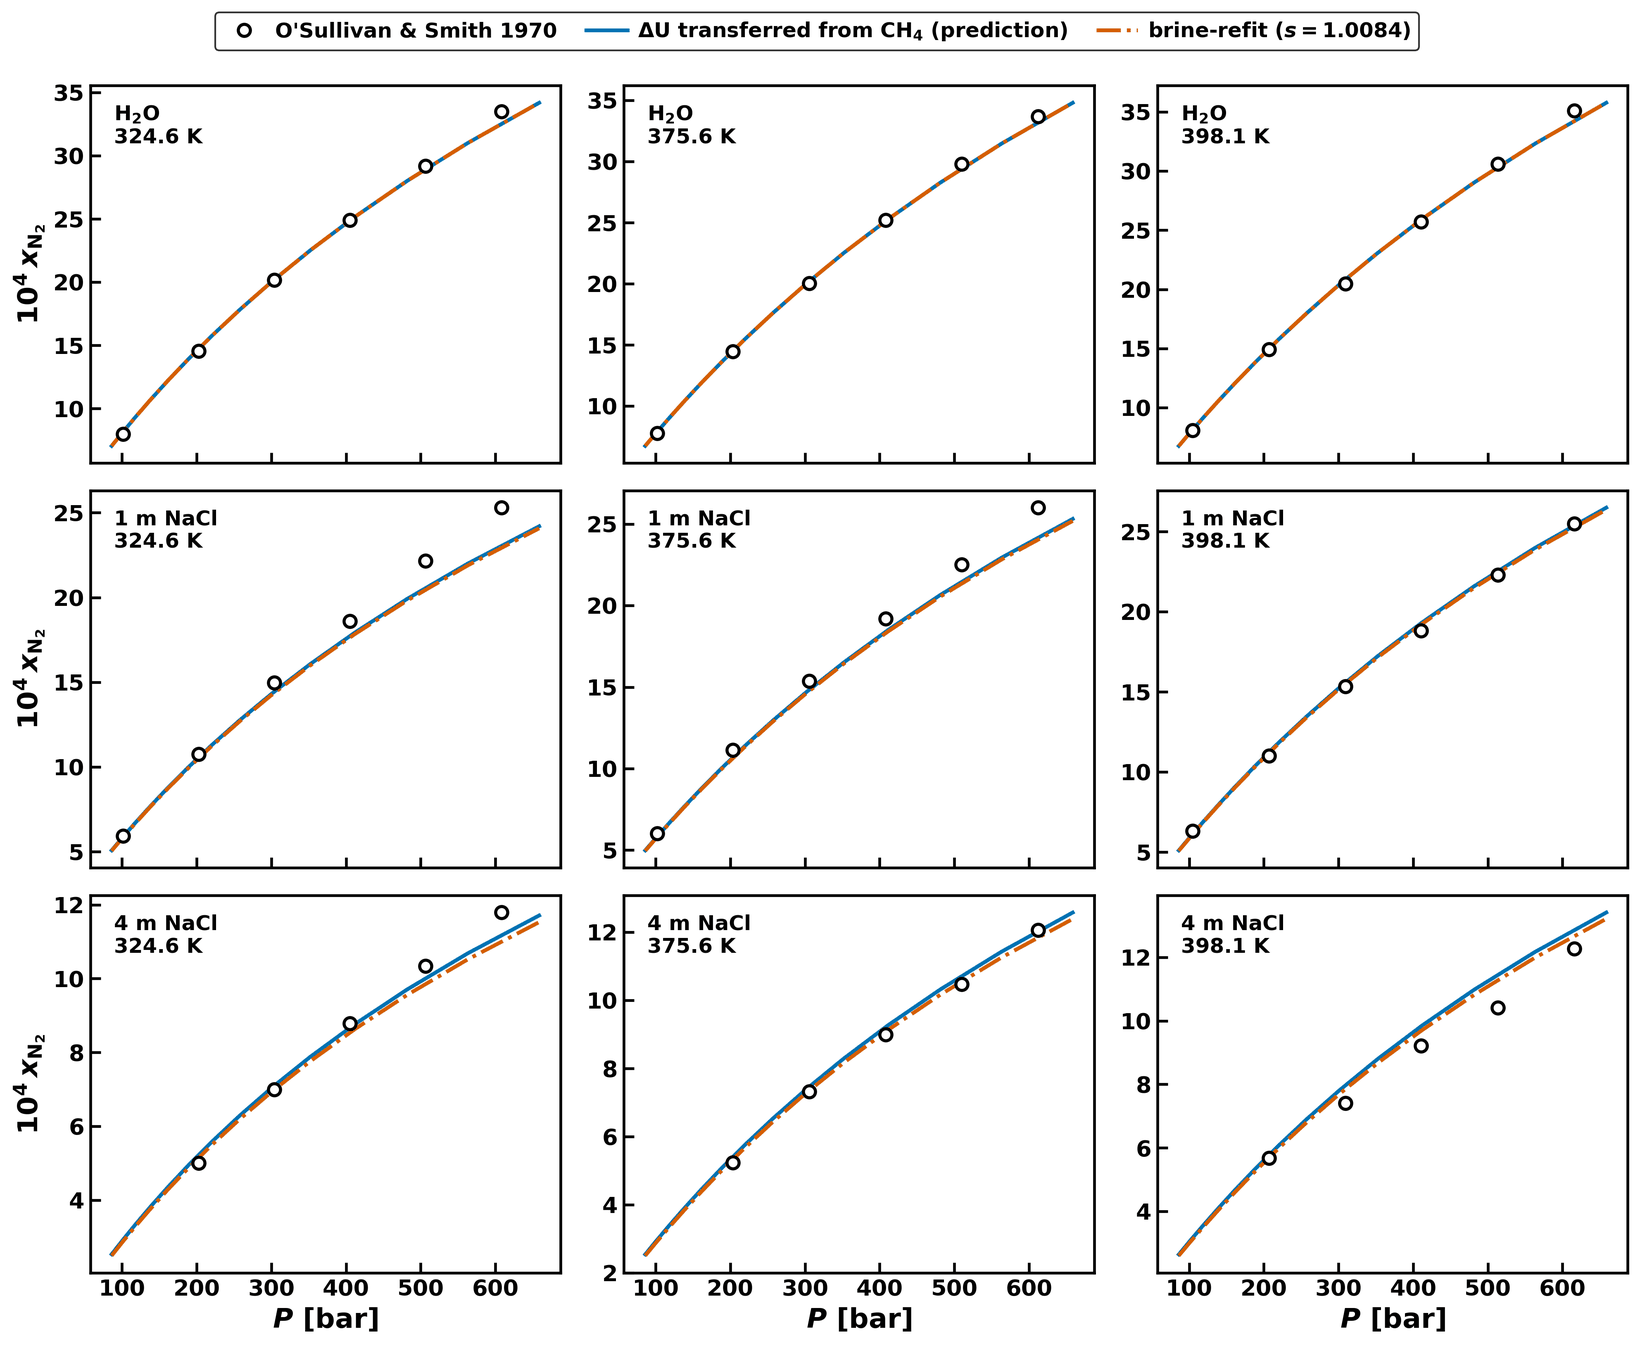

In [4]:
run('scripts/fig_additional_gases.py')
show('n2_brine_main.png')


<a id="mfig3"></a>

**Figure 3.** $\mathrm{N_{2}}$ solubility in water (top row) and in 1 and 4 mol kg$^{-1}$ $\mathrm{NaCl}$ brine (middle and bottom rows) at the three isotherms of O’Sullivan and Smith<sup>[32](#mref32)</sup> (symbols; aqueous $\mathrm{N_{2}}$ mole fraction on the salt-undissociated basis of that work, versus total pressure). Solid lines: gas–ion energies transferred from $\mathrm{CH_{4}}$ with the $T_c$ rescale — every brine panel is a prediction. Dash-dotted lines: the transferred ($\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$) energies rescaled by the brine-fitted factor $s = 1.0084$. The two families are visually coincident, confirming the transfer.

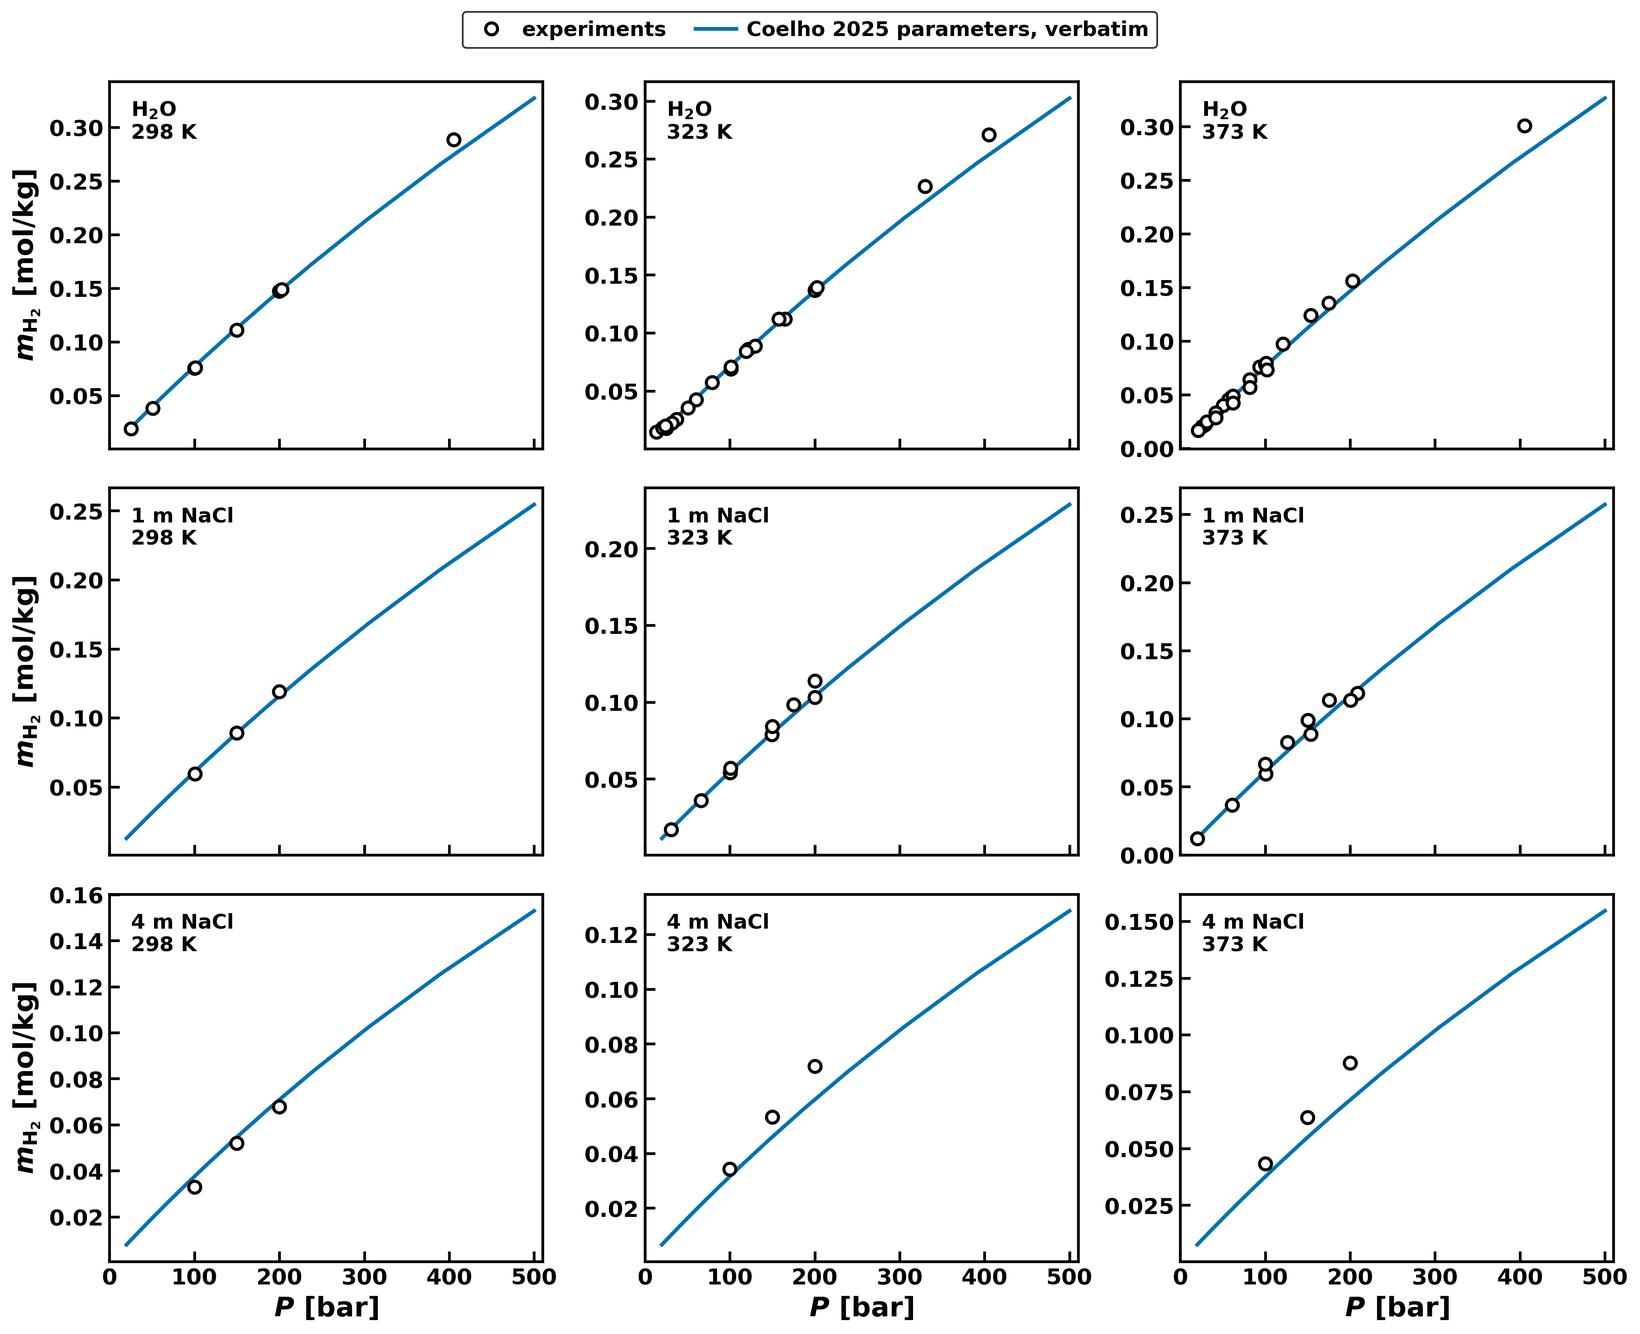

In [5]:
run('scripts/fig_additional_gases.py')
show('h2_brine_main.png')


<a id="mfig4"></a>

**Figure 4.** $\mathrm{H_{2}}$ molality in water (top row) and in 1 and 4 mol kg$^{-1}$ $\mathrm{NaCl}$ brine (middle and bottom rows) at 298, 323, and 373 K. Symbols: experimental data compiled by Coelho et al.<sup>[4](#mref4)</sup>; the brine measurements are those of Chabab et al.<sup>[33](#mref33)</sup>, Chabab et al.<sup>[34](#mref34)</sup>, Torín-Ollarves and Trusler<sup>[35](#mref35)</sup>. Lines: the $\mathrm{H_{2}}$ parameterization of Coelho et al.<sup>[4](#mref4)</sup> adopted verbatim, with no additional parameter fitting in the present study, and run through the multi-salt ion-specific framework of this work.

Ethane and propane fall outside the transfer class that $\mathrm{N_{2}}$ validated. As $\mathrm{CH_{4}}$ and $\mathrm{CO_{2}}$ did in Part I, they enter with gas–ion energies fitted to data, with as few parameters as those data support. Each takes one gas–water binary parameter of the form of Eq. (3), fitted here to salt-free solubilities (104 points for $\mathrm{C_{2}H_{6}}$, AARE 7.3%; 175 for $\mathrm{C_{3}H_{8}}$, 2.4%). Each also takes two scale factors on the transferred gas–ion energies, fitted to evaluated atmospheric-pressure Setschenow constants: one for the ($\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$) pair and one for $\mathrm{K^{+}}$. The $T_c$ rescale that predicts $\mathrm{N_{2}}$ salting-out without any brine fit misses those constants in *opposite* directions for the two salts: $+63\%$ and $-33\%$ at $298$ K for ethane, $+34\%$ and $-64\%$ for propane. No single rescale therefore repairs both. The breakdown grows with the departure of the solute’s polarizability from methane’s (1.9$\times$ for ethane, 2.7$\times$ for propane, Table 2). This turns the single ethane observation into a trend: gas–ion transfer from $\mathrm{CH_{4}}$ without brine fitting is reliable within the small-nonpolar class that $\mathrm{N_{2}}$ validated, and degrades systematically beyond it. Section S11 of the Supporting Information gives the binary fits, the fitted scales and their temperature dependence, and the brine comparisons for both gases. For $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$ and $\mathrm{SO_{4}^{2-}}$ no ethane or propane solubility data exist at any pressure<sup>[41](#mref41),[48](#mref48)</sup>. Those ions therefore use the unscaled transfer as untested estimates, and all high-pressure ethane– and propane–brine behavior is a declared prediction.

Table 3 summarizes the parameters each gas requires and the resulting accuracy of each gas. Four qualifications bound the domain of the new entries.

First, $\mathrm{N_{2}}$ and $\mathrm{H_{2}}$ stand in different relations to a multi-salt brine. The $\mathrm{N_{2}}$ gas–ion energies are not $\mathrm{NaCl}$-specific — the $T_c$ rescale acts on the $\mathrm{CH_{4}}$ energy of every ion — so $\mathrm{N_{2}}$ has a complete per-ion set and a mixed-brine calculation follows the same path as $\mathrm{CH_{4}}$. What is confined to $\mathrm{NaCl}$ is the evidence, so $\mathrm{N_{2}}$ in a brine bearing any other ion is a prediction based on the $\mathrm{CH_{4}}$ calibration rather than a validated result. The $\mathrm{H_{2}}$ case is stricter. Coelho et al.<sup>[4](#mref4)</sup> supply one $\mathrm{H_{2}}$–ion energy shared by $\mathrm{Na^{+}}$ and $\mathrm{Cl^{-}}$ and none for the other four. The $\mathrm{H_{2}}$ results reported here are therefore limited to $\mathrm{NaCl}$ brines. Because ms-eCPA is ion-specific, $\mathrm{H_{2}}$ in other brines requires only $\mathrm{H_{2}}$–ion energies for the remaining ions, obtained from $\mathrm{H_{2}}$ solubility data in brines that contain them.

Second, brine solubility data do not determine the individual gas–ion energies at all. They enter only through $\sum_i x_i (b_g + b_i) \Delta U_{gi}$, which electroneutrality leaves invariant under $\Delta U_{gi} \rightarrow \Delta U_{gi} + \lambda z_i/(b_g +
b_i)$. Only charge-weighted combinations are identified, and the $\mathrm{Na^{+}}$:$\mathrm{Cl^{-}}$ split of a pair is a convention on which no computed property depends. Reaching a new ion therefore requires data in a brine containing it. That is how the $\mathrm{CH_{4}}$ per-ion set was obtained<sup>[19](#mref19)</sup> and how the $\mathrm{C_{2}H_{6}}$ and $\mathrm{C_{3}H_{8}}$ $\mathrm{K^{+}}$ scales were fixed, and it is what the suite still lacks for $\mathrm{N_{2}}$, $\mathrm{H_{2}}$ and the divalent ions of ethane and propane.


<a id="mtab3"></a>

**Table 3.** Parameters required and accuracy for each gas in the multi-salt framework. “Water” denotes the salt-free gas–water binary and “brine” the gas-in-brine solubility validation; $N_p$ counts the points behind each brine and water AARE. The $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ brine entries are the calibrated sets of Moortgat et al.<sup>[19](#mref19)</sup> and Section 3.1; the $\mathrm{CH_{4}}$ water value is the compilation AAD of that study. The $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binary is inherited from Coelho et al.<sup>[20](#mref20)</sup> and is not re-validated here. $^a$For $\mathrm{C_{2}H_{6}}$ and $\mathrm{C_{3}H_{8}}$ the brine entry is the Setschenow-constant AAD in $\mathrm{NaCl}$ / $\mathrm{KCl}$ (atmospheric-pressure basis), not a solubility AARE; the $\mathrm{C_{3}H_{8}}$–$\mathrm{KCl}$ scale is calibrated to a single temperature and therefore provides no independent test (—).

In [6]:
import json
import pandas as pd

run("scripts/fig_flash_predictions.py")
run("scripts/fig_ch4_singlesalt.py")
run("scripts/build_paper_tables.py")
run("scripts/fig_additional_gases.py")
co2 = json.load(open("results_cache/fig_flash_predictions_stats.json"))
ch4b = json.load(open("results_cache/fig_ch4_singlesalt_stats.json"))
ch4w = latex_table(nbtools.TAB / "tables" / "exp_ch4_h2o.tex", 7).query("Reference == 'Global'").iloc[0]
gas = json.load(open("results_cache/fig_additional_gases_stats.json"))
c2w = json.load(open("pilot_studies/c2_pilot_2026_08/refit_state.json"))
c2b = json.load(open("pilot_studies/c2_pilot_2026_08/c2_ions_results.json"))
c3 = json.load(open("pilot_studies/c3_pilot_2026_08/work_state.json"))
released = pd.DataFrame([
    {"Gas": "CO₂", "AARE water (%)": "—", "AARE brine (%)": f"{co2['aare_overall']:.2f}",
     "N_p (water / brine)": f"— / {co2['N_total']}"},
    {"Gas": "CH₄", "AARE water (%)": ch4w["AAD^W (%)"], "AARE brine (%)": f"{ch4b['aare_overall']:.2f}",
     "N_p (water / brine)": f"{ch4w['N_p^W']} / {ch4b['N_total']}"},
    {"Gas": "N₂", "AARE water (%)": f"{gas['n2']['aare_water']:.2f}",
     "AARE brine (%)": f"{gas['n2']['aare_brine_transfer']:.2f}",
     "N_p (water / brine)": f"{gas['n2']['N_water']} / {gas['n2']['N_brine']}"},
    {"Gas": "H₂", "AARE water (%)": f"{gas['h2']['aare_water_fitset']:.2f}",
     "AARE brine (%)": f"{gas['h2']['aare_brine']:.2f}",
     "N_p (water / brine)": f"{gas['h2']['N_water_fitset']} / {gas['h2']['N_brine']}"},
    {"Gas": "C₂H₆", "AARE water (%)": f"{c2w['report']['fitQ']['overall_aare_pct']:.1f}",
     "AARE brine (%)": f"{c2b['NaCl_aad_pct']:.1f} / {c2b['KCl_aad_pct']:.1f}",
     "N_p (water / brine)": f"{c2w['fitQ']['n_points']} / {len(c2b['NaCl']) + len(c2b['KCl'])}"},
    {"Gas": "C₃H₈", "AARE water (%)": f"{c3['A']['fitB_s0']['aare_x_pct']:.1f}",
     "AARE brine (%)": f"{c3['S']['NaCl_aad_pct']:.1f} / —",
     "N_p (water / brine)": f"{c3['A']['fitB_s0']['n_x_conv']} / {len(c3['fitS']['targets']) + 1}"},
])
# Published Table 3 (AARE and N_p columns). The CH4 entries were computed with the
# earlier code of the Paper II CH4 tables (see multisalt/PUBLISHED_VS_RELEASED.md).
# Entries read "published → released" where the two differ.
published = pd.DataFrame([
    ("CO₂", "—", "6.55", "— / 1931"), ("CH₄", "11.1", "7.25", "836 / 469"),
    ("N₂", "1.09", "3.66", "18 / 33"), ("H₂", "9.30", "9.13", "149 / 71"),
    ("C₂H₆", "7.3", "7.7 / 2.3", "104 / 19"), ("C₃H₈", "2.4", "7.6 / —", "175 / 5")],
    columns=released.columns)
show_table(nbtools.side_by_side(published, released, on=["Gas"], cols=list(released.columns[1:])))


Gas,AARE water (%),AARE brine (%),N_p (water / brine)
CO₂,—,6.55,— / 1931
CH₄,11.1 → 7.6,7.25 → 8.16,836 / 469 → 835 / 485
N₂,1.09,3.66,18 / 33
H₂,9.30,9.13,149 / 71
C₂H₆,7.3,7.7 / 2.3,104 / 19
C₃H₈,2.4,7.6 / —,175 / 5


Third, each gas has a validation window. $\mathrm{N_{2}}$ is validated over $325$–$398$ K at $100$–$608$ atm, the span of the single source its binary is anchored to, and $\mathrm{H_{2}}$ over $298$–$423$ K at $P \le 458$ bar in $1$–$5$ mol kg$^{-1}$ $\mathrm{NaCl}$. Fourth, all brine comparisons in this section are single-salt: we are aware of no mixed-brine solubility data for any of these gases, nor for $\mathrm{CH_{4}}$, so those predictions stand untested. Within these bounds, the four gases show in steps how many fitted parameters a new gas needs at the fourth level of the parameter hierarchy<sup>[19](#mref19)</sup>. Inside the transfer class, a new gas needs at most one salt-free binary fit and its salting-out follows as a prediction ($\mathrm{N_{2}}$). A published salt-specific parameterization transfers essentially losslessly ($\mathrm{H_{2}}$). Outside the transfer class the requirement rises to a binary fit plus a small number of ion-energy scales ($\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$). That is still far below the full per-ion calibration that $\mathrm{CH_{4}}$ and $\mathrm{CO_{2}}$ received in the parameterization study. This asymmetry is the benefit of the hierarchy. The brine is parameterized once, against the gas–brine, density and osmotic data of Part I, and a new gas does not change it. For $\mathrm{N_{2}}$ no brine measurement enters ms-eCPA at all, so the $\mathrm{N_{2}}$ brine comparison is a test of the transfer rather than an input to it. Their extent bounds how much of the prediction can be checked, not what we can compute with the framework. $\mathrm{C_{2}H_{6}}$ and $\mathrm{C_{3}H_{8}}$ are the counterexample that makes the statement bounded rather than universal.


<a id="msec3_3"></a>

### 3.3 $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ and $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–brine

The ternary $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ system is shown in Fig. 5 at the three isotherms for which mutual-solubility data are available — 344, 376, and 423 K, spanning the calibration window. ms-eCPA is compared with the data of Dhima et al.<sup>[49](#mref49)</sup>, Qin et al.<sup>[50](#mref50)</sup>, Al Ghafri et al.<sup>[51](#mref51)</sup> in all three measured views: the aqueous $\mathrm{CH_{4}}$ and $\mathrm{CO_{2}}$ mole fractions and the gas-phase water content. No ms-eCPA parameter is fitted to ternary data, and the only quantity that involves the two gases with each other is the constant $k_{hc}$ of Section 2.1. Scored at the measured states of the three isotherms plotted here, with the same stability-and-flash route that generates the curves, the ms-eCPA EoS reproduces the aqueous $\mathrm{CH_{4}}$ mole fraction to an average absolute relative error of 11.97% ($n = 29$). It reproduces the aqueous $\mathrm{CO_{2}}$ mole fraction to 14.73% ($n = 29$), and the gas-phase water content to 29.00% ($n = 20$). Resolved by isotherm, the aqueous $\mathrm{CH_{4}}$ deviation is 3.8% at 344 K and 7.8% at 376 K but 39.1% at 423 K. On the salt-free binaries over the same window the deviations are 5.25% and 6.96%, so adding the third component roughly doubles the deviation for each gas, with no parameter fitted beyond those of the binaries. The gas-phase water content is the weakest view here and in the binaries alike. Section S12 gives the per-isotherm table for both solver routes, adds the 323 K isotherm not plotted here, and shows that setting $k_{hc}$ to zero moves the aqueous $\mathrm{CH_{4}}$ and gas-phase water deviations by less than one percentage point.


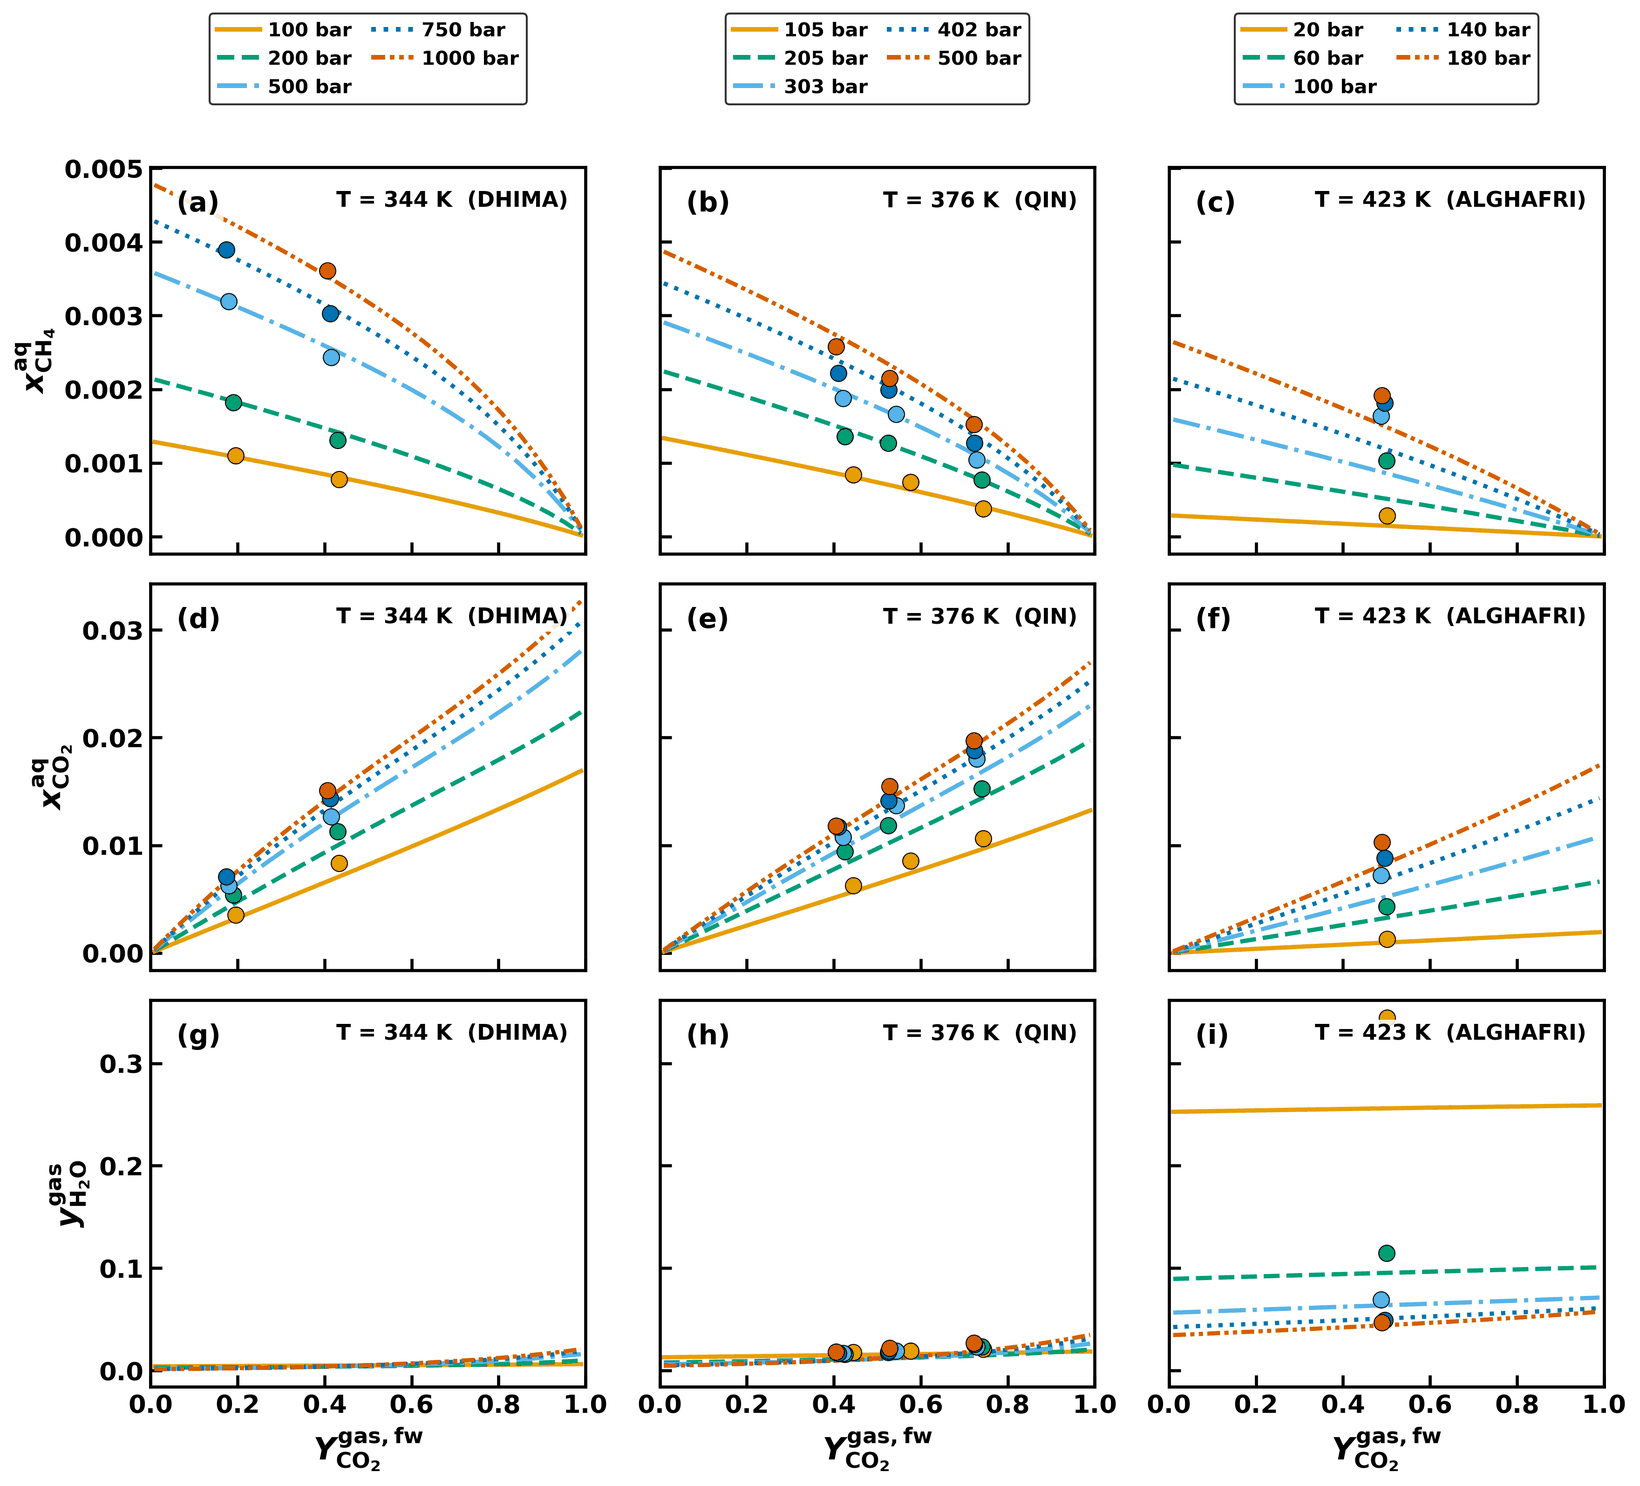

In [7]:
run('scripts/fig_ccw_ternary.py')
show('ccw_ternary_SI.png')


<a id="mfig5"></a>

**Figure 5.** Phase equilibria of $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ from ms-eCPA (continuous lines) and experiments<sup>[49](#mref49)–[51](#mref51)</sup> (discrete symbols). Rows are aqueous $\mathrm{CH_{4}}$ mole fraction $x_{\mathrm{CH_4}}^{\mathrm{aq}}$ (a–c), aqueous $\mathrm{CO_{2}}$ mole fraction $x_{\mathrm{CO_2}}^{\mathrm{aq}}$ (d–f), and gas-phase $\mathrm{H_{2}O}$ mole fraction $y_{\mathrm{H_2O}}^{\mathrm{gas}}$ (g–i). Columns are $T = 344$ K (Dhima et al.<sup>[49](#mref49)</sup>), 376 K (Qin et al.<sup>[50](#mref50)</sup>), and 423 K (Al Ghafri et al.<sup>[51](#mref51)</sup>). Each author measured at a different set of pressures, so the per-column legends on the top row list the pressures for that column.

In a brine environment the relative solubility of $\mathrm{CH_{4}}$ and $\mathrm{CO_{2}}$ depends on both the water-free gas composition and the ionic composition of the brine. $\mathrm{CO_{2}}$ is preferentially extracted into the brine relative to $\mathrm{CH_{4}}$ at every salt, and the magnitude of the salting-out varies systematically with ion charge and identity. That selectivity is a prediction: we hold no mixed-gas solubility measurements in brine, in any salt, against which it could be scored, and the ternary validation of Fig. 5 is salt-free. Section S13 of the Supporting Information plots it for each single-salt brine at 323 K and 300 bar.


<a id="msec3_4"></a>

### 3.4 Three-phase equilibria: salt-free loci and brine predictions

Below the $\mathrm{CO_{2}}$ critical temperature we use the hierarchical procedure of Section 2.4 to detect and compute the coexistence of vapor, brine, and a $\mathrm{CO_{2}}$-rich liquid. For the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binary, the three-phase locus $P_3(T)$ is located as the pressure at which the second (dense or vapor) root of the non-aqueous phase crosses the tangent plane of the converged two-phase equilibrium. Figure 6 compares the predicted locus with the pure-$\mathrm{CO_{2}}$ saturation curve of the Span–Wagner reference equation of state<sup>[52](#mref52)</sup>, which the measured three-phase pressures of Wendland et al.<sup>[21](#mref21)</sup> follow within a few tenths of a bar. The dilute water content of the two $\mathrm{CO_{2}}$-rich phases barely perturbs their equilibrium. Across the calibration range, $T = 283$–$302$ K, the predicted locus lies 0.2–1.1 bar (0.4–1.5%) below the reference curve, with the deviation growing toward the $\mathrm{CO_{2}}$ critical point. This deviation is typical of a cubic equation of state near the critical point and comes from the SRK term of ms-eCPA. Above $P_3(T)$ the stable liquid-$\mathrm{CO_{2}}$–brine split correctly replaces the metastable vapor–brine split. The aqueous $\mathrm{CO_{2}}$ solubility then crosses over from the steep pressure dependence of the vapor branch to the weak pressure dependence of the liquid–liquid branch.

A second gas opens the locus into a finite three-phase region. For a feed with a modest $\mathrm{CH_{4}}$ fraction ($z = 0.50/0.03/0.47$ $\mathrm{H_{2}O}$/$\mathrm{CH_{4}}$/$\mathrm{CO_{2}}$ at 283 K, for example), three phases coexist from about 49 bar until the vapor is exhausted by condensation at higher pressure. At 49 bar the $\mathrm{CH_{4}}$-enriched vapor first saturates a $\mathrm{CO_{2}}$-rich liquid. The vapor fraction decreases monotonically as pressure increases, while $\mathrm{CH_{4}}$ concentrates in the shrinking vapor. Cross-phase isofugacity holds at $10^{-8}$ or better in all converged three-phase states; the cost of the three-phase computation is quantified alongside the two-phase statistics in Section 3.5.

Propane offers what $\mathrm{CO_{2}}$ cannot: a directly *measured* three-phase locus with measured compositions of all three phases<sup>[45](#mref45),[46](#mref46)</sup>, spanning 279–370 K. Propane’s higher critical temperature (369.8 K) opens a three-phase window an order of magnitude wider than $\mathrm{CO_{2}}$’s. Figure 7 compares the framework, with the propane parameters of Section 3.2, against these data. The comparison separates into a calibrated part and an independent one. The propane content of the water-rich phase is the quantity class the $\mathrm{C_{3}H_{8}}$–$\mathrm{H_{2}O}$ binary parameter was fitted to (Section 3.2). The three-phase locus $P_3(T)$ and the compositions along it entered no fit stage, and are independent tests of the three-phase extension. One qualification applies: the water content of the propane-rich phase informed a model-selection check, in which a cross-association term was tested and set to zero, although it entered no parameter fit. The predicted locus $P_3(T)$ agrees with the measurements to 0.1–1.5% from 289 to 366 K. Propane in the water-rich phase is reproduced to 2.2% AARE, and the water content of the vapor to 1–3% between 300 and 345 K (8% at the lowest locus temperature, 288.7 K). Two systematic deviations remain. Approaching the measured three-phase critical endpoint (369.7 K, 43.9 bar), where the vapor and the propane-rich liquid merge, the merge predicted by ms-eCPA arrives early. The locus is resolved to 366.5 K and is not defined at 369.7 K, so the comparison stops there. The water content of the vapor also loses accuracy as that limit is approached, from 1–3% mid-range to 12% at 366.5 K — the same near-critical behavior as the $\mathrm{CO_{2}}$ locus. And the water content of the *liquid* propane phase is overpredicted at low temperature, by 63% at 288.7 K and falling monotonically to 21% by 333 K. The reservoir quantities most exposed to this deviation are the water balance and the phase amounts, and in those terms it is small, because water is a trace species in the alkane-rich phase in both the ms-eCPA results and the measurements. At 288.7 K we compute $3.043\times10^{-4}$ mole fraction water in the liquid propane against $1.87\times10^{-4}$ measured, an excess of $1.17\times10^{-4}$ mol per mole of that phase. At equal molar amounts of liquid propane and water-rich phase this misplaces $0.012\%$ of the water present. The misplaced fraction rises in proportion to the alkane-to-water ratio, to $0.12\%$ at ten to one. The corresponding shift in the amount of the propane-rich phase, at fixed propane inventory, is $0.012$–$0.229\%$ over the eleven locus temperatures. This is a single-phase estimate, not a three-phase flash result. The case in which the water content of the alkane phase is itself the quantity of interest — drying duty on a hydrocarbon-rich stream — lies outside the scope validated here.


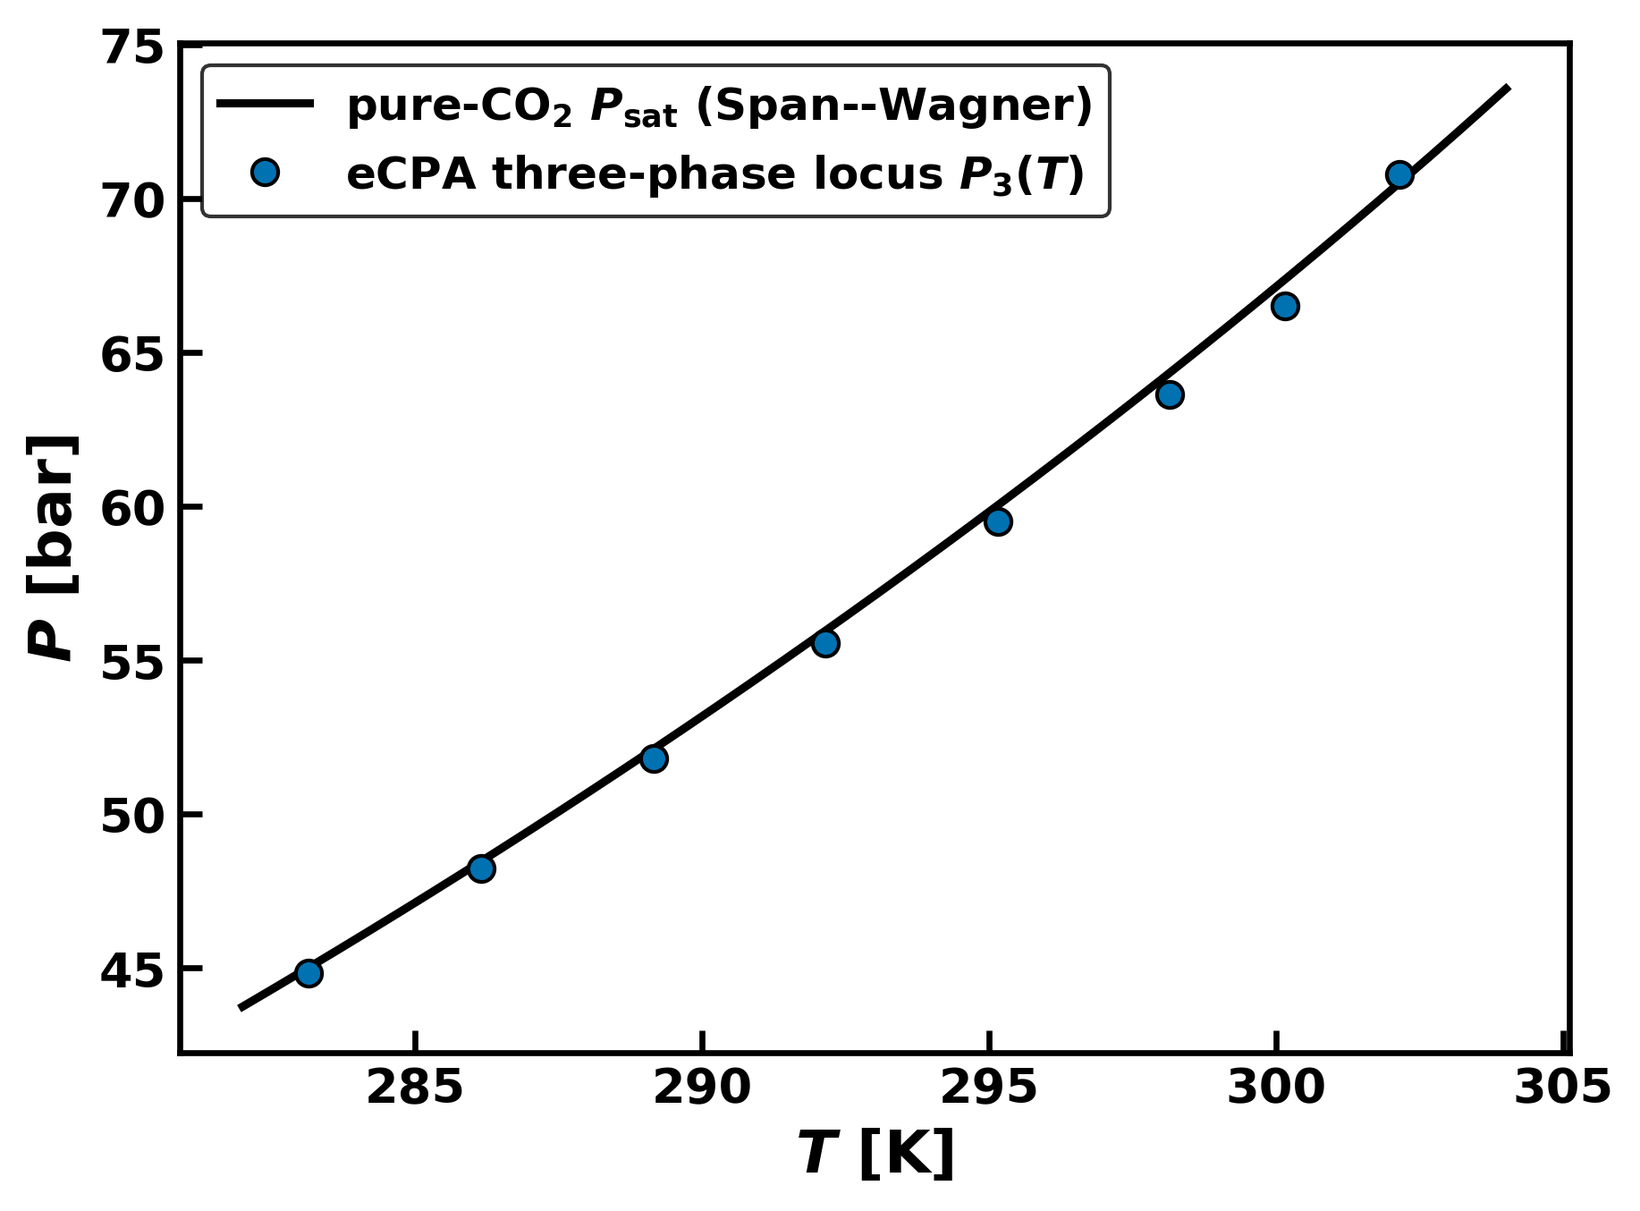

In [8]:
run('pilot_studies/three_phase_2026_08/vlle_locus.py', long=('--recompute',))
show('pilot_studies/three_phase_2026_08/fig_vlle_locus.png')


<a id="mfig6"></a>

**Figure 6.** Three-phase (vapor + aqueous + liquid $\mathrm{CO_{2}}$) locus of the salt-free $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binary predicted by ms-eCPA (symbols), compared with the pure-$\mathrm{CO_{2}}$ saturation curve of the Span–Wagner reference equation of state<sup>[52](#mref52)</sup> (line). The measured three-phase pressures<sup>[21](#mref21)</sup> track this curve within a few tenths of a bar. The corresponding loci in brine are predictions; no experimental three-phase data exist for gas–brine systems.

The deviation is confined to the dense non-aqueous root at low temperature. ms-eCPA does separate the two non-aqueous roots: at 288.71 K it puts 7.7 times less water in the liquid propane than in the vapor. But the measurements separate them by 11.7, so the shortfall is in the contrast between the roots, not in placing water in an alkane. The binary parameter that controls that contrast was calibrated against aqueous solubilities alone, over 288–428 K; no water content of a propane-rich phase entered the fit at any temperature. The $\mathrm{CO_{2}}$ system shows the mirror image. There the cross-association strength is fitted, and its quadratic form drives it negative below 289.8 K. The $\mathrm{CO_{2}}$-rich liquid at 288 K comes out too *dry* by factors of 6 to 16 while the vapor is within 14%. The two systems deviate on the same root with opposite signs. This points to a cross-interaction parameter that the calibration leaves undetermined for the dense root, not to a term missing from the free energy. A single temperature-dependent parameter cannot fix water’s partial fugacity in a dilute vapor and in a dense liquid of the same species at once. Accordingly the water content of a liquid-alkane phase should be read as semi-quantitative. That of the $\mathrm{CO_{2}}$-rich dense phase should be read as systematically low below 320 K (a mean of 0.30 of the measured enhancement factor above 100 bar, 0.86 between 320 and 350 K, unbiased above 350 K though the per-point scatter is still 23%). The aqueous-side compositions, on which the rest of this work rests, are unaffected.


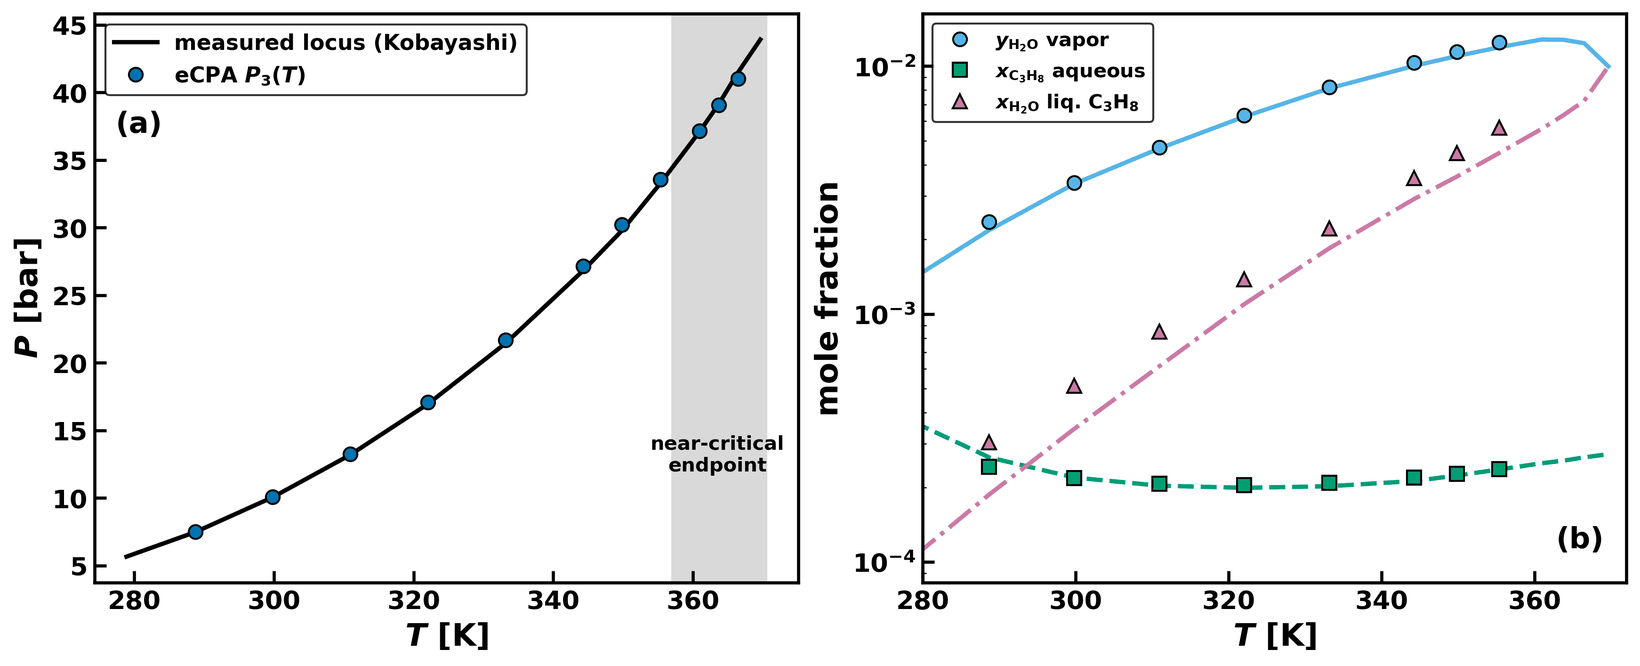

In [9]:
run('pilot_studies/c3_pilot_2026_08/c3_fig_final.py', long=())
show('c3_threephase_main.png')


<a id="mfig7"></a>

**Figure 7.** Three-phase (vapor + aqueous + liquid $\mathrm{C_{3}H_{8}}$) equilibria of the salt-free propane–water binary: ms-eCPA results (symbols) against the smoothed measurements of Kobayashi<sup>[45](#mref45),[46](#mref46)</sup> (lines). (a) The three-phase locus $P_3(T)$; the shaded band marks the approach to the measured three-phase critical endpoint (369.7 K, 43.9 bar). (b) Compositions along the locus: water content of the vapor, propane in the water-rich liquid, and water in the liquid-propane phase — the last is overpredicted at low temperature (see text).

\*\*Three-phase equilibria in brine are predictions.\*\* To our knowledge no experimental three-phase data exist for $\mathrm{CO_{2}}$–brine or hydrocarbon–brine systems. Both three-phase comparisons above — the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ locus against the reference saturation curve and the propane–water locus against measurement — are therefore salt-free binaries, and every three-phase result computed in brine is a prediction. Without data, we report what can be checked: that these results are internally consistent, and that the salt effect has the same direction and ranking as in the calibrated two-phase behavior. Ions are handled exactly as in the two-phase flash. With salt in the feed the aqueous $\mathrm{CO_{2}}$ in the three-phase states shows the expected salting-out, ordered as the two-phase data are. At 283.15 K and 56 bar, for $z = 0.50/0.03/0.47$ $\mathrm{H_{2}O}$/$\mathrm{CH_{4}}$/$\mathrm{CO_{2}}$, the aqueous $\mathrm{CO_{2}}$ mole fraction on a salt-free basis falls to 0.77, 0.53, 0.84 and 0.71 of its pure-water value in 1 and 3 mol kg$^{-1}$ $\mathrm{NaCl}$, 1 mol kg$^{-1}$ $\mathrm{KCl}$ and 1 mol kg$^{-1}$ $\mathrm{CaCl_{2}}$. Under the opt-in self-consistent closure the ion molalities would additionally be amplified by exactly the water lost to the two non-aqueous phases. The *salt effect* on three-phase behavior itself, however consistent with the calibrated salting-out and water-activity physics, has no measurement behind it.

We verified the robustness of the hierarchical procedure over the vapor–liquid–liquid window on a dedicated sweep of 2,625 states. The sweep covers $T = 283$–$303$ K, $P = 40$–$80$ bar (bracketing the locus), the binary feed plus four $\mathrm{CH_{4}}$-bearing feeds ($z_{\mathrm{CH_{4}}} = 0.01$–$0.10$), and five brine configurations up to 3 mol kg$^{-1}$ $\mathrm{NaCl}$ and including $\mathrm{KCl}$ and $\mathrm{CaCl_{2}}$. Every state converges. The isofugacity test that identifies the existing non-aqueous phase’s density root selects each of the two roots in a substantial share of the sweep states, in both the two- and the three-phase classifications, so it does not default to one branch. Of the sweep states, 324 are classified as three-phase, with cross-phase isofugacity residuals of $10^{-8}$ or better at every one. All 324 lie in the $\mathrm{CH_{4}}$-bearing feeds (45, 97, 117 and 65 states at $z_{\mathrm{CH_{4}}} = 0.01$, 0.03, 0.06 and 0.10); the binary feed returns two phases at all 525 of its states. This is not a phase-rule restriction, since with a salt present the system is ternary and three-phase states are divariant. It is the geometry described above: in the salt-free binary the three-phase states *are* the locus $P_3(T)$, and a scan over discrete pressures will generally miss a curve. Salt gives that set a finite width, but not one this calculation resolves. Refining the spacing twentyfold, to 0.1 bar, across $P_3 = 44.84$ bar at 283.15 K returns two phases at every pressure from 44.0 to 45.8 bar, salt-free and at 1 and 3 mol kg$^{-1}$ $\mathrm{NaCl}$ alike. Across the locus the computed split switches from a vapor–brine to a liquid-$\mathrm{CO_{2}}$–brine split. Consistently, three phases appear in every brine configuration in near-equal numbers (63 to 66 of the 324) and in the salt-free feeds as well, with the pressure limits of the three-phase region shifting between configurations by less than the 2 bar spacing. Salt has so little effect because the ions stay in the aqueous phase, so the two non-aqueous phases are nearly salt-free and salt mainly changes the aqueous composition. A second volatile component partitions into both non-aqueous phases and does open the locus into a finite interval that moves upward and broadens with its content. At 283.15 K, on its 2 bar grid, the sweep resolves three phases over 48–50 bar at $z_{\mathrm{CH_{4}}} = 0.01$, 50–60 bar at 0.03 and 54–72 bar at 0.06. At 0.10 the window extends from 64 bar to the top of the pressure grid at 80 bar, so its width there is a lower bound.


<a id="msec3_5"></a>

### 3.5 Efficiency and robustness of the multi-salt flash pipeline

We ran the framework over a dense $(T, P, \mathbf{z}, \mathbf{m}_i)$ grid of $151\,632$ states covering $T \in [283, 623]$ K, $P \in [1, 1000]$ bar, three feed compositions per family, and eight salt configurations. One configuration is salt-free and five are single salts. The other two are mixed brines, the four-ion recipe of Liu et al.<sup>[24](#mref24)</sup> and the five-ion recipe of Wang et al.<sup>[25](#mref25)</sup>, so $37\,908$ of the states, one quarter of the grid, are multi-ion. The sweep measures convergence and cost and makes no accuracy claim: the accuracy statements are those of Section 3.1. Table 4 collects the main numbers, and every one of the $151\,632$ states converges. The last state to resist convergence is a binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ point near the mutual critical envelope, where every feed-based $K$ initialization collapses to the trivial $K = 1$ attractor. It is resolved by a fallback that seeds $K_i$ from the ratio of the two converged stability-trial compositions. That count requires more than a residual test. A state is reported two-phase only if the flash also returns a phase fraction bounded away from zero and one, iteration caps return a failure flag rather than a silently accepted result, and the classification route is recorded per state. Every converged state also yields both phase densities at no additional cost, from the same inner state and the ion-specific Péneloux translation — unlike the activity-coefficient formulations of the Introduction, which import the brine density from a separate correlation.

A *single*-phase state is the dominant per-call cost — $\bar{t}_{\text{stab}} \approx
3.6$ s against $\approx 0.16$ s on two-phase points — because every one of the eight Michelsen trials must run to convergence before a feed is declared stable. In a warm-started simulator that test is routinely skipped whenever the previous step’s classification can be trusted. The per-step computing time in a simulator is therefore set by the flash, at $\bar{t}_{\text{flash}} \approx 0.8$ s and a mean of $6.1$ accelerated-SSI iterations plus one Newton polish (against $\approx 8.3$ iterations for pure SSI to the same answer). The three-phase extension adds little time. The second-stage tangent-plane test costs under a tenth of the first-stage test, and the subsequent three-phase flash is cheaper than the two-phase flash it follows, because the stability stage hands it both $K$-vectors as seeds.


<a id="mtab4"></a>

**Table 4.** Convergence and mean per-call wall time of the multi-salt flash pipeline on the $151\,632$-point dense sweep, split between the Michelsen stability test and the $K$-value flash. Iteration counts are aggregated over the two-phase points where the flash actually executes. Hardware, software and concurrency for these measurements are given in Section S14 of the Supporting Information.

In [10]:
import pandas as pd

d = pd.read_parquet("results_cache/sweep/merged.parquet")   # the shipped flash-grid results
conv = d[d.converged]
FAMILY = {"binary_CH4": "binary CH₄–H₂O", "binary_CO2": "binary CO₂–H₂O",
          "ternary": "ternary CH₄–CO₂–H₂O"}
two, one = conv[conv.phases == 2], conv[conv.phases == 1]
show_table(pd.DataFrame([
    ("Grid points evaluated", f"{len(d):,}"),
    ("Converged", f"{len(conv):,} ({100 * len(conv) / len(d):.0f} %)"),
    ("   classified single-phase", f"{len(one):,}"),
    ("   classified two-phase", f"{len(two):,}"),
    ("mean t_stab per single-phase state [ms]", f"{one.t_stab_ms.mean():.0f}"),
    ("mean t_stab per two-phase state [ms]", f"{two.t_stab_ms.mean():.0f}"),
    ("mean t_flash per two-phase state [ms]", f"{two.t_flash_ms.mean():.0f}"),
    ("mean N_SSI per two-phase state (SSI + NR polish)", f"{two.n_iter_ssi.mean():.1f}"),
    ("mean N_NR per two-phase state", f"{two.n_iter_newton_polish.mean():.2f}")],
    columns=["Metric", "Value"]))


Metric,Value
Grid points evaluated,"151,632"
Converged,"151,632 (100 %)"
classified single-phase,"69,845"
classified two-phase,"81,787"
mean t_stab per single-phase state [ms],3563
mean t_stab per two-phase state [ms],163
mean t_flash per two-phase state [ms],790
mean N_SSI per two-phase state (SSI + NR polish),6.1
mean N_NR per two-phase state,1.00


<a id="msec4"></a>

## 4 Conclusions

We have presented the phase-stability and flash framework that turns the ms-eCPA parameterization of Moortgat et al.<sup>[19](#mref19)</sup> into a practical thermodynamic engine for compositional reservoir simulation. We have also extended it to $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, $\mathrm{C_{3}H_{8}}$, and $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ gas mixtures and to three-phase (vapor + brine + gas-rich liquid) equilibria.

The principal contributions are:

- A two-phase stability test for ms-eCPA, with an eight-trial initial-guess scan, Jex-accelerated SSI, and a hard/soft threshold hierarchy following Jex et al.<sup>[6](#mref6)</sup> with values ($-0.005$ / $-0.1$) tuned to the ms-eCPA system. The influence of these values on the classification is quantified in the Supporting Information;

- A hierarchical $K$-value flash combining accelerated SSI on $\ln K_i$ with a Newton polish driving the equilibrium residual to $10^{-8}$. Each phase uses its own inner Newton solve, on $(Z, \varepsilon_r, \chi_{\mathrm{H_{2}O}})$ in the aqueous phase and on $(Z, \chi_{\mathrm{H_{2}O}})$ in the gas phase, with a complex-step Jacobian, free of the subtractive cancellation that limits a finite difference and needing no hand-derived eCPA derivatives. Ions are confined to the aqueous phase as a hard mass-balance constraint — immaterial for the aqueous-phase properties validated here, a limitation where the salt content of the non-aqueous phases is itself the quantity of interest;

- Validation of the framework against experiment: a global AARE of 6.55% for $\mathrm{CO_{2}}$ solubility across five single-salt brines between 283 and 473 K. A separate test against nineteen mixed-brine recipes (314 measurements, three to six ions), predicted with no mixed-brine tuning, gives an AARE of 6.7%. Scored over that set’s temperature and pressure window, the single-salt pool gives 6.3%. We also predict the $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ mutual solubilities and $\mathrm{CH_{4}}$/$\mathrm{CO_{2}}$ selectivity in brine with no parameter fitted to ternary data. Every converged state also delivers both phase densities on the same thermodynamic surface — what a simulator needs for gravity, compressibility and pressure, and what activity-coefficient formulations must import from separate correlations;

- Extension to new gases with few, quantified additional parameters. $\mathrm{N_{2}}$ salting-out follows from the $\mathrm{CH_{4}}$ ion energies calibrated in Part I, with no parameter fitted to nitrogen-in-brine data. The $\mathrm{H_{2}}$–$\mathrm{NaCl}$ parameterization of Coelho et al.<sup>[4](#mref4)</sup> keeps essentially its published accuracy. $\mathrm{C_{2}H_{6}}$ and $\mathrm{C_{3}H_{8}}$ each enter with one binary fit and two ion-energy scales calibrated against evaluated Setschenow data. For these two gases the $\mathrm{CH_{4}}$ transfer fails in opposite directions for $\mathrm{Na^{+}}$ and $\mathrm{K^{+}}$, by margins growing along the homologous series that delineate the transfer’s validity class. The supporting brine data for these four gases are narrower than for $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$: $\mathrm{NaCl}$ only for $\mathrm{N_{2}}$ and $\mathrm{H_{2}}$, and atmospheric-pressure $\mathrm{NaCl}$/$\mathrm{KCl}$ Setschenow constants for $\mathrm{C_{2}H_{6}}$ and $\mathrm{C_{3}H_{8}}$. Extending per-ion coverage to the divalent brines requires new gas-solubility measurements;

- Extension of the stability test and flash to three coexisting phases below the $\mathrm{CO_{2}}$ critical temperature. The two non-aqueous phases share one equation of state and differ only in the density root of the same inner solve, so the extension introduces no new unknowns beyond a second phase fraction and no new derivatives. The predicted three-phase locus of $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ tracks the reference $\mathrm{CO_{2}}$ saturation curve within 0.2–1.1 bar over 283–302 K. The measured propane–water three-phase pressure is matched to within 1.5 % from 289 to 366 K. Along the locus, propane in the water-rich phase is reproduced to 2.2 % and water in the vapor to 4.3 % on average, while water in the liquid propane is overpredicted by 21–63 %. $\mathrm{CH_{4}}$-bearing feeds open a finite three-phase region computed with the same algorithm. Both measured comparisons are salt-free binaries, and the three-phase results in brine — including the finite three-phase region under salt — are predictions, since no experimental three-phase data exist for gas–brine systems;

- A dense sweep over the full calibration window ($151\,632$ states) that converges at every point and separates the fast $K$-value flash from the slower stability test, which a warm-started reservoir simulator can skip.

We will couple the framework to the compiled advanced compositional reservoir simulator of Moortgat<sup>[2](#mref2)</sup>. Five open issues warrant further attention. The first is brine-solubility measurements that would extend $\mathrm{N_{2}}$ and $\mathrm{H_{2}}$ to the remaining ions of the suite ($\mathrm{K^{+}}$, $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$, $\mathrm{SO_{4}^{2-}}$). $\mathrm{N_{2}}$ already has transferred energies for all six ions but is demonstrated only in $\mathrm{NaCl}$ brines, whereas for $\mathrm{H_{2}}$ no energies for those four ions exist (Section 3.2). The second is an analogous composition-level validation of the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ three-phase equilibria against the sparse measured water contents of the $\mathrm{CO_{2}}$-rich phases. The third is an improved description of the water content of liquid-alkane phases, which the propane validation shows to be overpredicted by 21–63 %, because the water–propane binary parameter was fitted to aqueous-side data only (Section 3.4). The fourth, relaxing the strict confinement of ions to the aqueous phase, is an exploration of the small but nonzero salt content of the $\mathrm{CO_{2}}$-rich liquid phase, which the water in that phase can transport. As the Born estimate of Section S5 shows, that content cannot reach the non-aqueous phase as free ions. The route is neutral ion pairs and hydrated clusters, so the extension is one of the component set and its association physics rather than of the partitioning rule alone. Finally, as noted in the parameterization study, the literature gas–brine experiments back-calculate aqueous compositions on a prepared-molality basis. At reservoir scale, where the gas-phase water content is no longer negligible and the in-place gas-to-brine ratio is set by the simulation rather than by a benchtop cell, the self-consistent equilibrium-molality closure implemented in this framework should be used instead. In work in preparation, we compare ms-eCPA with other widely used models in accuracy, computational efficiency and robustness, across the parameter space covered by GasBrineBench.


## Supporting Information

Nomenclature (S1); complete parameter set of the ms-eCPA model, with the provenance and role of every parameter (S2); algorithmic listing of the eight-trial tangent-plane stability test (S3); algorithmic listing of the multi-salt $K$-value flash with Newton polish (S4); energetic bound on ion partitioning into the non-aqueous phases (S5); algorithmic listing of the three-phase stability test and flash (S6); the tangent-plane landscape of the stability test (S7); per-salt parity resolution and experimental literature variance analysis (S8); dense-sweep phase-equilibrium predictions covering phase boundary and partition, gas-phase water content, aqueous solubility and density, equilibrium-state observables, and the salting-out signal by ionic strength (S9); Setschenow calibrations of the ethane and propane gas–ion energy scales (S10); ethane and propane in brine, with the binary fits, the fitted salting-out scales and the brine comparisons (S11); $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ ternary statistics and the sensitivity to $k_{hc}$ (S12); $\mathrm{CH_{4}}$/$\mathrm{CO_{2}}$ selectivity in single-salt brines (S13); and per-salt performance and iteration-count breakdowns of the dense sweep, and sensitivity of the phase classification to the stability-test thresholds (S14) (PDF)


## Author Contributions

**Joachim Moortgat:** Conceptualization, Data curation, Formal analysis, Investigation, Methodology, Project administration, Resources, Software, Validation, Visualization, Writing – original draft. **Felipe Mour ao Coelho:** Data curation, Writing – original draft. **Abbas Firoozabadi:** Conceptualization, Funding acquisition, Writing – original draft.


## Data and Code Availability

The experimental gas–brine data used to validate this work are published as GasBrineBench, an open database that records, for each row, its literature source, a quality code, and whether it entered a fit or serves only as a test. The database includes solubility data for all six gases treated here and the $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ ternary. It is hosted at <https://github.com/jmoortgat/GasBrineBench> with versioned archives on Zenodo. We use release v1.1.1 (11,537 rows from 111 sources), <https://doi.org/10.5281/zenodo.22898153>; the concept DOI 10.5281/zenodo.22834145 resolves to the latest release. We will publish the implementation of the stability test, the two- and three-phase flash algorithms, and the parameters for the additional gases, together with the scripts that reproduce every figure and table, with the code of the first paper in this series, <https://github.com/jmoortgat/CPA_and_eCPA_flash>, so that all three papers draw on a single code base.


## Acknowledgments

The member companies of the Reservoir Engineering Research Institute supported the work of Abbas Firoozabadi. Felipe Mour ao Coelho acknowledges the S ao Paulo Research Foundation (FAPESP, grants #2018/02713-8, #2020/13300-6, and #2021/13068-9), the Centro Nacional de Processamento de Alto Desempenho em S ao Paulo (CENAPAD-SP), the John David Rogers Computing Center (CCJDR) at the Institute of Physics “Gleb Wataghin” of the University of Campinas, the Coordenaç ao de Aperfeiçoamento de Pessoal de Nível Superior (CAPES) Brasil, and the Conselho Nacional de Desenvolvimento Científico e Tecnológico (CNPq) Brasil for their support. No specific grant from any public, commercial, or not-for-profit funding agency supported J. Moortgat’s contribution. The authors used Claude Code (Anthropic) in preparing this work: to edit the manuscript for grammar and concision, to format it in LaTeX, and to help optimize, test, format and document the code. All output of these tools was reviewed and revised by the authors, who are fully responsible for the article’s content.

\@ifundefined


## TOC Graphic

![TOC graphic](images/ms_ecpa_flash_toc.png)

<a id="mrefs"></a>

## References

<a id="mref1"></a>1. Moortgat, J.; Li, Z.; Firoozabadi, A. Three-Phase Compositional Modeling of $\mathrm{CO_{2}}$ Injection by Higher-Order Finite Element Methods with CPA Equation of State for Aqueous Phase. *Water Resources Research* **2012**, *48*, W12511

<a id="mref2"></a>2. Moortgat, J. Reservoir Simulation with the Cubic Plus (Cross-) Association Equation of State for Water, $\mathrm{CO_{2}}$, Hydrocarbons, and Tracers. *Advances in Water Resources* **2018**, *114*, 29–44

<a id="mref3"></a>3. Soltanian, M. R.; Amooie, M. A.; Cole, D. R.; Graham, D. E.; Hosseini, S. A.; Hovorka, S.; Pfiffner, S. M.; Phelps, T. J.; Moortgat, J. Simulating the Cranfield Geological Carbon Sequestration Project with High-Resolution Static Models and an Accurate Equation of State. *International Journal of Greenhouse Gas Control* **2016**, *54*, 282–296

<a id="mref4"></a>4. Coelho, F. M. a.; Mercier Franco, L. F.; Firoozabadi, A. Modeling of phase equilibria of $\mathrm{H_{2}}$ and $\mathrm{H_{2}}$–$\mathrm{CO_{2}}$ in $\mathrm{NaCl}$ brine mixtures from e<span class="smallcaps">CPA</span> equation of state. *International Journal of Hydrogen Energy* **2025**, *178*, 151361

<a id="mref5"></a>5. Michelsen, M. L. The Isothermal Flash Problem. Part I: Stability. *Fluid Phase Equilib.* **1982**, *9*, 1–19

<a id="mref6"></a>6. Jex, M.; Mikyška, J.; Firoozabadi, A. Fast and Robust Multiphase Equilibrium Calculation at High Pressures and Temperatures Using Accelerated Successive Substitution and New Multiple Initial Guesses for Stability Analysis. *SPE J.* **2024**, *29*, 3643–3658

<a id="mref7"></a>7. Maribo-Mogensen, B.; Thomsen, K.; Kontogeorgis, G. M. An electrolyte CPA equation of state for mixed solvent electrolytes. *AIChE J.* **2015**, *61*, 2933–2950

<a id="mref8"></a>8. Kontogeorgis, G. M.; Schlaikjer, A.; Olsen, M. D.; Maribo-Mogensen, B.; Thomsen, K.; Liang, X.; Bell, I. H. A review of electrolyte equations of state with emphasis on those based on cubic and cubic-plus-association (CPA) models. *International Journal of Thermophysics* **2022**, *43*, 54

<a id="mref9"></a>9. Maribo-Mogensen, B.; Kontogeorgis, G. M.; Thomsen, K. Modeling of Dielectric Properties of Aqueous Salt Solutions with an Equation of State. *J. Phys. Chem. B* **2013**, *117*, 10523–10533

<a id="mref10"></a>10. Moortgat, J.; Coelho, F. M.; Firoozabadi, A. Fast and Robust Phase Equilibrium Computations for $\mathrm{CO_{2}}$ + $\mathrm{H_{2}O}$ + $\mathrm{NaCl}$ Mixtures Using the Electrolyte Cubic-Plus-Association Equation of State. *Industrial & Engineering Chemistry Research* **2026**, *65*, 20081–20103

<a id="mref11"></a>11. Duan, Z.; Sun, R. An Improved Model Calculating $\mathrm{CO_{2}}$ Solubility in Pure Water and Aqueous NaCl Solutions from 273 to 533 K and from 0 to 2000 bar. *Chemical Geology* **2003**, *193*, 257–271

<a id="mref12"></a>12. Duan, Z.; Sun, R.; Zhu, C.; Chou, I.-M. An Improved Model for the Calculation of $\mathrm{CO_{2}}$ Solubility in Aqueous Solutions Containing $\mathrm{Na^{+}}$, $\mathrm{K^{+}}$, $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$, $\mathrm{Cl^{-}}$, and $\mathrm{SO_{4}^{2-}}$. *Marine Chemistry* **2006**, *98*, 131–139

<a id="mref13"></a>13. Spycher, N.; Pruess, K. A Phase-Partitioning Model for CO2–Brine Mixtures at Elevated Temperatures and Pressures: Application to CO2-Enhanced Geothermal Systems. *Transport in Porous Media* **2010**, *82*, 173–196

<a id="mref14"></a>14. Springer, R. D.; Wang, Z.; Anderko, A.; Wang, P.; Felmy, A. R. A thermodynamic model for predicting mineral reactivity in supercritical carbon dioxide: I. Phase behavior of carbon dioxide–water–chloride salt systems across the $\mathrm{H_{2}O}$-rich to the $\mathrm{CO_{2}}$-rich regions. *Chem. Geo.* **2012**, *322-323*, 151–171

<a id="mref15"></a>15. Søreide, I.; Whitson, C. H. Peng–Robinson Predictions for Hydrocarbons, $\mathrm{CO_{2}}$, $\mathrm{N_{2}}$, and $\mathrm{H_{2}S}$ with Pure Water and NaCl Brine. *Fluid Phase Equilibria* **1992**, *77*, 217–240

<a id="mref16"></a>16. Held, C.; Cameretti, L. F.; Sadowski, G. Modeling aqueous electrolyte solutions: Part 1. Fully dissociated electrolytes. *Fluid Phase Equilibria* **2008**, *270*, 87–96

<a id="mref17"></a>17. Sun, L.; Kontogeorgis, G. M.; von Solms, N.; Liang, X. Modeling of Gas Solubility Using the Electrolyte Cubic Plus Association Equation of State. *Ind. Eng. Chem. Res.* **2019**, *58*, 17555–17567

<a id="mref18"></a>18. Olsen, M. D.; Kontogeorgis, G. M.; Liang, X.; von Solms, N. Investigation of the performance of e-CPA for a wide range of properties for aqueous NaCl solutions. *Fluid Phase Equilibr.* **2021**, *548*, 113167

<a id="mref19"></a>19. Moortgat, J.; Coelho, F. M.; Firoozabadi, A. Phase Equilibria of $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ in Multisalt Brines: Parametrization and Validation of an Ion-Specific Electrolyte Cubic-Plus-Association Equation of State. *Energy Fuels* **2026**, *40*, 23472–23484. [DOI: 10.1021/acs.energyfuels.6c04568](https://pubs.acs.org/enfuem/article/40/42/23472/5449187/Phase-Equilibria-of-CO2-and-CH4-in-Multisalt)

<a id="mref20"></a>20. Coelho, F. M.; Mercier Franco, L. F.; Firoozabadi, A. Phase Equilibria of $\mathrm{CO_{2}}$–Water and $\mathrm{CO_{2}}$–Brine at High Temperatures: From Monte Carlo Simulations to the Equation of State. *Industrial & Engineering Chemistry Research* **2025**, *64*, 8492–8505

<a id="mref21"></a>21. Wendland, M.; Hasse, H.; Maurer, G. Experimental Pressure–Temperature Data on Three- and Four-Phase Equilibria of Fluid, Hydrate, and Ice Phases in the System Carbon Dioxide–Water. *J. Chem. Eng. Data* **1999**, *44*, 901–906

<a id="mref22"></a>22. Michelsen, M. L. The Isothermal Flash Problem. Part II: Phase-Split Calculation. *Fluid Phase Equilib.* **1982**, *9*, 21–40

<a id="mref23"></a>23. Mousavi, R.; Chapoy, A.; Burgass, R. $\mathrm{CO_{2}}$ solubility in aqueous solution of salts: Experimental study and thermodynamic modelling. *Greenhouse Gases: Science and Technology* **2024**, *14*, 791–828

<a id="mref24"></a>24. Liu, Y.; Hou, M.; Yang, G.; Han, B. Solubility of $\mathrm{CO_{2}}$ in aqueous solutions of NaCl, KCl, $\mathrm{CaCl_{2}}$ and their mixed salts at different temperatures and pressures. *J. Supercrit. Fluid.* **2011**, *56*, 125–129

<a id="mref25"></a>25. Wang, L.; Shen, Z.; Hu, L.; Yu, Q. Modeling and measurement of $\mathrm{CO_{2}}$ solubility in salty aqueous solutions and application in the Erdos Basin. *Fluid Phase Equilibria* **2014**, *377*, 45–55

<a id="mref26"></a>26. El-Maghraby, R.; Pentland, C.; Iglauer, S.; Blunt, M. A fast method to equilibrate carbon dioxide with brine at high pressure and elevated temperature including solubility measurements. *The Journal of Supercritical Fluids* **2012**, *62*, 55–59

<a id="mref27"></a>27. Li, Z.; Dong, M.; Li, S.; Dai, L. Densities and Solubilities for Binary Systems of Carbon Dioxide + Water and Carbon Dioxide + Brine at 59 °C and Pressures to 29 MPa. *Journal of Chemical & Engineering Data* **2004**, *49*, 1026–1031

<a id="mref28"></a>28. Tong, D.; Trusler, J. P. M.; Vega-Maza, D. Solubility of CO2 in Aqueous Solutions of $\mathrm{CaCl_{2}}$ or $\mathrm{MgCl_{2}}$ and in a Synthetic Formation Brine at Temperatures up to 423 K and Pressures up to 40 MPa. *Journal of Chemical & Engineering Data* **2013**, *58*, 2116–2124

<a id="mref29"></a>29. Zhao, H.; Dilmore, R.; Allen, D. E.; Hedges, S. W.; Soong, Y.; Lvov, S. N. Measurement and Modeling of $\mathrm{CO_{2}}$ Solubility in Natural and Synthetic Formation Brines for $\mathrm{CO_{2}}$ Sequestration. *Environmental Science & Technology* **2015**, *49*, 1972–1980

<a id="mref30"></a>30. Portier, S.; Rochelle, C. Modelling $\mathrm{CO_{2}}$ solubility in pure water and NaCl-type waters from 0 to 300 °C and from 1 to 300 bar: Application to the Utsira Formation at Sleipner. *Chemical Geology* **2005**, *217*, 187–199, Geochemical Aspects of CO2 sequestering

<a id="mref31"></a>31. Poulain, M.; Messabeb, H.; Lach, A.; Contamine, F.; Cézac, P.; Serin, J.-P.; Dupin, J.-C.; Martinez, H. Experimental Measurements of Carbon Dioxide Solubility in Na–Ca–K–Cl Solutions at High Temperatures and Pressures up to 20 MPa. *Journal of Chemical & Engineering Data* **2019**, *64*, 2497–2503

<a id="mref32"></a>32. O’Sullivan, T. D.; Smith, N. O. Solubility and partial molar volume of nitrogen and methane in water and in aqueous sodium chloride from 50 to 125 C and 100 to 600 atm. *The Journal of Physical Chemistry* **1970**, *74*, 1460–1466

<a id="mref33"></a>33. Chabab, S.; Théveneau, P.; Coquelet, C.; Corvisier, J.; Paricaud, P. Measurements and predictive models of high-pressure $\mathrm{H_{2}}$ solubility in brine ($\mathrm{H_{2}O}$+NaCl) for underground hydrogen storage application. *International Journal of Hydrogen Energy* **2020**, *45*, 32206–32220

<a id="mref34"></a>34. Chabab, S.; Kerkache, H.; Bouchkira, I.; Poulain, M.; Baudouin, O.; Édouard Moine; Ducousso, M.; Hoang, H.; Galliéro, G.; Cézac, P. Solubility of $\mathrm{H_{2}}$ in water and NaCl brine under subsurface storage conditions: Measurements and thermodynamic modeling. *International Journal of Hydrogen Energy* **2024**, *50*, 648–658

<a id="mref35"></a>35. Torín-Ollarves, G. A.; Trusler, J. M. Solubility of hydrogen in sodium chloride brine at high pressures. *Fluid Phase Equilibria* **2021**, *539*, 113025

<a id="mref36"></a>36. Soave, G. Equilibrium constants from a modified Redlich-Kwong equation of state. *Chem. Eng. Sci.* **1972**, *27*, 1197–1203

<a id="mref37"></a>37. Morrison, T. J.; Billett, F. The Salting-out of Non-electrolytes. Part II. The Effect of Variation in Non-electrolyte. *J. Chem. Soc.* **1952**, 3819–3822

<a id="mref38"></a>38. Yano, T.; Suetaka, T.; Umehara, T.; Horiuchi, A. Salt Effects on the Solubility of Propane in Aqueous Electrolyte Solutions. *Kagaku Kogaku* **1974**, *38*, 320, Data as compiled and evaluated in the IUPAC Solubility Data Series, Vol. 24

<a id="mref39"></a>39. Culberson, O. L.; Horn, A. B.; McKetta, J. J. Phase Equilibria in Hydrocarbon-Water Systems: The Solubility of Ethane in Water at Pressures to 1200 Pounds per Square Inch. *Trans. AIME (J. Pet. Technol.)* **1950**, *189*, 1–6

<a id="mref40"></a>40. Culberson, O. L.; McKetta, J. J. Phase Equilibria in Hydrocarbon-Water Systems II: The Solubility of Ethane in Water at Pressures to 10,000 psi. *Trans. AIME (J. Pet. Technol.)* **1950**, *189*, 319–322

<a id="mref41"></a>41. Hayduk, W., Ed. *Ethane*; IUPAC Solubility Data Series; Pergamon Press: Oxford, 1982; Vol. 9

<a id="mref42"></a>42. Mohammadi, A. H.; Chapoy, A.; Tohidi, B.; Richon, D. Measurements and Thermodynamic Modeling of Vapor-Liquid Equilibria in Ethane-Water Systems from 274.26 to 343.08 K. *Ind. Eng. Chem. Res.* **2004**, *43*, 5418–5424

<a id="mref43"></a>43. Mao, S.; Zhang, Z.; Hu, J.; Sun, R.; Duan, Z. An Accurate Model for Calculating $\mathrm{C_{2}H_{6}}$ Solubility in Pure Water and Aqueous NaCl Solutions. *Fluid Phase Equilibria* **2005**, *238*, 77–86

<a id="mref44"></a>44. Ben-Naim, A.; Yaacobi, M. Effects of Solutes on the Strength of Hydrophobic Interaction and Its Temperature Dependence. *J. Phys. Chem.* **1974**, *78*, 170–175

<a id="mref45"></a>45. Kobayashi, R. Vapor-Liquid Equilibria in Binary Hydrocarbon-Water Systems. Ph.D. thesis, University of Michigan, 1951; Complete data tables behind \[Kobayashi and Katz, 1953\]

<a id="mref46"></a>46. Kobayashi, R.; Katz, D. L. Vapor-Liquid Equilibria for Binary Hydrocarbon-Water Systems. *Ind. Eng. Chem.* **1953**, *45*, 440–446

<a id="mref47"></a>47. Chapoy, A.; Mokraoui, S.; Valtz, A.; Richon, D.; Mohammadi, A. H.; Tohidi, B. Solubility Measurement and Modeling for the System Propane–Water from 277.62 to 368.16 K. *Fluid Phase Equilib.* **2004**, *226*, 213–220

<a id="mref48"></a>48. Hayduk, W., Ed. *Propane, Butane and 2-Methylpropane*; IUPAC Solubility Data Series; Pergamon Press: Oxford, 1986; Vol. 24

<a id="mref49"></a>49. Dhima, A.; de Hemptinne, J.-C.; Jose, J. Solubility of Hydrocarbons and $\mathrm{CO_{2}}$ Mixtures in Water under High Pressure. *Ind. Eng. Chem. Res.* **1999**, *38*, 3144–3161

<a id="mref50"></a>50. Qin, J.; Rosenbauer, R. J.; Duan, Z. Experimental Measurements of Vapor–Liquid Equilibria of the $\mathrm{H_{2}O}$ + $\mathrm{CO_{2}}$ + $\mathrm{CH_{4}}$ Ternary System. *Journal of Chemical & Engineering Data* **2008**, *53*, 1246–1249

<a id="mref51"></a>51. Al Ghafri, S. Z. S.; Forte, E.; Maitland, G. C.; Rodriguez-Henríquez, J. J.; Trusler, J. P. M. Experimental and Modeling Study of the Phase Behavior of (Methane + $\mathrm{CO_{2}}$ + Water) Mixtures. *The Journal of Physical Chemistry B* **2014**, *118*, 14461–14478

<a id="mref52"></a>52. Span, R.; Wagner, W. A New Equation of State for Carbon Dioxide Covering the Fluid Region from the Triple-Point Temperature to 1100 K at Pressures up to 800 MPa. *J. Phys. Chem. Ref. Data* **1996**, *25*, 1509–1596

<a id="mref53"></a>53. Al Ghafri, S.; Maitland, G. C.; Trusler, J. P. M. Densities of Aqueous $\mathrm{MgCl_{2}}$(aq), $\mathrm{CaCl_{2}}$(aq), KI(aq), NaCl(aq), KCl(aq), $\mathrm{AlCl_{3}}$(aq), and (0.964 NaCl + 0.136 KCl)(aq) at Temperatures Between (283 and 472) K, Pressures up to 68.5 MPa, and Molalities up to 6 mol kg$^{-1}$. *J. Chem. Eng. Data* **2012**, *57*, 1288–1304

<a id="mref54"></a>54. Al Ghafri, S. Z.; Maitland, G. C.; Trusler, J. P. M. Densities of $\mathrm{SrCl_{2}}$(aq), $\mathrm{Na_{2}SO_{4}}$(aq), $\mathrm{NaHCO_{3}}$(aq), and Two Synthetic Reservoir Brines at Temperatures between (298 and 473) K, Pressures up to 68.5 MPa, and Molalities up to 3 mol·kg–1. *Journal of Chemical & Engineering Data* **2013**, *58*, 402–412

<a id="stop"></a>

# Supporting Information

## Summary

Here we provide supplementary material for the main text, ordered by topic. Section S1 lists the nomenclature, and Section S2 reproduces the complete parameter set together with the provenance and role of every parameter; the model-level material — the Helmholtz-term derivations, the permittivity closure, the calibration data inventory, and the ion-parameter provenance — is provided in the Supporting Information of the parameterization study<sup>[1](#sref1)</sup>. Sections S3 and S4 give algorithmic listings of the multi-salt Michelsen tangent-plane stability test and of the multi-salt $K$-value flash with Newton polish, Section S5 bounds the partitioning of ions into the non-aqueous phases, and Section S6 lists the three-phase (vapor + brine + gas-rich liquid) stability test and flash. Section S7 shows the tangent-plane landscape of the stability test; Section S8 resolves the main-paper parity comparison per salt and against the inter-author scatter of the experimental literature, and Section S9 catalogs the multi-salt phase-equilibrium predictions on a dense $(T, P, \mathbf{z}, \mathbf{m}_i)$ grid. Section S10 shows the Setschenow calibrations behind the ethane and propane gas–ion energy scales, and Section S11 gives the ethane and propane binary fits and brine comparisons. Section S12 resolves the $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ ternary statistics and their sensitivity to $k_{hc}$, and Section S13 the $\mathrm{CH_{4}}$/$\mathrm{CO_{2}}$ selectivity in single-salt brines. Section S14 reports the convergence and per-call cost profile of the flash pipeline on the dense grid, and gives the sensitivity of the phase classification to the TPD thresholds (Section S14.2).


<a id="ssecS1"></a>

## S1 Nomenclature

The nomenclature below covers the symbols used in this paper. The model-level nomenclature — the full set of equation-of-state, association, and electrostatic parameters — is given in the Supporting Information of the parameterization study<sup>[1](#sref1)</sup> and reproduced in Section S2.


<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Symbol</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"> Description</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Units</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Symbol</td>
<td style="padding:2px 8px;border:none;text-align:left"> Description</td>
<td style="padding:2px 8px;border:none;text-align:left">Units</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sup>R</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Residual molar Helmholtz energy; the extensive form <span class="math inline"><em>n</em><em>A</em><sup>R</sup></span> is differentiated in Eq. (2) of the main text</td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sup>phys</sup></span>, <span class="math inline"><em>A</em><sup>assoc</sup></span>, <span class="math inline"><em>A</em><sup>DH</sup></span>, <span class="math inline"><em>A</em><sup>Born</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> SRK, Wertheim association, Debye–Hückel, and Born contributions to <span class="math inline"><em>A</em><sup>R</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>P</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Pressure</td>
<td style="padding:2px 8px;border:none;text-align:left">bar</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>T</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Temperature</td>
<td style="padding:2px 8px;border:none;text-align:left">K</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>T</em><sub><em>c</em>, <em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Critical temperature of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">K</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>V</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Total volume</td>
<td style="padding:2px 8px;border:none;text-align:left">cm<span class="math inline"><sup>3</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>n</em></span>, <span class="math inline"><em>n</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Total moles, moles of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">mol</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>v</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Molar volume</td>
<td style="padding:2px 8px;border:none;text-align:left">cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Z</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Compressibility factor, <span class="math inline"><em>Z</em> = <em>P</em><em>v</em>/(<em>R</em><em>T</em>)</span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>ϕ̂</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Fugacity coefficient of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>x</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Aqueous-phase mole fraction of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>y</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Gas-phase mole fraction of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><strong>z</strong></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Feed (overall) composition</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>z</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Charge number of ion <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>m</em><sub><em>s</em></sub></span>, <span class="math inline"><em>m</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Salt (ion) feed molality</td>
<td style="padding:2px 8px;border:none;text-align:left">mol kg<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>m</em><sub><em>i</em>, aq</sub><sup>*</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Equilibrium aqueous molality of ion <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">mol kg<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>I</em><sub><em>c</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Ionic strength, <span class="math inline">$\tfrac{1}{2}\sum_i m_i z_i^2$</span></td>
<td style="padding:2px 8px;border:none;text-align:left">mol kg<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>N</em><sub><em>p</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Number of experimental data points</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>ε</em><sub><em>r</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Static relative permittivity of the mixture</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>χ</em><sub><em>A</em><sub><em>i</em></sub></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Wertheim non-bonded (monomer) fraction of association site <span class="math inline"><em>A</em></span> on species <span class="math inline"><em>i</em></span>; also written <span class="math inline"><em>χ</em><sub>H<sub>2</sub>O</sub></span> for the water site</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub><em>i</em><em>j</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Binary interaction parameter between species <span class="math inline"><em>i</em></span> and <span class="math inline"><em>j</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Δ</em><em>U</em><sub><em>g</em><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Gas–ion NRTL interaction energy</td>
<td style="padding:2px 8px;border:none;text-align:left">J mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">TPD</span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Tangent-plane distance</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><strong>W</strong></span>, <span class="math inline"><strong>w</strong></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Trial-phase mole numbers in the stability test (unnormalized) and the corresponding mole fractions <span class="math inline"><strong>w</strong> = <strong>W</strong>/∑<sub><em>i</em></sub><em>W</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>t</em><em>m</em><sup>⋆</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Modified tangent-plane distance at a stationary point, <span class="math inline">1 − ∑<sub><em>i</em></sub><em>W</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>d</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> TPD reference term, <span class="math inline">ln <em>z</em><sub><em>i</em></sub> + ln <em>ϕ̂</em><sub><em>i</em></sub><sup>gas</sup>(<strong>z</strong>)</span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>g</em><sub><em>i</em></sub></span>, <span class="math inline"><strong>g</strong></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> TPD gradient <span class="math inline">ln <em>W</em><sub><em>i</em></sub> + ln <em>ϕ̂</em><sub><em>i</em></sub>(<strong>w</strong>) − <em>d</em><sub><em>i</em></sub></span> and the vector of its components</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>K</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Equilibrium ratio of species <span class="math inline"><em>i</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>K</em><sub><em>i</em></sub><sup><em>g</em></sup></span>, <span class="math inline"><em>K</em><sub><em>i</em></sub><sup><em>l</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Equilibrium ratios of the vapor and <span class="math inline">CO<sub>2</sub></span>-rich-liquid phases relative to the aqueous phase (three-phase flash)</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>β</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Vapor mole fraction (partitioning-component basis)</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>β</em><sub><em>g</em></sub></span>, <span class="math inline"><em>β</em><sub><em>l</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Vapor and <span class="math inline">CO<sub>2</sub></span>-rich-liquid phase fractions (three-phase flash); aqueous fraction <span class="math inline">1 − <em>β</em><sub><em>g</em></sub> − <em>β</em><sub><em>l</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>D</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Three-phase Rachford–Rice denominator, <span class="math inline">1 + <em>β</em><sub><em>g</em></sub>(<em>K</em><sub><em>i</em></sub><sup><em>g</em></sup> − 1) + <em>β</em><sub><em>l</em></sub>(<em>K</em><sub><em>i</em></sub><sup><em>l</em></sup> − 1)</span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>R</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Flash residual on <span class="math inline">ln <em>K</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub><em>S</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Setschenow (salting-out) constant, <span class="math inline">log<sub>10</sub>(<em>S</em><sub>0</sub>/<em>S</em>)/<em>c</em><sub>salt</sub></span> (molarity basis; <span class="math inline">C<sub>2</sub>H<sub>6</sub></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left">dm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub>smm</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> Setschenow constant on the gas-molality / salt-molality basis, <span class="math inline">log<sub>10</sub>(<em>m</em><sub><em>g</em>, 0</sub>/<em>m</em><sub><em>g</em></sub>)/<em>m</em><sub>salt</sub></span> (<span class="math inline">C<sub>3</sub>H<sub>8</sub></span>; IUPAC convention)</td>
<td style="padding:2px 8px;border:none;text-align:left">kg mol<span class="math inline"><sup>−1</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>α</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">CO<sub>2</sub></span>/<span class="math inline">CH<sub>4</sub></span> gas–aqueous selectivity, <span class="math inline">(<em>y</em><sub>CO<sub>2</sub></sub>/<em>x</em><sub>CO<sub>2</sub></sub><sup><em>a</em><em>q</em></sup>)/(<em>y</em><sub>CH<sub>4</sub></sub>/<em>x</em><sub>CH<sub>4</sub></sub><sup><em>a</em><em>q</em></sup>)</span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
</tbody>
</table>


<a id="ssecS2"></a>

## S2 Complete ms-eCPA parameter set

<a id="ssecS2_1"></a>

### S2.1 Provenance and role of every parameter

Table S1 records, for every parameter group entering the results of the main text, where it was fitted, what it was fitted to, and therefore which role each comparison in Section 3 of the main text plays.


<a id="stabS1"></a>

**Table S1.** Provenance and role of every parameter entering the results. *Calibration residual*: the comparison is made against data that entered the fit of that parameter; *prediction*: no parameter was fitted to the data shown; *untested*: no data exist. Deviations are AARE on the aqueous gas mole fraction unless another basis is named.

<table style="width:90%;">

<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Parameter</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"> Fitted in</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"> Fitted to</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"> Role of the results reported here</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><p>Parameter</p></td>
<td style="padding:2px 8px;border:none;text-align:left"> Fitted in</td>
<td style="padding:2px 8px;border:none;text-align:left"> Fitted to</td>
<td style="padding:2px 8px;border:none;text-align:left"> Role of the results reported here</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><p></p></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><p>Ion size, Born radius, water–ion energy, polarizability</p></td>
<td style="padding:2px 8px;border:none;text-align:left"> adopted through<sup><a href="#sref1">1</a></sup>, with two corrections made there</td>
<td style="padding:2px 8px;border:none;text-align:left"> a 55-salt optimization, Born radii adjusted to hydration enthalpies</td>
<td style="padding:2px 8px;border:none;text-align:left"> fixed; not refitted here</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Ion Péneloux translations</td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref1">1</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"> brine densities, five salts</td>
<td style="padding:2px 8px;border:none;text-align:left"> fixed; not refitted here</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CO<sub>2</sub></span>–<span class="math inline">H<sub>2</sub>O</span> binary and cross-association</td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref26">26</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"> salt-free <span class="math inline">CO<sub>2</sub></span>–<span class="math inline">H<sub>2</sub>O</span> VLE</td>
<td style="padding:2px 8px;border:none;text-align:left"> adopted; not re-validated here</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CH<sub>4</sub></span>–<span class="math inline">H<sub>2</sub>O</span> binary</td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref1">1</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"> salt-free points, 275–633 K, 1–1973 bar</td>
<td style="padding:2px 8px;border:none;text-align:left"> calibration residual</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CO<sub>2</sub></span>–ion energies</td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref1">1</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">CO<sub>2</sub></span>–brine VLE at 323, 373 and 423 K, five single salts</td>
<td style="padding:2px 8px;border:none;text-align:left"> calibration residual at the fitted isotherms (702 points); the other 1229 of the 1931 lie outside the fit (Table 1 of the main text)</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CH<sub>4</sub></span>–ion energies</td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref1">1</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">CH<sub>4</sub></span>–brine VLE, 533 points, six salts, 298–598 K</td>
<td style="padding:2px 8px;border:none;text-align:left"> calibration residual on the <span class="math inline"><em>T</em> ≤ 523</span> K subset (469 points)</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Mixed-salt recipes</td>
<td style="padding:2px 8px;border:none;text-align:left"> —</td>
<td style="padding:2px 8px;border:none;text-align:left"> no mixed-brine parameter exists</td>
<td style="padding:2px 8px;border:none;text-align:left"> prediction: 19 recipes, 314 points (Section 3.1 of the main text)</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">N<sub>2</sub></span>–<span class="math inline">H<sub>2</sub>O</span> binary</td>
<td style="padding:2px 8px;border:none;text-align:left"> this work</td>
<td style="padding:2px 8px;border:none;text-align:left"> salt-free points<sup><a href="#sref28">28</a></sup>, 325–398 K</td>
<td style="padding:2px 8px;border:none;text-align:left"> calibration residual</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">N<sub>2</sub></span>–ion energies</td>
<td style="padding:2px 8px;border:none;text-align:left"> not fitted</td>
<td style="padding:2px 8px;border:none;text-align:left"> transferred from <span class="math inline">CH<sub>4</sub></span> by the <span class="math inline"><em>T</em><sub><em>c</em></sub></span> rescale</td>
<td style="padding:2px 8px;border:none;text-align:left"> prediction: 33 points in <span class="math inline">NaCl</span>, same source and window as the binary</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">H<sub>2</sub></span>, all levels</td>
<td style="padding:2px 8px;border:none;text-align:left"><sup><a href="#sref27">27</a></sup></td>
<td style="padding:2px 8px;border:none;text-align:left"> salt-free set and <span class="math inline">H<sub>2</sub></span>–<span class="math inline">NaCl</span> data, in a <span class="math inline">NaCl</span>-specific basis</td>
<td style="padding:2px 8px;border:none;text-align:left"> basis transfer, not an independent test: 71 points in <span class="math inline">NaCl</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">C<sub>2</sub>H<sub>6</sub></span>–<span class="math inline">H<sub>2</sub>O</span> binary</td>
<td style="padding:2px 8px;border:none;text-align:left"> this work</td>
<td style="padding:2px 8px;border:none;text-align:left"> salt-free points, 283–444 K, 4–685 bar</td>
<td style="padding:2px 8px;border:none;text-align:left"> calibration residual</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">C<sub>2</sub>H<sub>6</sub></span>–ion scales (<span class="math inline">NaCl</span>, <span class="math inline">K<sup>+</sup></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left"> this work</td>
<td style="padding:2px 8px;border:none;text-align:left"> evaluated 1-atm Setschenow constants</td>
<td style="padding:2px 8px;border:none;text-align:left"> calibration residual (Setschenow basis); temperature slope predicted</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">C<sub>3</sub>H<sub>8</sub></span>–<span class="math inline">H<sub>2</sub>O</span> binary</td>
<td style="padding:2px 8px;border:none;text-align:left"> this work</td>
<td style="padding:2px 8px;border:none;text-align:left"> salt-free points, 288–428 K</td>
<td style="padding:2px 8px;border:none;text-align:left"> calibration residual</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">C<sub>3</sub>H<sub>8</sub></span>–ion scales (<span class="math inline">NaCl</span>, <span class="math inline">K<sup>+</sup></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left"> this work</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">NaCl</span> Setschenow values; 1 <span class="math inline">KCl</span> datum</td>
<td style="padding:2px 8px;border:none;text-align:left"> calibration residual; the <span class="math inline">KCl</span> scale is matched by construction</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">C<sub>2</sub>H<sub>6</sub></span>, <span class="math inline">C<sub>3</sub>H<sub>8</sub></span> with <span class="math inline">Ca<sup>2+</sup></span>, <span class="math inline">Mg<sup>2+</sup></span>, <span class="math inline">SO<sub>4</sub><sup>2−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> not fitted</td>
<td style="padding:2px 8px;border:none;text-align:left"> unscaled transfer</td>
<td style="padding:2px 8px;border:none;text-align:left"> untested (no data exist)</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Ternary and three-phase</td>
<td style="padding:2px 8px;border:none;text-align:left"> —</td>
<td style="padding:2px 8px;border:none;text-align:left"> no ternary or three-phase parameter exists</td>
<td style="padding:2px 8px;border:none;text-align:left"> prediction</td>
</tr>
</tbody>
</table>


<a id="ssecS2_2"></a>

### S2.2 Parameter tables

For self-containment, we reproduce here the complete parameter set of ms-eCPA as calibrated in the parameterization study<sup>[1](#sref1)</sup>; all values are used in the present work unchanged, and the provenance of every ion parameter — including the corrected $\mathrm{Ca^{2+}}$ size, Born radius, and interaction energies and the refit $\mathrm{Mg^{2+}}$ polarizability — is documented there. The basic constants and fitted parameters of the additional gases $\mathrm{N_{2}}$, $\mathrm{H_{2}}$, $\mathrm{C_{2}H_{6}}$, and $\mathrm{C_{3}H_{8}}$ are given in Table 2 of the main text.

Table S2 lists the pure-component and ion constants. Table S3 lists the water–gas binary interaction coefficients and the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ cross-association strength ratio, both in the quadratic form

$$k_{ij} = A^k_{ij}\left(\frac{T}{T^k_{ij}}\right)^2
         + B^k_{ij}\left(\frac{T}{T^k_{ij}}\right)
         + C^k_{ij}, \tag{S1}$$

with reference temperatures $T^k_{ij} = T_{c,\mathrm{H_{2}O}}$ for $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ and $T^k_{ij} = T_{c,\mathrm{CO_{2}}}$ for $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$. Table S4 lists the water–ion and gas–ion interaction energies of the asymmetric Huron–Vidal mixing rule: a quadratic-in-temperature form for the water–ion pairs,

$$\Delta U_{wi} = \Delta U^\text{ref}_{wi}
                  + \alpha_{wi}\,R\!\left[
                    \left(1-\frac{T}{T^\alpha_{wi}}\right)^2
                   -\left(1-\frac{T^\text{ref}}{T^\alpha_{wi}}\right)^2
                  \right], \tag{S2}$$

and a linear form for the gas–ion pairs,

$$\Delta U_{gi} = A^{\Delta U}_{gi}\!\left(\frac{T}{T_{c,\text{gas}}}\right)
                + B^{\Delta U}_{gi}. \tag{S3}$$

Table S5 lists the ion-specific temperature-dependent Péneloux volume-translation coefficients,

$$\Upsilon_i(T) = A^\Upsilon_i\,\frac{T}{T_{c,\mathrm{H_2O}}}
                + B^\Upsilon_i, \tag{S4}$$

applied to the converged molar volume as $v^\text{corr} = v^\text{EoS} + \sum_i x_i \Upsilon_i$.


<a id="stabS2"></a>

**Table S2.** Pure-component parameters of the CPA/eCPA equation of state; values from Moortgat et al.<sup>[1](#sref1)</sup>. Units: $T_{c,i}$ \[K\], $P_{c,i}$ \[bar\], $a_{0,i}$ \[J m$^3$ mol$^{-2}$\], $b_i$ \[cm$^3$ mol$^{-1}$\], $\varepsilon_{ii}/k_B$ \[K\], $\kappa_{ii}$ \[cm$^3$ mol$^{-1}$\], $\sigma_i$ \[Å\], $R_{B,i}$ \[Å\], $\mu_{0,i}$ \[D\], $\alpha_{0,i}$ \[$10^{-40}$ C$^2$ m$^2$ J$^{-1}$\]. The values are taken from Tsivintzelis et al.<sup>[12](#sref12)</sup>, Schlaikjer et al.<sup>[13](#sref13)</sup>, Maribo-Mogensen et al.<sup>[14](#sref14)</sup>; $^a$$\mathrm{Mg^{2+}}$ polarizability and $^b$$\mathrm{Ca^{2+}}$ size and Born radius refit in Moortgat et al.<sup>[1](#sref1)</sup>.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>i</em></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>T</em><sub><em>c</em>, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>P</em><sub><em>c</em>, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>a</em><sub>0, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>ω</em><sub><em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>c</em><sub>1, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>b</em><sub><em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>ε</em><sub><em>i</em><em>i</em></sub>/<em>k</em><sub><em>B</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>κ</em><sub><em>i</em><em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>σ</em><sub><em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>R</em><sub><em>B</em>, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>μ</em><sub>0, <em>i</em></sub></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>α</em><sub>0, <em>i</em></sub></span></th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">H<sub>2</sub>O</span></td>
<td style="padding:2px 8px;border:none;text-align:left">647.3</td>
<td style="padding:2px 8px;border:none;text-align:left">220.6</td>
<td style="padding:2px 8px;border:none;text-align:left">0.1228</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.6736</td>
<td style="padding:2px 8px;border:none;text-align:left">14.52</td>
<td style="padding:2px 8px;border:none;text-align:left">2003</td>
<td style="padding:2px 8px;border:none;text-align:left">1.004</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">1.855</td>
<td style="padding:2px 8px;border:none;text-align:left">1.61</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CH<sub>4</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">190.6</td>
<td style="padding:2px 8px;border:none;text-align:left">46.0</td>
<td style="padding:2px 8px;border:none;text-align:left">0.2333</td>
<td style="padding:2px 8px;border:none;text-align:left">0.0114</td>
<td style="padding:2px 8px;border:none;text-align:left">0.4980</td>
<td style="padding:2px 8px;border:none;text-align:left">29.85</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.62</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">CO<sub>2</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">304.4</td>
<td style="padding:2px 8px;border:none;text-align:left">73.8</td>
<td style="padding:2px 8px;border:none;text-align:left">0.3508</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.7602</td>
<td style="padding:2px 8px;border:none;text-align:left">27.20</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.69</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Na<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.1830</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">22.94</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.63</td>
<td style="padding:2px 8px;border:none;text-align:left">1.54</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.22</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Cl<sup>−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.8968</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">57.41</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">3.57</td>
<td style="padding:2px 8px;border:none;text-align:left">1.99</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">3.56</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">K<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.1461</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">30.75</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.90</td>
<td style="padding:2px 8px;border:none;text-align:left">2.04</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">3.17</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Ca<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">1.3650</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">26.22</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.75<span class="math inline"><sup><em>b</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">1.60<span class="math inline"><sup><em>b</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">5.14</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Mg<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">2.0695</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">50.44</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">3.42</td>
<td style="padding:2px 8px;border:none;text-align:left">1.46</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">1.61<span class="math inline"><sup><em>a</em></sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">SO<sub>4</sub><sup>2−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0.9423</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">0</td>
<td style="padding:2px 8px;border:none;text-align:left">39.03</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">3.14</td>
<td style="padding:2px 8px;border:none;text-align:left">2.40</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">5.78</td>
</tr>
</tbody>
</table>


In [11]:
# The values of Table S2 as they are set in ms_ecpa/parameters.py
import pandas as pd
import ms_ecpa.parameters as p

f = lambda x, d: "—" if x is None else f"{x:.{d}f}"
rows = [("H₂O", p.Tc1, p.Pc1, p.a01, None, p.c11, p.b1, p.epsW, p.kappaW, None, None, p.dip01, p.pol1),
        ("CH₄", p.Tc2, p.Pc2, p.a02, p.w2, p.c12, p.b2, None, None, None, None, None, p.pol2),
        ("CO₂", p.Tc3, p.Pc3, p.a03, None, p.c13, p.b3, None, None, None, None, None, p.pol3)]
for i, ion in enumerate(["Na⁺", "Cl⁻", "K⁺", "Ca²⁺", "Mg²⁺", "SO₄²⁻"]):
    rows.append((ion, None, None, p.a0i[i], None, p.c1i[i], p.bi[i], None, None,
                 p.Sgi[i], p.Rbi[i], None, p.poli[i]))
show_table(pd.DataFrame([{
    "i": r[0], "T_c (K)": f(r[1], 1), "P_c (bar)": f(r[2] and r[2] / 1e5, 1), "a₀": f(r[3], 4),
    "ω": f(r[4], 4), "c₁": f(r[5], 4), "b (cm³/mol)": f(r[6] * 1e6, 2), "ε/k_B (K)": f(r[7], 0),
    "κ (cm³/mol)": f(r[8] and r[8] * 1e6, 3), "σ (Å)": f(r[9] and r[9] * 1e10, 2),
    "R_B (Å)": f(r[10] and r[10] * 1e10, 2), "μ₀ (D)": f(r[11] and r[11] / 3.335e-30, 3),
    "α₀ (10⁻⁴⁰)": f(r[12] * 1e40, 2)} for r in rows]))


i,T_c (K),P_c (bar),a₀,ω,c₁,b (cm³/mol),ε/k_B (K),κ (cm³/mol),σ (Å),R_B (Å),μ₀ (D),α₀ (10⁻⁴⁰)
H₂O,647.3,220.6,0.1228,—,0.6736,14.52,2003,1.004,—,—,1.855,1.61
CH₄,190.6,46.0,0.2333,0.0114,0.4980,29.85,—,—,—,—,—,2.62
CO₂,304.4,73.8,0.3508,—,0.7602,27.20,—,—,—,—,—,2.69
Na⁺,—,—,0.1830,—,0.0000,22.94,—,—,2.63,1.54,—,2.22
Cl⁻,—,—,0.8968,—,0.0000,57.41,—,—,3.57,1.99,—,3.56
K⁺,—,—,0.1461,—,0.0000,30.75,—,—,2.90,2.04,—,3.17
Ca²⁺,—,—,1.3649,—,0.0000,26.22,—,—,2.75,1.60,—,5.14
Mg²⁺,—,—,2.0695,—,0.0000,50.44,—,—,3.42,1.46,—,1.61
SO₄²⁻,—,—,0.9423,—,0.0000,39.03,—,—,3.14,2.40,—,5.78


<a id="stabS3"></a>

**Table S3.** Binary interaction parameters involving the volatile species and the cross-association strength ratio $S_{\mathrm{CO_2},\mathrm{H_2O}}$, all in the form of Eq. (S1). The subscripts $w$, $c$, and $h$ denote $\mathrm{H_{2}O}$, $\mathrm{CO_{2}}$, and $\mathrm{CH_{4}}$. Values from Moortgat et al.<sup>[1](#sref1)</sup>.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Parameter</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>A</em><sub><em>i</em><em>j</em></sub><sup><em>k</em></sup></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>B</em><sub><em>i</em><em>j</em></sub><sup><em>k</em></sup></span></th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>C</em><sub><em>i</em><em>j</em></sub><sup><em>k</em></sup></span></th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub><em>h</em><em>c</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.080</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub><em>h</em><em>w</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−4.09</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">5.66</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.78</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>k</em><sub><em>c</em><em>w</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.492</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">2.101</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.571</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>S</em><sub><em>c</em><em>w</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.192</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.173</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.009</span></td>
</tr>
</tbody>
</table>


In [12]:
# The values of Table S3 as they are set in ms_ecpa/parameters.py
import pandas as pd
import ms_ecpa.parameters as p

show_table(pd.DataFrame([
    {"Parameter": "k_hc", "A": "—", "B": "—", "C": f"{p.k23:.3f}"},
    {"Parameter": "k_hw", "A": f"{p.Ak12:.2f}", "B": f"{p.Bk12:.2f}", "C": f"{p.Ck12:.2f}"},
    {"Parameter": "k_cw", "A": f"{p.Ak13:.3f}", "B": f"{p.Bk13:.3f}", "C": f"{p.Ck13:.3f}"},
    {"Parameter": "S_cw", "A": f"{p.AS13:.3f}", "B": f"{p.BS13:.3f}", "C": f"{p.CS13:.3f}"}]))


Parameter,A,B,C
k_hc,—,—,0.080
k_hw,-4.09,5.66,-1.78
k_cw,-0.492,2.101,-1.571
S_cw,0.192,-0.173,-0.009


<a id="stabS4"></a>

**Table S4.** Ion–solvent and ion–gas interaction parameters used in the CPA/eCPA mixing rule, in the forms of Eqs. (S2) and (S3). Water–ion coefficients ($\Delta U^\text{ref}_{wi}$, $\alpha_{wi}$, $T^\alpha_{wi}$) are from Schlaikjer et al.<sup>[13](#sref13)</sup>; $\mathrm{CH_{4}}$–ion and $\mathrm{CO_{2}}$–ion coefficients are fitted in Moortgat et al.<sup>[1](#sref1)</sup>. $^a$$\mathrm{Ca^{2+}}$ water–ion reference energy refit together with the corrected $\mathrm{Ca^{2+}}$ hard-sphere diameter and Born radius, and $\mathrm{CH_{4}}$–$\mathrm{Ca^{2+}}$ / $\mathrm{CO_{2}}$–$\mathrm{Ca^{2+}}$ reference energies co-refit accordingly against the same VLE data (see the Supporting Information of Moortgat et al.<sup>[1](#sref1)</sup>).

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Ion</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Δ</em><em>U</em><sub><em>w</em><em>i</em></sub><sup>ref</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>α</em><sub><em>w</em><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>T</em><sub><em>w</em><em>i</em></sub><sup><em>α</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sub><em>h</em><em>i</em></sub><sup><em>Δ</em><em>U</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>B</em><sub><em>h</em><em>i</em></sub><sup><em>Δ</em><em>U</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>A</em><sub><em>c</em><em>i</em></sub><sup><em>Δ</em><em>U</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>B</em><sub><em>c</em><em>i</em></sub><sup><em>Δ</em><em>U</em></sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">(kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left">(K)</td>
<td style="padding:2px 8px;border:none;text-align:left">(K)</td>
<td style="padding:2px 8px;border:none;text-align:left">(kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left">(kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left">(kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
<td style="padding:2px 8px;border:none;text-align:left">(kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Na<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.76</span></td>
<td style="padding:2px 8px;border:none;text-align:left">1449</td>
<td style="padding:2px 8px;border:none;text-align:left">260.8</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">16.06</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.59</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">5.51</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">5.99</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Cl<sup>−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.83</span></td>
<td style="padding:2px 8px;border:none;text-align:left">1579</td>
<td style="padding:2px 8px;border:none;text-align:left">413.1</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1.37</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1.51</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">8.08</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−3.11</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">K<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.45</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−2770</span></td>
<td style="padding:2px 8px;border:none;text-align:left">999.9</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">8.36</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.40</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">12.05</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−3.55</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Ca<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.97<sup><em>a</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">378</td>
<td style="padding:2px 8px;border:none;text-align:left">492.9</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">2.52</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">17.46<sup><em>a</em></sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−2.77</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">6.05<sup><em>a</em></sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Mg<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">3.66</span></td>
<td style="padding:2px 8px;border:none;text-align:left">207</td>
<td style="padding:2px 8px;border:none;text-align:left">102.5</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">20.34</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−0.020</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">11.54</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">SO<sub>4</sub><sup>2−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.0056</span></td>
<td style="padding:2px 8px;border:none;text-align:left">5392</td>
<td style="padding:2px 8px;border:none;text-align:left">433.6</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">4.81</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−14.73</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">27.43</span></td>
</tr>
</tbody>
</table>


In [13]:
# The values of Table S4 as they are set in ms_ecpa/parameters.py
import pandas as pd
import ms_ecpa.parameters as p

k = lambda x, d=2: "—" if x == 0 else f"{x / 1000:.{d}f}"
show_table(pd.DataFrame([{
    "Ion": ion, "ΔU_ref,wi (kJ/mol)": f"{p.Uref1i[i] / 1000:.4g}", "α_wi (K)": f"{p.alfa1i[i]:.0f}",
    "T^α_wi (K)": f"{p.Talfa1i[i]:.1f}", "A_hi (kJ/mol)": k(p.A_U2i[i]), "B_hi (kJ/mol)": k(p.B_U2i[i]),
    "A_ci (kJ/mol)": k(p.A_U3i[i], 3 if abs(p.A_U3i[i]) < 100 else 2), "B_ci (kJ/mol)": k(p.B_U3i[i])}
    for i, ion in enumerate(["Na⁺", "Cl⁻", "K⁺", "Ca²⁺", "Mg²⁺", "SO₄²⁻"])]))


Ion,"ΔU_ref,wi (kJ/mol)",α_wi (K),T^α_wi (K),A_hi (kJ/mol),B_hi (kJ/mol),A_ci (kJ/mol),B_ci (kJ/mol)
Na⁺,0.7604,1449,260.8,16.06,-1.59,5.51,5.99
Cl⁻,-1.831,1579,413.1,1.37,1.51,8.08,-3.11
K⁺,0.4454,-2770,999.9,8.36,-0.40,12.06,-3.55
Ca²⁺,0.9743,377,492.9,2.52,17.46,-2.77,6.05
Mg²⁺,3.658,207,102.5,—,20.34,-0.020,11.54
SO₄²⁻,0.00557,5392,433.6,—,4.81,-14.73,27.43


<a id="stabS5"></a>

**Table S5.** Temperature-dependent Péneloux volume-translation coefficients (Eq. (S4)) fitted to the brine density data of Al Ghafri et al.<sup>[15](#sref15),[16](#sref16)</sup>. Values from Moortgat et al.<sup>[1](#sref1)</sup>. $^a$$\mathrm{Ca^{2+}}$ constant re-anchored to the $\mathrm{CaCl_{2}}$ densities of Al Ghafri et al.<sup>[15](#sref15)</sup> after the correction of the $\mathrm{Ca^{2+}}$ row (see the Supporting Information of Moortgat et al.<sup>[1](#sref1)</sup>).

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Ion</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>A</em><sub><em>i</em></sub><sup><em>Υ</em></sup></span> (cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span>)</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"><span class="math inline"><em>B</em><sub><em>i</em></sub><sup><em>Υ</em></sup></span> (cm<span class="math inline"><sup>3</sup></span> mol<span class="math inline"><sup>−1</sup></span>)</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Na<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−19.86</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−27.77</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Cl<sup>−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−15.79</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−30.59</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">K<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−63.65</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−7.07</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Ca<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">30.47</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−58.83<sup><em>a</em></sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Mg<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">46.75</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−105.77</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">SO<sub>4</sub><sup>2−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">0.80</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">−1.27</span></td>
</tr>
</tbody>
</table>


In [14]:
# The values of Table S5 as they are set in ms_ecpa/parameters.py
import pandas as pd
import ms_ecpa.parameters as p

show_table(pd.DataFrame([{"Ion": ion, "A (cm³/mol)": f"{p.A_Peni[i]:.2f}", "B (cm³/mol)": f"{p.B_Peni[i]:.2f}"}
                         for i, ion in enumerate(["Na⁺", "Cl⁻", "K⁺", "Ca²⁺", "Mg²⁺", "SO₄²⁻"])]))


Ion,A (cm³/mol),B (cm³/mol)
Na⁺,-19.86,-27.77
Cl⁻,-15.79,-30.59
K⁺,-63.65,-7.07
Ca²⁺,30.47,-58.83
Mg²⁺,46.75,-105.77
SO₄²⁻,0.80,-1.27


<a id="ssecS3"></a>

## S3 Tangent-plane stability test: algorithm

Every tolerance, iteration cap and classification threshold used in the stability, flash and three-phase stages is collected in Table S6. The residuals listed there are all measured on the same dimensionless quantity, the logarithm of a fugacity ratio, so a single tolerance is meaningful across species whose fugacities differ by many orders of magnitude. The flash residual is the logarithm of a ratio of fugacities, not of fugacity coefficients: the $K_i$ are expressed on the salt-free partition basis of the Rachford–Rice equation while the fugacity coefficients are evaluated on the true aqueous composition, and the two are related by the factor $s = 1 - \sigma$ of Section 2.3 of the main text. Component material balances are not iterated to a tolerance: phase compositions are generated from the Rachford–Rice solution, so $z_i = (1-\beta)x_i^{\text{part}} + \beta y_i$ holds identically at every iterate to within round-off on that same partition basis, and it is the Rachford–Rice root itself that meets the tolerance listed. Three guards accompany the residual tests and are part of what the reported convergence rate means. The trivial-trial guard discards a stability trial that settles on the feed composition, the trivial stationary point. The phase-fraction guard returns as single-phase a converged split whose phase fraction reaches the boundary of $[0,1]$, because Rachford–Rice then found no mass-balance-consistent partition of the feed. The phase-merge guard returns the two-phase answer when the two non-aqueous phases of a three-phase iteration coincide. In addition, a wider trial panel is run as a fallback when every trial collapses onto the feed. Every iteration cap returns a not-converged flag; no stage accepts a result that exhausted its iterations.


<a id="stabS6"></a>

**Table S6.** Convergence criteria, iteration limits and classification thresholds of the multi-salt stability-and-flash pipeline. All residuals are dimensionless.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<thead>
<tr>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Stage</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"> Residual measured on</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left"> Tolerance</th>
<th style="padding:2px 8px;border:none;border-bottom:1px solid;text-align:left">Iter. cap</th>
</tr>
</thead>
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Trial SSI</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">ln <em>W</em><sub><em>i</em></sub> + ln <em>ϕ̂</em><sub><em>i</em></sub>(<strong>w</strong>) − <em>d</em><sub><em>i</em></sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−8</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">80 per trial</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Early trial exit</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"><em>t</em><em>m</em><sup>⋆</sup></span> of a non-trivial trial</td>
<td style="padding:2px 8px;border:none;text-align:left"> stop if <span class="math inline"> &lt; −0.5</span>; otherwise full convergence</td>
<td style="padding:2px 8px;border:none;text-align:left">(min. 3 iterations)</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Trivial-trial guard</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">max<sub><em>i</em></sub>|<em>w</em><sub><em>i</em></sub> − <em>z</em><sub><em>i</em></sub>|</span></td>
<td style="padding:2px 8px;border:none;text-align:left"> reject if <span class="math inline"> &lt; 5 × 10<sup>−3</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Hard threshold</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"><em>t</em><em>m</em><sup>⋆</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"> &gt; −0.005⇒</span> single phase</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Soft threshold</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"><em>t</em><em>m</em><sup>⋆</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"> &gt; −0.1</span> and no split <span class="math inline">⇒</span> single phase</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><p></p></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Accelerated SSI (final)</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">ln (<em>x</em><sub><em>i</em></sub><em>ϕ̂</em><sub><em>i</em></sub><sup> aq</sup>) − ln (<em>y</em><sub><em>i</em></sub><em>ϕ̂</em><sub><em>i</em></sub><sup> gas</sup>)</span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−8</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">80</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">SSI <span class="math inline">→</span> Newton hand-off</td>
<td style="padding:2px 8px;border:none;text-align:left"> same</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−4</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Newton polish on <span class="math inline">ln <em>K</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> same</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−8</sup></span> (final)</td>
<td style="padding:2px 8px;border:none;text-align:left">5</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Jacobian</td>
<td style="padding:2px 8px;border:none;text-align:left"> forward difference on <span class="math inline">ln <em>K</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> step <span class="math inline">10<sup>−5</sup></span> in <span class="math inline">ln <em>K</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Rachford–Rice</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">∑<sub><em>i</em></sub><em>z</em><sub><em>i</em></sub>(<em>K</em><sub><em>i</em></sub> − 1)/<em>D</em><sub><em>i</em></sub></span>, Brent</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−12</sup></span> (abs. and rel.)</td>
<td style="padding:2px 8px;border:none;text-align:left">200</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Phase-fraction guard</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"><em>β</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> accept if <span class="math inline">10<sup>−4</sup> &lt; <em>β</em> &lt; 1 − 10<sup>−4</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><p></p></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Aqueous, on <span class="math inline">(<em>Z</em>, <em>ε</em><sub><em>r</em></sub>, <em>χ</em><sub>H<sub>2</sub>O</sub>)</span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">max |<strong>F</strong>|</span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−10</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">80</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Gas, on <span class="math inline">(<em>Z</em>, <em>χ</em><sub>H<sub>2</sub>O</sub>)</span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">max |<strong>F</strong>|</span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−10</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">80</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Jacobian</td>
<td style="padding:2px 8px;border:none;text-align:left"> complex step</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"><em>h</em> = 10<sup>−30</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Line search</td>
<td style="padding:2px 8px;border:none;text-align:left"> backtracking, step halving</td>
<td style="padding:2px 8px;border:none;text-align:left"> floor <span class="math inline"><em>λ</em><sub>min</sub> = 10<sup>−6</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><p></p></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Second-stage TPD trials</td>
<td style="padding:2px 8px;border:none;text-align:left"> trial SSI, as above</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−8</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">80</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Three-phase threshold</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"><em>t</em><em>m</em><sub>3</sub><sup>⋆</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline"> &lt; −10<sup>−4</sup>⇒</span> three-phase flash</td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Three-phase SSI (final)</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">ln (<em>x</em><sub><em>i</em></sub><em>ϕ̂</em><sub><em>i</em></sub><sup> aq</sup>) − ln (<em>x</em><sub><em>i</em></sub><sup><em>π</em></sup><em>ϕ̂</em><sub><em>i</em></sub><sup> <em>π</em></sup>)</span>, both <span class="math inline"><em>π</em></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−8</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">120</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">SSI <span class="math inline">→</span> Newton hand-off</td>
<td style="padding:2px 8px;border:none;text-align:left"> same</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−4</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Newton polish</td>
<td style="padding:2px 8px;border:none;text-align:left"> same</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−8</sup></span> (final)</td>
<td style="padding:2px 8px;border:none;text-align:left">8</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Two-fraction Rachford–Rice</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">∥∇<sub> <em>β</em></sub>(−∑<sub><em>i</em></sub><em>z</em><sub><em>i</em></sub>ln <em>D</em><sub><em>i</em></sub>)∥<sub>∞</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">10<sup>−12</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">60</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Phase-merge guard</td>
<td style="padding:2px 8px;border:none;text-align:left"> <span class="math inline">|<em>Δ</em><em>Z</em>|</span> and <span class="math inline">max<sub><em>i</em></sub>|<em>Δ</em><em>x</em><sub><em>i</em></sub>|</span> between the two non-aqueous roots</td>
<td style="padding:2px 8px;border:none;text-align:left"> collapse if both <span class="math inline"> &lt; 10<sup>−6</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left">—</td>
</tr>
</tbody>
</table>


The three guards of that table act where the coexisting phases approach one another: the trivial-trial guard, the phase-fraction guard and the phase-merge guard. The wide-panel rerun described below is a fallback, not a guard. The trivial stationary point $\mathbf{W} = \mathbf{z}$ satisfies the stationarity condition exactly and returns a round-off-level negative $tm^\star$. A trial that converges to within $5\times10^{-3}$ of the feed, or that fails to converge, is therefore not allowed to set $tm^\star$. Near-critical trials pass through transiently negative values of $tm^\star$ on the way to that point. For this reason a trial is stopped early only when it is non-trivial and has reached $tm^\star < -0.5$ after at least three iterations. Every other trial is run to full residual convergence. If every trial of the eight-seed panel collapses onto the feed, the search has established nothing. A wider panel spanning the composition range is then run, so that at least one seed starts inside the basin of a second phase if one exists. If that panel is exhausted too, the state is returned as single phase. The exhaustion is recorded in the diagnostic message of the result, so that an untested single phase can afterwards be distinguished from a demonstrated-stable one. Downstream, the phase-fraction guard accepts a converged flash as a two-phase split only when $10^{-4} < \beta < 1-10^{-4}$. A split at either end means that the Rachford–Rice equation found no mass-balance-consistent solution for the converged $K$-vector, and the state is classified single-phase. The phase-merge guard acts in the three-phase flash: when the vapor and the gas-rich liquid agree in compressibility factor and in composition to within $10^{-6}$, the split has merged and the two-phase answer is returned.


**Multi-salt Michelsen TPD stability test (eight trials)**

x *Numerical values of the tolerances and iteration caps: Table S6.*<br>
**Require:** Feed composition $\mathbf{z}$, temperature $T$, pressure $P$<br>
Compute $d_i \gets \ln z_i + \ln\hat\phi_i^{\text{gas}}(\mathbf{z}; T, P)$<br>
$\mathcal{T} \gets \{\,$two CO$_2$-rich, two CH$_4$-rich, two aqueous-rich, two Wilson-$K$-based$\,\}$ &nbsp;&nbsp;▷ 8 trial initial guesses<br>
$tm^\star \gets +\infty$; $\mathbf{W}^\star \gets$ undef<br>
$\ln W_i \gets \ln z_i + \ln K_i^{(0)}$ &nbsp;&nbsp;▷ mole numbers; $\mathbf{W}$ is never renormalized<br>
**for** $k = 0, 1, \dots, k_{\max}^{\text{TPD}}$ **do**<br>
&nbsp;&nbsp;&nbsp;&nbsp;$\mathbf{w} \gets \mathbf{W}/\sum_j W_j$ &nbsp;&nbsp;▷ $\mathbf{w}$ enters $\hat\phi$ only<br>
&nbsp;&nbsp;&nbsp;&nbsp;Inner Newton: $(Z, \varepsilon_r, \chi_{A_w})$ at $\mathbf{w}$ &nbsp;&nbsp;▷ complex-step Jacobian; see Section S14.4<br>
&nbsp;&nbsp;&nbsp;&nbsp;$g_i \gets \ln W_i + \ln \hat\phi_i(\mathbf{w}) - d_i$<br>
&nbsp;&nbsp;&nbsp;&nbsp;**if** $\|\mathbf{g}\|_\infty < \varepsilon_{\text{TPD}}$ **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**break** &nbsp;&nbsp;▷ stationary point reached<br>
&nbsp;&nbsp;&nbsp;&nbsp;**end if**<br>
&nbsp;&nbsp;&nbsp;&nbsp;**if** Jex-accelerated SSI **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$\Delta \ln W_i \gets$ Jex update from $g_i$ history<br>
&nbsp;&nbsp;&nbsp;&nbsp;**else**<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$\Delta \ln W_i \gets -g_i$<br>
&nbsp;&nbsp;&nbsp;&nbsp;**end if**<br>
&nbsp;&nbsp;&nbsp;&nbsp;$\ln W_i \gets \ln W_i + \Delta\ln W_i$<br>
**end for**<br>
$tm \gets 1 - \sum_i W_i$ &nbsp;&nbsp;▷ the stationary value; $\mathrm{TPD}(\mathbf{w}) = -\ln\sum_i W_i$<br>
**if** trial did not converge, or $\|\mathbf{w}-\mathbf{z}\|_\infty < 5\times10^{-3}$ **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;**discard** trial &nbsp;&nbsp;▷ trivial stationary point<br>
**else if** $tm < tm^\star$ **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;$tm^\star \gets tm$; $\mathbf{W}^\star \gets \mathbf{W}$<br>
**end if**<br>
**end for**<br>
**if** no trial was informative **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;repeat with a wide trial panel spanning the composition range<br>
&nbsp;&nbsp;&nbsp;&nbsp;if still none, **flag** the result *inconclusive* &nbsp;&nbsp;▷ returned single-phase, but untested<br>
**end if**<br>
**if** $tm^\star > -0.005$ **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;**return** *stable single phase*<br>
**else**<br>
&nbsp;&nbsp;&nbsp;&nbsp;**return** *unstable*; pass $K_i^\star = W_i^\star / z_i$ to the flash<br>
&nbsp;&nbsp;&nbsp;&nbsp;x (if both flash initializations later fail and $tm^\star > -0.1$, the feed is reclassified single-phase — the near-critical soft fallback)<br>
**end if**

The eight trial initial guesses are: (i)–(ii) two $\mathrm{CO_{2}}$-rich seeds ($x_{\mathrm{H_{2}O}} = 0.01, 0.10$), (iii)–(iv) two $\mathrm{CH_{4}}$-rich seeds ($x_{\mathrm{H_{2}O}} = 0.01, 0.10$), (v) a water-rich aqueous seed ($x_{\mathrm{H_{2}O}} = 0.99$), (vi) a moderate aqueous seed ($x_{\text{gas}} \approx 5$–$10\%$), (vii) a Wilson-$K$ aqueous-like seed ($W_i \propto z_i / K_i$), and (viii) a Wilson-$K$ gas-like seed ($W_i \propto K_i z_i$). The trial vector has one entry per partitioning species; it has no ionic entries. An aqueous trial is evaluated at the fixed brine molalities, so the ion mole fractions scale with the trial water content and the aqueous phase is electrically neutral at every iterate. The hard/soft threshold hierarchy ($-0.005$ / $-0.1$) follows the design of Jex et al.<sup>[2](#sref2)</sup>; the specific values are tuned to this multi-salt system. The hard threshold is more permissive than the original $-0.02$, so that a weakly unstable feed is attempted by the flash; the soft threshold is what keeps a genuinely stable near-critical cell, for which ms-eCPA can return a weakly negative $tm^\star$, from being reported as a solver failure. Section S14.2 quantifies the sensitivity of the classification to both values.


<a id="ssecS4"></a>

## S4 $K$-value flash with Newton polish: algorithm

**Multi-salt $K$-value flash with Newton polish**

x *Numerical values of the tolerances and iteration caps: Table S6.*<br>
**Require:** Feed composition $\mathbf{z}$, temperature $T$, pressure $P$<br>
**Require:** Initial $K$-values $\mathbf{K}^{(0)}$ (from stability test or Wilson)<br>
**Require:** Phase tags $\pi \in \{V, L_w\}$ (vapor, aqueous)<br>
$\ln \mathbf{K} \gets \ln \mathbf{K}^{(0)}$<br>
$\beta \gets$ Rachford–Rice($\mathbf{z}, \mathbf{K}, \pi$) &nbsp;&nbsp;▷ phase fractions; ions confined to $L_w$<br>
**for** $k = 0, 1, \dots, k_{\max}^{\text{SSI}}$ **do**<br>
&nbsp;&nbsp;&nbsp;&nbsp;Compute phase compositions $\mathbf{x}_\pi$ from $\mathbf{z}, \mathbf{K}, \beta$<br>
&nbsp;&nbsp;&nbsp;&nbsp;Inner Newton per phase: $(Z, \varepsilon_r, \chi_{A_w})$ aqueous, $(Z, \chi_{A_w})$ gas &nbsp;&nbsp;▷ complex-step Jacobian; Section S14.4<br>
&nbsp;&nbsp;&nbsp;&nbsp;Evaluate $\ln\hat\phi_{i,\pi}$ for each species in each phase<br>
&nbsp;&nbsp;&nbsp;&nbsp;$R_i \gets \ln\hat\phi_{i,V} - \ln\hat\phi_{i,L_w} + \ln K_i          {} - \ln s$ &nbsp;&nbsp;▷ $V$ = gas, $L_w$ = aqueous; $s = 1-\sigma$, main text §2.3<br>
&nbsp;&nbsp;&nbsp;&nbsp;**if** Jex-accelerated SSI **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$\Delta\ln K_i \gets$ Jex update<sup>[2](#sref2)</sup> from $R_i$ history<br>
&nbsp;&nbsp;&nbsp;&nbsp;**else**<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;$\Delta\ln K_i \gets -R_i$<br>
&nbsp;&nbsp;&nbsp;&nbsp;**end if**<br>
&nbsp;&nbsp;&nbsp;&nbsp;$\ln K_i \gets \ln K_i + \Delta\ln K_i$<br>
&nbsp;&nbsp;&nbsp;&nbsp;$\beta \gets$ Rachford–Rice update<br>
&nbsp;&nbsp;&nbsp;&nbsp;**if** $\|\mathbf{R}\|_\infty < \varepsilon_{\text{SSI}}$ ($\sim 10^{-4}$) **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**break** &nbsp;&nbsp;▷ switch to Newton polish<br>
&nbsp;&nbsp;&nbsp;&nbsp;**end if**<br>
**end for**<br>
**for** $k = 0, 1, \dots, k_{\max}^{\text{NR}}$ **do**<br>
&nbsp;&nbsp;&nbsp;&nbsp;Recompute phase compositions from $\mathbf{K}, \beta$<br>
&nbsp;&nbsp;&nbsp;&nbsp;Inner Newton on $(Z_\pi, \varepsilon_{r,\pi}, \chi_{A_w,\pi})$ per phase<br>
&nbsp;&nbsp;&nbsp;&nbsp;Assemble residual $\mathbf{R}(\ln\mathbf{K}, \beta)$ and forward-difference Jacobian on $\ln\mathbf{K}$<br>
&nbsp;&nbsp;&nbsp;&nbsp;Solve $\mathbf{J}\,\delta = -\mathbf{R}$; update $\ln\mathbf{K}, \beta$<br>
&nbsp;&nbsp;&nbsp;&nbsp;**if** $\|\mathbf{R}\|_\infty < \varepsilon_{\text{NR}}$ ($\sim 10^{-8}$) **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**return** converged split<br>
&nbsp;&nbsp;&nbsp;&nbsp;**end if**<br>
**end for**<br>
**fallback** restart from a stability-informed initial guess

The per-phase inner Newton on $(Z, \varepsilon_r, \chi_{A_w})$ uses the closed-form SRK cubic, the Onsager–Kirkwood permittivity closure, and the Wertheim association closure (with $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ cross-association where present). The Jacobian on those three unknowns is evaluated by complex-step differentiation instead of the hand-derived analytical Jacobian of Moortgat et al.<sup>[3](#sref3)</sup>: perturbing one unknown by $ih$ and reading $\mathrm{Im}(F)/h$ delivers derivatives accurate to within rounding at the step size used ($h = 10^{-30}$), free of the subtractive cancellation that limits a real finite difference and without having to differentiate the eCPA equations by hand (Section S14.4). The outer Newton polish on $\ln\mathbf{K}$ uses a forward-difference Jacobian. Beyond the switch from analytical to complex-step and the addition of four ions, the inner-Newton solver is otherwise identical to Moortgat et al.<sup>[3](#sref3)</sup>.

Near the dew line the same equilibrium conditions are more robustly reached by a different iteration, given in Algorithm S3.


**Near-dew-point iteration scheme (same equations, different iteration)**

**Require:** $T$, $P$, feed $\mathbf{z}$ (ion-free basis), ion molalities $\mathbf{m}$, $m_{\rm tot} = \sum_i m_i$, water molar mass $M_{\mathrm{H_{2}O}}$<br>
**Require:** Aqueous trial composition $\mathbf{x}^{(0)}$ from the most-negative-TPD trial<br>
$\mathbf{x} \gets$ rescale $\mathbf{x}^{(0)}$ onto the aqueous closure $x_{\rm w}(1 + M_{\mathrm{H_{2}O}} m_{\rm tot}) + \sum_k x_k = 1$ &nbsp;&nbsp;▷ same closure as the general flash<br>
**for** $s = 0,1,\dots,40$ **do**<br>
&nbsp;&nbsp;&nbsp;&nbsp;$\beta \gets$ Brent root of $x_{\rm w}\hat\phi_{\rm w}^{\rm aq} -           y_{\rm w}(\beta)\hat\phi_{\rm w}^{\rm gas}(\mathbf{y}(\beta))$ on the bracket where $y_i(\beta) \ge 0$, tolerance $10^{-8}$<br>
&nbsp;&nbsp;&nbsp;&nbsp;$\mathbf{y} \gets (\mathbf{z} - (1-\beta)\mathbf{x})/\beta$, then normalized &nbsp;&nbsp;▷ material balance imposed, not iterated<br>
&nbsp;&nbsp;&nbsp;&nbsp;$x_k^{\rm new} \gets y_k\,\hat\phi_k^{\rm gas}/          \hat\phi_k^{\rm aq}$ for each volatile $k$<br>
&nbsp;&nbsp;&nbsp;&nbsp;$x_{\rm w}^{\rm new} \gets          \bigl(1 - \sum_k x_k^{\rm new}\bigr)/(1 + M_{\mathrm{H_{2}O}} m_{\rm tot})$ &nbsp;&nbsp;▷ water closes the aqueous phase, ions included<br>
&nbsp;&nbsp;&nbsp;&nbsp;$\delta \gets \|\mathbf{x}^{\rm new} - \mathbf{x}\|_\infty$<br>
&nbsp;&nbsp;&nbsp;&nbsp;$\mathbf{x} \gets 0.3\,\mathbf{x} + 0.7\,\mathbf{x}^{\rm new}$ &nbsp;&nbsp;▷ damped; the dissolved fractions are small<br>
&nbsp;&nbsp;&nbsp;&nbsp;**if** $\delta < 10^{-12}$ **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**break**<br>
&nbsp;&nbsp;&nbsp;&nbsp;**end if**<br>
**end for**<br>
$\varepsilon \gets \max_i |f_i^{\rm aq} - f_i^{\rm gas}| /        \max(|f_i^{\rm aq}|,|f_i^{\rm gas}|)$ over components present<br>
**if** $\varepsilon > 10^{-6}$ **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;**return** no result<br>
**end if**<br>
**return** $(\beta, \mathbf{x}, \mathbf{y}, \varepsilon)$

The bracketed unknown $\beta$ above is the phase fraction before the gas composition is renormalized in line 4; the ion-free vapor fraction that enters the overall material balance is $\beta$ times that normalization constant, and the two coincide exactly in the salt-free limit.

Ions do not partition and enter only through the aqueous fugacity coefficients; under the as-aqueous convention used throughout this work the aqueous molality is the prepared molality, so no separate ionic iteration arises. The residual is measured relative to the local fugacity scale because the component fugacities in a near-dew-line state are spread over two to three orders of magnitude, so a single absolute threshold would be set by one component and would say nothing about the others. Over a grid of 384 near-dew-line feeds ($\mathrm{CO_{2}}$–$\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$, salt-free and 1 mol kg$^{-1}$ $\mathrm{NaCl}$, $T = 310$–343 K, $P = 60$–200 bar, $z_{\mathrm{H_{2}O}} = 0.005$–0.05), 351 meet the acceptance threshold: the largest $\varepsilon$ is $9.9\times10^{-7}$ and the median is $4.1\times10^{-8}$. The water equality accounts for that figure, its largest term being $9.9\times10^{-7}$ against $8.9\times10^{-10}$ for the dissolved-gas equalities; tightening the bracketing tolerance on the phase fraction from $10^{-8}$ to $10^{-12}$ lowers the former to $2.1\times10^{-10}$ and leaves the latter unchanged. The overall material balance holds to $2.5\times10^{-16}$ in the infinity norm across the 351 states. Of the remaining 33 feeds, 12 admit no bracket on the water balance and 21 do not reach $10^{-6}$ at the shipped tolerance (the accepted count rises to 372 when that tolerance is tightened by two decades); none returns a number.


<a id="ssecS4_1"></a>

### S4.1 Partitioning basis and the all-species Rachford–Rice

The flash of Algorithm S2 and its three-phase extension express the feed, the phase fractions and the $K$-values on the *partitioning* basis: $\sum_i z_i = 1$ over water and the volatile gases, and $K_i$ is referred to the partition-basis aqueous fractions $x_i^{\text{part}}$. Here we give the exact relation to the all-species basis, on which the ions have their own feed fractions and the Rachford–Rice equations acquire an explicit ionic term.

Let $Z_i$ be the all-species feed, $Z_{\mathrm p} = \sum_{i \in \text{part}} Z_i$, and $z_i = Z_i/Z_{\mathrm p}$. Since the vapor and the gas-rich liquid contain no ions, their mole numbers do not depend on how the feed is counted, so

$$B_p = Z_{\mathrm p}\,\beta_p , \qquad p \in \{g, l\}, \tag{S5}$$

and the all-species $K$-values are $\mathcal{K}^p_i = K^p_i/s$ with $s = 1-\sigma$ of the aqueous rescale of main-text Section 2.3. Because $s$ is by definition the partitioning fraction of the aqueous phase, $(Z_{\mathrm p} - B_g - B_l)/(1 - B_g - B_l) = s$, whence

$$\mathcal{D}_i \equiv 1 + B_g\left(\mathcal{K}^g_i - 1\right)
                       + B_l\left(\mathcal{K}^l_i - 1\right)
  = \frac{Z_{\mathrm p}}{s}\, D_i . \tag{S6}$$

Substituting Eqs. (S5)–(S6) into the all-species Rachford–Rice residual and using $z_i/D_i = x_i^{\text{part}}$, $\sum_{i \in \text{part}} x_i^{\text{part}} = 1$ (which holds at the root) and $\sum_{j \in \text{ions}} Z_j/(1 - B_g - B_l) = \sigma$,

$$\sum_{i \in \text{part}}
    \frac{Z_i\left(\mathcal{K}^p_i - 1\right)}{\mathcal{D}_i}
  - \sum_{j \in \text{ions}} \frac{Z_j}{1 - B_g - B_l}
  = \sum_{i \in \text{part}}
    \frac{z_i\left(K^p_i - 1\right)}{D_i} . \tag{S7}$$

Away from the root the two sides differ by $(1-s)\bigl(\sum_{i \in \text{part}} x_i^{\text{part}} - 1\bigr) = -(1-s)\sum_{p} \beta_p F_p$, where $F_p$ are the partition-basis residuals on the right-hand side. This difference vanishes wherever those residuals do. The ionic term and the factor $s$ in the $K$-values therefore cancel at the root. The two forms have the same root, and the choice between them is a matter of bookkeeping. Setting $\beta_l = 0$ recovers the two-phase statement. Only the definition of $s$ enters, so Eq. (S7) holds under either salinity convention of main-text Section 2.3.

Two consequences are worth recording. First, the aqueous phase is normalized including its ions by construction rather than after the fact: the partition-basis fractions are multiplied by $s$ before the ion fractions are placed, so $\sum_{i \in \text{part}} x_i + \sigma = s + (1-s) = 1$ at every iterate. Second, the pole that the ionic term supplies at $B_g + B_l \to 1$ on the all-species basis is absent on the partitioning basis, so an interior root exists under the salt-free condition $\min_i K_i < 1 < \max_i K_i$ and feeds failing it are classified single-phase at the current $K$.

These balances were verified on converged states. At three converged three-phase states ($T = 283.15$ K at $P = 50$ and $53$ bar and $T = 278.15$ K at $P = 45$ bar, salt-free and at 1 and 2 mol kg$^{-1}$ $\mathrm{NaCl}$; the 278.15 K state lies below the range $T \geq 283$ K of the reported three-phase results and serves only as a check of the balances) the partitioning-species component balances, the two residuals of the two-fraction Rachford–Rice of main-text Section 2.4, the aqueous normalization residual $\sum_{i \in \text{part}} x_i + \sigma - 1$, and the all-species left-hand side of Eq. (S7) evaluated at the same states are all below $3.4 \times 10^{-16}$. Across 24 converged two-phase states at $T = 298.15$–473.15 K and $P = 50$ and 300 bar, salt-free and in a mixed brine of total ion molality 7.5 mol kg$^{-1}$, the worst normalization residual is $2.2 \times 10^{-16}$ and the worst component balance $2.6 \times 10^{-13}$.


<a id="ssecS5"></a>

## S5 Bound on ion partitioning into non-aqueous phases

Ions are confined to the aqueous phase throughout this work (Section 2.3 of the main text). Here we give the energetic argument behind that assumption and state its limits.

Transferring a charged species from the brine to a gas-rich or liquid-alkane phase moves it from a medium of high static permittivity to one of low static permittivity. The leading cost is the Born solvation energy,

$$\Delta G_i = \frac{N_A z_i^2 e^2}{8 \pi \varepsilon_0 R_{\mathrm{B},i}}
    \left( \frac{1}{\varepsilon^{\mathrm{non\text{-}aq}}}
         - \frac{1}{\varepsilon^{\mathrm{aq}}} \right), \tag{S8}$$

with $R_{\mathrm{B},i}$ the Born radii of Table S2. Both permittivities are computed by ms-eCPA: $\varepsilon^{\mathrm{aq}}$ is the value returned by the per-phase inner solve, and $\varepsilon^{\mathrm{non\text{-}aq}}$ is the Clausius–Mossotti value formed from the molecular polarizabilities of the permittivity closure at the converged density and composition of the non-aqueous phase. Water is the only species of the parameterization with a permanent dipole, so for $\mathrm{CO_{2}}$, $\mathrm{CH_{4}}$ and the alkanes the induced contribution is the whole of the static permittivity.

Because Eq. (S8) is a difference of infinite-dilution solvation free energies, $\exp(-\Delta G_i / RT)$ is the ratio of the ion’s mole fraction in the non-aqueous phase to its mole fraction in the brine, not a mole fraction itself.


<a id="stabS7"></a>

**Table S7.** Born transfer energies, Eq. (S8), at four converged states, to three significant figures. $\varepsilon^{\mathrm{aq}}$ is returned by the aqueous inner solve; $\varepsilon^{\mathrm{non\text{-}aq}}$ is the Clausius–Mossotti value at the converged non-aqueous density and composition. Both are model outputs, not measured permittivities.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">State</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>ε</em><sup>aq</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>ε</em><sup>non-aq</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>Δ</em><em>G</em><sub><em>i</em></sub></span> (kJ mol<span class="math inline"><sup>−1</sup></span>)</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Na<sup>+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Cl<sup>−</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">Ca<sup>2+</sup></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">SO<sub>4</sub><sup>2−</sup></span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">323</span> K, <span class="math inline">200</span> bar, <span class="math inline">CO<sub>2</sub></span>-rich, <span class="math inline">1</span> m <span class="math inline">NaCl</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">60.0</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1.36</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">323</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">250</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1240</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">830</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">373</span> K, <span class="math inline">400</span> bar, <span class="math inline">CO<sub>2</sub></span>-rich, <span class="math inline">1</span> m <span class="math inline">NaCl</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">47.9</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1.36</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">322</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">249</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1240</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">826</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">523</span> K, <span class="math inline">1000</span> bar, <span class="math inline">CO<sub>2</sub></span>-rich, <span class="math inline">2</span> m <span class="math inline">NaCl</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">21.4</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1.42</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">297</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">230</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1140</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">762</span></td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">323</span> K, <span class="math inline">200</span> bar, <span class="math inline">CH<sub>4</sub></span> gas, <span class="math inline">1</span> m <span class="math inline">NaCl</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">62.5</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1.15</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">383</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">296</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">1470</span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline">983</span></td>
</tr>
</tbody>
</table>


*Note on reproduction.* These values come from a separate evaluation of the Born term that is not part of the code release; the table is shown as published.

Table S7 evaluates Eq. (S8) at four converged states spanning the window. The transfer energies are $230$–$383$ kJ mol$^{-1}$ for the monovalent ions and $762$–$1470$ kJ mol$^{-1}$ for the divalent ones, so that $\exp(-\Delta G_i / RT)$ ranges from $10^{-23}$ down to below $10^{-200}$. The ion mole fraction of the brine is $3.5 \times 10^{-2}$ at $1$ mol kg$^{-1}$ $\mathrm{NaCl}$ and $6.7 \times 10^{-2}$ at $2$ mol kg$^{-1}$; the free-ion content of the non-aqueous phase is smaller by the factor tabulated. Energies are given to three significant figures, the precision supported by the values of $N_A$, $e$ and $\varepsilon_0$ used in the code.

Both senses of more extreme conditions narrow the permittivity gap: higher temperature lowers $\varepsilon^{\mathrm{aq}}$, and higher pressure raises the density and hence $\varepsilon^{\mathrm{non\text{-}aq}}$. Between the first and third rows of Table S7 the $\mathrm{Cl^{-}}$ partition ratio rises by more than seventeen orders of magnitude and remains at $10^{-23}$. Evaluating Eq. (S8) at the hot corner of the computational grid ($623$ K, $1000$ bar) with deliberately generous inputs — $\varepsilon^{\mathrm{aq}} = 10$ and $\varepsilon^{\mathrm{non\text{-}aq}} = 2.5$, both beyond anything ms-eCPA produces — still holds the partition ratio at $1.8 \times 10^{-9}$ for $\mathrm{Cl^{-}}$ and $3 \times 10^{-44}$ for $\mathrm{Ca^{2+}}$, i.e. free-ion mole fractions of $3 \times 10^{-11}$ and $1 \times 10^{-45}$ out of a $1$ mol kg$^{-1}$ $\mathrm{NaCl}$ brine.

Equation (S8) bounds the charged route only. Salt transport into a low-permittivity fluid proceeds instead through neutral species — contact ion pairs and hydrated salt clusters — which incur no Born penalty. That route becomes significant as the coexisting phases converge in density and solvating power, on approach to the critical region of the aqueous phase, and it lies outside the range over which the present parameterization is calibrated. ms-eCPA has no neutral salt species, so representing it would require extending the component set and its association physics rather than relaxing a constraint.


<a id="ssecS6"></a>

## S6 Three-phase stability test and flash: algorithm

The three-phase extension (main text Section 2.4) is hierarchical: the two-phase computation of Algorithms S1 and S2 runs unchanged, its converged equilibrium is tested for stability with respect to a third phase, and only a confirmed instability passes the state to the three-phase flash. The tangent-plane reference of that second test is built from the gas phase of the converged split (by isofugacity both coexisting phases share one tangent plane, so a single stability test of the state suffices); the test supplies the initial $K$-vector of the candidate new phase only, while the existing pair’s $K$-vector is taken from the converged two-phase flash. Both non-aqueous phases use the ms-eCPA EoS and the same inner residual system; the gas-rich liquid is the dense density root of the inner solve, selected through the compressibility-factor initial guess. The condensable species is identified at run time as any present gas below its critical temperature ($\mathrm{CO_{2}}$ below 304 K, $\mathrm{C_{3}H_{8}}$ below 370 K); with two candidates, the feed-dominant one is taken.

The two-fraction Rachford–Rice step of Algorithm S4 minimizes $F(\beta_g,\beta_l) = -\sum_i z_i \ln D_i$ over $D_i > 0$. Its Hessian is $\mathbf{H} = \sum_i (z_i/D_i^2)\,\mathbf{a}_i\mathbf{a}_i^{\mathsf{T}}$ with $\mathbf{a}_i = (K^g_i - 1, K^l_i - 1)$, which is positive semidefinite for every feasible $(\beta_g,\beta_l)$ and positive definite exactly when the $\mathbf{a}_i$ of the present species span the plane. The interior minimizer is unique under that rank condition and only under it. For a salt-free binary the condition cannot hold at an interior stationary point. With two partitioning species the gradient can vanish only for antiparallel $\mathbf{a}_i$. This is the algebraic form of the single degree of freedom of a two-component three-phase state. Temperature fixes the pressure of the three-phase locus and the three phase compositions, but $T$, $P$ and $\mathbf{z}$ do not fix the phase fractions. The phase compositions are unaffected by which point of the segment the solver returns: the flat direction $\boldsymbol{\delta}$ satisfies $\mathbf{a}_i \cdot \boldsymbol{\delta} = 0$ for every present species, so each $D_i$, and with it $x_i = z_i/D_i$ and $K_i x_i$, is constant along it. Two safeguards keep the near-degenerate case bounded in practice: the Newton system is regularized with a ridge of $10^{-12}\max\!\left(\mathrm{tr}\,\mathbf{H},\, 1\right)$, and the iterate is confined to a negative-flash box $-0.5 \le \beta_g, \beta_l \le 1.5$, so an iterate cannot run away along a near-null Hessian direction while a face of the box still identifies a vanishing phase.


**Three-phase stability test and flash (V + $L_w$ + $L_{\text{gas}}$)**

x *Numerical values of the tolerances and iteration caps: Table S6.*<br>
**Require:** Feed $\mathbf{z}$, temperature $T$, pressure $P$, ion molalities $\mathbf{m}_i$<br>
Run the two-phase stability + flash (Algorithms S1–S2)<br>
**if** single-phase, or no condensable gas at this temperature **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;**return** the two-phase answer<br>
**end if**<br>
Identify the existing gas phase’s density root by isofugacity with the aqueous phase (solve the inner system from a vapor seed and from a dense seed $Z \sim 2B$; keep the root that reproduces the converged equilibrium)<br>
Build the tangent-plane reference $d_i = \ln y_i + \ln\hat\phi_i(\mathbf{y})$ at the existing root<br>
**for** trial phases: the *other* density root at the existing gas composition; $\mathrm{CO_{2}}$-rich compositions on both roots; a $\mathrm{CH_{4}}$-rich vapor when $\mathrm{CH_{4}}$ is present **do**<br>
&nbsp;&nbsp;&nbsp;&nbsp;Converge the trial by accelerated TPD–SSI, each iteration solving the inner system on the trial’s density root<br>
&nbsp;&nbsp;&nbsp;&nbsp;Discard trials that duplicate an existing phase — *both* composition and density root must coincide (in the $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ binary the vapor and the $\mathrm{CO_{2}}$-rich liquid differ almost only in $Z$)<br>
**end for**<br>
**if** $\min \mathrm{TPD} \geq$ threshold **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;**return** the two-phase split (stable)<br>
**end if**<br>
Seed $\mathbf{K}^g$ from the converged two-phase $K$; seed $\mathbf{K}^l_i = s\,        \exp[\ln\hat\phi_i^{\,\text{aq}} -             \ln\hat\phi_i^{\,\text{new}}]$ at the offending trial’s density root ($s$ = partition-basis scale)<br>
**for** $k = 0, 1, \dots, k_{\max}$ **do**<br>
&nbsp;&nbsp;&nbsp;&nbsp;Solve the two-fraction Rachford–Rice condition of the main text as the stationary point of the convex function $-\sum_i z_i \ln D_i$ (damped Newton, $D_i > 0$)<br>
&nbsp;&nbsp;&nbsp;&nbsp;**if** the minimizer leaves the phase simplex **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**fallback:** drop the vanishing phase; if the *existing* phase is dropped, re-flash two-phase on the new phase’s density root (metastable existing phase)<br>
&nbsp;&nbsp;&nbsp;&nbsp;**end if**<br>
&nbsp;&nbsp;&nbsp;&nbsp;Apply the aqueous ion closure with non-aqueous fraction $\beta_g + \beta_l$; solve the inner system per phase (aqueous; vapor root; dense root)<br>
&nbsp;&nbsp;&nbsp;&nbsp;Update the concatenated $\ln K^g_i, \ln K^l_i$ by Jex-accelerated SSI; switch to the Newton polish below the SSI threshold<br>
&nbsp;&nbsp;&nbsp;&nbsp;**if** $\|\mathbf{R}\|_\infty < \varepsilon_{\text{NR}}$ **then**<br>
&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;**return** three-phase split $(\beta_g, \beta_l, \mathbf{x}, \mathbf{y},              \mathbf{x}^{L_{\text{gas}}})$<br>
&nbsp;&nbsp;&nbsp;&nbsp;**end if**<br>
**end for**<br>
**fallback** to the two-phase split

Three implementation details are needed for correct results. First, on a cold start the inner Newton’s seed-to-root mapping is not reliable, because a dense seed can be captured by the middle (mechanically unstable) root of the cubic. At every call we therefore converge the inner system from a set of starting values, collect the distinct roots, and select the extremal compressibility factor (smallest for the liquid, largest for the vapor). Within the SSI loop, the previous step’s root is added to this set as one more starting value. This preserves root continuity whenever that root is still the extremal one, but it does not by itself decide the branch. Physicality alone does not distinguish the density branches, so a root that once moved to the wrong branch would remain self-consistent there. Second, the water bonding fraction $\chi_{\mathrm{H_{2}O}}$ in a water-lean dense $\mathrm{CO_{2}}$ phase can exceed unity where the $\mathrm{H_{2}O}$–$\mathrm{CO_{2}}$ cross-association strength $S_{cw}(T)$ becomes negative, which it does below 289.8 K. These are admissible states of the Wertheim algebra (only $\chi \leq 0$ is excluded), and all reported three-phase results remain within the calibration range ($T \geq 283$ K).

Third, the two non-aqueous phases are kept distinct throughout. Their $K$-vectors are seeded from the difference of logarithmic fugacity coefficients at the respective density roots rather than from a composition ratio, which in the binary would be nearly parallel to the existing $K$-vector; if during the iteration the vapor and the gas-rich liquid coincide in both compressibility factor and composition to $10^{-6}$ the split has merged and we return the two-phase answer; and a converged three-phase result is accepted only when all three phase fractions exceed $10^{-6}$. The decisive role of the density root is visible at $T = 283.15$ K, $P = 45$ bar with a salt-free feed $\mathbf{z} = (0.30,\,0,\,0.70)$: the dense trial converges to within $2.1\times10^{-4}$ of the existing gas composition, indistinguishable on composition, yet its compressibility factor differs by $0.57$ and its tangent-plane distance is $-2.0\times10^{-3}$, while vapor trials started from $\mathrm{CO_{2}}$-rich compositions return to the existing phase to $7.1\times10^{-14}$ with tangent-plane distances at the round-off level.

The two regimes in which the second tangent-plane test operates can be separated by measurement. In the near-pure-gas limit the two non-aqueous phases differ almost entirely in density: in $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ at 283 K the non-aqueous branches on either side of the locus crossing differ by about $2\times10^{-4}$ in water mole fraction, both being more than 99.97 mol % $\mathrm{CO_{2}}$, and the limit is not peculiar to $\mathrm{CO_{2}}$ — in propane–water the measured vapor and liquid propane differ by at most 0.75 mol % in water content over 289–370 K, both phases being at least 98.7 mol % propane. There the density-root trial is the decisive one. Once a second gas is present the two non-aqueous phases separate in composition as well: with 3 mol % $\mathrm{CH_{4}}$ in the feed at 283 K the coexisting vapor and $\mathrm{CO_{2}}$-rich liquid differ by 5.6 mol % in $\mathrm{CO_{2}}$ at 50 bar and by 12.2 mol % at 60 bar, while their water contents differ by less than $2\times10^{-4}$, so the separation lies entirely in the gas slate and the composition-distinct trials of the same test — rich in the condensable gas on both roots, and a light-gas-rich vapor — are what locate the new phase. The density-root trial is therefore a supplement for the near-degenerate limit rather than a substitute for composition-based trial generation, and this is why the duplicate-trial test requires the composition *and* the density root to coincide before a trial is discarded: a composition test alone would reject precisely the trial that reveals the instability in the binary.


<a id="ssecS6_1"></a>

### S6.1 Range of validity

Nothing in the three-phase equations is specific to $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$: both non-aqueous phases obey the same equation of state and the same isofugacity conditions, the equations are symmetric in the two, and no phase is labeled by its density. The density root enters only as the branch on which each phase’s inner Newton is converged and as one trial in the second tangent-plane test. What depends on the system is whether the trial set finds the new phase. The density-root trial is decisive only in the near-pure-gas limit. Once a second gas is present, the two phases separate in composition and the composition-distinct trials locate it. The measurements above support both regimes and explain why the duplicate-trial test requires composition *and* density root to coincide.

Three boundaries limit the strategy. The partition basis uses water and two gas species and we seek one additional phase, so a mixture in which two components each condense into their own liquid is outside its present scope. Only non-aqueous trial phases are generated, so a second water-rich liquid, a precipitated salt, and the hydrate and ice phases that can pre-empt the fluid locus in cold systems<sup>[29](#sref29)</sup> are not sought. And near a critical endpoint the density discriminator becomes less reliable, as does the cubic part of the equation of state, and locating the three-phase pressure becomes ill-conditioned. This is the temperature range in which the propane locus deviation grows (Section 3.4 of the main text), and the locus pressure there should be read as qualitative.


<a id="ssecS7"></a>

## S7 Tangent-plane landscape

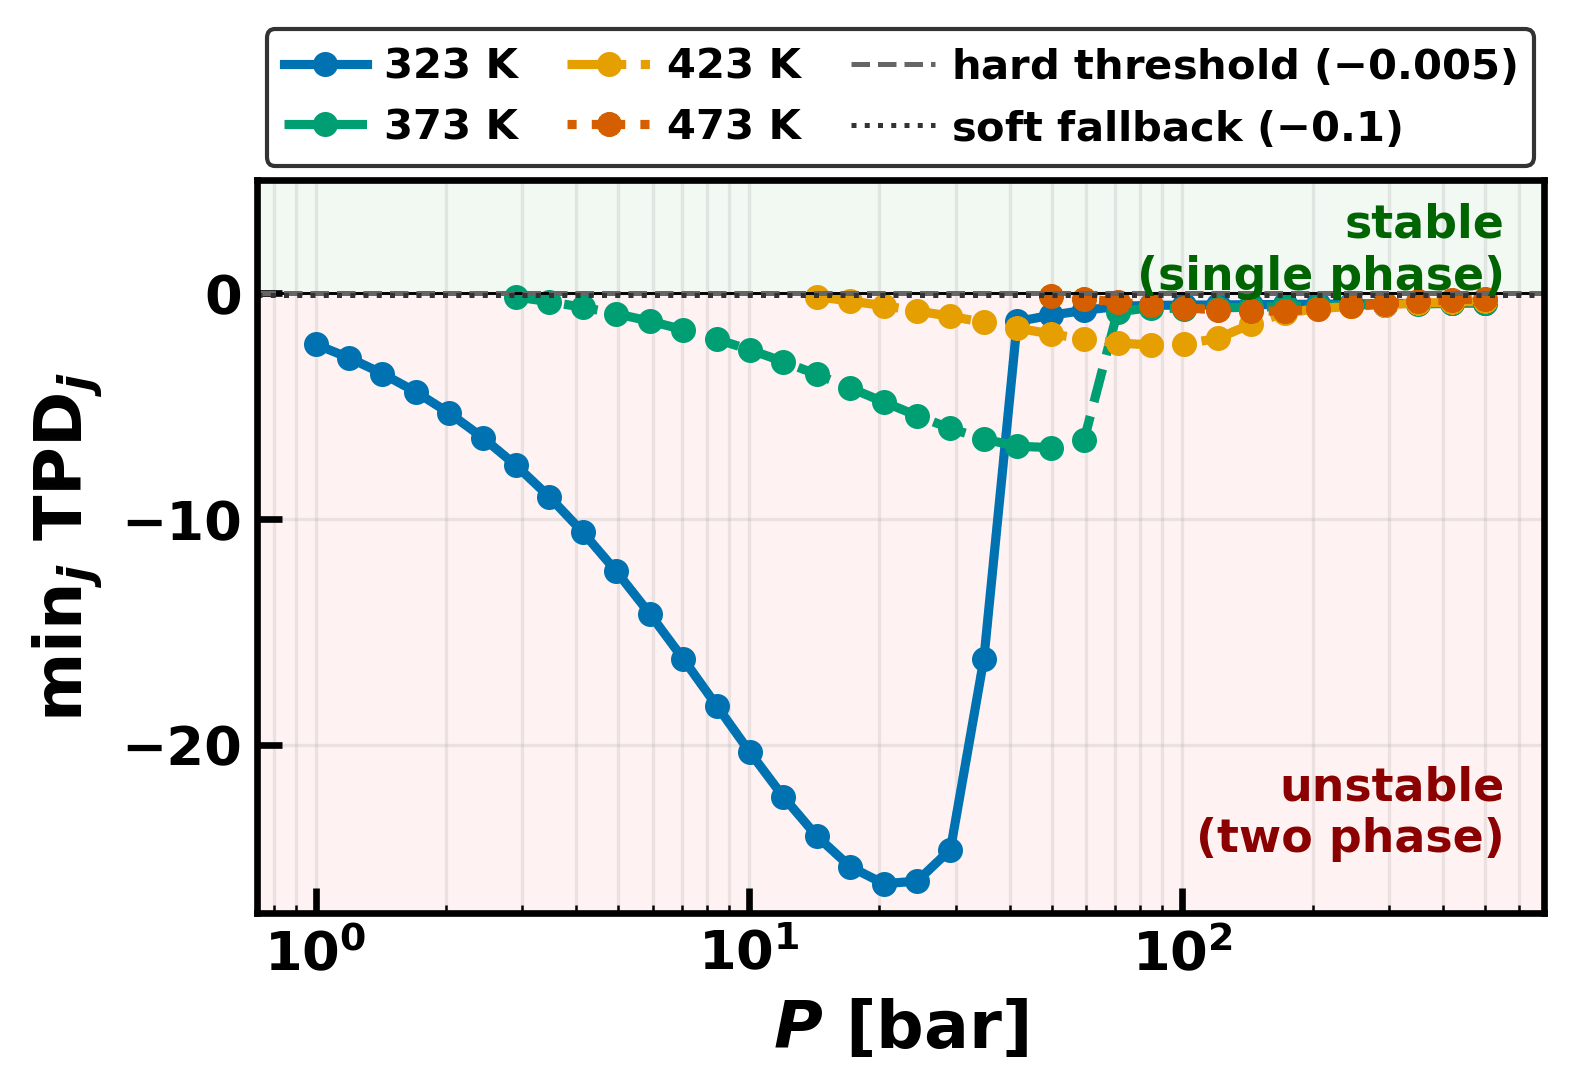

In [15]:
run('scripts/fig_stability_isotherm.py')
show('stability_tpd_isotherm_NaCl.png')


<a id="sfigS1"></a>

**Figure S1.** Most-negative TPD across the eight Michelsen trial compositions vs. pressure at four isotherms, $m_{\mathrm{NaCl}} = 1$ mol/kg, $z_{\mathrm{CO_{2}}} = 0.6$. Horizontal lines: production hard and soft classification thresholds ($-0.005$ / $-0.1$).

Figure S1 shows the multi-salt tangent-plane-distance landscape along four representative isotherms at $m_{\mathrm{NaCl}}=1$ mol/kg and $z_{\mathrm{CO_{2}}}=0.6$: the minimum trial-TPD across the eight initial guesses tracks the gas-saturation boundary and traces out the two-phase envelope directly. Feeds for which the min-TPD drops below the hard threshold at $-0.005$ are passed to the $K$-value flash; the soft threshold at $-0.1$ bounds the near-critical fallback band of Section 2.2 of the main text. Both thresholds lie close to zero on the vertical scale used in Fig. S1 and are essentially indistinguishable from the zero line at the resolution shown; the region shading (green above, red below) marks the stable and unstable sides. The specific numerical thresholds are empirically tuned to this multi-salt system; the threshold-hierarchy design (a hard trigger plus a soft confirmatory fallback) follows Jex et al.<sup>[2](#sref2)</sup>. Over the range of hard-threshold values from $-0.02$ to zero the classification changes at $0.76\%$ of the grid states at most, at no state where ms-eCPA is compared against experimental data, and not at all in the convergence rate; Section S14.2 reports the sensitivity study. The small step in the $T = 323$ K curve near $P \approx 40$ bar reflects a switch in the reference single-phase EoS root used to anchor the trial-fugacity comparison; only the sign of TPD (and the pressure at which it crosses zero) is operative for the stability classification, not its absolute magnitude in the deeply unstable regime.


<a id="ssecS8"></a>

## S8 Per-salt parity and literature scatter

In this section, we resolve the main-paper parity comparison in two complementary ways: (i) per salt, and (ii) against the inter-author scatter of the underlying experimental literature, which sets the accuracy floor any model comparison can meaningfully reach. The pool spans 31 author cohorts. Its largest single cohort contributes $173$ of the $1931$ points over $T = 283$–$423$ K and $P = 14$–$596$ bar; it sets the upper end of the calibration pressure range in $\mathrm{KCl}$ and $\mathrm{MgCl_{2}}$ rather than lying beyond it, and is predicted at $7.43\%$ — essentially the pooled accuracy of $6.55\%$. The extrapolation the pool does test is in salinity: $1229$ of its points lie off the three fitted isotherms, and $172$ are taken past the molality over which their ion parameters were anchored.


\*\*Experimental variance analysis.\*\* Figure S3 compares the ms-eCPA $\mathrm{CO_{2}}$-solubility prediction error against an empirical estimate of the experimental literature variance $\sigma_{\text{exp}}$. The variance is computed over the 50+ overlapping $(T, m_s, P\text{-bin})$ conditions where two or more literature authors report data at sufficiently close pressures and salinities to be treated as nominally repeated measurements. At each such overlap condition, $\sigma_{\text{exp}}$ is the standard deviation across the participating authors and the ms-eCPA error is its prediction referenced to the inter-author mean. The figure shows, condition by condition, whether this error is smaller or larger than the measured scatter. It does not show that the residual AARE of Table 1 of the main text is explained by experimental scatter. For $\mathrm{CaCl_{2}}$, the brine with the largest residual, the error of ms-eCPA is about twice the measured scatter (median 9.25% against 4.50%) and lies within it at only two of eight overlap conditions, as detailed below. The $\mathrm{CaCl_{2}}$ residual is therefore not attributable to experimental scatter.


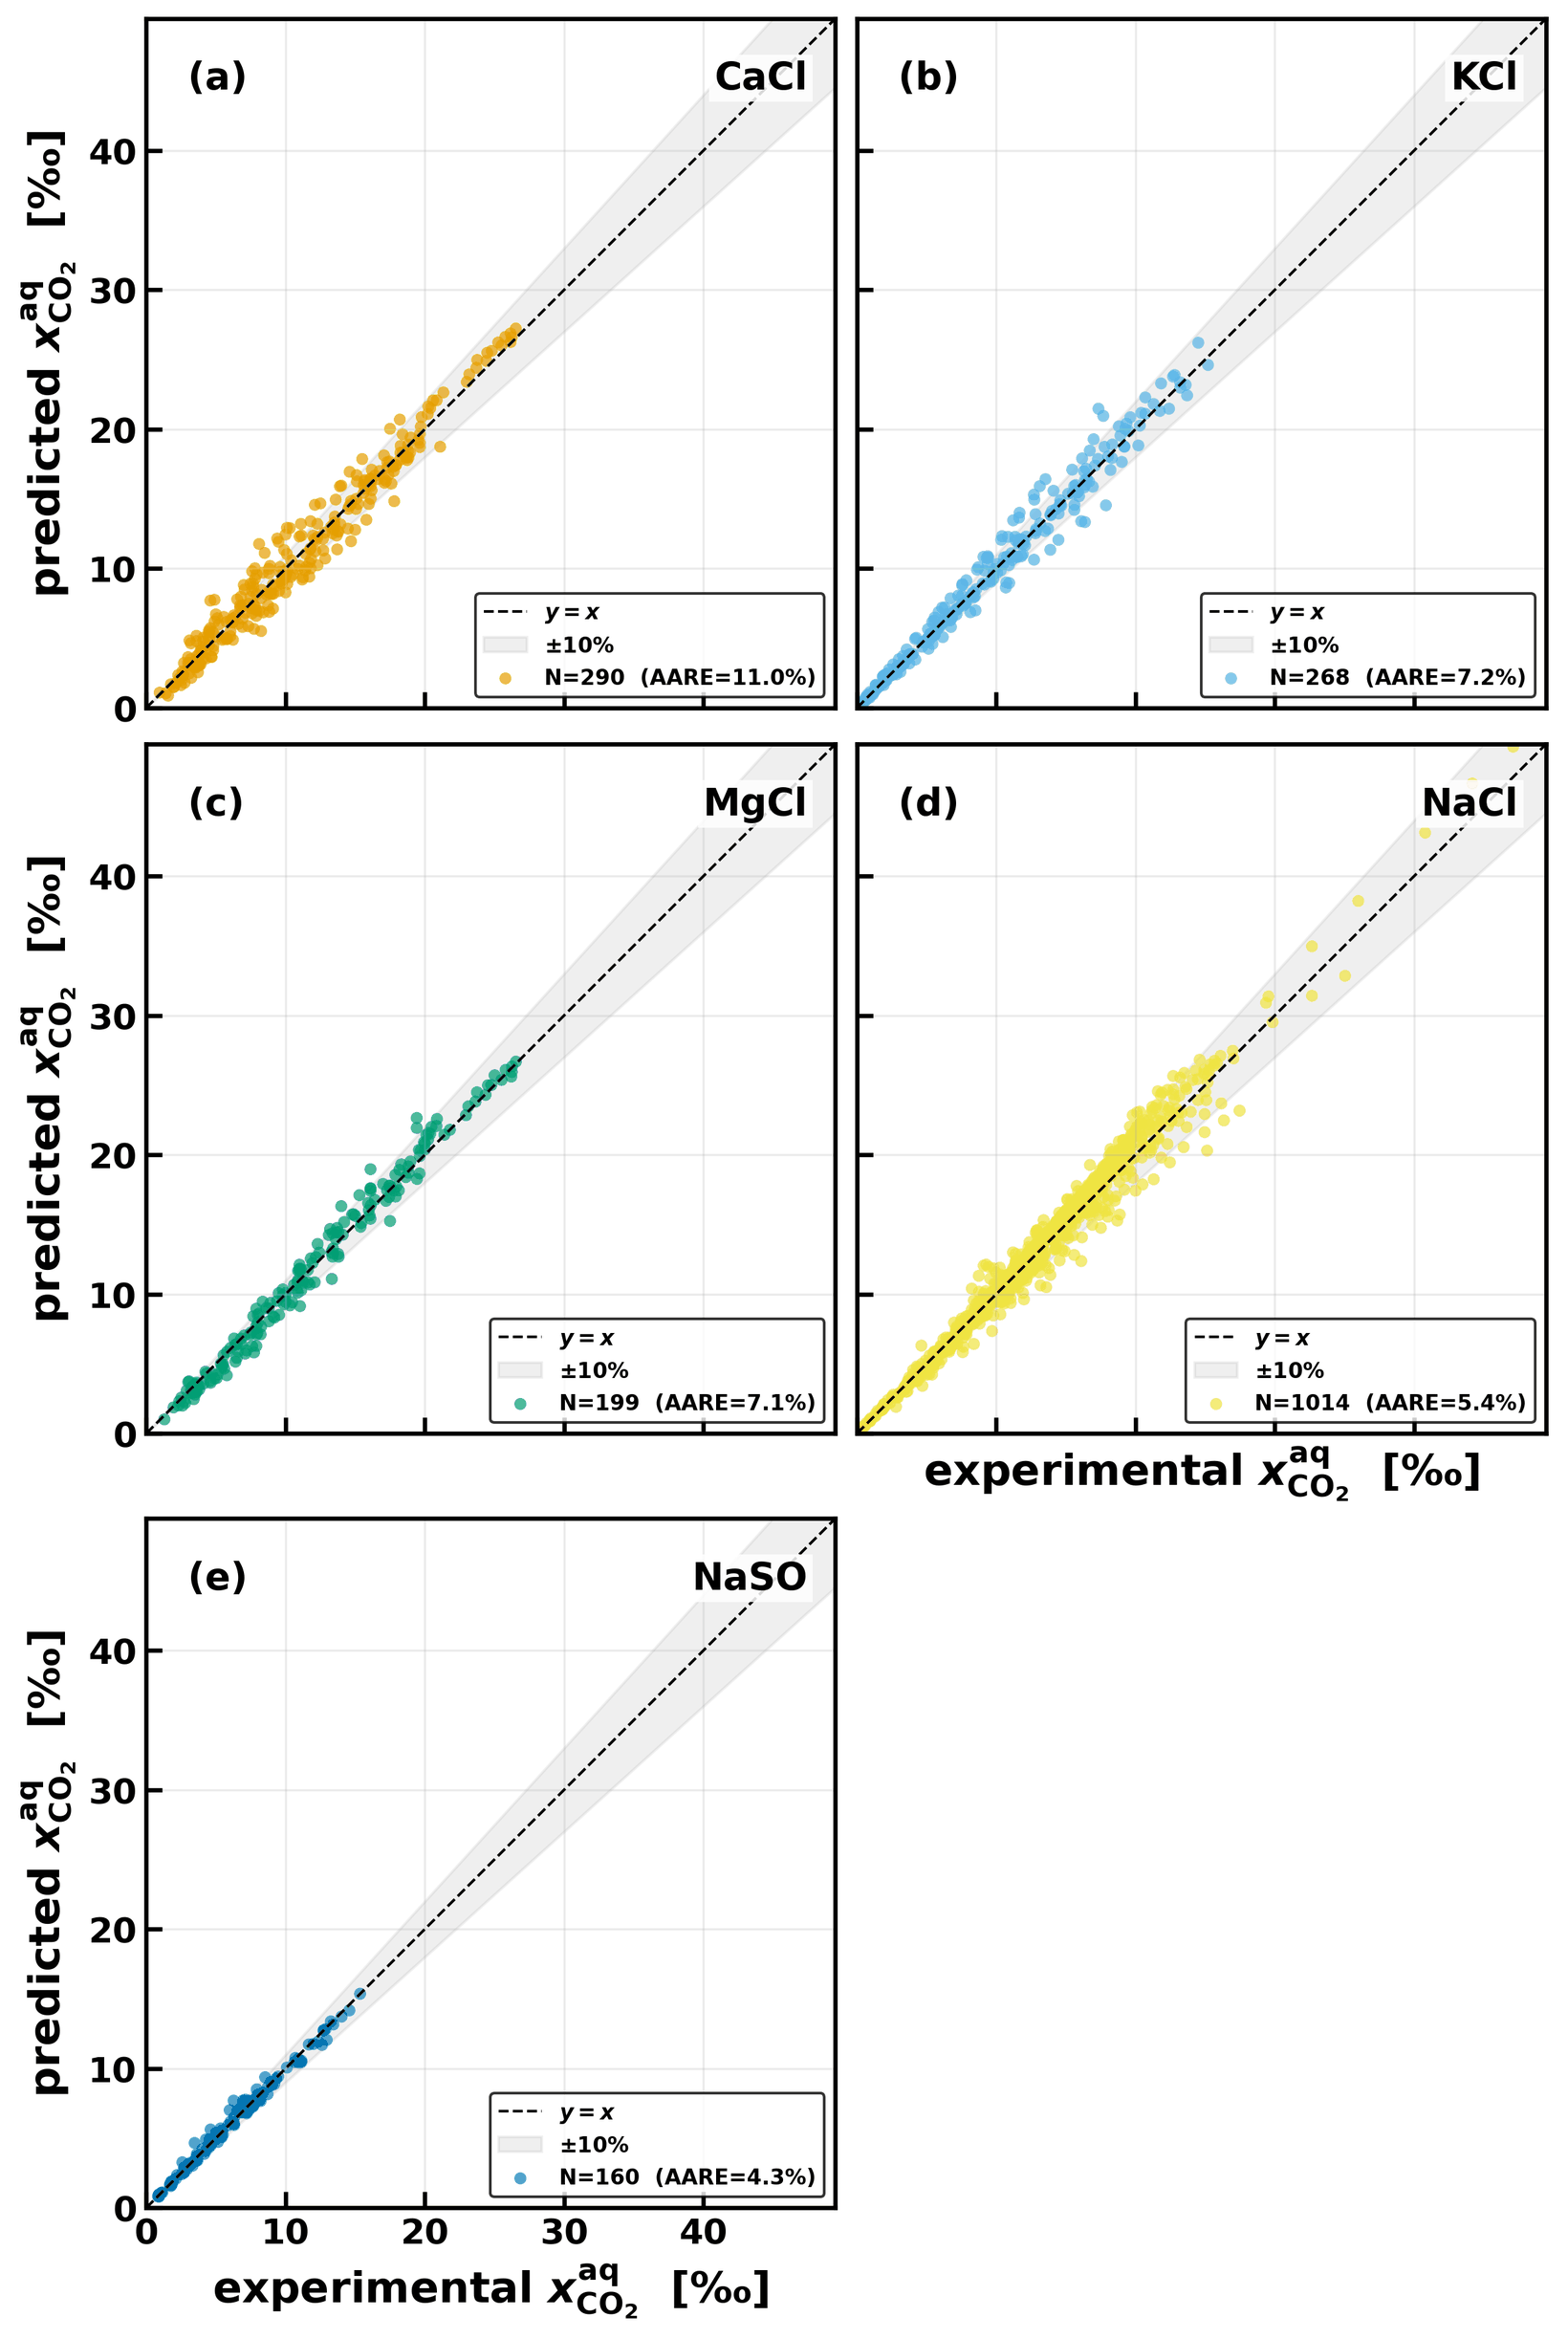

In [16]:
run('scripts/fig_flash_predictions.py')
show('per_salt_parity_SI.png')


<a id="sfigS2"></a>

**Figure S2.** Per-salt parity subplots of predicted versus experimental $\mathrm{CO_{2}}$ aqueous-phase mole fraction for each of the five single-salt brines ($\mathrm{NaCl}$, $\mathrm{KCl}$, $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$, $\mathrm{Na_{2}SO_{4}}$), all author cohorts pooled. Axes are in per-mil (‰).

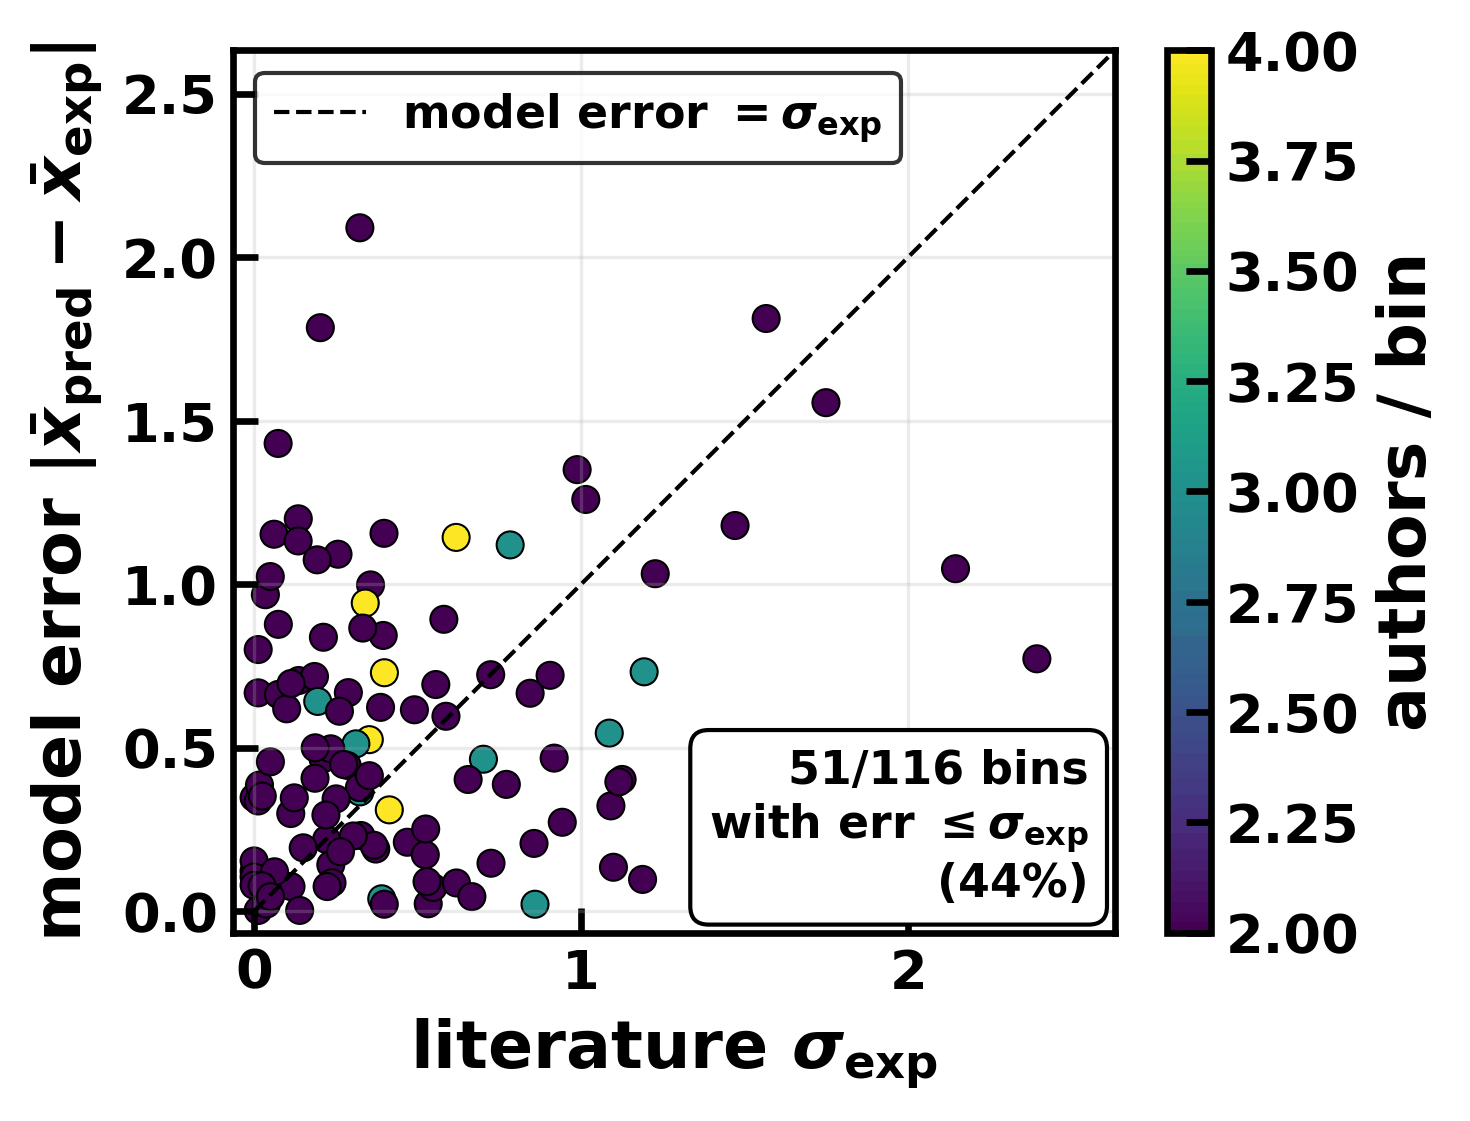

In [17]:
run('scripts/fig_flash_predictions.py')
show('experimental_variance_SI.png')


<a id="sfigS3"></a>

**Figure S3.** Experimental literature variance $\sigma_{\text{exp}}$ across the overlapping $(T, m_s, P\text{-bin})$ conditions where two or more literature authors report $\mathrm{CO_{2}}$ solubility, plotted against the deviation of the ms-eCPA prediction from the inter-author mean. Points below the $|\text{model error}| = \sigma_{\text{exp}}$ diagonal are conditions at which the error of ms-eCPA is smaller than the inter-author scatter. For $\mathrm{CaCl_{2}}$ the error exceeds the measured scatter at six of eight overlap conditions (median 9.25% against 4.50%), so the $\mathrm{CaCl_{2}}$ residual is not attributable to experimental scatter (Section S8). Both axes show $\sigma_{\text{exp}}$ and the model error multiplied by $10^{3}$ for display compactness.

\*\*Per-salt observations.\*\* The per-salt resolution of Fig. S2 shows the same picture as the pooled parity: the scatter about the diagonal is dominated by the highest-solubility (high-pressure) points of each brine, $\mathrm{Na_{2}SO_{4}}$ tracks the data most closely ($4.26\%$), and $\mathrm{CaCl_{2}}$, the most demanding brine at high salinity, has the largest residual ($11.01\%$).

For $\mathrm{CaCl_{2}}$ the comparison against the experimental scatter can be made directly, but only up to 3 mol kg$^{-1}$. Grouping the $\mathrm{CaCl_{2}}$ data by temperature and molality and matching pressures on a 20 bar grid leaves eight conditions at which two laboratories both report; the two reported pressures differ by at most 9.5 bar in each, and the most concentrated condition is at 3 mol kg$^{-1}$. The relative standard deviation between the two laboratories has a median of 4.50% over the eight, ranging from 2.56% to 21.94%; each value rests on two laboratories and bounds the true spread only loosely. The deviation of ms-eCPA from the inter-laboratory mean at the same eight conditions has a median of 9.25% (range 3.03–25.40%) and falls within the measured scatter at two of them, so the $\mathrm{CaCl_{2}}$ residual is not attributable to the quality of the data where that quality can be measured. Above 3 mol kg$^{-1}$ no two sources report at a common condition and the scatter cannot be measured, but the salting-out trend provides a consistency check on the data that does not close. At the three conditions where the 6 mol kg$^{-1}$ series of Messabeb et al.<sup>[5](#sref5)</sup> and the 5 mol kg$^{-1}$ series of Tong et al.<sup>[4](#sref4)</sup> can be compared at the same temperature and pressure (373 K/76 bar, 373 K/169 bar and 423 K/105 bar), the 6 mol kg$^{-1}$ solubility is $0.92\times$, $0.99\times$ and $1.04\times$ the 5 mol kg$^{-1}$ one, whereas a Setschenow slope fitted to the 1, 3 and 5 mol kg$^{-1}$ data of Tong et al.<sup>[4](#sref4)</sup> at those same conditions places the measured 6 mol kg$^{-1}$ values 22%, 29% and 44% above its own extrapolation. Consistently with that, ms-eCPA deviates by $+19.3\%$ from the 5 mol kg$^{-1}$ points of Tong et al.<sup>[4](#sref4)</sup> and by $-13.5\%$ from the 6 mol kg$^{-1}$ points of Messabeb et al.<sup>[5](#sref5)</sup> (twelve points each): the two cannot both be reproduced by a single parameter set, and both are inside the pool the $\mathrm{CaCl_{2}}$ statistic of the main text averages over.


\*\*Where the per-salt residual comes from.\*\* The ion parameters are anchored on osmotic coefficients to $m_s \le 6$ for $\mathrm{NaCl}$, $\le 4.5$ for $\mathrm{KCl}$ and $\le 2$ mol kg$^{-1}$ for $\mathrm{CaCl_{2}}$, $\mathrm{MgCl_{2}}$ and $\mathrm{Na_{2}SO_{4}}$, while the $\mathrm{CO_{2}}$-solubility data reach 6, 4.5, 6, 5 and 2.7 mol kg$^{-1}$ respectively. Split at the upper limit of each salt’s own anchoring range, the residual is 8.13% inside against 15.58% outside for $\mathrm{CaCl_{2}}$ ($N = 178$ and 112) and 5.67% against 10.52% for $\mathrm{MgCl_{2}}$ (141 and 58); $\mathrm{NaCl}$ and $\mathrm{KCl}$ never leave their anchoring ranges. Resolved instead by ionic strength $I = \tfrac12\sum_i m_i z_i^2$, the pooled error is 6.90, 5.64, 5.23, 7.08 and 9.40% over $I < 1$, 1–2, 2–4, 4–6 and $\ge 6$ mol kg$^{-1}$: flat across the lower four bins and higher only in the top one, which holds all 172 points beyond an anchoring range.

The divalent chlorides reach that edge first, because at equal molality a 2:1 salt has three times the ionic strength of a 1:1 salt, and two terms of the formulation respond to exactly those brines. The Born contribution is linear in the $z^2$-weighted ion count $\sum_i n_i z_i^2/R_{B,i}$, so at equal molality a divalent cation loads it four times as heavily as a monovalent one and amplifies any imprecision in its Born radius in proportion. The Debye–Hückel contribution takes its concentration dependence through the screening parameter, $\kappa^2 \propto \sum_i n_i z_i^2/V$, and so also responds to ionic strength rather than to molality. Both treat the solvent as a continuum around ions of concentration-independent radius, the approximation under most strain where the residual is largest: at 6 mol kg$^{-1}$ $\mathrm{CaCl_{2}}$ there are 3.1 water molecules per ion, against 9.3 at the 2 mol kg$^{-1}$ limit of the anchoring range and 4.6 in 6 mol kg$^{-1}$ $\mathrm{NaCl}$.


<a id="ssecS9"></a>

## S9 Predictions across the $T$–$P$–composition window

To complement the per-isotherm validation of the parameterization study<sup>[1](#sref1)</sup> and the flash validation of Section 3.1 of the main text, here we catalog the multi-salt stability-and-flash predictions on the same dense $(T, P, \mathbf{z}, \mathbf{m}_i)$ grid whose convergence and per-call cost profile are characterised in Section S14.


<a id="ssecS9_1"></a>

### S9.1 Phase boundary and partition predictions

Figure S4 shows the vapor fraction and the extent of the two-phase region for the ternary feed. Figure S5 shows the $\mathrm{CO_{2}}$/$\mathrm{CH_{4}}$ separation factor on the same grid.


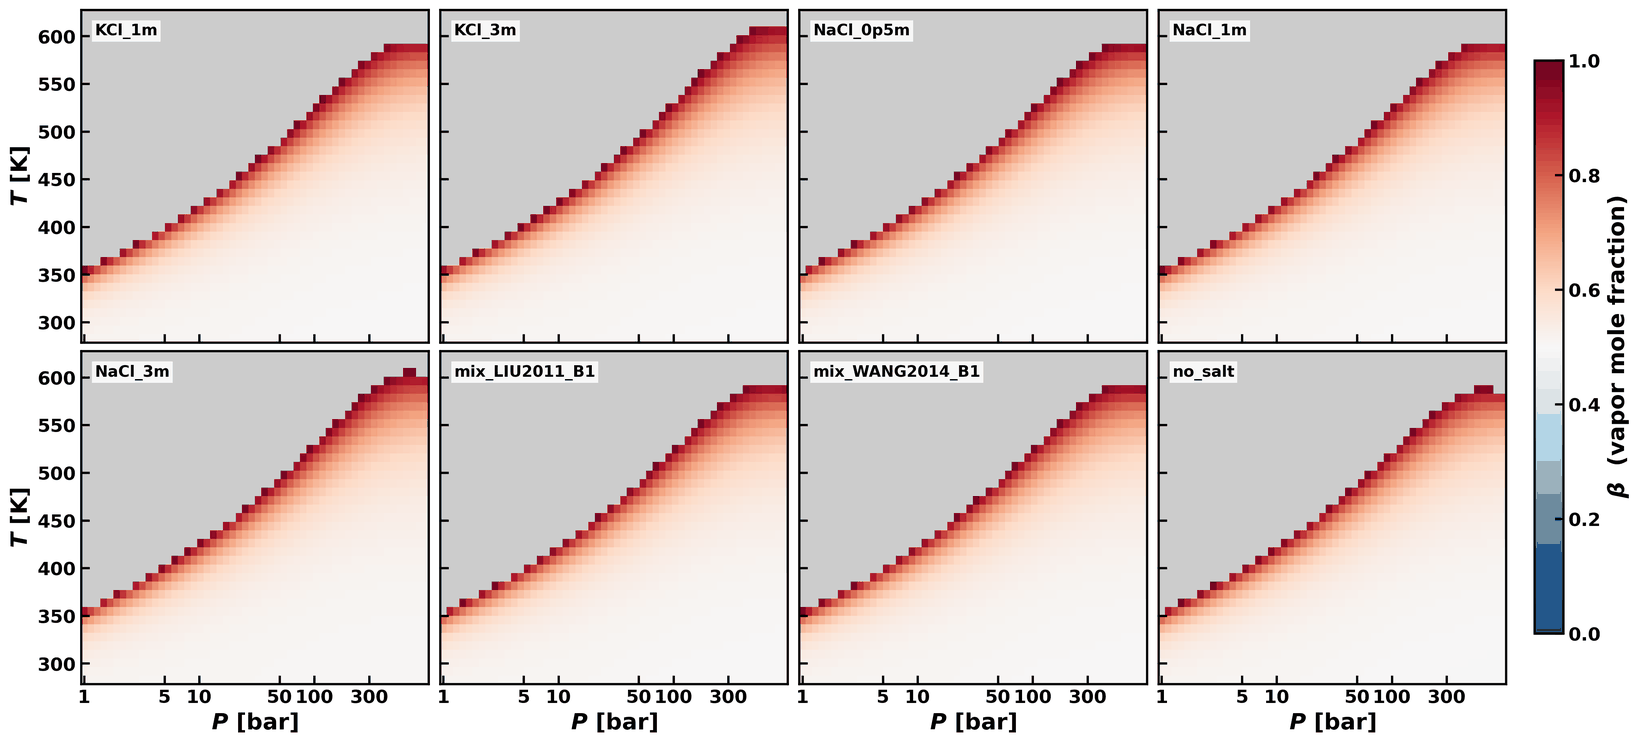

In [18]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/phase_boundary_ternary.png')


<a id="sfigS4"></a>

**Figure S4.** Vapor mole fraction $\beta$ (partitioning-component basis) for the ternary $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ feed at $z = (0.490, 0.255, 0.255)$, one panel per salt configuration. Grey cells are single-phase. Cool blues indicate aqueous-phase-dominated splits, warm reds gas-phase-dominated splits. The two-phase region occupies the intermediate $T$–$P$ wedge between the low-$P$/low-$T$ dew line and the high-$T$ critical locus where the mixture becomes miscible.

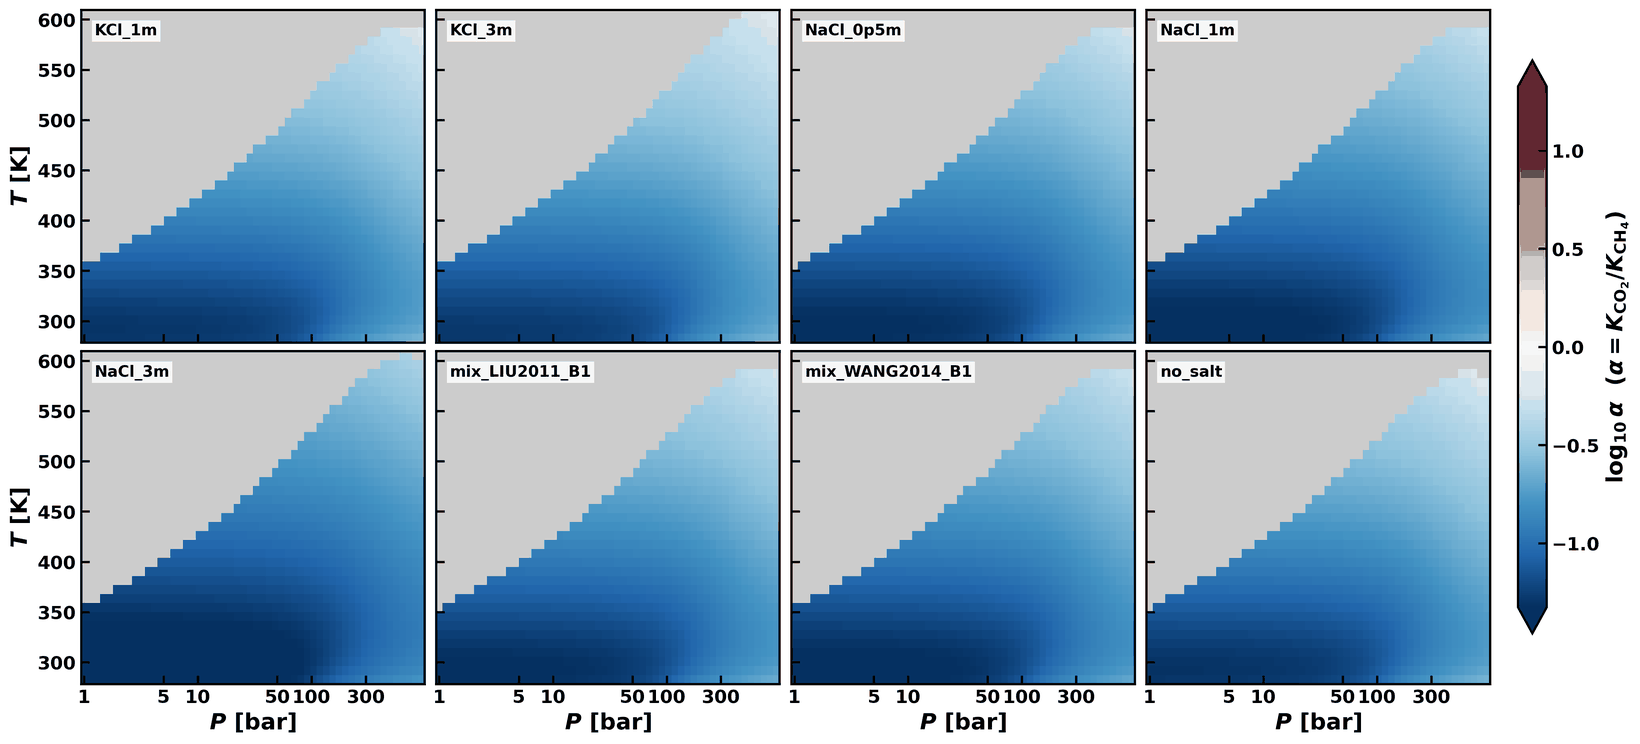

In [19]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/selectivity_co2_ch4_ternary.png')


<a id="sfigS5"></a>

**Figure S5.** $\log_{10}\alpha$ where $\alpha = (y_{\mathrm{CO_{2}}}/x_{\mathrm{CO_{2}}}^{aq})/                    (y_{\mathrm{CH_{4}}}/x_{\mathrm{CH_{4}}}^{aq})$ is the ratio of $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ $K$-values — equivalently, the gas/aqueous partition-coefficient selectivity. Across the examined window ms-eCPA predicts $\alpha < 1$ almost everywhere, meaning that $\mathrm{CO_{2}}$ preferentially partitions into the aqueous phase relative to $\mathrm{CH_{4}}$. This is the key physics underlying both $\mathrm{CO_{2}}$ geological storage ($\mathrm{CO_{2}}$ stays in the brine) and gas-reservoir compositional shifts during long-term injection.

<a id="ssecS9_2"></a>

### S9.2 Gas-phase water content

The water mole fraction in the gas (or $\mathrm{CO_{2}}$-rich) phase is the quantity that determines the salt-conservation amplification of aqueous brine molality discussed in the prepared-versus-equilibrium molality analysis of Moortgat et al.<sup>[1](#sref1)</sup>. The two figures below show $y_{\mathrm{H_{2}O}}^{\text{gas}}$ across the examined $(T, P)$ window for the two binaries, demonstrating that this correction is sub-percent at near-ambient temperatures (lower-left of each panel) and exceeds 30 % at the upper-$T$/lower-$P$ corner.


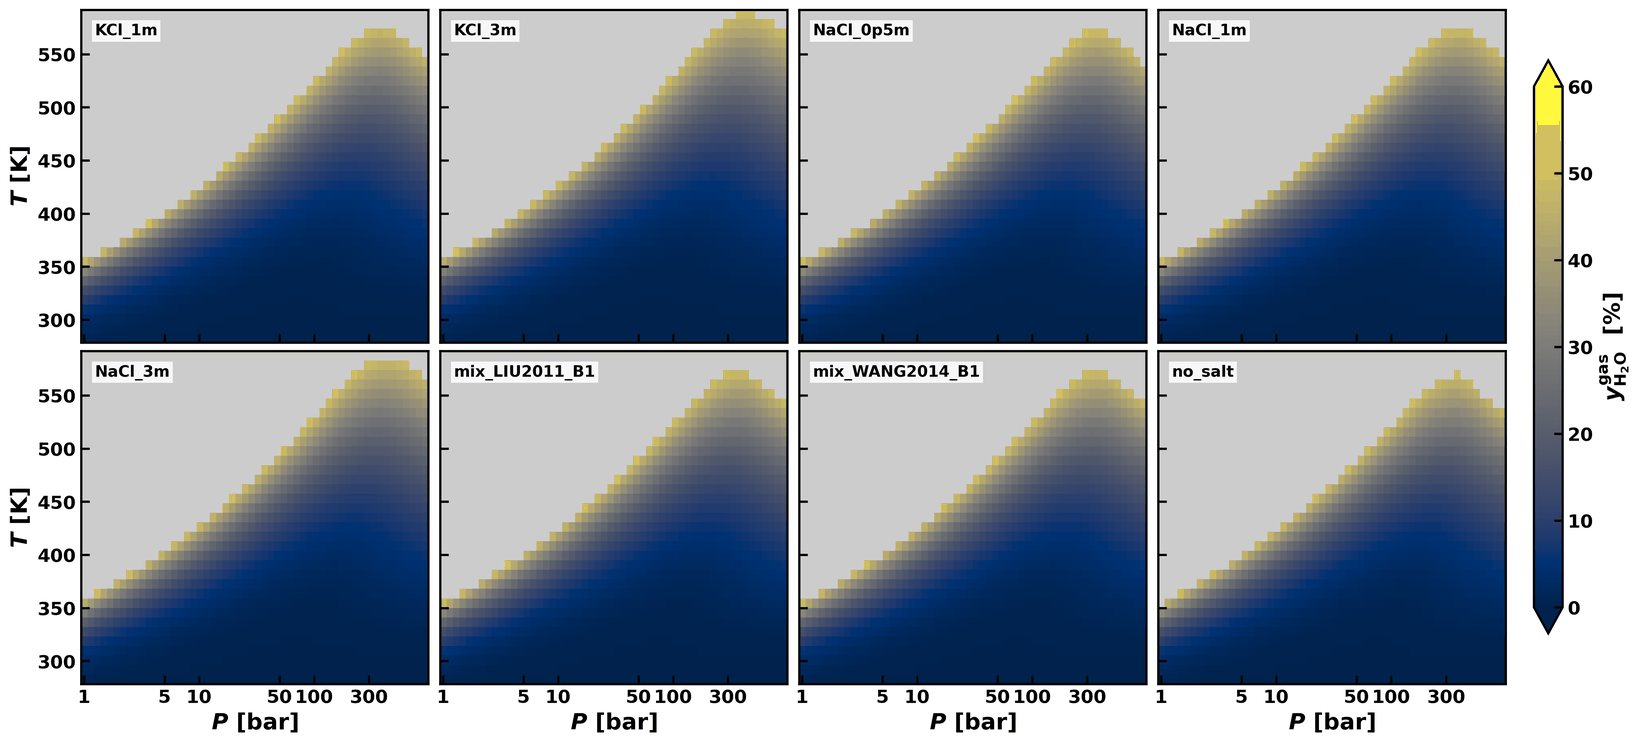

In [20]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/yH2O_gas_binary_CO2_surface.png')


<a id="sfigS6"></a>

**Figure S6.** $y_{\mathrm{H_{2}O}}^{\text{gas}}$ for the binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ feed at $z_{\mathrm{CO_{2}}} = 0.50$, one panel per salt configuration. The high-$T$/low-$P$ region has $y_{\mathrm{H_{2}O}}^{\text{gas}}$ well above 0.1: the regime where the prepared-brine versus equilibrium-aqueous molality distinction of Moortgat et al.<sup>[1](#sref1)</sup> becomes quantitatively important.

The near-atmospheric end of the pressure window deserves its own resolution, which the coarse pressure grid of the surface maps cannot provide. Figure S7 follows the gas-phase water content of the $\mathrm{CO_{2}}$–brine system down to 1 bar along four isotherms. As $P \to P_{\text{sat,w}}(T)$ the water content approaches the Raoult limit $y_{\mathrm{H_{2}O}} \approx a_w P_{\text{sat,w}}/P$ and becomes large at warm temperatures — 12% at 323 K and 39% at 348 K already at 1 bar — and ms-eCPA reproduces this limit quantitatively. In mass units these values — 1.3 wt% at 298 K and 1 bar, rising to 5.5 wt% at 323 K — agree with the Spycher et al.<sup>[11](#sref11)</sup>-based water-solubility values quoted in the $\mathrm{CO_{2}}$-displacement literature, where the steep rise of the water content of the $\mathrm{CO_{2}}$ phase toward atmospheric pressure, and its strong growth with temperature at fixed low pressure, are both the $a_w P_{\text{sat,w}}(T)/P$ envelope seen here on logarithmic axes. Salt lowers the curves by the brine’s water activity (about 7% at 2 mol kg$^{-1}$ $\mathrm{NaCl}$, consistent with the osmotic-coefficient validation of Moortgat et al.<sup>[1](#sref1)</sup>), and at higher pressures the water content rises *above* the Raoult reference — the familiar water-content minimum near 60–80 bar followed by enhancement in dense $\mathrm{CO_{2}}$ from gas-phase nonideality.


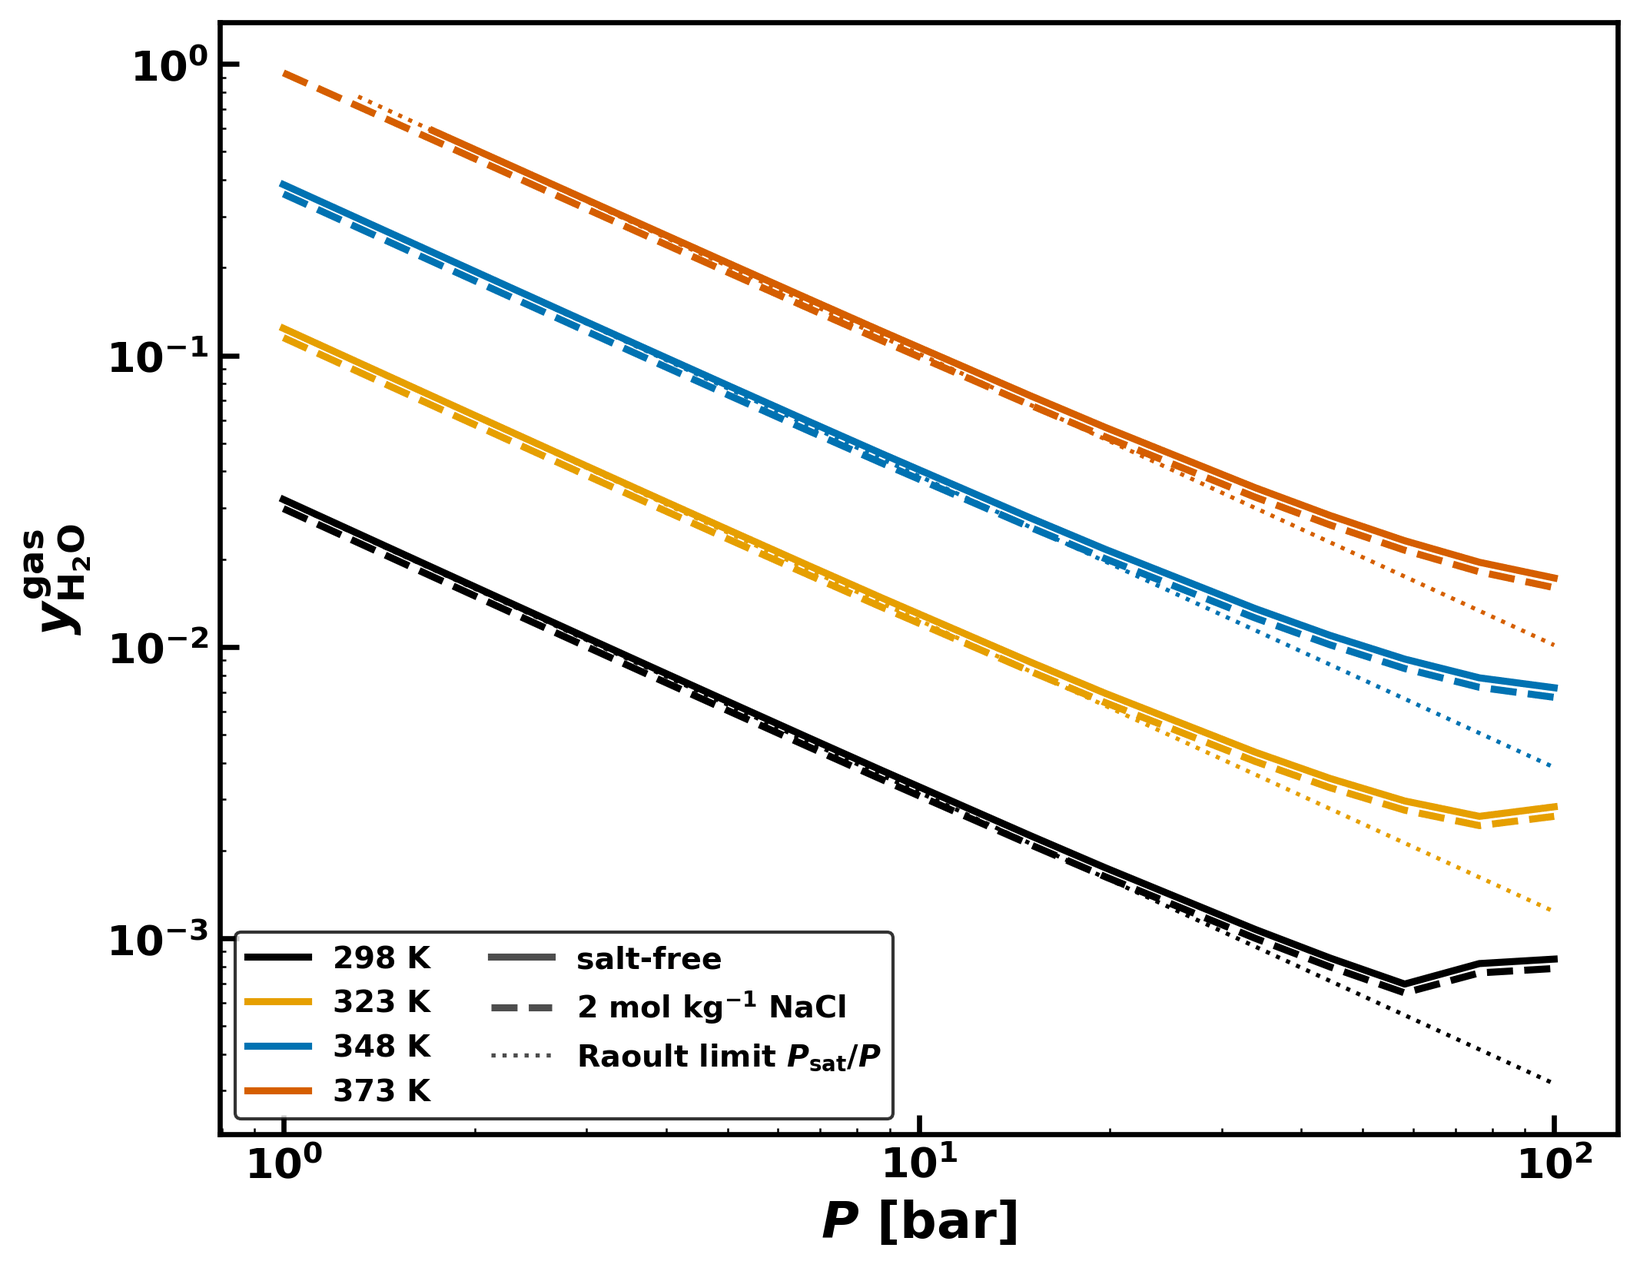

In [21]:
run('pilot_studies/ywater_lowP_2026_08/fig_ywater.py', long=('--recompute',))
show('ywater_lowP_SI.png')


<a id="sfigS7"></a>

**Figure S7.** Water content of the $\mathrm{CO_{2}}$-rich phase down to 1 bar: ms-eCPA isotherms for salt-free water (solid) and 2 mol kg$^{-1}$ $\mathrm{NaCl}$ brine (dashed), against the pure-water Raoult limit $P_{\text{sat,w}}(T)/P$ (thin dotted). The 373 K curves start at the pressure where an aqueous phase exists ($P > P_{\text{sat,w}}$).

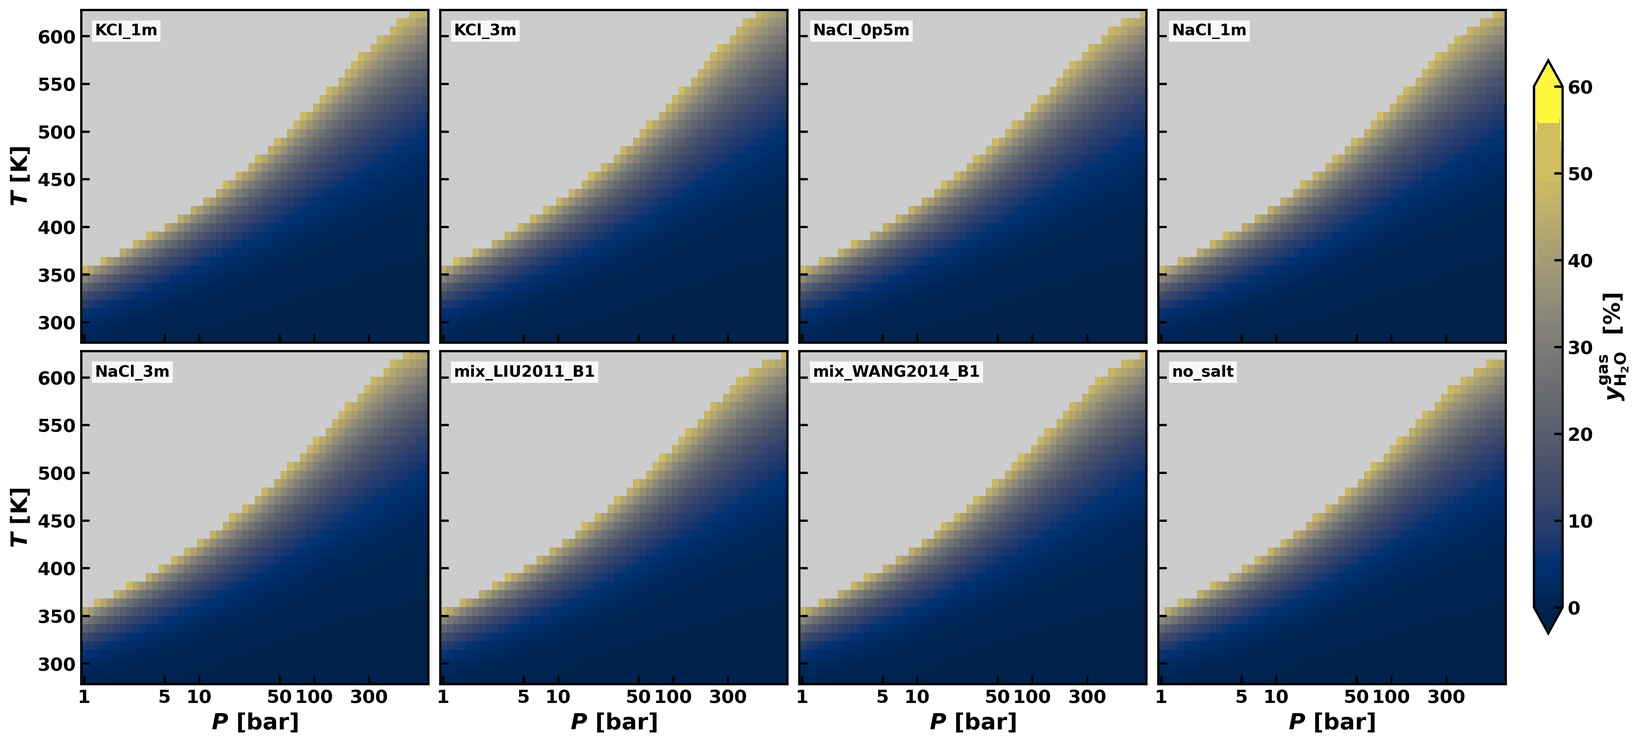

In [22]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/yH2O_gas_binary_CH4_surface.png')


<a id="sfigS8"></a>

**Figure S8.** Same as Fig. S6 for the binary $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ feed at $z_{\mathrm{CH_{4}}} = 0.50$. The non-polar nature of $\mathrm{CH_{4}}$ leaves the qualitative shape of the gas-phase water content similar to the $\mathrm{CO_{2}}$–brine case at modest temperatures; at high $T$ the $y_{\mathrm{H_{2}O}}^{\text{gas}} > 0.1$ region extends to higher pressures than for $\mathrm{CO_{2}}$.

The same water-activity physics governs the vapor pressure of the brine itself. Figure S9 shows the ms-eCPA bubble pressure of $\mathrm{NaCl}$ brines against the IAPWS pure-water saturation line: the lowering follows $P_{\text{sat}}(m)/P_{\text{sat}}(0) \approx a_w$, essentially temperature-independent, and matches the Pitzer water activities at 298 K to 0.03% (1 mol kg$^{-1}$), 0.08% (3 mol kg$^{-1}$), and 0.35% (6 mol kg$^{-1}$) — the vapor-pressure expression of the osmotic-coefficient validation of Moortgat et al.<sup>[1](#sref1)</sup>. On the logarithmic pressure scale of panel (a) — and of the $(T, P)$ maps throughout this Supporting Information — the lowering is nearly invisible: even at 6 mol kg$^{-1}$ it shifts the saturation line by only 24%, less than two steps of the 13.7% logarithmic pressure grid of the dense sweep. This is why the per-salt phase-boundary maps of Section S9.1 appear salt-independent: the boundary does shift with salinity — by the factor $a_w$ at the steam-side edge — but by at most two grid cells, and only at a handful of $(T, P)$ cells.


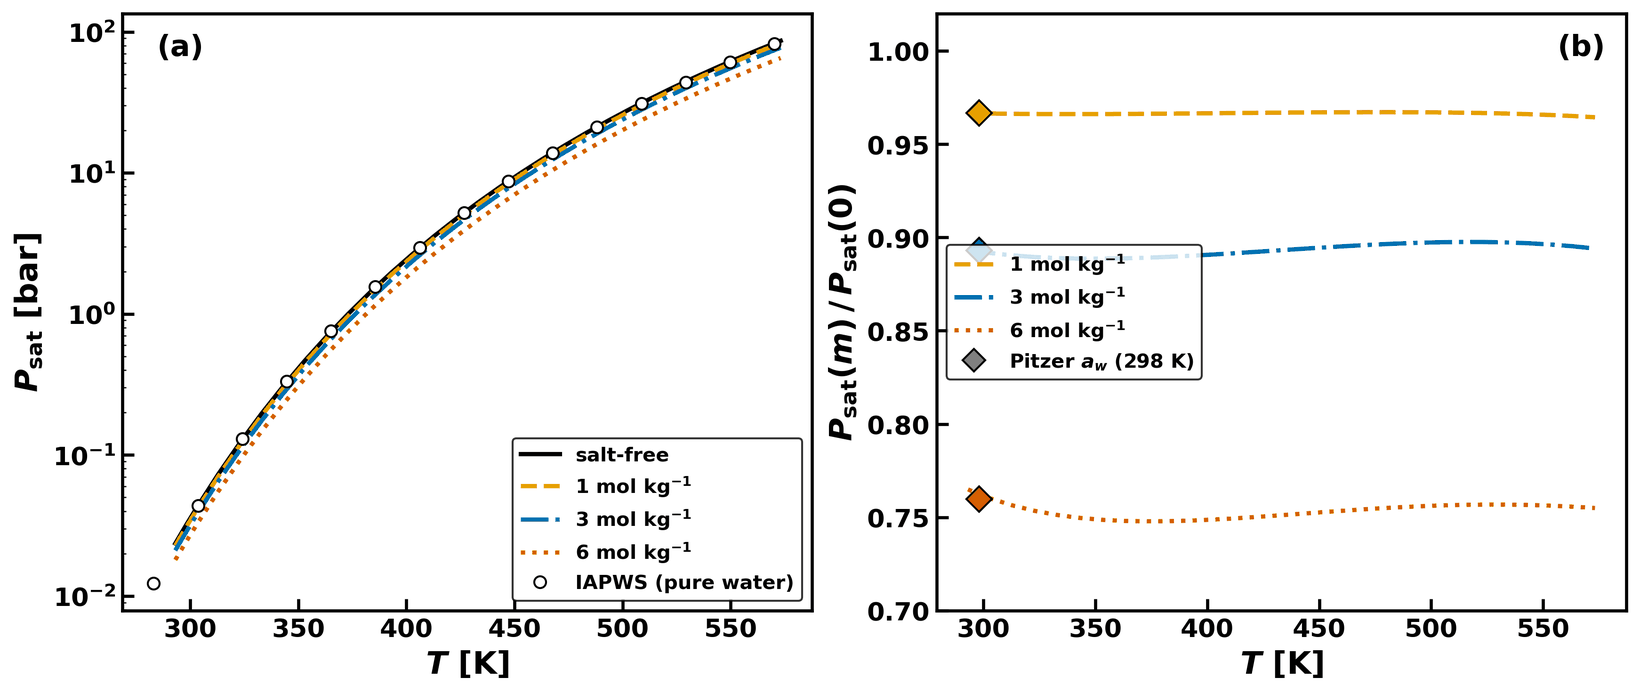

In [23]:
run('pilot_studies/vpsat_salt_2026_08/vpsat.py', long=('--recompute',))
show('vpsat_salt_SI.png')


<a id="sfigS9"></a>

**Figure S9.** Vapor pressure of $\mathrm{NaCl}$ brines. (a) ms-eCPA bubble pressure at 0–6 mol kg$^{-1}$ with the IAPWS pure-water saturation line (circles); on this logarithmic scale the salt effect is barely visible. (b) The lowering ratio $P_{\text{sat}}(m)/P_{\text{sat}}(0)$ resolved, with the Pitzer water activities at 298 K (diamonds).

<a id="ssecS9_3"></a>

### S9.3 Aqueous solubility and density

Figures S10 and S11 show the predicted aqueous $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ mole fractions for the equimolar binary feeds. Table S8 lists the aqueous $\mathrm{CO_{2}}$ mole fraction at selected grid points.


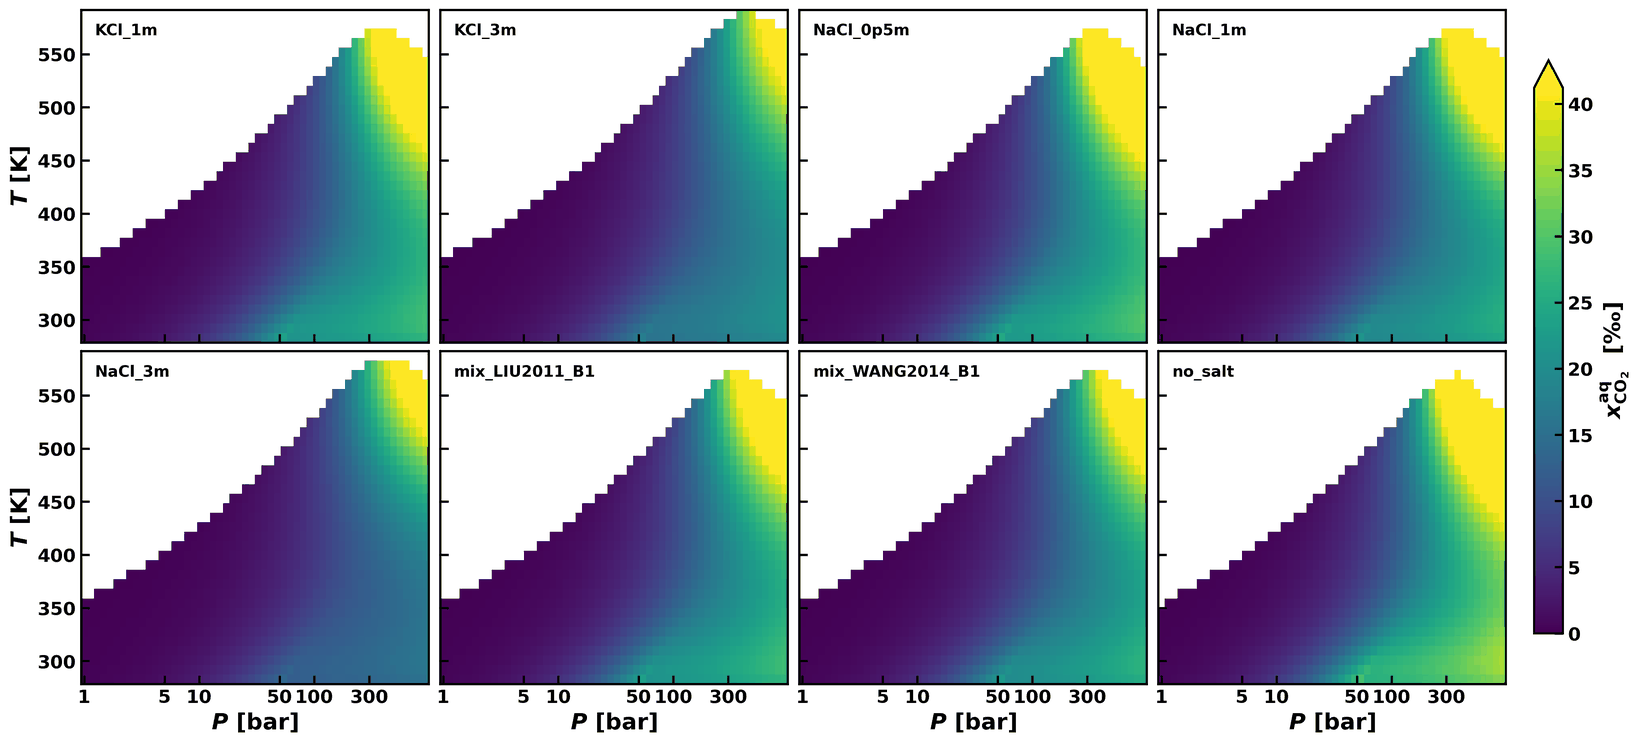

In [24]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/co2_solubility_binary_zCO2_0.50.png')


<a id="sfigS10"></a>

**Figure S10.** Predicted aqueous-phase $\mathrm{CO_{2}}$ mole fraction in per-mil for the binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ feed at the equimolar composition $z_{\mathrm{CO_{2}}} = 0.50$, representative of states where the two partitioning species are present in similar amounts. The salting-out shift from the no-salt panel to the 3 m brines is visible as a uniform downward shift of the color scale.

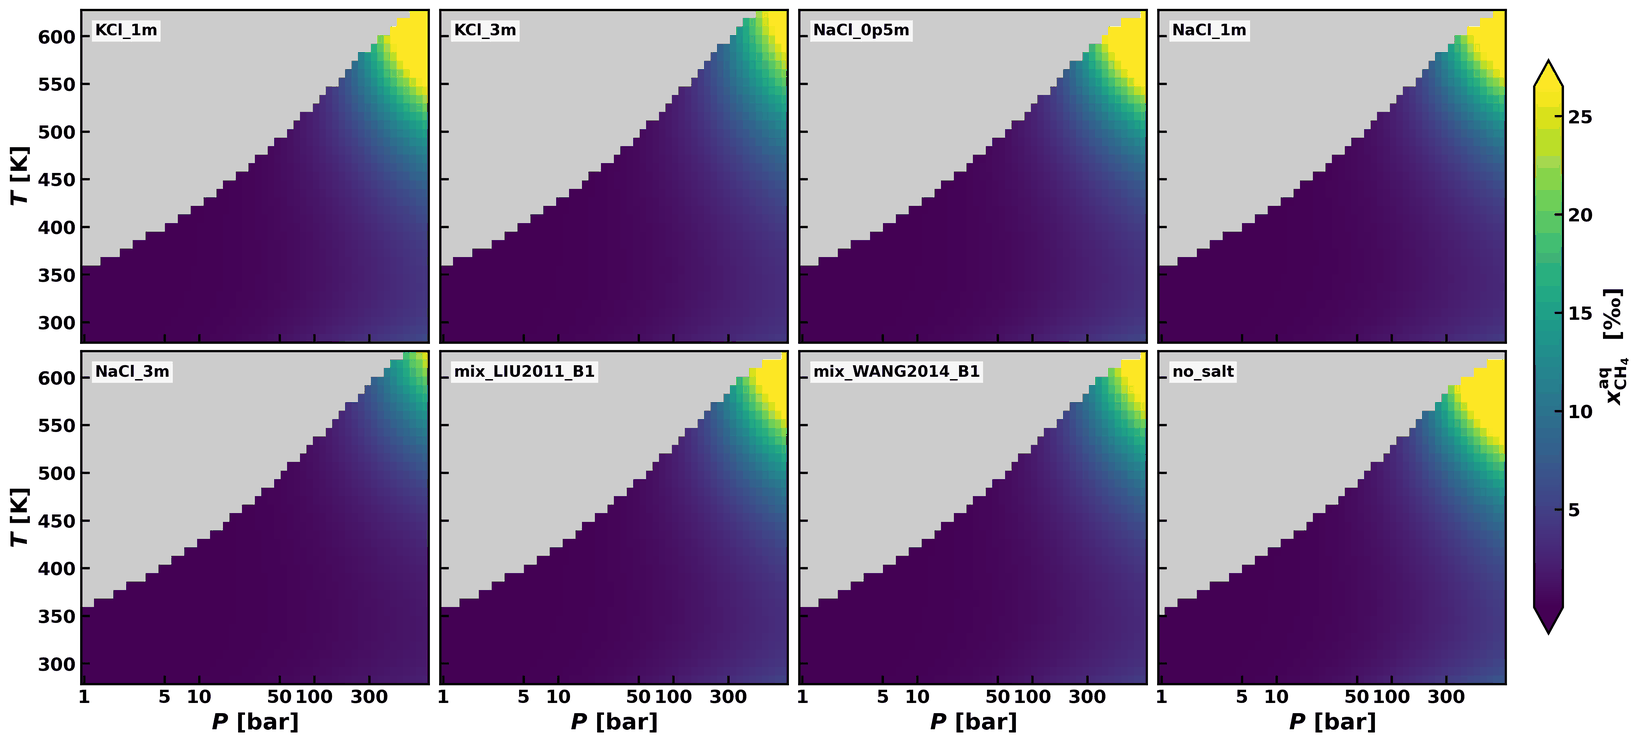

In [25]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/ch4_solubility_binary_zCH4_0.50.png')


<a id="sfigS11"></a>

**Figure S11.** The corresponding aqueous-phase $\mathrm{CH_{4}}$ mole fraction for the binary $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ feed at $z_{\mathrm{CH_{4}}} = 0.50$. $\mathrm{CH_{4}}$ solubility is roughly an order of magnitude smaller than $\mathrm{CO_{2}}$ solubility under the same conditions, consistent with the salt-free binary validation of Moortgat et al.<sup>[1](#sref1)</sup>.

<a id="stabS8"></a>

**Table S8.** Predicted aqueous-phase $\mathrm{CO_{2}}$ mole fraction in per-mil () at the grid temperatures $T = 318.8$ and $426.2$ K (nearest to 323 and 423 K) and $P = 103, 289, 484, 923$ bar for each salt configuration. The salting-out signal of Moortgat et al.<sup>[1](#sref1)</sup> is compactly summarized here, with the multi-salt extension to the higher-$T$ conditions where experimental data are sparse.

In [26]:
import pandas as pd

d = pd.read_parquet("results_cache/sweep/merged.parquet")   # the shipped flash-grid results
conv = d[d.converged]
FAMILY = {"binary_CH4": "binary CH₄–H₂O", "binary_CO2": "binary CO₂–H₂O",
          "ternary": "ternary CH₄–CO₂–H₂O"}
# binary CO2-H2O feed at z_CO2 = 0.5; grid T and P nearest 323/423 K and 100/300/500/1000 bar
sub = conv[(conv.phases == 2) & (conv.feed_family == "binary_CO2") & ((conv.z_CO2 - 0.5).abs() < 0.05)]
near = lambda arr, v: min(arr, key=lambda x: abs(x - v))
Ts = [near(sorted(sub.T_K.unique()), t) for t in (323, 423)]
Ps = [near(sorted(sub.P_bar.unique()), p) for p in (100, 300, 500, 1000)]
rows = []
for salt, s in sub.groupby("salt_name"):
    row = {"Salt": salt}
    for T in Ts:
        for P in Ps:
            cell = s[(s.T_K == T) & (s.P_bar == P)]
            row[f"{T:.1f} K, {P:.0f} bar"] = f"{1000 * cell.x_CO2_aq.iloc[0]:.1f}" if len(cell) else "—"
    rows.append(row)
print("aqueous CO2 mole fraction in per mil")
show_table(pd.DataFrame(rows))


aqueous CO2 mole fraction in per mil


Salt,"318.8 K, 103 bar","318.8 K, 290 bar","318.8 K, 485 bar","318.8 K, 923 bar","426.2 K, 103 bar","426.2 K, 290 bar","426.2 K, 485 bar","426.2 K, 923 bar"
KCl_1m,19.3,23.0,25.1,28.1,9.9,20.7,26.2,32.5
KCl_3m,14.9,17.5,19.0,20.9,7.9,15.9,19.8,24.1
NaCl_0p5m,19.9,23.9,26.1,29.3,10.2,21.6,27.5,34.5
NaCl_1m,17.5,20.8,22.8,25.4,9.4,19.6,24.8,30.8
NaCl_3m,11.5,13.5,14.7,16.2,6.9,13.8,17.2,21.0
mix_LIU2011_B1,18.8,22.4,24.5,27.5,9.3,19.5,24.8,30.9
mix_WANG2014_B1,17.6,21.0,23.0,25.8,8.7,18.0,22.8,28.4
no_salt,23.2,27.9,30.8,34.7,11.2,24.1,31.1,39.4


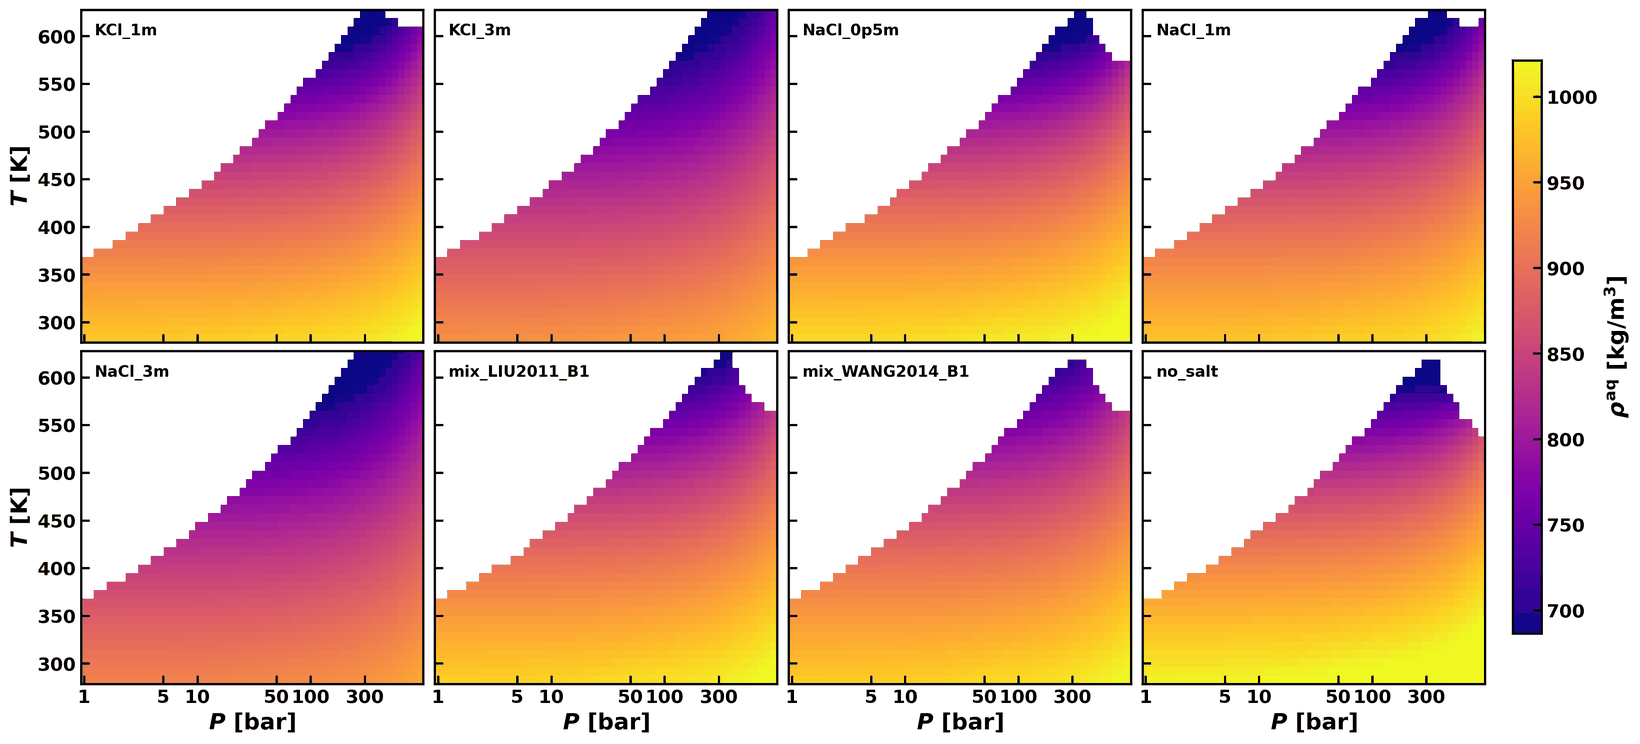

In [27]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/density_binary_zCO2_0.25.png')


<a id="sfigS12"></a>

**Figure S12.** Predicted aqueous-phase mass density $\rho^{\mathrm{aq}}$ over the $(T, P)$ window for the binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ feed at $z_{\mathrm{CO_{2}}} = 0.25$, one panel per salt configuration. The color scale is clipped at the 1st/99th percentiles; the 3 m brines saturate its upper end.

<a id="ssecS9_4"></a>

### S9.4 Equilibrium-state observables

The following four heatmaps catalogue the equilibrium values of the phase-state variables $(Z^{aq}, Z^{gas}, \varepsilon_r,
\chi_{\mathrm{H_{2}O}}^{aq})$ produced by the multi-salt phase-fugacity evaluation of Section 2.3 of the main text. These quantities are useful both as physical diagnostics of the Maribo-Mogensen permittivity and Wertheim association coupling, and as initial estimates for downstream evaluations at nearby states. Figures S13 and S14 show the two compressibility factors, Fig. S15 the static permittivity and Fig. S16 the water association fraction.


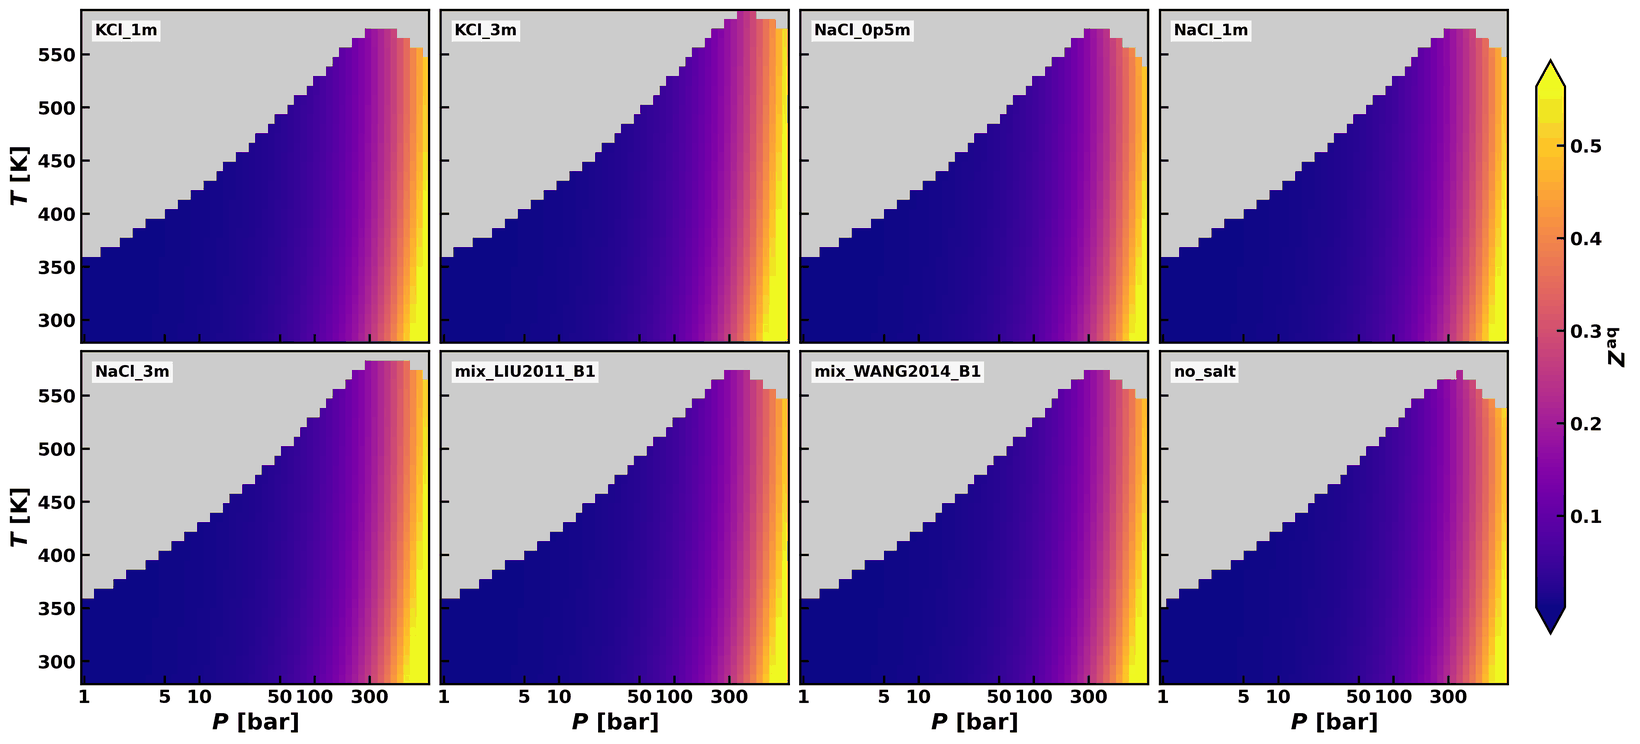

In [28]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/Z_aq_binary_CO2_surface.png')


<a id="sfigS13"></a>

**Figure S13.** Aqueous-phase compressibility factor $Z^{aq}$ for the binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ feed at $z_{\mathrm{CO_{2}}} = 0.50$. The strong pressure dependence at fixed $T$ reflects the density-dependent salt-corrected SRK contribution.

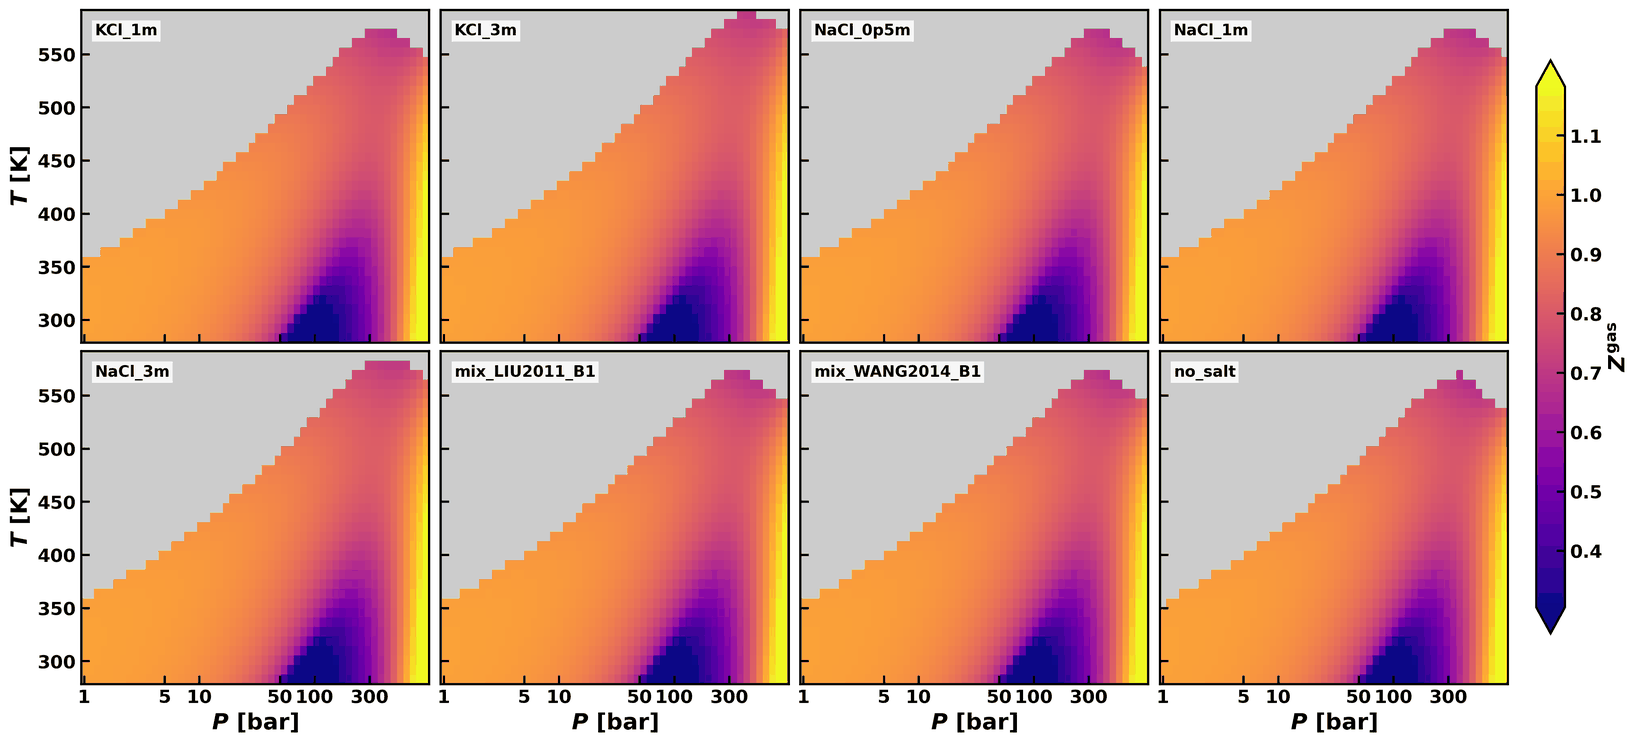

In [29]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/Z_gas_binary_CO2_surface.png')


<a id="sfigS14"></a>

**Figure S14.** Same as Fig. S13 for the gas-phase compressibility $Z^{gas}$. The supercritical transition is visible as the sharp high-$T$/high-$P$ rise in each panel.

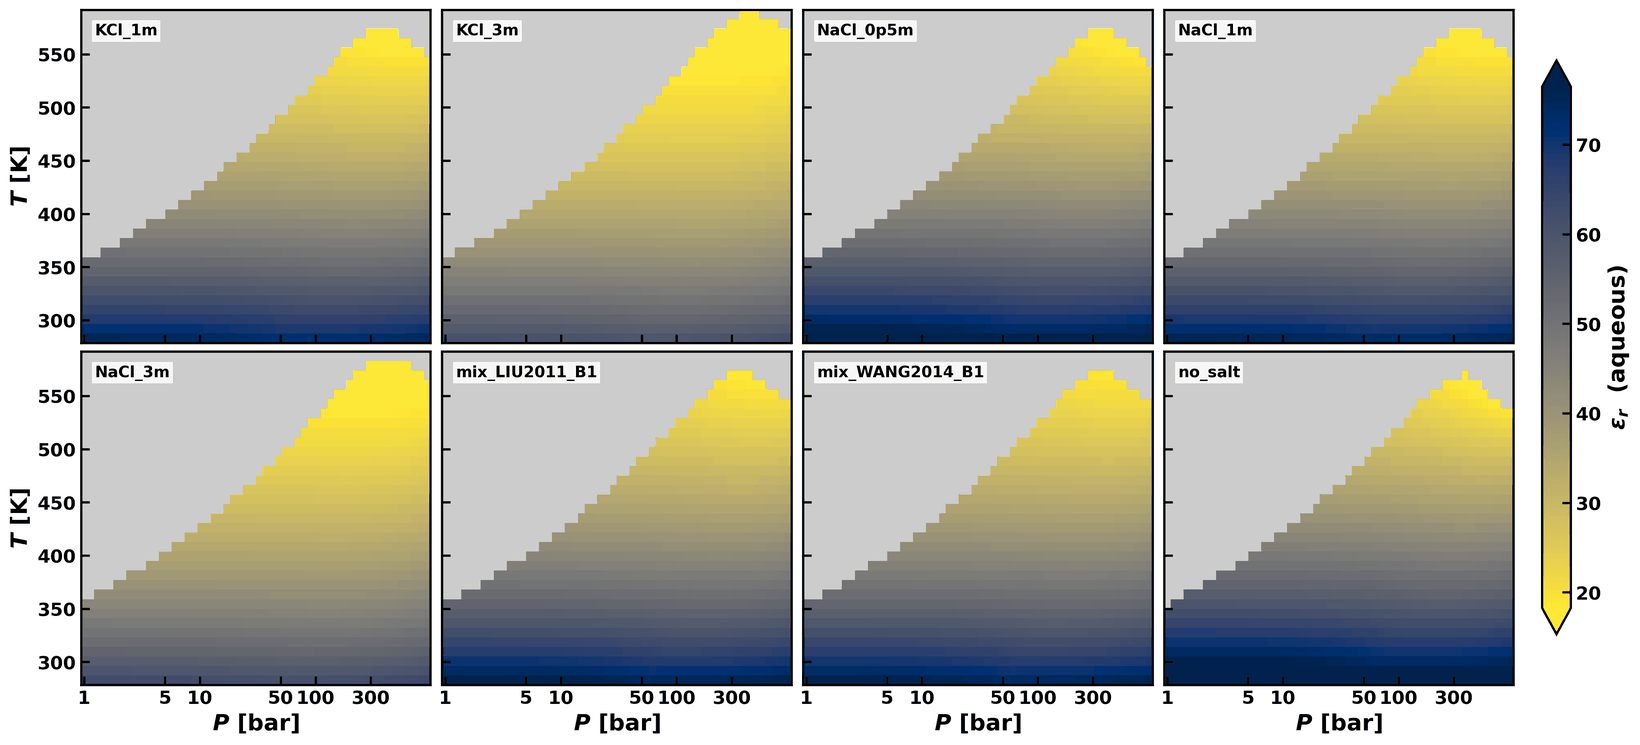

In [30]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/eps_r_binary_CO2_surface.png')


<a id="sfigS15"></a>

**Figure S15.** Aqueous-phase static relative permittivity $\varepsilon_r$ from the self-consistent Maribo-Mogensen / Kirkwood formulation of Moortgat et al.<sup>[1](#sref1)</sup>. $\varepsilon_r$ decreases monotonically with $T$ and is depressed by salt content at fixed $(T, P)$.

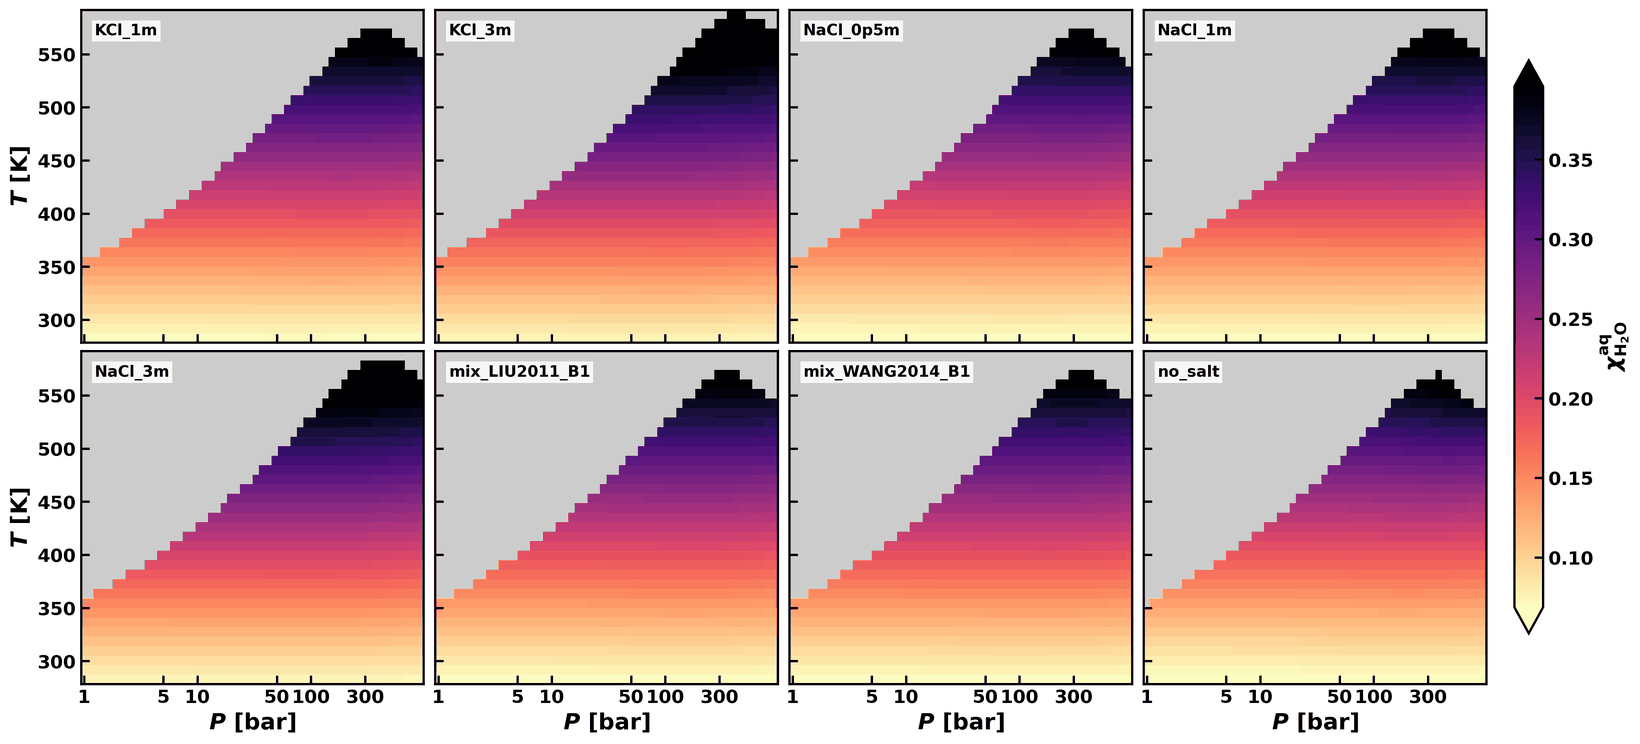

In [31]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/chi_H2O_aq_binary_CO2_surface.png')


<a id="sfigS16"></a>

**Figure S16.** Aqueous $\mathrm{H_{2}O}$ Wertheim association fraction $\chi_{\mathrm{H_{2}O}}^{aq}$. Higher values correspond to a higher fraction of $\mathrm{H_{2}O}$ molecules *not* engaged in hydrogen-bonded association. Ionic shielding by the 3 m brines suppresses the association (raising $\chi$); the no-salt and dilute-brine panels show the largest associated fraction at all $T$.

<a id="ssecS9_5"></a>

### S9.5 Salting-out by ionic strength

The ion-specific salting-out behavior of the main text is most compactly shown by plotting the predicted aqueous-phase $\mathrm{CO_{2}}$ solubility against the total ionic strength $I_c = \tfrac{1}{2}\sum_i m_i z_i^2$ of the brine at a fixed $(T, P)$ point. Figure S17 shows this comparison at 318.8 K and 103 bar, and Fig. S18 at 426.2 K and 290 bar.


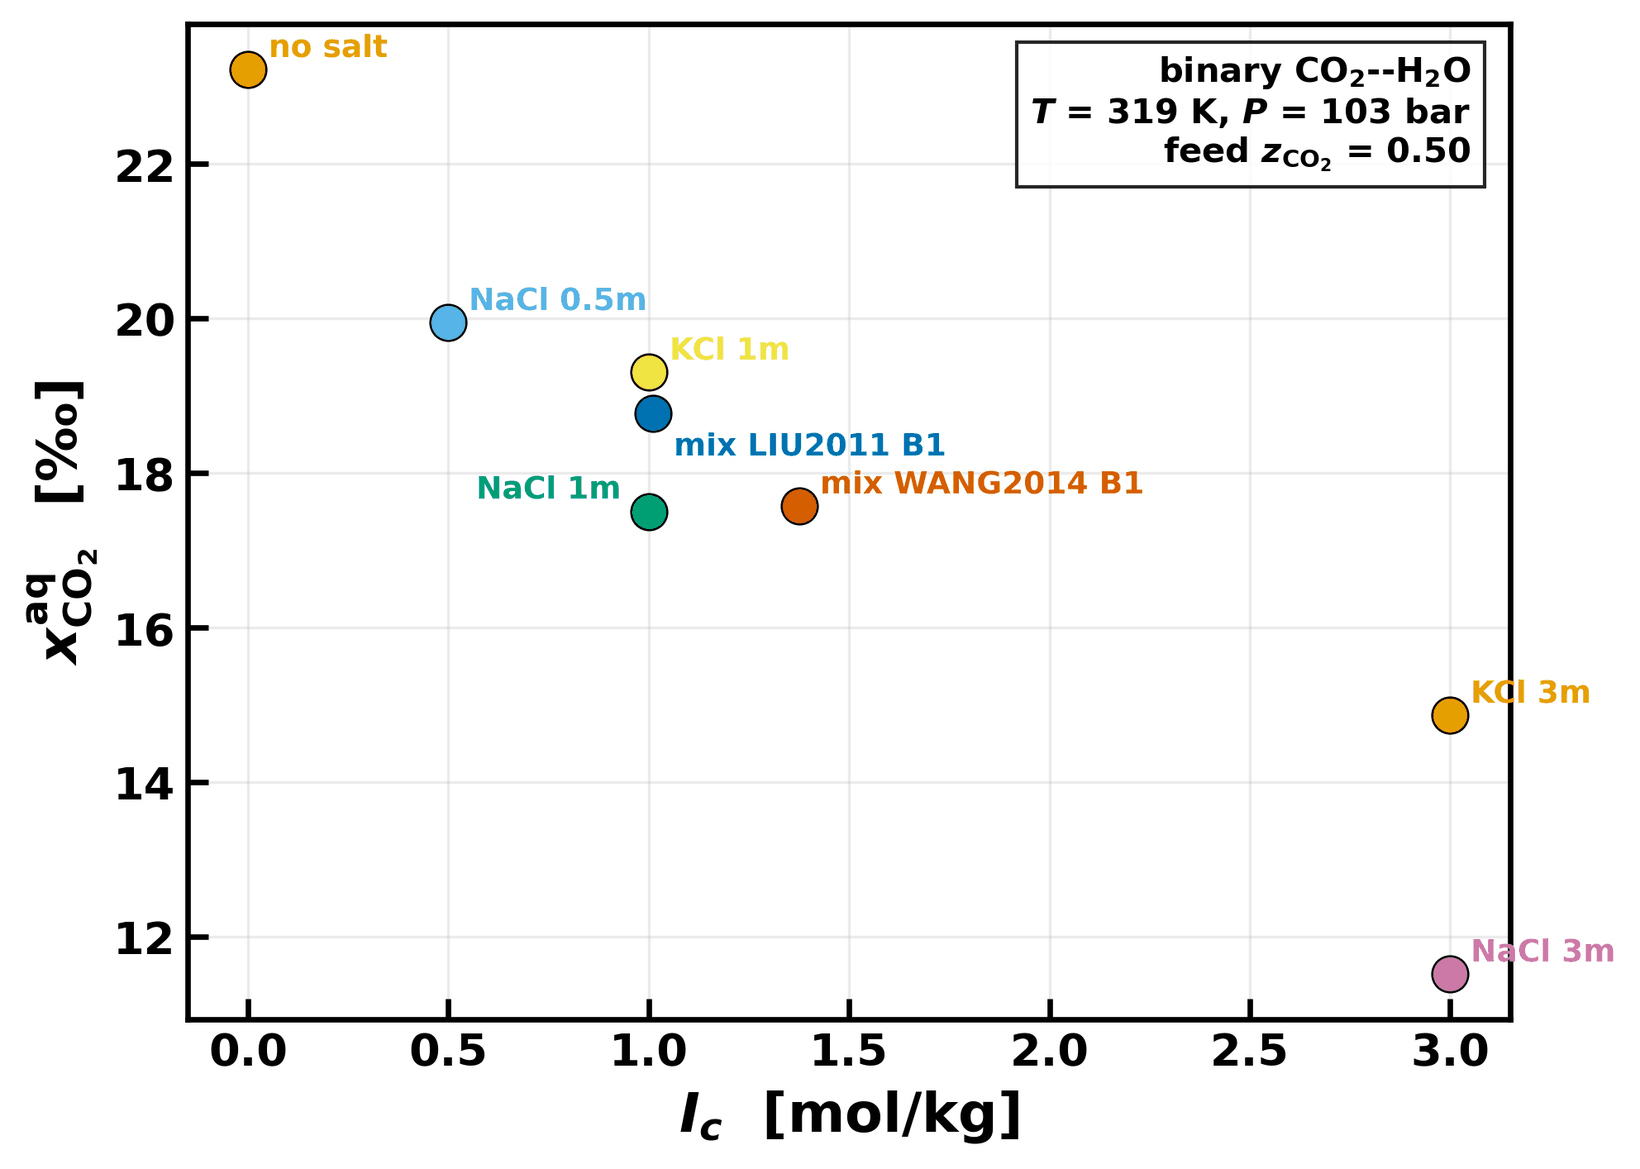

In [32]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/salting_out_T319K_P103bar.png')


<a id="sfigS17"></a>

**Figure S17.** Aqueous $\mathrm{CO_{2}}$ solubility in per-mil at $T = 318.8$ K, $P \approx 103$ bar (the nearest dense-grid point to the reservoir-shallow reference condition $T = 323$ K, $P = 100$ bar) versus the brine ionic strength $I_c$, one point per salt configuration. The ion-specific signal is clear at fixed $I_c$: at $I_c = 1$ mol/kg, $\mathrm{KCl}$\_1m gives 19.3  while $\mathrm{NaCl}$\_1m gives 17.5 . Mixed brines (Liu 2011 B1, Wang 2014 B1) fall onto the same $I_c$-dependent envelope.

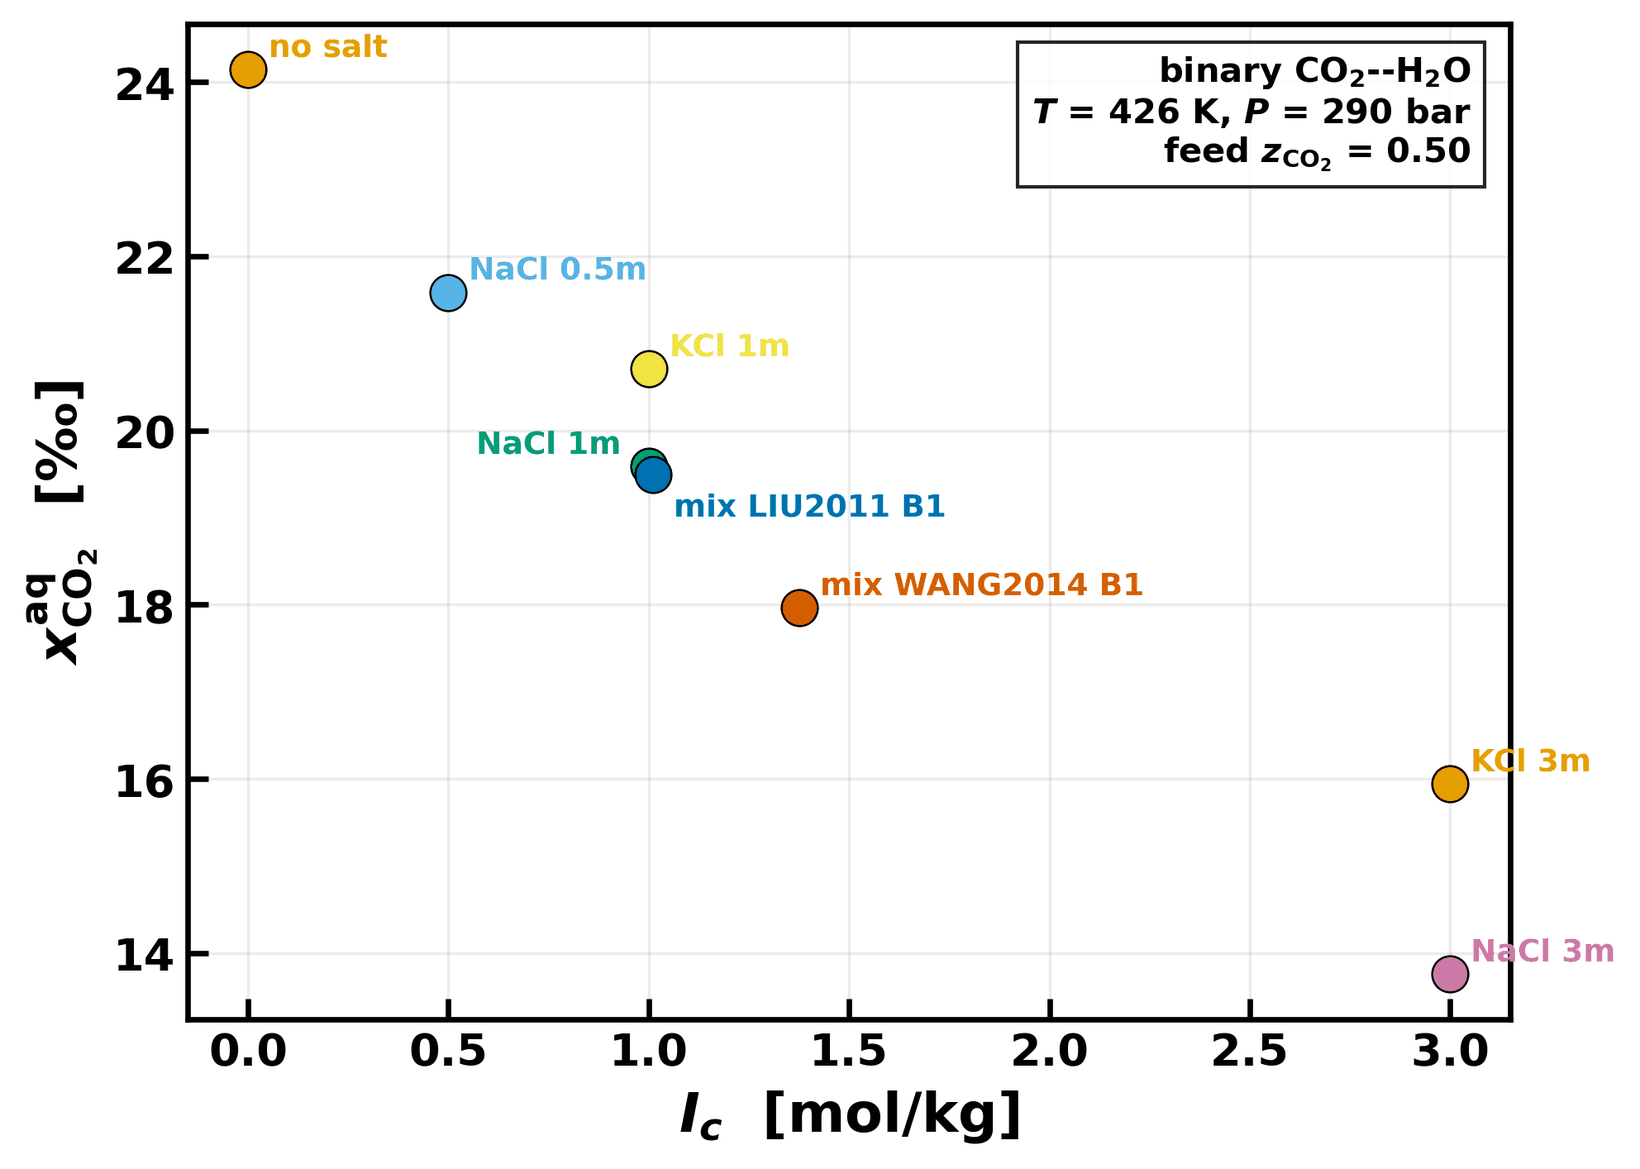

In [33]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/salting_out_T426K_P290bar.png')


<a id="sfigS18"></a>

**Figure S18.** Same as Fig. S17 at $T = 426.2$ K, $P \approx 290$ bar (nearest dense-grid point to $T = 423$ K, $P = 300$ bar, representative of mid-depth reservoir conditions). At the higher temperature the baseline solubility rises and the absolute ion-specific spread between $\mathrm{NaCl}$ and $\mathrm{KCl}$ grows, while the relative salting-out fraction stays comparable.

<a id="ssecS10"></a>

## S10 Setschenow calibrations for ethane and propane

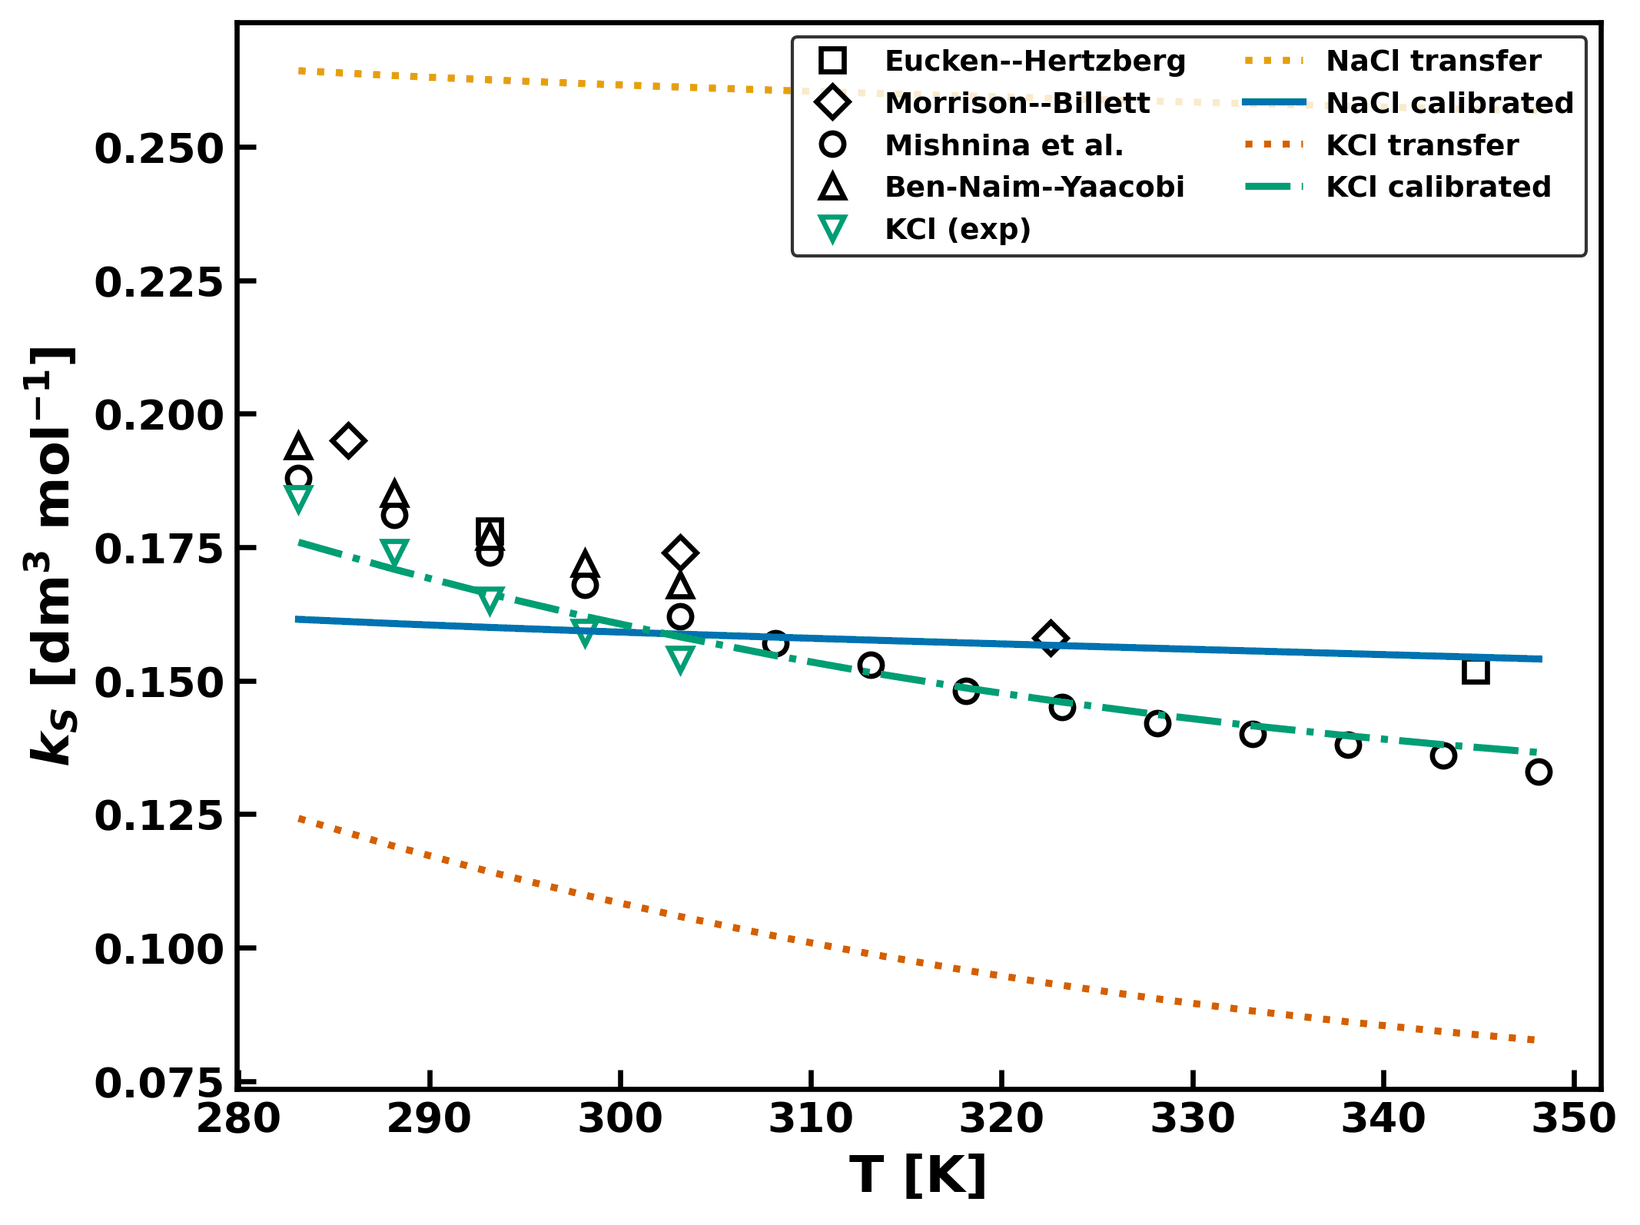

In [34]:
run('pilot_studies/c2_pilot_2026_08/c2_fig_split.py', long=())
show('c2_setschenow_SI.png')


<a id="sfigS19"></a>

**Figure S19.** Setschenow constants $k_S(T)$ for $\mathrm{C_{2}H_{6}}$ in $\mathrm{NaCl}$ and $\mathrm{KCl}$ (molarity basis): evaluated experimental data<sup>[6](#sref6)</sup> (symbols), the $\mathrm{CH_{4}}$-transfer prediction (dotted), and the two-parameter calibration ($s_{\mathrm{NaCl}} = 0.722$, $s_{\mathrm{K}} = 1.398$; solid and dash-dotted).

Figures S19 and S20 display the salting-out data behind the ethane and propane ion-energy scales of main-text Section 3.2, together with the pure $\mathrm{CH_{4}}$-transfer prediction (which fails in opposite directions for $\mathrm{Na^{+}}$ and $\mathrm{K^{+}}$ for both gases) and the calibrated two-scale models. The corresponding scale factors and their data sources are given in main-text Table 2 and its footnotes.


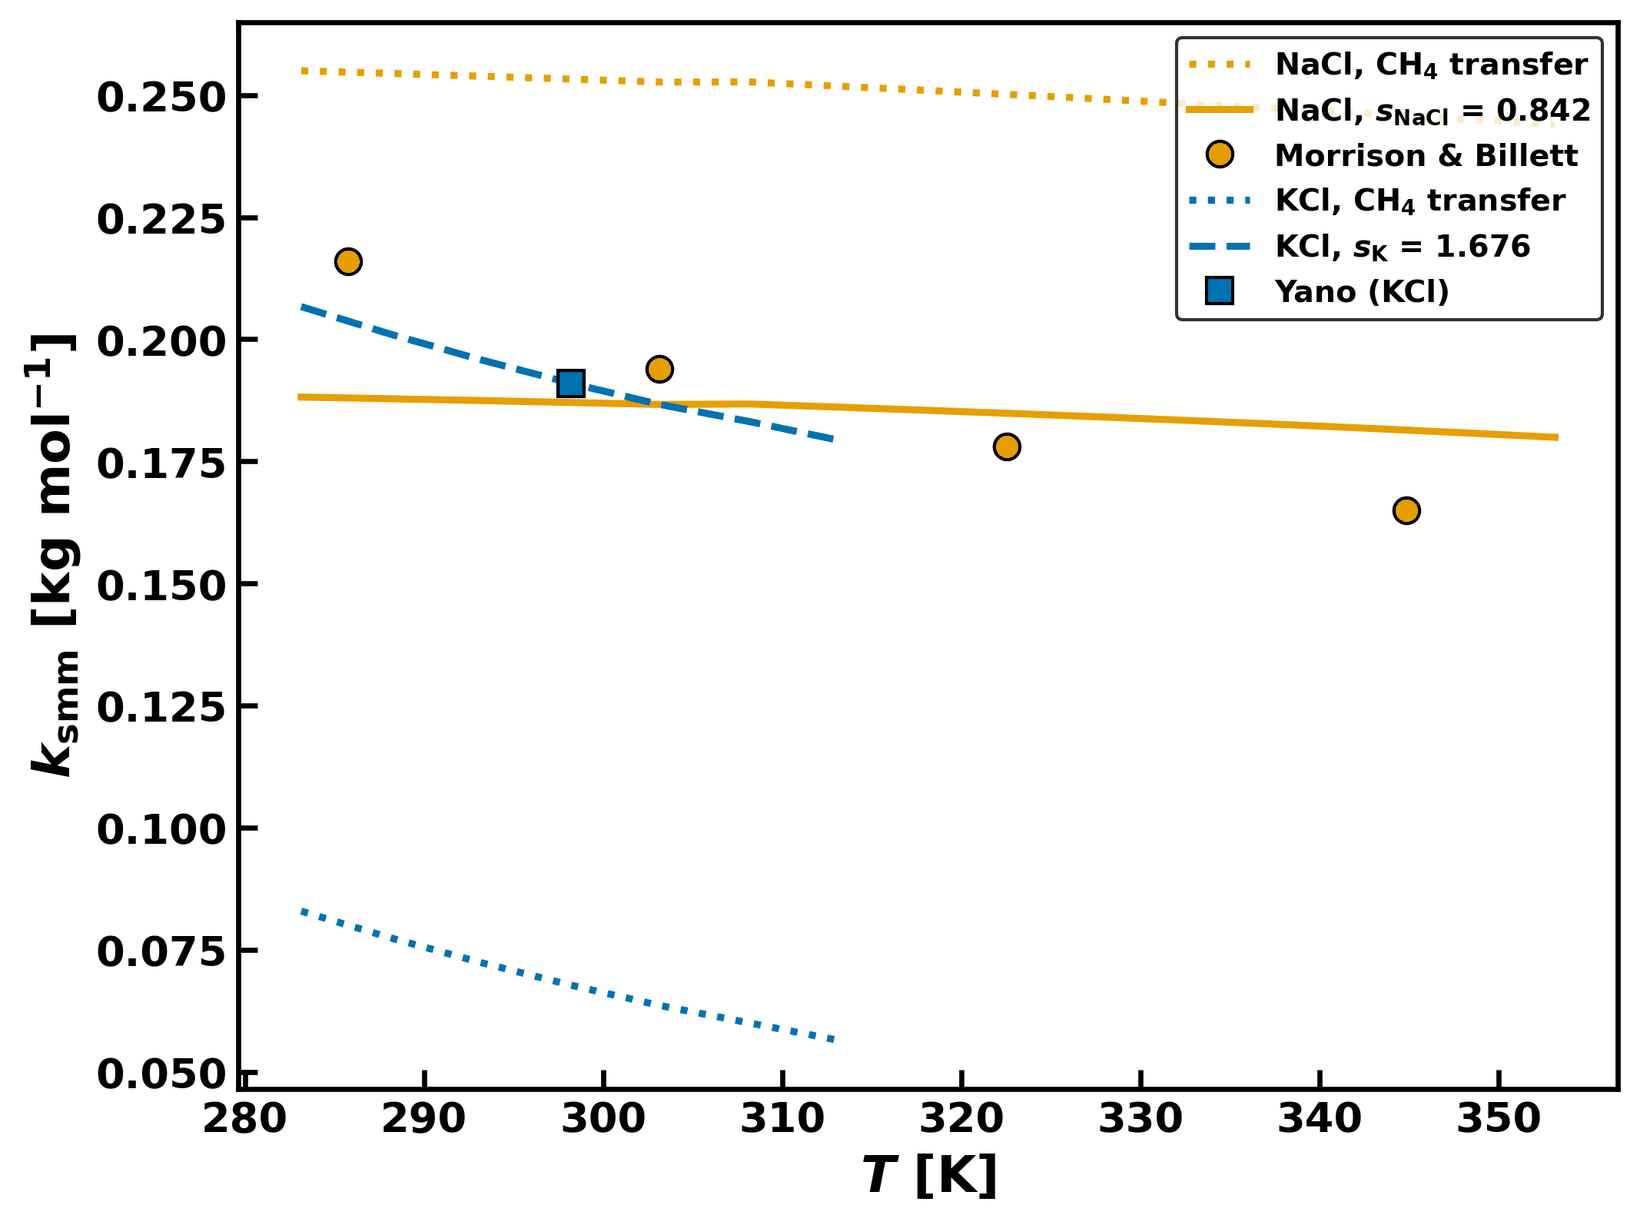

In [35]:
run('pilot_studies/c3_pilot_2026_08/c3_fig_final.py', long=())
show('c3_setschenow_SI.png')


<a id="sfigS20"></a>

**Figure S20.** Setschenow constants $k_{\mathrm{smm}}(T)$ for $\mathrm{C_{3}H_{8}}$ in $\mathrm{NaCl}$ and $\mathrm{KCl}$ (gas-molality basis): experimental data<sup>[7](#sref7),[8](#sref8)</sup> (symbols), the $\mathrm{CH_{4}}$-transfer prediction (dotted), and the two-scale calibration ($s_{\mathrm{NaCl}} = 0.842$, $s_{\mathrm{K}} = 1.676$; solid and dashed). The $\mathrm{KCl}$ scale is calibrated to the single-temperature datum and provides no independent test.

<a id="ssecS11"></a>

## S11 Ethane and propane in brine

Here we give the detail behind the $\mathrm{C_{2}H_{6}}$ and $\mathrm{C_{3}H_{8}}$ entries of Table 3 of the main text, summarized in Section 3.2 there. Both gases fall outside the gas–ion transfer class that $\mathrm{N_{2}}$ validated, so each takes one gas–water binary parameter fitted here and two scale factors on the transferred gas–ion energies.

Ethane probes the limits of both routes. Its $\mathrm{C_{2}H_{6}}$–$\mathrm{H_{2}O}$ binary parameter takes the same quadratic form of Eq. (3) of the main text and is fitted to 104 salt-free solubility points spanning $283$–$444$ K and $4$–$685$ bar: the two Culberson–McKetta data sets as compiled and evaluated in the IUPAC Solubility Data Series<sup>[6](#sref6),[18](#sref18),[19](#sref19)</sup> and the low-temperature measurements of Mohammadi et al.<sup>[24](#sref24)</sup>. The fit gives an overall AARE of 7.3% (3.7% on the high-pressure set), which is the level of the data’s own internal consistency: near $311$–$313$ K the two low-pressure sources disagree by roughly 20%, and Mao et al.<sup>[23](#sref23)</sup> report about 7% as the experimental uncertainty itself (Fig. S21).


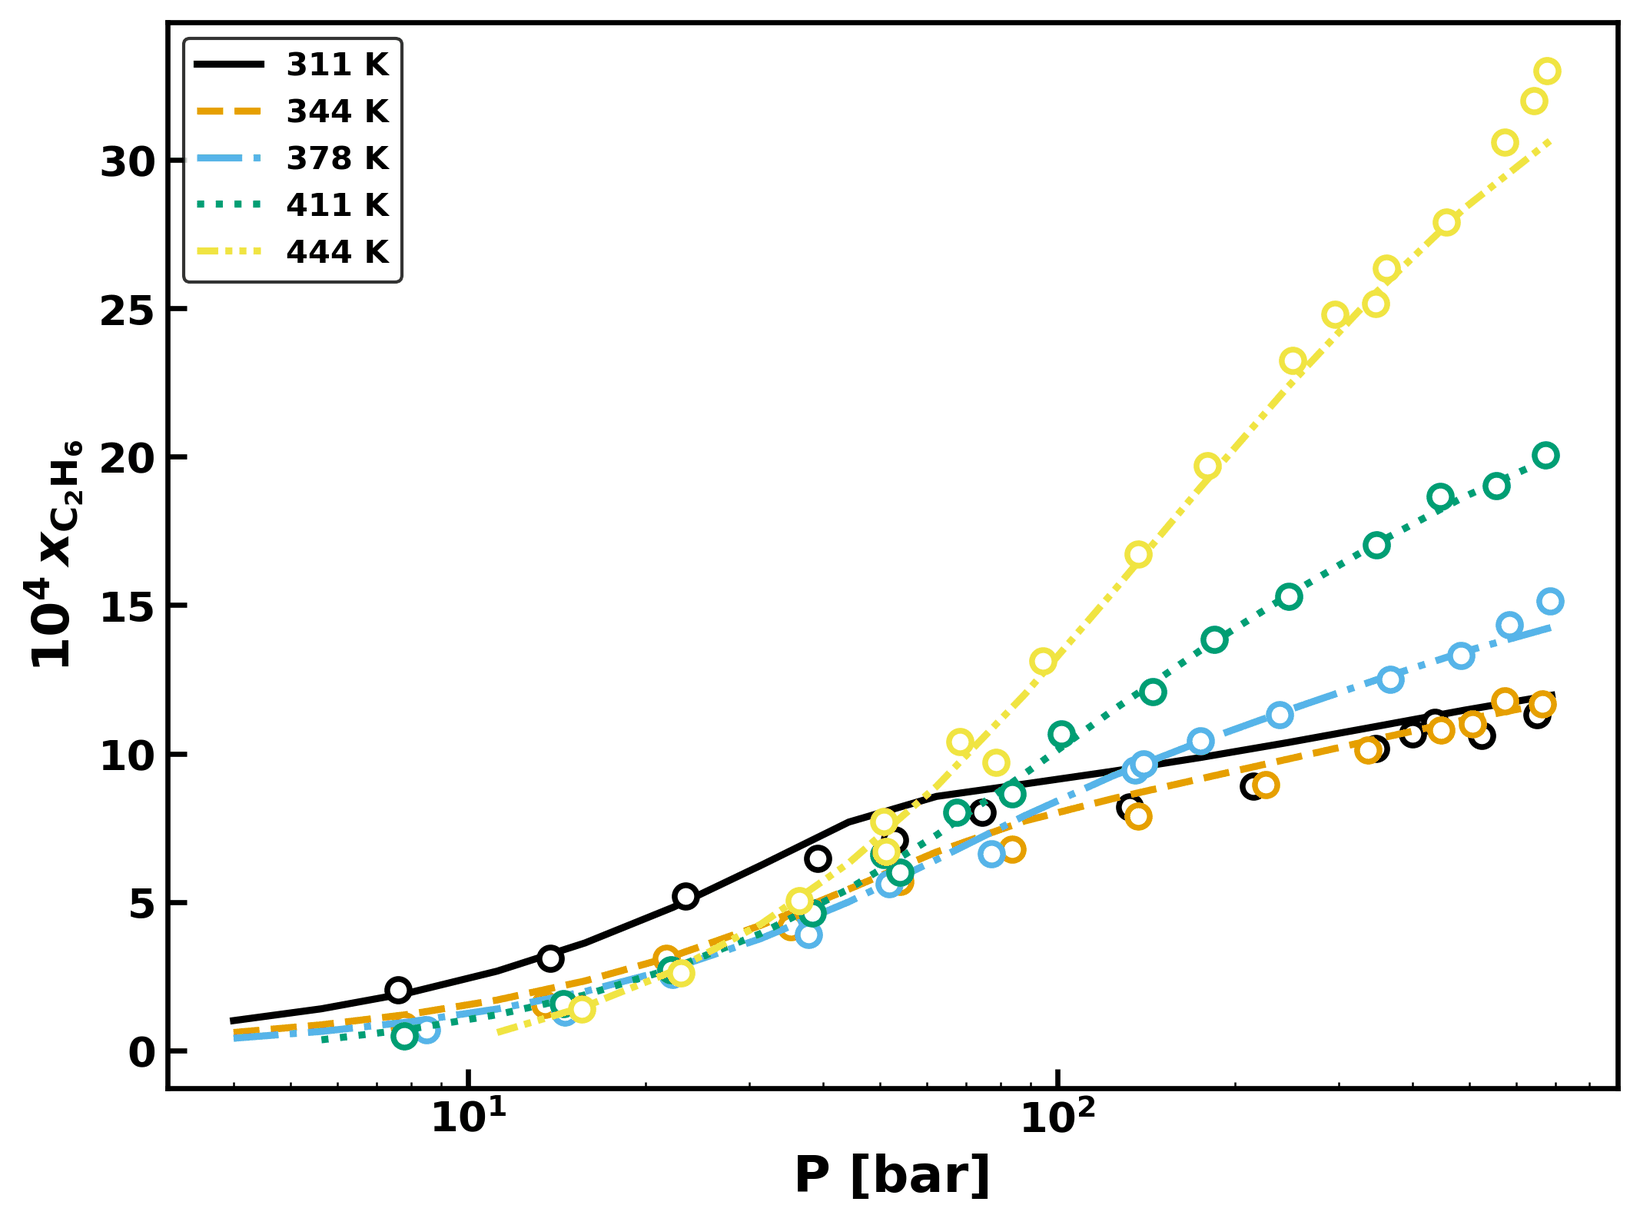

In [36]:
run('pilot_studies/c2_pilot_2026_08/c2_fig_split.py', long=())
show('c2_binary_main.png')


<a id="sfigS21"></a>

**Figure S21.** $\mathrm{C_{2}H_{6}}$ solubility in water: ms-eCPA with the fitted quadratic $k_{ij}(T)$ (lines) versus the Culberson–McKetta data<sup>[18](#sref18),[19](#sref19)</sup> (symbols) at five isotherms. The fit also uses the low-temperature data of Mohammadi et al.<sup>[24](#sref24)</sup>. The Setschenow calibration behind the ethane ion-energy scales is shown in Fig. S19.

For the gas–ion energies, ethane falls outside the transfer class that $\mathrm{N_{2}}$ validated. The same function-preserving $T_c$ rescale of the $\mathrm{CH_{4}}$ energies that predicts $\mathrm{N_{2}}$ salting-out with no fit to nitrogen-in-brine data misses the evaluated ethane Setschenow constants<sup>[6](#sref6)</sup> in *opposite directions*: $+63\%$ for $\mathrm{NaCl}$ and $-33\%$ for $\mathrm{KCl}$ at $298$ K (dotted curves in Fig. S19). No single rescale can repair both, and the failure is physically plausible: ethane’s polarizability is nearly twice methane’s (Table 2 of the main text), so its dispersion interactions with the ions are not a scaled copy. Ethane therefore enters with fitted gas–ion energies, at the smallest cost the data support: one factor scaling the transferred ($\mathrm{Na^{+}}$, $\mathrm{Cl^{-}}$) pair ($s_{\mathrm{NaCl}} = 0.722$) and one scaling $\mathrm{K^{+}}$ ($s_{\mathrm{K}} = 1.398$). Both are fitted to the 19 evaluated atmospheric-pressure Setschenow constants of the IUPAC series<sup>[6](#sref6)</sup> (Table S1); the $\mathrm{KCl}$ constants among them are those of Ben-Naim and Yaacobi<sup>[25](#sref25)</sup>. The temperature dependence of both remains a prediction: with the calibrated scales, ms-eCPA reproduces the $\mathrm{KCl}$ constant to 2.3% with the measured slope and the $\mathrm{NaCl}$ constant to 7.7%, though with a flatter slope than the evaluated correlation (Fig. S19). The remaining ions use the transferred energies as untested estimates — we found no ethane solubility data for their brines at any pressure, the ethane–brine database consisting of atmospheric-pressure measurements in two salts — so all high-pressure ethane–brine behavior is a declared prediction.

Propane extends the sequence one member further, with a better data situation than ethane’s on both sides of the fit. Its binary parameter, in the same quadratic form, is fitted to 175 salt-free points: the smoothed propane-in-water tables of Kobayashi<sup>[21](#sref21),[22](#sref22)</sup>, spanning $289$–$428$ K and $7$–$207$ bar and crossing the three-phase locus onto the liquid-propane branch, and the low-temperature measurements of Chapoy et al.<sup>[17](#sref17)</sup>. The fit reproduces the two sources to 2.8% and 1.0% (2.4% pooled, Fig. S22) — two laboratories half a century apart, agreeing with each other and with ms-eCPA. Both binary coefficient sets were regressed with an earlier version of the flash; the deviations quoted in this section and in Table 3 of the main text are the same coefficients re-evaluated with the version used throughout this work. The difference is confined to low-pressure points near the water dew line: the high-pressure ethane set, the Mohammadi and Chapoy data, and all Setschenow deviations are unchanged to the digits shown.


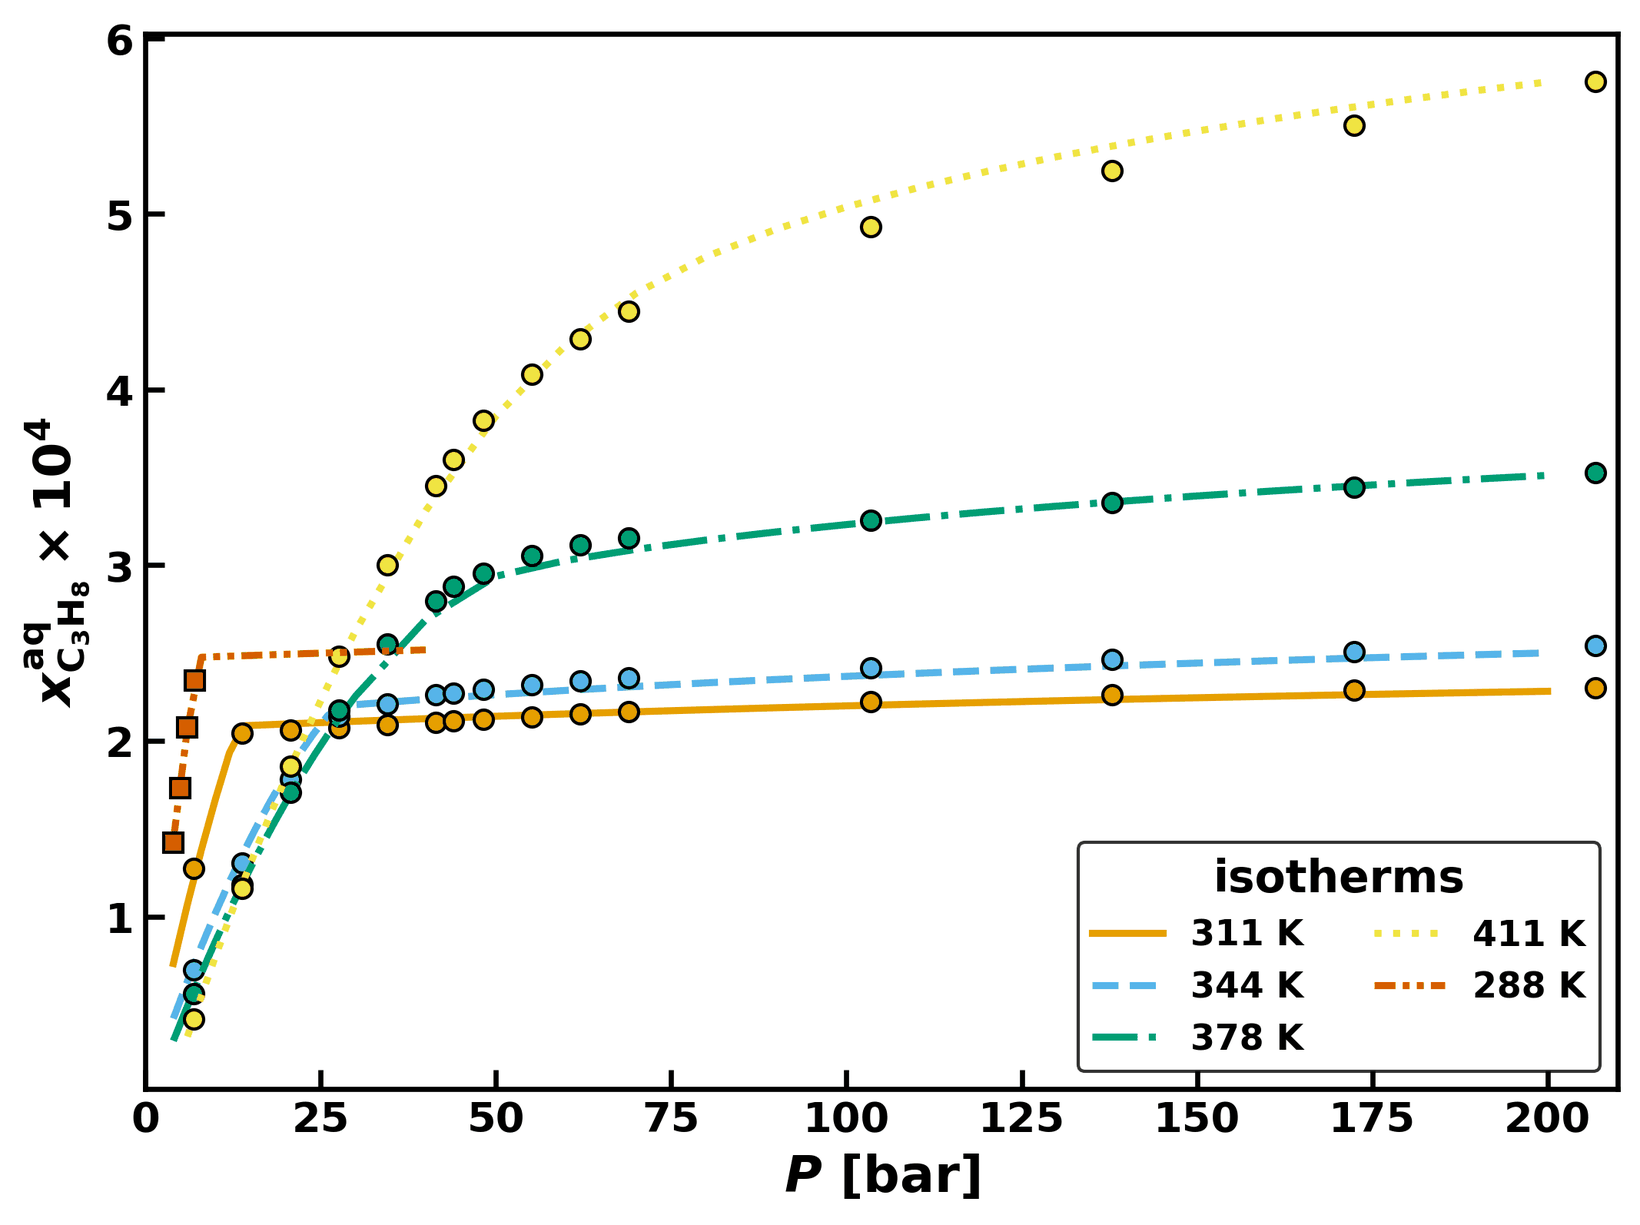

In [37]:
run('pilot_studies/c3_pilot_2026_08/c3_fig_final.py', long=())
show('c3_binary_main.png')


<a id="sfigS22"></a>

**Figure S22.** $\mathrm{C_{3}H_{8}}$ solubility in water: ms-eCPA with the fitted quadratic $k_{ij}(T)$ (lines) versus the smoothed data of Kobayashi<sup>[21](#sref21),[22](#sref22)</sup> (circles) and the measurements of Chapoy et al.<sup>[17](#sref17)</sup> (squares, 288 K). The kink in each low-temperature isotherm marks the three-phase pressure, beyond which the coexisting propane-rich phase is a liquid and the solubility becomes nearly pressure-independent. The Setschenow calibration behind the propane ion-energy scales is shown in Fig. S20.

For the gas–ion energies, propane confirms — and sharpens — the transfer boundary that ethane exposed. The function-preserving $T_c$ rescale of the $\mathrm{CH_{4}}$ energies misses the evaluated Setschenow constants<sup>[20](#sref20)</sup> in opposite directions once again: $+34\%$ for $\mathrm{NaCl}$ and $-64\%$ for $\mathrm{KCl}$ at $298$ K (dotted curves in Fig. S20). Across the homologous series the breakdown grows with the departure of the solute’s polarizability from methane’s (1.9$\times$ for ethane, 2.7$\times$ for propane), turning the single ethane observation into a trend: gas–ion transfer from $\mathrm{CH_{4}}$ without brine fitting is reliable within the small-nonpolar class that $\mathrm{N_{2}}$ validated, and degrades systematically beyond it. Propane enters with the same two-scale calibration: $s_{\mathrm{NaCl}} = 0.842$, fitted to the four-temperature $\mathrm{NaCl}$ set of Morrison and Billett<sup>[7](#sref7)</sup> that the IUPAC evaluation prefers for its self-consistency, reproduces it with a mean deviation of $-0.7\%$ and an AAD of 7.6%, again with a flatter temperature slope; $s_{\mathrm{K}} = 1.676$ matches the single $\mathrm{KCl}$ datum of Yano et al.<sup>[8](#sref8)</sup> by construction — one datum, one parameter, a calibration and not a test. No propane data exist for $\mathrm{Ca^{2+}}$, $\mathrm{Mg^{2+}}$ or $\mathrm{SO_{4}^{2-}}$ brines at any pressure<sup>[20](#sref20)</sup>, so those ions use the unscaled transfer as untested estimates and all high-pressure propane–brine behavior is a declared prediction.


<a id="ssecS12"></a>

## S12 Ternary $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$: statistics and $k_{hc}$

Table S9 resolves the deviations of Fig. 5 of the main text by isotherm and by measured view, for both of the solver routes available for these states. The first is the stability-and-flash pipeline, in which we retry the flash at several total gas feed fractions; this is the route used for the figure. In the second, we solve the two-phase equilibrium directly at the experiment’s own independent variable, $Y_{\mathrm{CO_{2}}}$, the water-free $\mathrm{CO_{2}}$ mole fraction in the gas phase, so that no feed assumption enters. All 34 measured states converge on both routes. The 323 K set of Al Ghafri and co-workers is included here although it is not plotted in the main text.


<a id="stabS9"></a>

**Table S9.** Average absolute relative error (%) of the ternary predictions, by isotherm and measured view. Upper block: stability-and-flash route (as plotted). Lower block: direct two-phase solve at the measured $Y_{\mathrm{CO_{2}}}$. $N$ is the number of measured values of that view at that temperature; the 344 K source does not report the gas-phase water content. The 323 K isotherm is not plotted in Fig. 5 of the main text.

In [38]:
import json
import pandas as pd

if nbtools.RUN_LONG:   # otherwise use the shipped results in results_cache/
    run("reproduce/ternary_stats.py")
res = json.load(open("results_cache/ternary_stats.json"))
VIEWS = ["x_CH4_aq", "x_CO2_aq", "y_H2O_gas"]
SRC = {"323": "Al Ghafri et al. (2014)", "344": "Dhima et al. (1999)", "376": "Qin et al. (2008)",
       "423": "Al Ghafri et al. (2014)", "plotted": "Plotted isotherms (344, 376, 423 K)", "all": "All states"}
rows = []
for route, title in (("stability_flash", "Stability-and-flash route (as plotted)"),
                     ("direct", "Direct two-phase solve at the measured Y_CO2")):
    for g, r in res[route].items():
        row = {"group": title, "T (K)": g if g.isdigit() else "", "Source": SRC[g]}
        for v in VIEWS:
            row[f"{v} N"] = r[v]["N"] or "—"
            row[f"{v} AARE"] = f"{r[v]['AARE']:.1f}" if r[v]["AARE"] is not None else "—"
        rows.append(row)
show_table(pd.DataFrame(rows))


For reference, ms-eCPA, evaluated on the salt-free binary databases restricted to the ternary’s window (320–430 K, 20–1000 bar; 267 and 171 rows, all converged), reproduces the solubility to 5.25% for $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ ($n = 219$) and 6.96% for $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ ($n = 156$), and the gas-phase water content to 14.53% ($n = 63$) and 21.39% ($n = 121$). The binary gas-phase water content is low by 13.5% and 15.2% in signed mean, and the bias concentrates at the cold edge of the window: near 323 K the binary deviations are 38.9% ($n = 10$) and 28.1% ($n = 30$), with every point low. The ternary gas-phase water deviation at 323 K is inherited from that binary behavior rather than produced by the second gas.

The only parameter in ms-eCPA that couples the two gases directly is the constant $k_{hc} = 0.080$ (Table S3). Re-solving all 34 states with $k_{hc}$ set to $0$, $0.5 k_{hc}$ and $2 k_{hc}$, with the direct two-phase solve throughout, changes the aqueous $\mathrm{CH_{4}}$ and gas-phase water deviations by at most one percentage point across the whole range (Table S10). The aqueous $\mathrm{CO_{2}}$ view is the one that responds, improving monotonically with increasing $k_{hc}$; the tabulated value is the one fitted to $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$ binary data and is not the value that would best fit these ternary data. Over the full swing from $0$ to $2 k_{hc}$ the predicted quantities themselves move, on average and at most, by 3.7% and 13.0% (aqueous $\mathrm{CH_{4}}$), 7.0% and 27.5% (aqueous $\mathrm{CO_{2}}$), and 1.4% and 4.2% (gas-phase water), each relative to the prediction at the tabulated value. The ternary agreement is therefore set mainly by the two water–gas binaries and by the composition dependence of the ms-eCPA EoS, not by the gas–gas parameter.


<a id="stabS10"></a>

**Table S10.** Average absolute relative error (%) against the 34 measured ternary states with $k_{hc}$ perturbed from its tabulated value, direct two-phase solve. $N = 34$, 34 and 25 for the three views.

In [39]:
import json
import pandas as pd

if nbtools.RUN_LONG:   # otherwise use the shipped results in results_cache/
    run("reproduce/ternary_stats.py")
res = json.load(open("results_cache/ternary_stats.json"))
VIEWS = ["x_CH4_aq", "x_CO2_aq", "y_H2O_gas"]
name = {"0": "0", "0.5": "0.5 k_hc", "1": f"k_hc = {res['k_hc']:.3f} (tabulated)", "2": "2 k_hc"}
show_table(pd.DataFrame([{"k_hc": name[k], **{v: f"{r[v]['AARE']:.1f}" for v in VIEWS}}
                         for k, r in res["k_hc_scan"].items()]))


k_hc,x_CH4_aq,x_CO2_aq,y_H2O_gas
0,12.0,13.7,33.1
0.5 k_hc,12.1,12.2,32.9
k_hc = 0.080 (tabulated),12.5,10.6,32.8
2 k_hc,13.5,8.4,32.5


<a id="ssecS13"></a>

## S13 $\mathrm{CH_{4}}$/$\mathrm{CO_{2}}$ selectivity in single-salt brines

In a brine environment, the relative solubility of $\mathrm{CH_{4}}$ and $\mathrm{CO_{2}}$ in the aqueous phase depends on both the gas-phase composition (water-free) and on the ionic composition of the brine. The ms-eCPA-predicted gas solubility in each single-salt brine at 323 K and 300 bar as a function of the water-free $\mathrm{CO_{2}}$ concentration in the gas phase is plotted in Fig. S23. The trend is consistent across all salts: $\mathrm{CO_{2}}$ is preferentially extracted into the brine relative to $\mathrm{CH_{4}}$, and the magnitude of the salting-out effect varies systematically with the ion charge and identity. This ion-specific selectivity is precisely the property that the multi-salt parameterization is designed to capture. Figure S23 is a prediction: we hold no mixed-gas solubility measurements in brine, in any salt, against which it could be scored. The ternary validation of Fig. 5 of the main text is salt-free. The second gas component also costs only a modest amount of extra computation; the per-family iteration counts and wall times on the dense sweep are quantified in Section 3.5 of the main text.


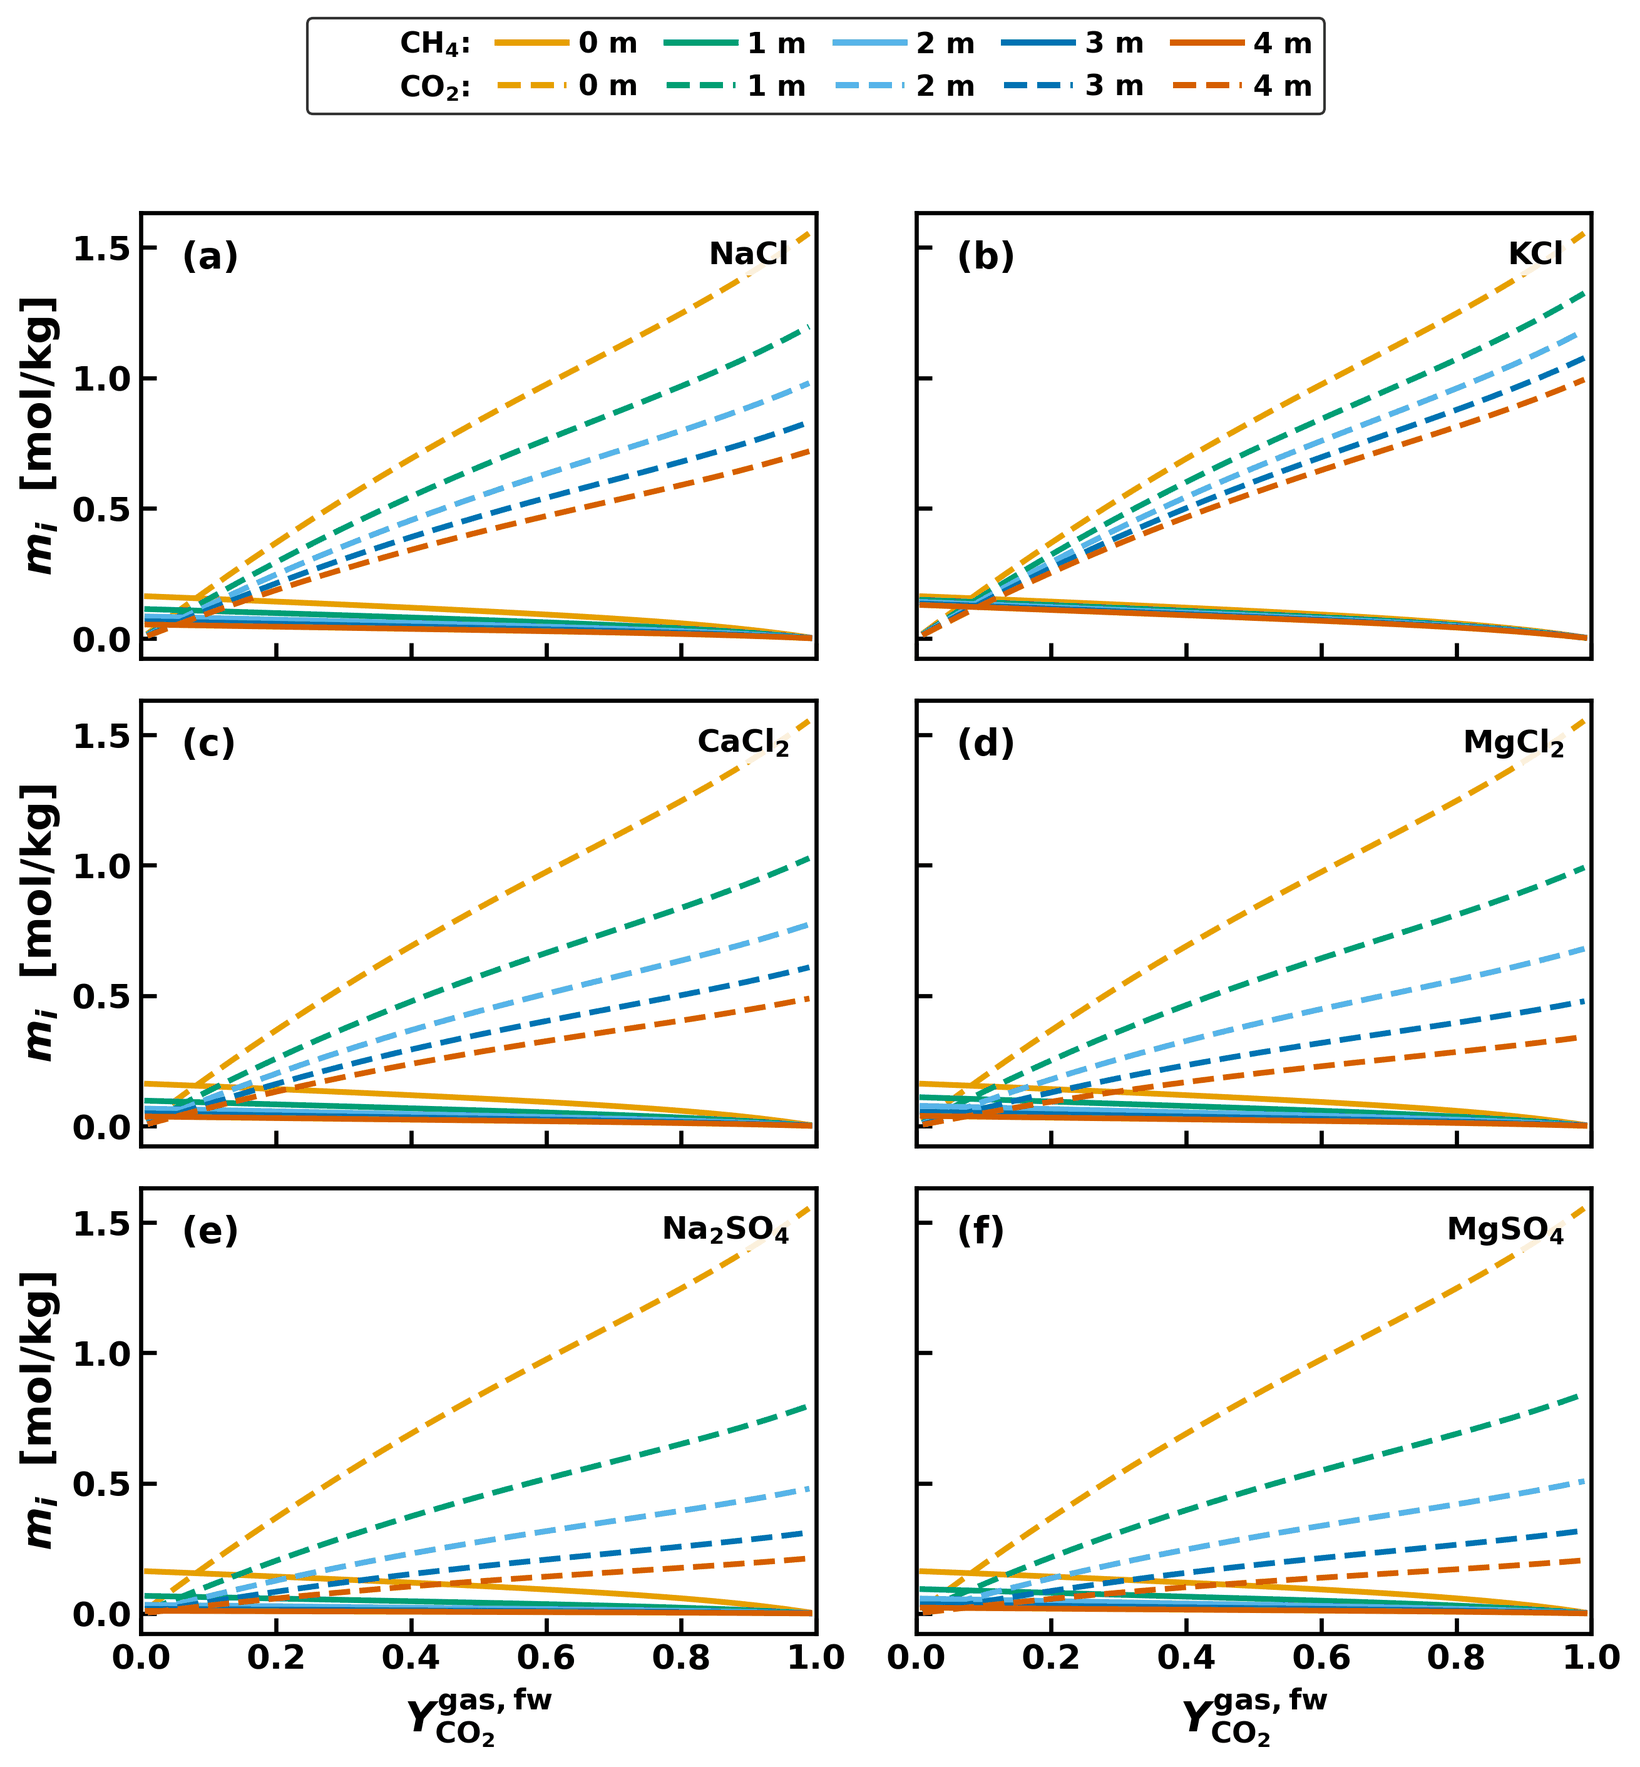

In [40]:
run('scripts/fig_ccb_ternary.py')
show('ccb_ternary_SI.png')


<a id="sfigS23"></a>

**Figure S23.** ms-eCPA prediction of $\mathrm{CH_{4}}$ and $\mathrm{CO_{2}}$ solubility in each single-salt brine at 323 K and 300 bar as a function of the water-free $\mathrm{CO_{2}}$ fraction in the gas phase.

<a id="ssecS14"></a>

## S14 Efficiency and robustness analyses

In this section, we catalog the convergence and per-call cost profile of the multi-salt stability-plus-flash pipeline on a dense $(T, P, \mathbf{z}, \mathbf{m}_i)$ grid. Temperature is sampled at 39 isotherms uniformly spaced from $283$ to $623$ K, pressure at 60 log-spaced values from $1$ to $\approx 2000$ bar (restricted at run time to $P \le 1000$ bar), and composition on three feeds per feed family. The binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ and $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ feeds use $z_{\text{gas}} \in \{0.25, 0.50, 0.75\}$, with $z_{\mathrm{H_{2}O}}$ fixed by closure; the ternary $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ feed uses the three permutations of $(z_{\mathrm{H_{2}O}}, z_{\mathrm{CH_{4}}}, z_{\mathrm{CO_{2}}})
= (0.490, 0.255, 0.255)$. Salt configurations are no-salt, three $\mathrm{NaCl}$ brines at $0.5$, $1$, and $3$ mol/kg, two $\mathrm{KCl}$ brines at $1$ and $3$ mol/kg, and two mixed brines (B1 of<sup>[9](#sref9)</sup> and<sup>[10](#sref10)</sup>). Each of the resulting $151\,632$ $(T, P, \mathbf{z}, \mathbf{m}_i)$ states is evaluated by the eight-trial tangent-plane-distance stability test of Section 2.2 of the main text followed (where the stability test classifies the feed as two-phase) by the accelerated $K$-value flash with Newton polish of Section 2.3 of the main text. Every state converged. In the near-miscibility corner (binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ around $516$ K, $329$ bar), $K$-value initializations based on the feed converge to the trivial solution $K = 1$. For such states, we seed $K_i$ from the ratio of the converged gas-side and aqueous-side stability-trial compositions. Wall-clock numbers in this section are end-to-end stability$+$flash times for one call. The sweep ran as a SLURM array job on 48-core nodes. Each array task used a whole node, with its 48 CPUs and all of its memory, and ran one single-threaded worker process per core. Every call was therefore executed on a single core and timed with `time.perf_counter` inside its own worker. Summed over the $151\,632$ states, the per-call times amount to about 91 core-hours. The nodes use Intel Xeon Platinum 8260 (Cascade Lake) processors at $2.40$ GHz with at least $185$ GB of memory, under Red Hat Enterprise Linux 8.10, with Python 3.12.6, NumPy 1.26.4, SciPy 1.14.1, pandas 2.2.2 and PyArrow 17.0.0. These are Python reference timings. Absolute times depend on many factors unrelated to the algorithm: the language, the compiler and its optimization flags, library versions and threading, the processor and its dynamic clock boost, and the load on the node. They are therefore hard to reproduce and to compare between studies. The more informative results are the iteration counts, which do not depend on the machine, and the relative cost of the stages measured on the same machine. For a compiled implementation, what remains valid is the distribution of cost within the pipeline — stability dominant, flash cheap — rather than the absolute values. The three-phase timing test quoted in Section 3.5 of the main text was run separately, on an Apple M4 laptop (10 cores, 16 GB of memory) under macOS 15 with CPython 3.11 and eight worker processes, so its medians are not comparable with the numbers of this section. The companion Section S9 presents the physical predictions obtained on the same grid.

A remark that applies to every per-salt $(T, P)$ map in this section and in Section S9: the single-phase mask’s boundary appears identical across the salt panels. It is not — the boundary shifts with salinity by the vapor-pressure-lowering factor $a_w$ at its steam-side edge — but even at 6 mol kg$^{-1}$ $\mathrm{NaCl}$ that shift (24%) is less than two steps of the 13.7% logarithmic pressure grid, so the boundary moves by at most two grid cells, at a handful of $(T, P)$ locations only (quantified in Section S9.2, Fig. S9).


<a id="ssecS14_1"></a>

### S14.1 Performance summary

<a id="stabS11"></a>

**Table S11.** Mean per-call wall-clock time and mean accelerated-$K$-value SSI iteration count, aggregated by feed family. “2-ph” is the percentage of $(T, P, \mathbf{z}, \mathbf{m}_i)$ states classified as two-phase by the Michelsen tangent-plane test. The 95th-percentile column gives the upper tail to characterise the cost of states near the two-phase boundary. Wall times are end-to-end per call (Michelsen stability through Newton polish) measured on a single core.

In [41]:
import pandas as pd

d = pd.read_parquet("results_cache/sweep/merged.parquet")   # the shipped flash-grid results
conv = d[d.converged]
FAMILY = {"binary_CH4": "binary CH₄–H₂O", "binary_CO2": "binary CO₂–H₂O",
          "ternary": "ternary CH₄–CO₂–H₂O"}
def perf(g):
    """Columns of Tables S11 and S12: the SSI count is averaged over ALL converged states."""
    return {"n": len(g), "2-ph (%)": f"{100 * (g.phases == 2).mean():.1f}",
            "mean t_call [ms]": f"{g.t_wall_ms.mean():.0f}", "t_call p95 [ms]": f"{g.t_wall_ms.quantile(0.95):.0f}",
            "mean N_SSI": f"{g.n_iter_ssi.mean():.1f}", "N_SSI p95": f"{int(g.n_iter_ssi.quantile(0.95))}"}
rows = [{"Feed family": FAMILY[f], **perf(g)} for f, g in conv.groupby("feed_family")]
rows.append({"Feed family": "Total", **perf(conv)})
show_table(pd.DataFrame(rows))


Feed family,n,2-ph (%),mean t_call [ms],t_call p95 [ms],mean N_SSI,N_SSI p95
binary CH₄–H₂O,50544,56.9,937,3699,3.3,8
binary CO₂–H₂O,50544,54.4,1634,12706,3.2,8
ternary CH₄–CO₂–H₂O,50544,50.5,3895,27531,3.3,10
Total,151632,53.9,2155,10685,3.3,9


<a id="stabS12"></a>

**Table S12.** Per-salt breakdown of the same metrics. Mean per-call wall times range from 422 to 6341 ms across the feed-family and salt combinations, a factor of about 15, and mean SSI iteration counts range from 3.1 to 3.9. For every salt the ternary feed is the most expensive family. In every feed family the 3 m brines ($\mathrm{NaCl}$, $\mathrm{KCl}$) are cheaper than the 0.5 and 1 m $\mathrm{NaCl}$ brines.

In [42]:
import pandas as pd

d = pd.read_parquet("results_cache/sweep/merged.parquet")   # the shipped flash-grid results
conv = d[d.converged]
FAMILY = {"binary_CH4": "binary CH₄–H₂O", "binary_CO2": "binary CO₂–H₂O",
          "ternary": "ternary CH₄–CO₂–H₂O"}
def perf(g):
    """Columns of Tables S11 and S12: the SSI count is averaged over ALL converged states."""
    return {"n": len(g), "2-ph (%)": f"{100 * (g.phases == 2).mean():.1f}",
            "mean t_call [ms]": f"{g.t_wall_ms.mean():.0f}", "t_call p95 [ms]": f"{g.t_wall_ms.quantile(0.95):.0f}",
            "mean N_SSI": f"{g.n_iter_ssi.mean():.1f}", "N_SSI p95": f"{int(g.n_iter_ssi.quantile(0.95))}"}
rows = [{"group": FAMILY[f], "Salt": s, **perf(g)} for (f, s), g in conv.groupby(["feed_family", "salt_name"])]
show_table(pd.DataFrame(rows))


Table S11 lumps the tangent-plane-distance stability test together with the $K$-value flash into a single per-call wall time. In a compositional reservoir simulator that keeps phase state between time steps, the stability test is typically skipped whenever the previous time step’s phase classification can be trusted, so the two costs behave very differently in practice. Table S13 therefore reports them separately. Averaged across all $151\,632$ converged states, the stability test costs $\bar{t}_{\text{stab}} \approx
1729$ ms per call and the flash $\bar{t}_{\text{flash}} \approx
426$ ms. Restricted to points classified as single-phase—where no flash is performed—the stability test costs an average of $3563$ ms. Restricted to two-phase points, the flash itself averages $790$ ms, against $163$ ms for the stability test at the same points.


<a id="stabS13"></a>

**Table S13.** Mean per-call wall time split between the Michelsen tangent-plane-distance stability test ($\bar{t}_{\text{stab}}$) and the accelerated $K$-value flash ($\bar{t}_{\text{flash}}$), aggregated across all $151\,632$ converged states. Over all states, the stability test is the dominant cost and, in a warm-started reservoir simulator, is skippable when the previous time step’s phase classification can be trusted; the flash cost is comparable to the per-cell EoS evaluation in a non-flash compositional simulator.

In [43]:
import pandas as pd

d = pd.read_parquet("results_cache/sweep/merged.parquet")   # the shipped flash-grid results
conv = d[d.converged]
FAMILY = {"binary_CH4": "binary CH₄–H₂O", "binary_CO2": "binary CO₂–H₂O",
          "ternary": "ternary CH₄–CO₂–H₂O"}
def split(g):
    two = g[g.phases == 2]
    return {"n": len(g), "mean t_stab [ms]": f"{g.t_stab_ms.mean():.0f}",
            "mean t_total [ms]": f"{g.t_total_ms.mean():.0f}",
            "mean t_flash, 2-ph [ms]": f"{two.t_flash_ms.mean():.0f}" if len(two) else "—",
            "mean N_SSI, 2-ph": f"{two.n_iter_ssi.mean():.1f}" if len(two) else "—"}
rows = [{"Feed family": FAMILY[f], **split(g)} for f, g in conv.groupby("feed_family")]
rows += [{"Feed family": "Total (all)", **split(conv)},
         {"Feed family": "   single-phase points", **split(conv[conv.phases == 1])},
         {"Feed family": "   two-phase points", **split(conv[conv.phases == 2])}]
show_table(pd.DataFrame(rows))


Feed family,n,mean t_stab [ms],mean t_total [ms],"mean t_flash, 2-ph [ms]","mean N_SSI, 2-ph"
binary CH₄–H₂O,50544,682,937,448,5.8
binary CO₂–H₂O,50544,1438,1634,359,6.0
ternary CH₄–CO₂–H₂O,50544,3066,3895,1642,6.6
Total (all),151632,1729,2155,790,6.1
single-phase points,69845,3563,3563,—,—
two-phase points,81787,163,953,790,6.1


In our flash, we run accelerated successive substitution (SSI, following the Jex 2024 acceleration scheme) until the log-fugacity residual $\max_i |g_i|$ falls below a switch tolerance of $10^{-4}$, and then switch to a Newton polish on $\ln K$ with a final tolerance of $10^{-8}$. The Newton step uses a forward-difference Jacobian on $\ln K$; an analytical Jacobian would require differentiating through the inner-Newton $(Z, \varepsilon_r, \chi_{\mathrm{H_{2}O}})$ solves and is not implemented here. To quantify the marginal value of the polish, we re-ran the identical grid with the switch tolerance tightened to $10^{-8}$, so that SSI always converges to the final tolerance without triggering the Newton polish. Table S14 compares the two runs on two-phase points, where the flash actually executes. Figures S24 and S25 map the SSI iteration count over $(T, P)$ for the ternary and the binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ feeds, and Fig. S26 maps the per-call wall time for the ternary feed.


<a id="stabS14"></a>

**Table S14.** Mean flash-side iteration counts and wall time per call for two-phase points, comparing accelerated SSI followed by forward-difference Newton polish (default) with pure accelerated SSI. NR polish reduces the outer SSI count by about 2.4 iterations on average, but each polish step, with a forward-difference Jacobian, costs somewhat more than the SSI iterations it saves, leaving pure SSI about 18% faster in wall time on this grid. (Recorded on the same grid with the pre-adoption parameter set; the relative SSI-versus- polish comparison is unaffected by the parameter update.) An analytical Jacobian would reduce the polish step cost and likely tip the balance in favour of SSI$+$NR; whether that implementation effort is warranted is left to the reader to judge based on the modest differences reported here.

<table style="border-collapse:collapse;border-top:2px solid;border-bottom:2px solid;font-size:90%;margin:0 0 1em 0;table-layout:auto;width:auto">
<tbody>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"></td>
<td style="padding:2px 8px;border:none;text-align:left">SSI + NR polish (default)</td>
<td style="padding:2px 8px;border:none;text-align:left">SSI only, no polish</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">Feed family</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>N̄</em><sub>SSI</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>N̄</em><sub>NR</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>t̄</em><sub>flash</sub></span> [ms]</td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>N̄</em><sub>SSI</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>N̄</em><sub>NR</sub></span></td>
<td style="padding:2px 8px;border:none;text-align:left"><span class="math inline"><em>t̄</em><sub>flash</sub></span> [ms]</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">binary <span class="math inline">CH<sub>4</sub></span>–<span class="math inline">H<sub>2</sub>O</span></td>
<td style="padding:2px 8px;border:none;text-align:left">5.7</td>
<td style="padding:2px 8px;border:none;text-align:left">1.00</td>
<td style="padding:2px 8px;border:none;text-align:left">820</td>
<td style="padding:2px 8px;border:none;text-align:left">7.8</td>
<td style="padding:2px 8px;border:none;text-align:left">0.05</td>
<td style="padding:2px 8px;border:none;text-align:left">671</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">binary <span class="math inline">CO<sub>2</sub></span>–<span class="math inline">H<sub>2</sub>O</span></td>
<td style="padding:2px 8px;border:none;text-align:left">5.8</td>
<td style="padding:2px 8px;border:none;text-align:left">1.00</td>
<td style="padding:2px 8px;border:none;text-align:left">422</td>
<td style="padding:2px 8px;border:none;text-align:left">7.9</td>
<td style="padding:2px 8px;border:none;text-align:left">0.05</td>
<td style="padding:2px 8px;border:none;text-align:left">344</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left">ternary <span class="math inline">CH<sub>4</sub></span>–<span class="math inline">CO<sub>2</sub></span>–<span class="math inline">H<sub>2</sub>O</span></td>
<td style="padding:2px 8px;border:none;text-align:left">6.6</td>
<td style="padding:2px 8px;border:none;text-align:left">1.00</td>
<td style="padding:2px 8px;border:none;text-align:left">1096</td>
<td style="padding:2px 8px;border:none;text-align:left">9.3</td>
<td style="padding:2px 8px;border:none;text-align:left">0.04</td>
<td style="padding:2px 8px;border:none;text-align:left">898</td>
</tr>
<tr>
<td style="padding:2px 8px;border:none;text-align:left"><strong>Total (all 2-phase)</strong></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>6.0</strong></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>1.00</strong></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>774</strong></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>8.3</strong></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>0.05</strong></td>
<td style="padding:2px 8px;border:none;text-align:left"><strong>633</strong></td>
</tr>
</tbody>
</table>


*Note on reproduction.* This comparison requires a second run of the full flash grid with the Newton polish switched off, whose results are not part of the release; the table is shown as published. The SSI + Newton run is the one behind Table 4 and Tables S11–S13, which this notebook recomputes.

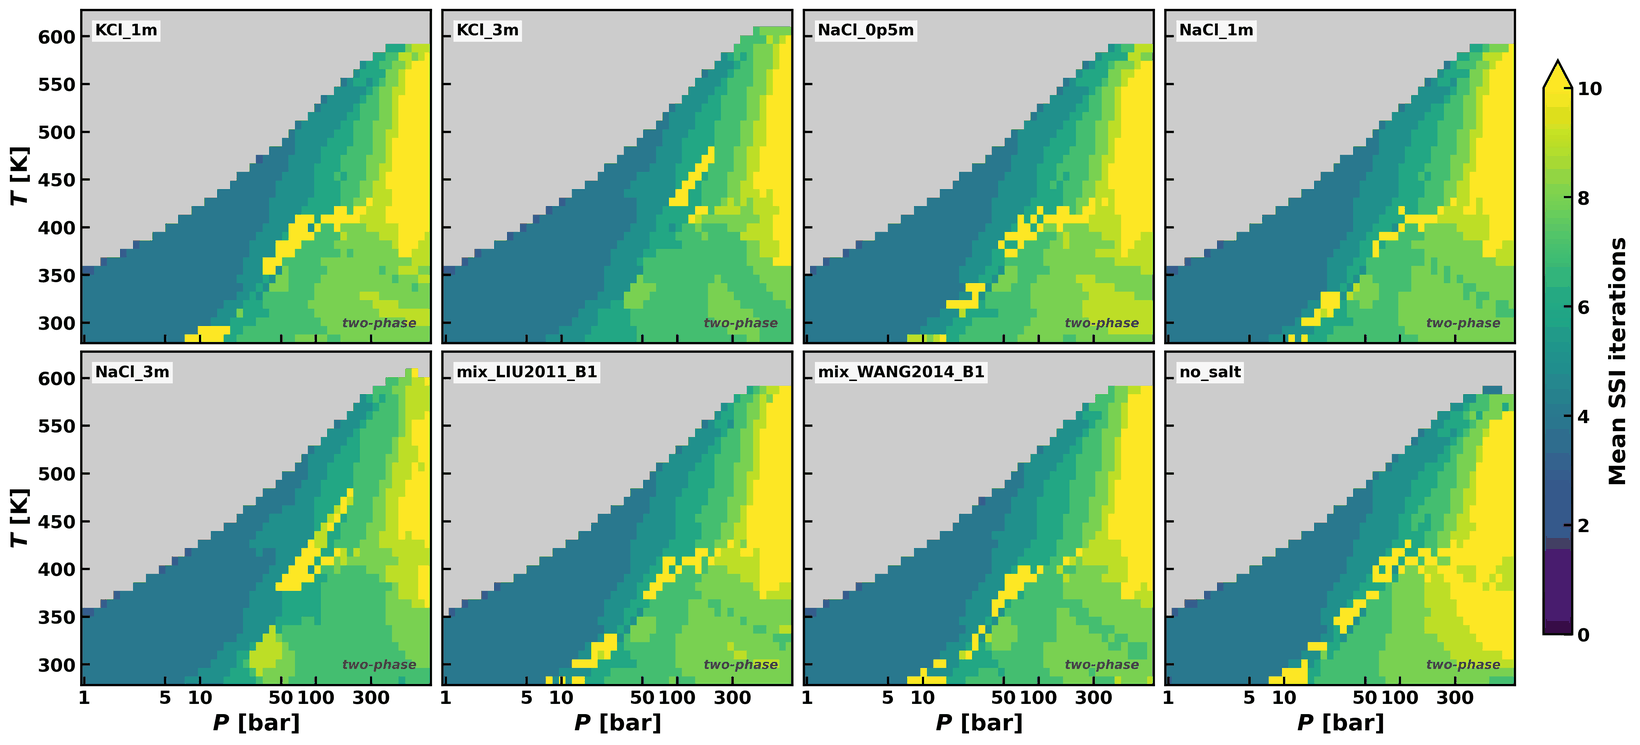

In [44]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/n_iter_ssi_ternary_heatmap.png')


<a id="sfigS24"></a>

**Figure S24.** Mean accelerated-$K$-value SSI iteration count for the ternary $\mathrm{CH_{4}}$–$\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ feed ($z \approx (0.49, 0.255, 0.255)$) over $(T, P)$, one panel per salt configuration. Grey cells mark single-phase states (no flash is performed there). Iteration counts cluster between about 5 and 12 across the two-phase region; 3 m brines ($\mathrm{KCl}$\_3m, $\mathrm{NaCl}$\_3m) and the mixed brines tend toward the upper end of that range.

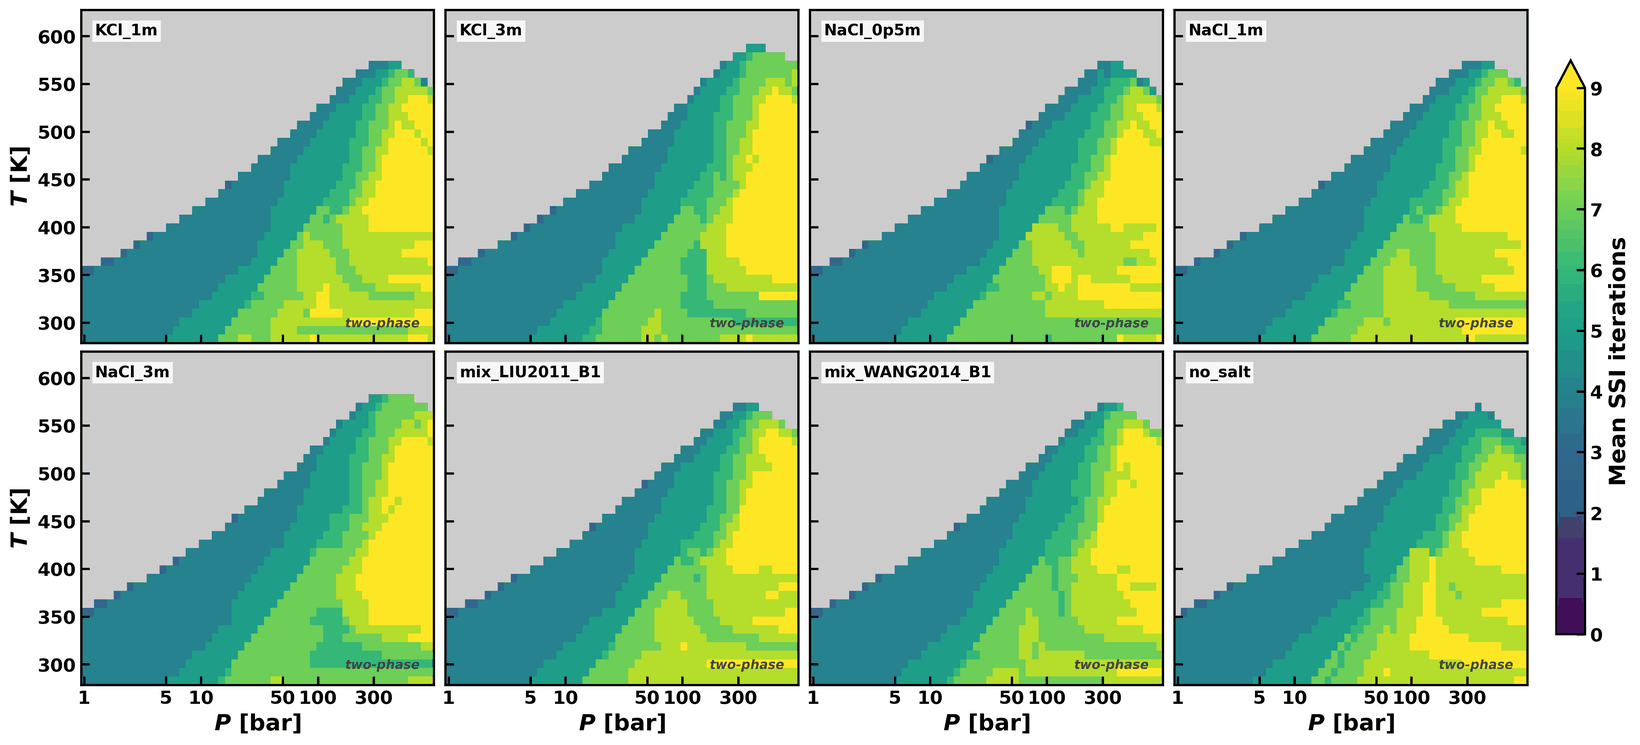

In [45]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/n_iter_ssi_binary_CO2_heatmap.png')


<a id="sfigS25"></a>

**Figure S25.** Same as Figure S24 for the binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ feed at $z_{\mathrm{CO_{2}}} = 0.50$. The classical two-phase wedge is clearly delineated by the grey single-phase region; inside the wedge iteration counts cluster around 5–8.

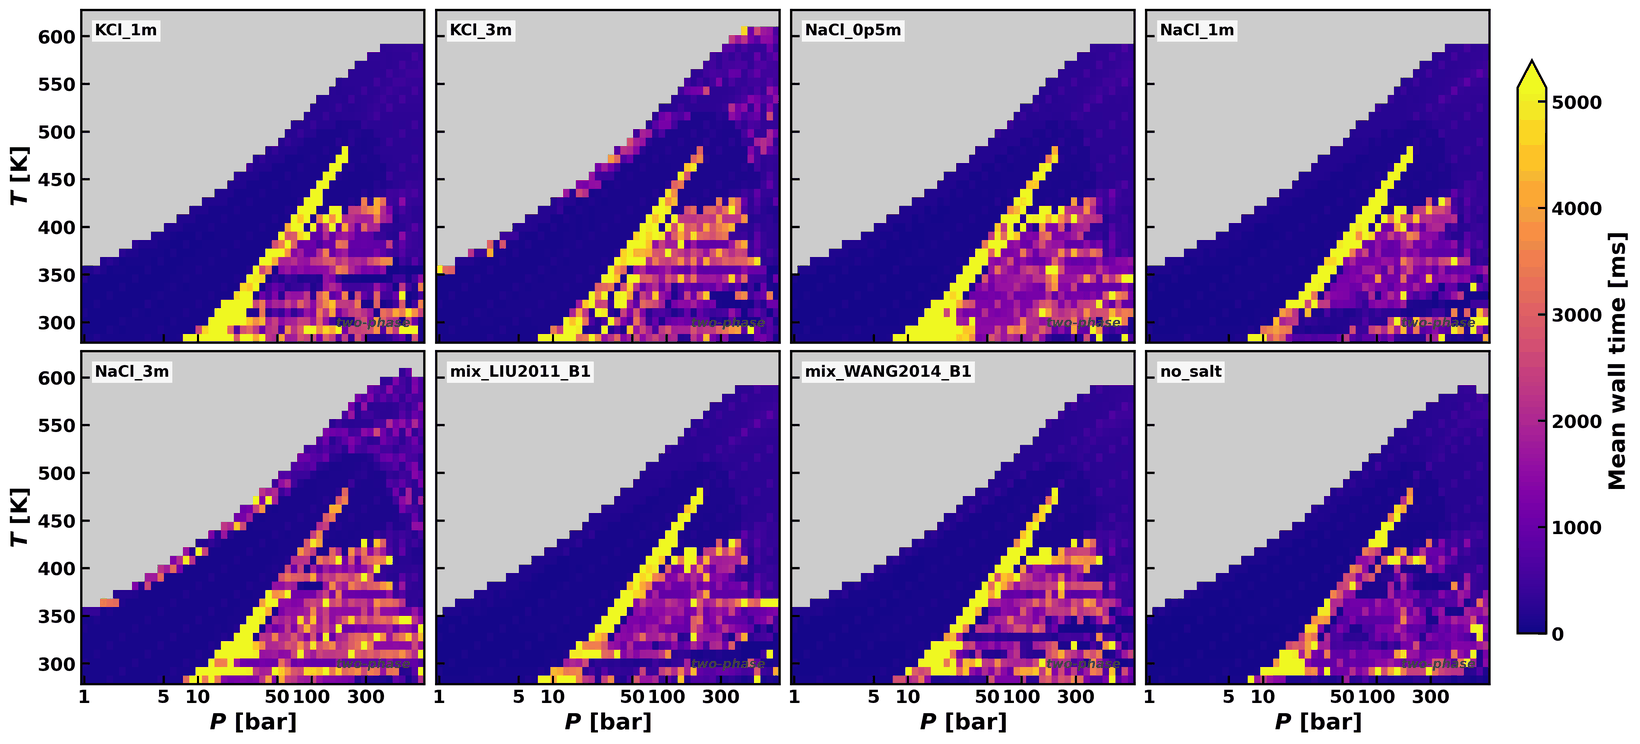

In [46]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/t_wall_ms_ternary_heatmap.png')


<a id="sfigS26"></a>

**Figure S26.** Mean per-call wall-clock time for the ternary feed at the same composition as Fig. S24, one panel per salt configuration. The dominant pattern is the high-$T$/high-$P$ corner, where the inner-Newton solution on the aqueous-phase compressibility, permittivity, and association fraction $(Z^{aq}, \varepsilon_r,          \chi_{\mathrm{H_{2}O}}^{aq})$ becomes most expensive because of the dense-fluid SRK contribution and the reduced hydrogen-bonding network.

<a id="ssecS14_2"></a>

### S14.2 Sensitivity of the classification to the TPD thresholds

Neither the hard nor the soft threshold enters any equation of ms-eCPA. From the eight-trial search we obtain a stationary value $tm^\star$ computed without reference to either. The hard threshold decides only whether the feed is passed to the flash, and the soft threshold only how a feed is reported once the flash has returned no usable split. Their influence is therefore measured exactly by reclassifying the $tm^\star$ values recorded for all $151{,}632$ states of Section S14. Where a changed threshold passes new states to the flash, we also rerun those states.

The range of hard thresholds from $-0.02$ to zero affects $1{,}016$ states, $0.67\%$ of the grid. Of these, $740$ have $-0.02 < tm^\star \le -0.005$. All $740$ were passed to the flash under the production threshold of $-0.005$, and all $740$ converged to a two-phase split. The other $276$ have $-0.005 < tm^\star < 0$ and were classified single-phase without a flash. Setting the hard threshold to zero passes these $276$ states to the flash. We reran them through the stability test and flash of the current code with the hard threshold set to zero. Of the $276$, $270$ converge to a two-phase split, with a largest fugacity residual of $8.1\times10^{-9}$. The other $6$ return a split at $\beta = 1$ and are classified single-phase by the phase-fraction guard, and none fails. The $270$ splits are $0.18\%$ of the grid. Their vapor fraction $\beta$ ranges from $0.19$ to $0.9999$, with a median of $0.992$, so most of them have an aqueous phase fraction below $1\%$. Of the $270$, $227$ lie above $450$ K, and all lie between $355$ and $623$ K. At these $270$ states the production threshold reports a single phase although the flash finds a converged split. The rerun recomputes $tm^\star$ to within $1.3\times10^{-9}$ of the recorded values.

The distribution of $tm^\star$ is strongly bimodal. Scaling the hard threshold by ten in each direction gives the range $-0.05 < tm^\star \le -0.0005$, and only $2{,}345$ states ($1.55\%$) fall inside it. Of the remaining $149{,}287$, $79{,}691$ return $tm^\star \le -0.05$ and $69{,}596$ return a value above $-0.0005$. Of the latter, $69{,}569$ return $tm^\star = 0$ exactly. With the threshold at zero we count only states with $tm^\star < 0$, so these exact zeros do not cross it. Table S15 reports how many states cross the hard threshold when it is scaled by factors of two, five and ten in each direction, and when it is set to $-0.02$ or to zero. A tightening admits only states that were previously classified single-phase without being flashed, so it can add at most that many two-phase states. A loosening excludes only states that were previously two-phase, so it removes exactly that many. Against the $81{,}787$ two-phase states of the production run, a factor-of-two change therefore moves the two-phase fraction of the grid by at most $+0.09$ or exactly $-0.15$ percentage points.

Of the $2{,}345$ states in that range, $2{,}096$ were passed to the flash under the production threshold and all converged. Their 95th-percentile fugacity residual is $5.1\times10^{-9}$, against $1.0\times10^{-9}$ over all $81{,}787$ two-phase states, and both are inside the $10^{-8}$ convergence criterion. The remaining $249$ states in the range were classified single-phase and never flashed. Of the $2{,}345$ states, $1{,}993$ ($85.0\%$) lie above $450$ K, where the two-phase region is closing, and $167$ lie below $400$ K, against $54{,}432$ grid states in that temperature range.

The soft threshold is reached only after every flash initialization has failed to produce a usable split. All $69{,}845$ single-phase verdicts of the sweep come from the hard threshold alone. No state was passed to the flash and then returned single-phase, so the soft threshold classified no state of the grid.


<a id="stabS15"></a>

**Table S15.** States crossing the hard TPD threshold when it is varied about its production value of $-0.005$, over the $151{,}632$-state grid of Section S14. A tightening (upper rows) bounds the two-phase states that can be added; a loosening (lower rows) gives the two-phase states removed. At zero, only states with $tm^\star < 0$ are counted.

In [47]:
import json
import pandas as pd

if nbtools.RUN_LONG:   # re-runs the 276 states between the production threshold and 0
    run("reproduce/threshold_sensitivity.py", long=("--rerun",))
else:
    run("reproduce/threshold_sensitivity.py")
res = json.load(open("results_cache/sweep/threshold_sensitivity.json"))
label = {"zero": "0", "div10": "−0.0005 (÷ 10)", "div5": "−0.0010 (÷ 5)", "div2": "−0.0025 (÷ 2)",
         "production": "−0.0050 (production)", "x2": "−0.0100 (× 2)", "x4": "−0.0200 (× 4)",
         "x5": "−0.0250 (× 5)", "x10": "−0.0500 (× 10)"}
show_table(pd.DataFrame([{"Hard threshold": label[k], "States crossing": v["n"],
                          "Fraction of grid": f"{v['pct']:.3f} %"} for k, v in res["table"].items()]))
r = res["rerun_threshold0"]
print(f"Re-run with threshold 0: {r['n']} states, {r['two_phase_converged']} converged two-phase "
      f"splits, {r['single_phase']} single-phase, {r['failed']} failures.")


Hard threshold,States crossing,Fraction of grid
0,276,0.182 %
−0.0005 (÷ 10),249,0.164 %
−0.0010 (÷ 5),228,0.150 %
−0.0025 (÷ 2),135,0.089 %
−0.0050 (production),0,0.000 %
−0.0100 (× 2),235,0.155 %
−0.0200 (× 4),740,0.488 %
−0.0250 (× 5),963,0.635 %
−0.0500 (× 10),2096,1.382 %


Re-run with threshold 0: 276 states, 270 converged two-phase splits, 6 single-phase, 0 failures.


<a id="ssecS14_3"></a>

### S14.3 Low-pressure water content and a second gas

We moved the two paragraphs below here from Section 3.5 of the original manuscript, so that in the main text we can state their conclusions without their supporting detail.

One corner of the window has particular practical weight. At near-atmospheric pressure the water content of the $\mathrm{CO_{2}}$-rich phase approaches the Raoult limit $y_{\mathrm{H_{2}O}} \approx a_w P_{\text{sat,w}}(T)/P$ and becomes large at warm temperatures — already 12% at 323 K and 39% at 348 K at 1 bar. ms-eCPA reproduces that limit quantitatively, including its reduction by the brine’s water activity and the water-content minimum and subsequent enhancement above the Raoult reference at higher pressures (Fig. S7). This matters for displacement simulations: treating the $\mathrm{CO_{2}}$-rich phase as dry, or as holding only its high-pressure water content, misstates the water carried out of the formation after breakthrough. The same physics sets the vapor pressure of the brine, whose computed bubble pressures follow $P_{\text{sat}}(m) \approx a_w P_{\text{sat}}(0)$ and match the Pitzer water activities to better than 1% up to 6 mol kg$^{-1}$ $\mathrm{NaCl}$ (Fig. S9) — a lowering large enough to matter for boiling in geothermal systems.

Resolving the cost by feed family (Tables S12 and S13) quantifies how the pipeline scales with the number of gas components. On two-phase states, the flash converges in a mean of 6.0 accelerated-SSI iterations for binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$, 5.8 for binary $\mathrm{CH_{4}}$–$\mathrm{H_{2}O}$ and 6.6 for the ternary, so the second gas adds less than one iteration. The mean flash times at the same states are 0.36, 0.45 and 1.64 s. The identity of the gas therefore matters as much as the count: the $\mathrm{CH_{4}}$-bearing families cost more per flash at nearly the same iteration counts. Additional volatile species leave the three unknowns of Eq. (11) of the main text untouched. For three-gas feeds, we therefore expect a similarly small increase in the iteration count, with a longer composition vector in each fugacity-coefficient evaluation and no new nonlinearity.


<a id="ssecS14_4"></a>

### S14.4 Per-call cost, three-phase probe, complex step

We moved the material below here from Section 3.5 of the original manuscript, so that in the main text we can state the cost profile and the comparison against a cubic without their supporting detail.

The density output deserves emphasis. From every flash we obtain the aqueous- and gas-phase mass densities at no additional cost, directly from the converged inner state and the ion-specific Péneloux translation, on the same thermodynamic surface as the fugacities — unlike the activity-coefficient formulations discussed in the Introduction, which must import the brine density from a separate correlation. In Part I, we validated the gas-free brine densities against the measurements of Al Ghafri et al.<sup>[15](#sref15),[16](#sref16)</sup> to within experimental uncertainty; the sweep extends them into the $\mathrm{CO_{2}}$-saturated, high-temperature regime where no measurements exist (Fig. S12). Table 4 of the main text collects the main numbers: every one of the $151\,632$ states converges. The most difficult state is a binary $\mathrm{CO_{2}}$–$\mathrm{H_{2}O}$ point near the mutual critical envelope, where every feed-based $K$ initialization converges to the trivial solution $K = 1$. It is resolved by seeding $K_i$ from the ratio of the two converged stability-trial compositions, which approximate the coexisting phases directly. At the typical two-phase state the stability test dominates: its median cost is $64$ ms against $43$ ms for the flash, and it is the slower of the two at $56{,}662$ of the $81{,}787$ two-phase states. The flash has the heavier tail, which is what lifts its mean above the stability test’s in the table.

The three-phase extension of Sections 2.4 and 3.4 of the main text adds remarkably little to this cost profile. On a probe of the vapor–liquid–liquid window ($283$–$303$ K, $40$–$80$ bar, binary and $\mathrm{CH_{4}}$-bearing feeds, three brine configurations; 495 states, all converged), run on the separate machine identified in Section S14, the second-stage tangent-plane test of the converged two-phase state, which runs at every state of the probe, has a median cost of $0.08$ s over all 495 states, under a tenth of the first-stage stability test over the same set (median $0.9$ s): the second stage runs only four to six trial phases, each converges in well under ten iterations against an already-converged tangent plane, and trials that duplicate an existing phase are recognized and abandoned early. When a state is passed to the three-phase flash, the three-phase flash itself converges in a median of 4 accelerated-SSI iterations (maximum 9 over the 2,625-state window sweep) plus a single Newton polish, at a median cost of $0.06$ s over the 68 states — *cheaper*, within those same 68 states, than both the two-phase flash it follows (median $0.59$ s) and the first-stage stability test (median $1.1$ s), because the stability stage hands it both $K$-vectors as seeds. The per-call total in the three-phase window therefore remains dominated by the same first-stage stability test as everywhere else, with the same warm-start skippability in a reservoir simulator.

The Jacobian of each per-phase inner Newton solve, on $(Z, \varepsilon_r, \chi_{\mathrm{H_{2}O}})$, is evaluated by *complex-step differentiation* rather than by a real finite difference.

A real forward difference, $[F(x+h)-F(x)]/h$, has two errors that pull in opposite directions: its $O(h)$ truncation error falls as $h$ shrinks, but it subtracts two nearly equal numbers, and the digits lost in that subtraction give a rounding error of order $\epsilon/h$, with $\epsilon \approx 2\times10^{-16}$ the double-precision machine epsilon, which grows as $h$ shrinks. The best compromise, $h \approx \sqrt{\epsilon} \approx 10^{-8}$, leaves about half the digits. Complex-step reads the derivative directly from the imaginary part, $\mathrm{Im}\,F(x+ih)/h$; nothing is subtracted, so there is no cancellation error at all. Only the $O(h^2)$ truncation term remains, and at the production step $h = 10^{-30}$ it is of relative order $10^{-56}$ (extrapolating the measured $6.5\times10^{-13}$ at $h=10^{-8}$), far below machine epsilon, so the derivative is as accurate as an analytical one evaluated in double precision. The only lower limit on $h$ is the floating-point range; on the aqueous block accuracy is unaffected down to about $h = 10^{-250}$.

At a converged state ($323.15$ K, $100$ bar, 1 mol kg$^{-1}$ $\mathrm{NaCl}$) the aqueous-block Jacobian changes by two orders of magnitude per decade of $h$ — the $O(h^2)$ truncation — until, below $h \approx 10^{-10}$, it reaches machine precision and stops changing, agreeing with $h = 10^{-30}$ to a few times $10^{-16}$. A real difference on the same block does not get close: swept over twelve decades of step size, the best a forward difference achieves is $1.8\times10^{-7}$ and the best a central difference $5.7\times10^{-10}$, some eight and six orders of magnitude short. The complex-step Jacobian is therefore exact to machine precision at any step below about $10^{-10}$, and it comes directly from the residual code, with no hand-derived or symbolic derivative to maintain.


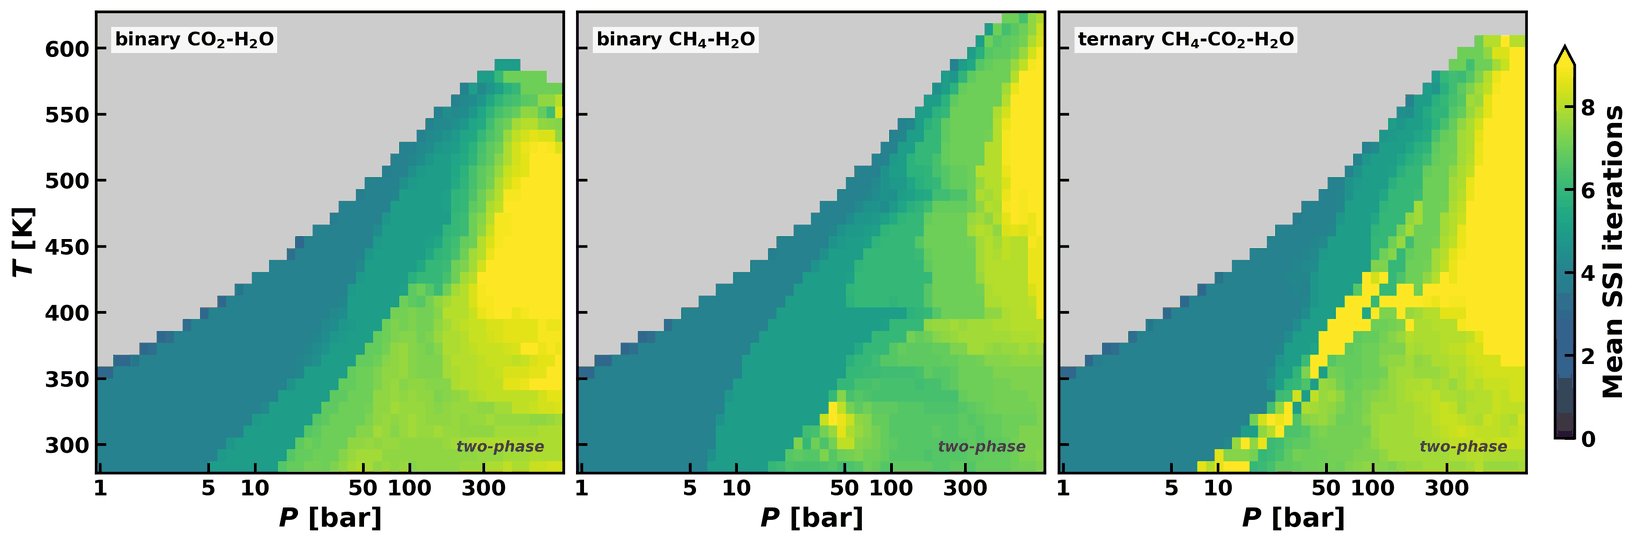

In [48]:
run("sweep.figures.make_sweep_figures", "--merged", "results_cache/sweep/merged.parquet",
    "--out-dir", "figures/sweep", module=True)   # plots the shipped flash-grid results
show('sweep/figures/n_iter_ssi_by_feed_family_heatmap.png')


<a id="sfigS27"></a>

**Figure S27.** Mean accelerated-$K$-value SSI iteration count for the two-phase states of each feed family, averaged over the eight salt configurations at every $(T, P)$ cell. Grey cells mark single-phase states (the flash is not executed there), so the interface between grey and colored regions also marks the phase boundary of each feed. Per-salt panels, wall-time counterparts, and the SSI-plus-Newton-polish vs. SSI-only comparison are given in Section S14.

The method requires the residual to be analytic in the perturbed unknown: absolute values, $\min$/$\max$ and branches taken on the value of an unknown break that silently. The inner residuals of Eq. (11) of the main text are closed-form expressions built from arithmetic, powers, $\exp$ and $\log$. The aqueous chain contains a single guard, protecting a division by the water self-association product; at the states computed that product exceeds its threshold by many orders of magnitude, so an imaginary perturbation of size $h$ cannot change which branch is taken. The solver’s own non-analytic operations act on the real-valued residual outside the differentiated code. Complex-step is used for the per-phase inner Jacobians only; the outer Newton polish on $\ln K_i$ uses a forward-difference Jacobian with a step of $10^{-5}$, which affects the convergence rate of that polish but not the equilibrium residual it is driven to.

Figure S27 shows the mean SSI iteration count across the two-phase region for each feed family, averaged over the eight salt configurations at every $(T, P)$ cell. The single-phase area of each panel is masked grey so the phase boundary is visible as the interface between grey and colored regions. Iteration counts cluster between $\approx$ 4 and 8 across almost the whole two-phase window; the upper tail concentrates in the high-$T$ / high-$P$ corner of the ternary feed, where the aqueous inner-Newton on $(Z^{aq}, \varepsilon_r, \chi_{\mathrm{H_{2}O}}^{aq})$ becomes most expensive because of the dense-fluid SRK contribution and the reduced hydrogen-bonding network. Per-salt breakdowns of the SSI count, wall time, and Newton-polish comparison are collected in Section S14.

\@ifundefined


<a id="srefs"></a>

## References (Supporting Information)

<a id="sref1"></a>1. Moortgat, J.; Coelho, F. M.; Firoozabadi, A. Phase Equilibria of $\mathrm{CO_{2}}$ and $\mathrm{CH_{4}}$ in Multisalt Brines: Parametrization and Validation of an Ion-Specific Electrolyte Cubic-Plus-Association Equation of State. *Energy Fuels* **2026**, *40*, 23472–23484. [DOI: 10.1021/acs.energyfuels.6c04568](https://pubs.acs.org/enfuem/article/40/42/23472/5449187/Phase-Equilibria-of-CO2-and-CH4-in-Multisalt)

<a id="sref2"></a>2. Jex, M.; Mikyška, J.; Firoozabadi, A. Fast and Robust Multiphase Equilibrium Calculation at High Pressures and Temperatures Using Accelerated Successive Substitution and New Multiple Initial Guesses for Stability Analysis. *SPE J.* **2024**, *29*, 3643–3658

<a id="sref3"></a>3. Moortgat, J.; Coelho, F. M.; Firoozabadi, A. Fast and Robust Phase Equilibrium Computations for $\mathrm{CO_{2}}$ + $\mathrm{H_{2}O}$ + $\mathrm{NaCl}$ Mixtures Using the Electrolyte Cubic-Plus-Association Equation of State. *Industrial & Engineering Chemistry Research* **2026**, *65*, 20081–20103

<a id="sref4"></a>4. Tong, D.; Trusler, J. P. M.; Vega-Maza, D. Solubility of CO2 in Aqueous Solutions of $\mathrm{CaCl_{2}}$ or $\mathrm{MgCl_{2}}$ and in a Synthetic Formation Brine at Temperatures up to 423 K and Pressures up to 40 MPa. *Journal of Chemical & Engineering Data* **2013**, *58*, 2116–2124

<a id="sref5"></a>5. Messabeb, H.; Contamine, F.; Cézac, P.; Serin, J. P.; Pouget, C.; Gaucher, E. C. Experimental Measurement of $\mathrm{CO_{2}}$ Solubility in Aqueous $\mathrm{CaCl_{2}}$ Solution at Temperature from 323.15 to 423.15 K and Pressure up to 20 MPa Using the Conductometric Titration. *Journal of Chemical & Engineering Data* **2017**, *62*, 4228–4234

<a id="sref6"></a>6. Hayduk, W., Ed. *Ethane*; IUPAC Solubility Data Series; Pergamon Press: Oxford, 1982; Vol. 9

<a id="sref7"></a>7. Morrison, T. J.; Billett, F. The Salting-out of Non-electrolytes. Part II. The Effect of Variation in Non-electrolyte. *J. Chem. Soc.* **1952**, 3819–3822

<a id="sref8"></a>8. Yano, T.; Suetaka, T.; Umehara, T.; Horiuchi, A. Salt Effects on the Solubility of Propane in Aqueous Electrolyte Solutions. *Kagaku Kogaku* **1974**, *38*, 320, Data as compiled and evaluated in the IUPAC Solubility Data Series, Vol. 24

<a id="sref9"></a>9. Liu, Y.; Hou, M.; Yang, G.; Han, B. Solubility of $\mathrm{CO_{2}}$ in aqueous solutions of NaCl, KCl, $\mathrm{CaCl_{2}}$ and their mixed salts at different temperatures and pressures. *J. Supercrit. Fluid.* **2011**, *56*, 125–129

<a id="sref10"></a>10. Wang, L.; Shen, Z.; Hu, L.; Yu, Q. Modeling and measurement of $\mathrm{CO_{2}}$ solubility in salty aqueous solutions and application in the Erdos Basin. *Fluid Phase Equilibria* **2014**, *377*, 45–55

<a id="sref11"></a>11. Spycher, N.; Pruess, K.; Ennis-King, J. CO2-H2O mixtures in the geological sequestration of CO2. I. Assessment and calculation of mutual solubilities from 12 to 100 degrees C and up to 600 bar. *Geochimica et Cosmochimica Acta* **2003**, *67*, 3015–3031

<a id="sref12"></a>12. Tsivintzelis, I.; Kontogeorgis, G. M.; Michelsen, M. L.; Stenby, E. H. Modeling phase equilibria for acid gas mixtures using the CPA equation of state. Part II: Binary mixtures with $\mathrm{CO_{2}}$. *Fluid Phase Equilibr.* **2011**, *306*, 38–56

<a id="sref13"></a>13. Schlaikjer, A.; Thomsen, K.; Kontogeorgis, G. M. eCPA: An ion-specific approach to parametrization. *Fluid Phase Equilibria* **2018**, *470*, 176–187

<a id="sref14"></a>14. Maribo-Mogensen, B.; Kontogeorgis, G. M.; Thomsen, K. Modeling of Dielectric Properties of Aqueous Salt Solutions with an Equation of State. *J. Phys. Chem. B* **2013**, *117*, 10523–10533

<a id="sref15"></a>15. Al Ghafri, S.; Maitland, G. C.; Trusler, J. P. M. Densities of Aqueous $\mathrm{MgCl_{2}}$(aq), $\mathrm{CaCl_{2}}$(aq), KI(aq), NaCl(aq), KCl(aq), $\mathrm{AlCl_{3}}$(aq), and (0.964 NaCl + 0.136 KCl)(aq) at Temperatures Between (283 and 472) K, Pressures up to 68.5 MPa, and Molalities up to 6 mol kg$^{-1}$. *J. Chem. Eng. Data* **2012**, *57*, 1288–1304

<a id="sref16"></a>16. Al Ghafri, S. Z.; Maitland, G. C.; Trusler, J. P. M. Densities of $\mathrm{SrCl_{2}}$(aq), $\mathrm{Na_{2}SO_{4}}$(aq), $\mathrm{NaHCO_{3}}$(aq), and Two Synthetic Reservoir Brines at Temperatures between (298 and 473) K, Pressures up to 68.5 MPa, and Molalities up to 3 mol·kg–1. *Journal of Chemical & Engineering Data* **2013**, *58*, 402–412

<a id="sref17"></a>17. Chapoy, A.; Mokraoui, S.; Valtz, A.; Richon, D.; Mohammadi, A. H.; Tohidi, B. Solubility Measurement and Modeling for the System Propane–Water from 277.62 to 368.16 K. *Fluid Phase Equilib.* **2004**, *226*, 213–220

<a id="sref18"></a>18. Culberson, O. L.; Horn, A. B.; McKetta, J. J. Phase Equilibria in Hydrocarbon-Water Systems: The Solubility of Ethane in Water at Pressures to 1200 Pounds per Square Inch. *Trans. AIME (J. Pet. Technol.)* **1950**, *189*, 1–6

<a id="sref19"></a>19. Culberson, O. L.; McKetta, J. J. Phase Equilibria in Hydrocarbon-Water Systems II: The Solubility of Ethane in Water at Pressures to 10,000 psi. *Trans. AIME (J. Pet. Technol.)* **1950**, *189*, 319–322

<a id="sref20"></a>20. Hayduk, W., Ed. *Propane, Butane and 2-Methylpropane*; IUPAC Solubility Data Series; Pergamon Press: Oxford, 1986; Vol. 24

<a id="sref21"></a>21. Kobayashi, R. Vapor-Liquid Equilibria in Binary Hydrocarbon-Water Systems. Ph.D. thesis, University of Michigan, 1951; Complete data tables behind \[Kobayashi and Katz, 1953\]

<a id="sref22"></a>22. Kobayashi, R.; Katz, D. L. Vapor-Liquid Equilibria for Binary Hydrocarbon-Water Systems. *Ind. Eng. Chem.* **1953**, *45*, 440–446

<a id="sref23"></a>23. Mao, S.; Zhang, Z.; Hu, J.; Sun, R.; Duan, Z. An Accurate Model for Calculating $\mathrm{C_{2}H_{6}}$ Solubility in Pure Water and Aqueous NaCl Solutions. *Fluid Phase Equilibria* **2005**, *238*, 77–86

<a id="sref24"></a>24. Mohammadi, A. H.; Chapoy, A.; Tohidi, B.; Richon, D. Measurements and Thermodynamic Modeling of Vapor-Liquid Equilibria in Ethane-Water Systems from 274.26 to 343.08 K. *Ind. Eng. Chem. Res.* **2004**, *43*, 5418–5424

<a id="sref25"></a>25. Ben-Naim, A.; Yaacobi, M. Effects of Solutes on the Strength of Hydrophobic Interaction and Its Temperature Dependence. *J. Phys. Chem.* **1974**, *78*, 170–175

<a id="sref26"></a>26. Coelho, F. M.; Mercier Franco, L. F.; Firoozabadi, A. Phase Equilibria of $\mathrm{CO_{2}}$–Water and $\mathrm{CO_{2}}$–Brine at High Temperatures: From Monte Carlo Simulations to the Equation of State. *Industrial & Engineering Chemistry Research* **2025**, *64*, 8492–8505

<a id="sref27"></a>27. Coelho, F. M. a.; Mercier Franco, L. F.; Firoozabadi, A. Modeling of phase equilibria of $\mathrm{H_{2}}$ and $\mathrm{H_{2}}$–$\mathrm{CO_{2}}$ in $\mathrm{NaCl}$ brine mixtures from e<span class="smallcaps">CPA</span> equation of state. *International Journal of Hydrogen Energy* **2025**, *178*, 151361

<a id="sref28"></a>28. O’Sullivan, T. D.; Smith, N. O. Solubility and partial molar volume of nitrogen and methane in water and in aqueous sodium chloride from 50 to 125 C and 100 to 600 atm. *The Journal of Physical Chemistry* **1970**, *74*, 1460–1466

<a id="sref29"></a>29. Wendland, M.; Hasse, H.; Maurer, G. Experimental Pressure–Temperature Data on Three- and Four-Phase Equilibria of Fluid, Hydrate, and Ice Phases in the System Carbon Dioxide–Water. *J. Chem. Eng. Data* **1999**, *44*, 901–906